<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/00_Cybersecurity_Dataset_Atlas/QML_Cybersecurity_Dataset_Atlas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QML x Cybersecurity Dataset Atlas

**What it is.** A teaching atlas of the datasets behind the *QML x Cybersecurity* reproduction repository
([owlmt/QML](https://github.com/owlmt/QML)): 327 papers on quantum machine learning for cybersecurity, one reproduced notebook per paper,
filed in 30 topic folders. This notebook is folder `00` of that repository. For every dataset that a reproduced notebook loads,
and for the standard cybersecurity collections of the original catalogue, it shows **what the data look like** (real observations
coloured by their ground-truth label), the **features**, the **use cases** (topic folders and reproduced papers that use it),
**where it comes from**, its **licence**, and whether it **can be downloaded automatically**.

**Made by** Madjid G. Tehrani, Edinburgh Napier University, 2026.

**How to run.** Open it in Google Colab (badge above), keep the free **CPU** runtime and choose **Runtime -> Run all**.
The first cell installs pinned libraries (Colab may ask for a session restart; run all again afterwards).
`FAST_MODE = True` (default) skips every download above 250 MB and takes about 30 to 60 minutes; `FAST_MODE = False`
(FULL mode) accepts files up to 3 GB and needs several hours and several GB of disk. All tunable constants are in the configuration cell.
Downloads go to `DATA_DIR`; large files are deleted after they have been read.

**What you get at the end.** One figure per dataset, a summary of the whole atlas (status charts, dataset x topic-folder matrix),
the list of what the reader has to provide for gated or very large datasets, and `atlas_inventory.csv`.

**Access status legend**

| Status | Meaning | Outcome in this notebook |
|---|---|---|
| `public` | a direct download works without an account | loaded and plotted (`LOADED`) |
| `large` | public, but the file is larger than the FAST-mode limit | `SKIPPED_LARGE_FAST` with the exact size; loaded in FULL mode |
| `gated` | registration, API key or login is required | `NEEDS_USER_FILE`: put the file in `atlas_user_files/<dataset>/` |
| `page_only` | an official page exists but no stable direct link | `NEEDS_USER_FILE` as above |
| `simulated` | the papers generate their own data | `NOT_APPLICABLE` |

Other per-dataset outcomes: `LOAD_FAILED` (the real error text is shown), `NO_LABEL` (no label column could be identified, so nothing is plotted).

**How to cite.** Plain text: Madjid G. Tehrani (2026). *QML x Cybersecurity: reproducible notebooks of quantum machine learning papers and a cybersecurity dataset atlas.* Edinburgh Napier University. https://github.com/owlmt/QML

```bibtex
@misc{tehrani2026qmlcyber,
  author       = {Tehrani, Madjid G.},
  title        = {QML x Cybersecurity: reproducible notebooks of quantum machine learning papers and a cybersecurity dataset atlas},
  year         = {2026},
  publisher    = {GitHub},
  howpublished = {\url{https://github.com/owlmt/QML}},
  note         = {Edinburgh Napier University. Cite the dataset atlas as folder 00\_Cybersecurity\_Dataset\_Atlas and an implemented paper as its notebook path.}
}
```

When you use a dataset shown here, cite the dataset's own reference as well (given on its card).

## The atlas in one page

**Selection.** The registry has 102 entries: every dataset loaded by at least one reproduced notebook of the corpus (read from
`atlas_usage.csv`, generated by `tools/atlas_usage.py`), plus the standard cybersecurity collections of the original catalogue
(for example the CIC page-only releases, SWaT, WADI, Drebin) so that the atlas is useful beyond the papers reproduced so far.

**Every dataset card** shows: name, domain, task and use cases, original reference, licence, access status, official source, the
topic folders in which it is used, and the reproduced papers that load it (`QC-ID: notebook link`). Below the card, one figure
(2 x 2 panels): (a) class distribution of the real labels before sampling, (b) feature table with mean and standard deviation
after scaling (pixel grid for images, top TF-IDF terms for text), (c) raw PCA scatter of real observations coloured by
ground-truth label, (d) the same coordinates scaled to [0, pi], the angles a quantum feature map would encode.

**What is never done.** No data are fabricated, no labels are invented, and no unrelated dataset is ever substituted for one that
cannot be loaded. A dataset that cannot be downloaded is reported with its status and with what you have to supply.
The PCA plots are classical projections; they are not quantum computations and make no claim of quantum advantage.

| Item | Catalogue v3 | This atlas |
|---|---|---|
| Datasets in the registry | 54 (20 loaded) | 102: all datasets used by the corpus notebooks plus the standard collections |
| Mirrors | generic Hugging Face mirrors | mirrors replaced by the ones the corpus notebooks use (for example the GitHub copy of NSL-KDD, the c01dsnap copy of CIC-IDS-2017) |
| Use cases | not recorded | per card: topic folders and the reproduced papers (QC-ID and notebook link) that load the dataset |
| Access status | read from the dataset pages | verified by an actual download attempt; the status of every dataset is shown after the run |
| Figures | five plot types per dataset | one 2 x 2 figure per dataset: classes, features, raw PCA, angles for qubit encoding |
| Labels | guessed by heuristics | taken from the registry's label hints; `NO_LABEL` when none matches |
| Inventory | `dataset_inventory_v3.csv` | `atlas_inventory.csv`, written by the notebook, plus the list of what to provide |

In [1]:

# Pinned for Colab (it already ships numpy, pandas, scikit-learn, matplotlib and requests). A session restart may be required.
%pip -q install "huggingface_hub==2.2.0" "pyarrow==26.0.0" "py7zr==1.1.4" "openpyxl==3.1.5" "pennylane==0.45.1" "scipy==1.18.1" "pillow"

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ---- Configuration: every tunable constant of the atlas lives in this cell ----
import os, sys, random
from pathlib import Path

SEED = 42                      # fixes sampling, PCA and every random choice
FAST_MODE = True               # True: about 30-60 min, files above MAX_MB_FAST are skipped
                               # False: FULL mode, files up to MAX_MB_FULL (several GB, hours)
SAMPLE_ROWS = 2000             # rows kept per dataset after class-balanced sampling
STREAM_ROWS = 200_000          # chunk size for CSV scans and row cap for streamed sources
MAX_FEATURES_TABLE = 12        # features drawn in panel (b)
MAX_CLASSES = 15               # classes drawn; the rest are merged into "other"
MAX_MB_FAST = 250              # largest download accepted in FAST mode (MB)
MAX_MB_FULL = 3000             # largest download accepted in FULL mode (MB)
FIG_DPI = 80                   # one PNG per dataset at this resolution
DATASETS_WHITELIST = None      # e.g. ["NSL-KDD", "MNIST"] to run only some datasets
DELETE_BIG_DOWNLOADS = True    # delete downloaded files above BIG_FILE_MB after reading (saves disk)
BIG_FILE_MB = 50
PER_CLASS_IMAGES = 40          # Malimg: images downloaded per family
PNG_COLORS = 64                # palette size of each saved PNG (keeps the notebook small); 0 = full colour

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # no download progress widgets in the saved notebook
IN_COLAB = "google.colab" in sys.modules or Path("/content").is_dir()
_BASE = Path("/content") if IN_COLAB else Path(".")
DATA_DIR = _BASE / "atlas_data"                 # downloads (cache)
OUTPUT_DIR = _BASE / "atlas_outputs"            # one PNG per dataset + inventory CSV
USER_FILES_DIR = _BASE / "atlas_user_files"     # drop files for gated / page_only datasets in <slug>/
for _d in (DATA_DIR, OUTPUT_DIR, USER_FILES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Folder of the repository that holds this notebook (used to read atlas_usage.csv and to write
# atlas_inventory.csv when the notebook runs from a clone of the repository).
REPO_FOLDER = Path(os.environ.get("ATLAS_REPO_FOLDER", "00_Cybersecurity_Dataset_Atlas"))
USAGE_URL = "https://raw.githubusercontent.com/owlmt/QML/main/00_Cybersecurity_Dataset_Atlas/atlas_usage.csv"
NOTEBOOK_URL_BASE = "https://github.com/owlmt/QML/blob/main/"

MAX_MB = MAX_MB_FAST if FAST_MODE else MAX_MB_FULL


def _resolve_hf_token():
    """Token only from the environment or Colab Secrets. Never printed, never written."""
    tok = os.environ.get("HF_TOKEN")
    if tok:
        return tok
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception:
        return None


HF_TOKEN = _resolve_hf_token()   # none of the public mirrors below needs it; the hook is for gated repos
print(f"FAST_MODE={FAST_MODE}  SAMPLE_ROWS={SAMPLE_ROWS}  MAX_MB={MAX_MB}  HF token available: {HF_TOKEN is not None}")
print("DATA_DIR =", DATA_DIR.resolve(), "| OUTPUT_DIR =", OUTPUT_DIR.resolve())

FAST_MODE=True  SAMPLE_ROWS=2000  MAX_MB=250  HF token available: True
DATA_DIR = C:\Users\madji\AppData\Local\Temp\claude\C--Users-madji-Desktop-QML\45437630-f2c2-4728-9da2-ce4bbdd7c4ba\scratchpad\atlas\run_atlas\final3\atlas_data | OUTPUT_DIR = C:\Users\madji\AppData\Local\Temp\claude\C--Users-madji-Desktop-QML\45437630-f2c2-4728-9da2-ce4bbdd7c4ba\scratchpad\atlas\run_atlas\final3\atlas_outputs


In [3]:
# ---- Imports, seeds, versions ----
import io, re, gzip, json, time, math, shutil, zipfile, tarfile, tempfile, warnings, traceback, dataclasses
from dataclasses import dataclass, field
from typing import Any, Dict, List, Optional
from fnmatch import fnmatch

import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from IPython.display import Image as IPImage, display, Markdown

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": FIG_DPI, "savefig.dpi": FIG_DPI, "axes.unicode_minus": False, "font.size": 8})

import huggingface_hub, pyarrow, pyarrow.parquet as pq
from huggingface_hub import HfApi, HfFileSystem, hf_hub_download

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| pyarrow", pyarrow.__version__, "| huggingface_hub", huggingface_hub.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pyarrow 26.0.0 | huggingface_hub 2.2.0


### The registry and the corpus usage table

The next cell holds the registry: one entry per dataset with its source, files, format, label hints, licence, access status and notes
(field documentation at the top of the cell). The cell after it reads `atlas_usage.csv` (local copy if present, otherwise the file on GitHub)
and fills each entry's `used_by` list with the reproduced papers that load the dataset.

In [4]:
# -----------------------------------------------------------------------------
# QML x Cybersecurity Dataset Atlas -- registry v4 (2026-10-21)
# -----------------------------------------------------------------------------
# One entry per dataset. Fields:
#   name          canonical name
#   domain        cybersecurity sub-domain (short)
#   topics        repository topic folders where this dataset is used or belongs
#   task          what the dataset is used for (use cases, plain words)
#   reference     original dataset paper / page (for citation inside the atlas)
#   source        "hf" | "url" | "sklearn" | "pennylane" | "gated" | "page_only" | "simulated"
#   repo_id       Hugging Face dataset repo (source == "hf")
#   files         files to fetch inside the repo (list) or direct URLs (source == "url")
#   format        "csv" | "csv.gz" | "parquet" | "parquet-images" | "zip" | "7z" | "tar.gz" |
#                 "jsonl" | "npz" | "idx-gz" | "xlsx" | "text-dir" | "binetflow" | "png-dir" | "sklearn"
#   members       (zip/7z/tar) member name patterns to read (list of glob-like substrings)
#   read_kwargs   pandas read kwargs (header=None, sep, names, ...)
#   label_hints   candidate label columns, in priority order
#   benign_value  value(s) in the label column meaning benign / normal (None if no benign class)
#   drop_label_values  label values to discard (e.g. unlabeled -1)
#   label_from    "subdir" | "member" | "column" (default column)
#   max_mb_fast   files larger than this are only loaded in FULL mode (default 250)
#   license       short licence / terms tag
#   access        "public" (auto-download works) | "large" (public, FULL mode only) |
#                 "gated" (registration/API key: user must supply) | "page_only" (official page,
#                 no programmatic download found: user must supply) | "simulated" (no data file)
#   notes         provenance, quirks, what to tell the reader
#   used_by       QC-IDs of corpus notebooks that load this dataset (from tools/atlas_usage.py);
#                 filled automatically by the notebook from atlas_usage.csv, do not edit by hand
# -----------------------------------------------------------------------------
from typing import Any, Dict, List

REGISTRY: List[Dict[str, Any]] = [
    # ============================================================ 01 network intrusion
    {"name": "NSL-KDD", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "10_Spam_Detection", "19_Cybersecurity_Anomaly_Detection", "29_Adversarial_Robustness_Defences_for_QML"],
     "task": "Binary and 5-class (normal / DoS / Probe / R2L / U2R) intrusion detection on 41 connection features; the most used benchmark of the corpus",
     "reference": "Tavallaee, Bagheri, Lu, Ghorbani, 'A detailed analysis of the KDD CUP 99 data set', CISDA 2009",
     "source": "url", "files": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"], "format": "csv",
     "read_kwargs": {"header": None}, "columns_note": "43 unnamed columns: 41 features, label (column 41), difficulty (column 42)",
     "label_hints": [41], "benign_value": "normal", "license": "UNB CIC, research use", "access": "public",
     "notes": "KDDTrain+ from the defcom17 GitHub mirror used by 14 notebooks; Mireu-Lab/NSL-KDD on Hugging Face is the fallback."},
    {"name": "KDD Cup 1999 (10%)", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "14_IoT_IIoT_Attack_Detection"],
     "task": "Historic 1999 DARPA-derived intrusion benchmark (23 attack types); used for anomaly detection and as a sanity benchmark",
     "reference": "Stolfo et al., KDD Cup 1999; UCI KDD Archive", "source": "hf", "repo_id": "akahana/kdd-cup-1999",
     "files": ["data/test-00000-of-00002.parquet"], "format": "parquet", "label_hints": ["result", "label", "class"], "benign_value": "normal.",
     "license": "UCI, research use", "access": "public",
     "notes": "Parquet mirror (3 MB shard). The corpus notebooks also use scikit-learn fetch_kddcup99 and the figshare 10% gzip."},
    {"name": "CIC-IDS2017", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "02_Zero_Day_Attack_Detection", "03_DDoS_DoS_Detection", "13_Encrypted_Malicious_Traffic_Detection"],
     "task": "Flow-level detection of DDoS, PortScan, brute force, web attacks and infiltration on 78 CICFlowMeter features",
     "reference": "Sharafaldin, Habibi Lashkari, Ghorbani, 'Toward generating a new intrusion detection dataset and intrusion traffic characterization', ICISSP 2018",
     "source": "hf", "repo_id": "c01dsnap/CIC-IDS2017", "files": ["Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"], "format": "csv",
     "label_hints": ["Label", " Label"], "benign_value": "BENIGN", "license": "UNB CIC, research use", "access": "public",
     "notes": "Friday DDoS day (77 MB) from the mirror used by the corpus; StarterArcher/CICIDS2017 on GitHub is the fallback."},
    {"name": "CSE-CIC-IDS2018", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "12_Cryptojacking_Detection"],
     "task": "Large AWS-testbed successor of CIC-IDS2017: brute force, DoS, DDoS, botnet, infiltration, web attacks",
     "reference": "Sharafaldin et al. 2018 (CSE-CIC-IDS2018 on AWS)", "source": "hf", "repo_id": "pcy12345BSU/CSE-CIC-IDS-2018",
     "files": ["data/Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv"], "format": "csv", "label_hints": ["Label"], "benign_value": "Benign",
     "license": "UNB CIC, research use", "access": "public", "notes": "Thursday 01-03-2018 day (108 MB, infiltration)."},
    {"name": "UNSW-NB15", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "21_QKD_Attack_Detection"],
     "task": "Binary and 10-class attack-category detection on 49 flow features (Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms)",
     "reference": "Moustafa, Slay, 'UNSW-NB15: a comprehensive data set for network intrusion detection systems', MilCIS 2015",
     "source": "hf", "repo_id": "Mireu-Lab/UNSW-NB15", "files": ["train.csv"], "format": "csv", "label_hints": ["attack_cat", "label"], "benign_value": "Normal",
     "license": "UNSW Canberra, research use", "access": "public", "notes": "Official training-set split (15 MB) from the mirror used by the corpus."},
    {"name": "CIC-UNSW-NB15", "domain": "Network intrusion / evasion", "topics": ["01_Network_Intrusion_Detection"],
     "task": "UNSW-NB15 traffic re-extracted with CICFlowMeter (feature-set comparison, evasion studies)",
     "reference": "UNB CIC, CIC-UNSW-NB15 (2024)", "source": "hf", "repo_id": "bencorn/CIC-UNSW-NB15", "files": ["Data.csv", "Lable.csv"], "format": "csv",
     "join": "horizontal", "label_hints": ["Label", "label"], "benign_value": 0, "license": "UNB CIC, research use", "access": "public",
     "notes": "Features (196 MB) and labels (0.9 MB) are separate files joined by row position."},
    {"name": "ISCX-IDS-2012", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "13_Encrypted_Malicious_Traffic_Detection"],
     "task": "Seven days of labelled flows (HTTP DoS, DDoS, brute force SSH, infiltration)",
     "reference": "Shiravi, Shiravi, Tavallaee, Ghorbani, 'Toward developing a systematic approach to generate benchmark datasets for intrusion detection', Computers & Security 2012",
     "source": "hf", "repo_id": "bencorn/ISCX-IDS-2012", "files": ["iscxids2012-master.tar.gz"], "format": "tar.gz", "members": [".csv"], "max_mb_fast": 0,
     "label_hints": ["Tag", "label"], "benign_value": "Normal", "license": "UNB CIC, research use", "access": "large",
     "notes": "The only mirror is a 1 GB tarball; loaded in FULL mode only."},
    {"name": "CIDDS-001", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "18_Cloud_Virtual_Environment_Threats"],
     "task": "NetFlow records from an emulated small business and an OpenStack cloud; attacker / victim / normal flows",
     "reference": "Ring, Wunderlich, Grudl, Landes, Hotho, 'Flow-based benchmark data sets for intrusion detection', ECCWS 2017",
     "source": "hf", "repo_id": "daveydhruti/cidds-aggregated", "files": ["internal-output.csv"], "format": "csv",
     "label_hints": ["class", "attackType", "label"], "benign_value": "normal", "license": "HS Coburg, research use", "access": "public",
     "notes": "Aggregated internal-server CSV (8.7 MB). The official WISENT-CIDDS-001.zip at hs-coburg.de timed out from this machine; it is listed as the primary source for FULL mode."},
    {"name": "Kyoto 2006+", "domain": "Network intrusion", "topics": ["01_Network_Intrusion_Detection", "28_QML_Hardware_Side_Channel_Crosstalk_Attacks"],
     "task": "Honeypot traffic (24 features) labelled normal / known attack / unknown attack",
     "reference": "Song, Takakura, Okabe, Eto, Inoue, Nakao, 'Statistical analysis of honeypot data and building of Kyoto 2006+ dataset', BADGERS 2011",
     "source": "page_only", "files": ["https://www.takakura.com/Kyoto_data/"], "format": "csv", "label_hints": [17], "benign_value": 1,
     "license": "Kyoto University, research use", "access": "page_only",
     "notes": "Daily text files on takakura.com; the 2015 file probed from this machine returned 404. Three corpus notebooks load it with their own URL; the atlas needs a working file from the user."},
    {"name": "O-RAN intrusion dataset (reduced)", "domain": "Network intrusion / 5G", "topics": ["01_Network_Intrusion_Detection"],
     "task": "Open-RAN telemetry flows for QKSVM intrusion detection (Abreu et al. 2026)", "reference": "de Abreu et al., qml_ids_wqusec_extended GitHub repository",
     "source": "url", "files": ["https://raw.githubusercontent.com/DiegoAbreuSWB/qml_ids_wqusec_extended/main/oran_dataset_reduced.csv"], "format": "csv",
     "label_hints": ["label", "Label", "class"], "benign_value": None, "license": "authors' repository (see its licence)", "access": "public",
     "notes": "2.5 MB CSV published with the authors' code."},
    # ============================================================ 03 DDoS
    {"name": "CIC-DDoS2019", "domain": "DDoS", "topics": ["03_DDoS_DoS_Detection"],
     "task": "Reflection and exploitation DDoS families (DNS, LDAP, MSSQL, NetBIOS, NTP, SNMP, SSDP, UDP, SYN, TFTP, Portmap) on CICFlowMeter features",
     "reference": "Sharafaldin, Habibi Lashkari, Hakak, Ghorbani, 'Developing realistic distributed denial of service (DDoS) attack dataset and taxonomy', ICCST 2019",
     "source": "hf", "repo_id": "RonaldoMPF/CIC-DDoS2019-15C", "files": ["test.csv"], "format": "csv", "label_hints": ["Label", " Label", "label"], "benign_value": "BENIGN",
     "license": "UNB CIC, research use", "access": "public", "notes": "15-class subset (9 MB). The full per-attack CSVs (baalajimaestro/CICDDoS2019, up to 9 GB each) are used by the corpus notebooks with chunked reads."},
    # ============================================================ 04 botnet / DGA
    {"name": "Botnet DGA Dataset", "domain": "Botnet / DGA", "topics": ["04_Botnet_DGA_Detection"],
     "task": "Domain names from 50+ DGA families vs legitimate domains; classification from string features",
     "reference": "Zago, Gil Perez, Martinez Perez, 'UMUDGA: a dataset for profiling DGA-based botnet', Computers & Security 2020 (IEEE DataPort 'Botnet DGA Dataset')",
     "source": "url", "files": ["https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv"], "format": "csv",
     "label_hints": ["isDGA", "label", "class", "family"], "benign_value": "legit", "license": "IEEE DataPort open access", "access": "public",
     "notes": "5000-row feature CSV published by Sultanow et al. with the quantum-botnet-detection code (Azure blob), used by two corpus notebooks."},
    {"name": "DGA detection (argencon)", "domain": "Botnet / DGA", "topics": ["04_Botnet_DGA_Detection"],
     "task": "Raw domain strings labelled DGA / normal (character-level models)", "reference": "Catania, Garcia, Torres, 'Deep convolutional neural networks for DGA detection', Argencon 2018",
     "source": "hf", "repo_id": "harpomaxx/dga-detection", "files": ["argencon.csv.gz"], "format": "csv.gz", "label_hints": ["label", "class"], "benign_value": "normal",
     "license": "see repository", "access": "public", "notes": "34 MB gzip CSV of domain strings; features are derived from the string in the atlas (length, entropy, digit ratio, n-gram counts)."},
    {"name": "CTU-13 (scenario 42)", "domain": "Botnet", "topics": ["04_Botnet_DGA_Detection", "13_Encrypted_Malicious_Traffic_Detection"],
     "task": "Bidirectional NetFlows of 13 botnet captures (Neris, Rbot, Virut, Menti, Sogou, Murlo, NSIS.ay) labelled background / normal / botnet",
     "reference": "Garcia, Grill, Stiborek, Zunino, 'An empirical comparison of botnet detection methods', Computers & Security 2014",
     "source": "url", "files": ["https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/detailed-bidirectional-flow-labels/capture20110810.binetflow"], "format": "binetflow",
     "stream_rows": 300000, "label_hints": ["Label"], "benign_value": "Normal", "license": "Stratosphere Lab, CC BY", "access": "public",
     "notes": "386 MB flow file streamed: only the first 300k lines are read, then class-balanced. The full 2 GB tarball is FULL-mode only."},
    # ============================================================ 14 IoT / IIoT
    {"name": "TON_IoT (network)", "domain": "IoT / IIoT", "topics": ["14_IoT_IIoT_Attack_Detection", "01_Network_Intrusion_Detection", "15_Smart_Grid_Power_System_Attacks"],
     "task": "Network flows from an IoT/IIoT testbed labelled normal and 9 attack types (backdoor, DDoS, DoS, injection, MITM, password, ransomware, scanning, XSS)",
     "reference": "Moustafa, 'A new distributed architecture for evaluating AI-based security systems at the edge: network TON_IoT datasets', Sustainable Cities and Society 2021",
     "source": "hf", "repo_id": "codymlewis/TON_IoT_network", "files": ["train_test_network.csv"], "format": "csv", "label_hints": ["type", "label"], "benign_value": "normal",
     "license": "UNSW Canberra, research use", "access": "public", "notes": "Train_Test_Network split (30 MB) used by five corpus notebooks."},
    {"name": "TON_IoT (IoT telemetry)", "domain": "IoT / IIoT", "topics": ["14_IoT_IIoT_Attack_Detection"],
     "task": "Sensor telemetry (fridge, GPS, garage door, Modbus, motion/light, thermostat, weather) with per-reading attack labels",
     "reference": "Moustafa 2021 (TON_IoT telemetry subsets)", "source": "hf", "repo_id": "SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets",
     "files": ["Train_Test_IoT_Modbus.csv"], "format": "csv", "label_hints": ["type", "label"], "benign_value": "normal", "license": "UNSW Canberra, research use", "access": "public",
     "notes": "Modbus subset (1.7 MB), the closest to ICS use cases."},
    {"name": "NF-ToN-IoT-v2", "domain": "IoT / IIoT", "topics": ["14_IoT_IIoT_Attack_Detection", "01_Network_Intrusion_Detection"],
     "task": "NetFlow v2 (43 features) version of TON_IoT for cross-dataset generalisation studies",
     "reference": "Sarhan, Layeghy, Portmann, 'Towards a standard feature set for network intrusion detection system datasets', Mobile Networks and Applications 2022",
     "source": "hf", "repo_id": "Nora9029/NF-ToN-IoT-v2", "files": ["NF-ToN-IoT-v2-test.csv"], "format": "csv", "max_mb_fast": 0, "label_hints": ["Attack", "Label"], "benign_value": "Benign",
     "license": "UQ, research use", "access": "large", "notes": "Test split is 532 MB: FULL mode only (streamed first rows in FAST mode if the loader supports range reads)."},
    {"name": "IoT-23", "domain": "IoT botnet", "topics": ["14_IoT_IIoT_Attack_Detection", "04_Botnet_DGA_Detection"],
     "task": "Zeek conn.log records of 20 malware captures (Mirai, Torii, Okiru, Hajime...) and 3 benign captures",
     "reference": "Garcia, Parmisano, Erquiaga, 'IoT-23: a labeled dataset with malicious and benign IoT network traffic', Stratosphere Lab 2020",
     "source": "hf", "repo_id": "Lystea/IOT23-PARQUET", "files": ["CTU-IoT-Malware-Capture-34-1.parquet", "CTU-IoT-Malware-Capture-1-1.parquet"], "format": "parquet",
     "label_hints": ["detailed-label", "label"], "benign_value": "Benign", "license": "Stratosphere Lab, CC BY", "access": "public",
     "notes": "Two small scenarios (0.7 MB and 34 MB). The original conn.log.labeled files on mcfp.felk.cvut.cz also download directly."},
    {"name": "BoT-IoT", "domain": "IoT botnet", "topics": ["14_IoT_IIoT_Attack_Detection", "01_Network_Intrusion_Detection"],
     "task": "Botnet traffic from a realistic IoT testbed: DDoS, DoS, reconnaissance, information theft",
     "reference": "Koroniotis, Moustafa, Sitnikova, Turnbull, 'Towards the development of realistic botnet dataset in the IoT for network forensic analytics: Bot-IoT dataset', FGCS 2019",
     "source": "hf", "repo_id": "masoltani/bot-iot", "files": ["balanced_dataset.parquet"], "format": "parquet", "row_groups": 1, "label_hints": ["category", "subcategory", "attack", "label"], "benign_value": "Normal",
     "license": "UNSW Canberra, research use", "access": "public", "notes": "730 MB parquet: the atlas reads only the first row group through HfFileSystem (range request), so no full download is needed."},
    {"name": "CIC-IoT-2023", "domain": "IoT", "topics": ["14_IoT_IIoT_Attack_Detection", "01_Network_Intrusion_Detection", "03_DDoS_DoS_Detection"],
     "task": "33 attacks (DDoS, DoS, recon, web, brute force, spoofing, Mirai) against 105 IoT devices; 46 flow features",
     "reference": "Neto et al., 'CICIoT2023: a real-time dataset and benchmark for large-scale attacks in IoT environment', Sensors 2023",
     "source": "hf", "repo_id": "lacg030175/CIC-IoT-2023", "files": ["random/test-00000-of-00001.parquet"], "format": "parquet", "label_hints": ["label", "Label"], "benign_value": "BenignTraffic",
     "license": "UNB CIC, research use", "access": "public", "notes": "13 MB random test split used by the corpus."},
    {"name": "Edge-IIoTset", "domain": "IIoT", "topics": ["14_IoT_IIoT_Attack_Detection", "16_ICS_SCADA_Cyber_Physical_Attacks"],
     "task": "14 attacks on an IoT/IIoT testbed (DDoS, injection, MITM, malware, scanning); ML-ready CSV with 61 features",
     "reference": "Ferrag, Friha, Hamouda, Maglaras, Janicke, 'Edge-IIoTset: a new comprehensive realistic cyber security dataset of IoT and IIoT applications', IEEE Access 2022",
     "source": "hf", "repo_id": "Sunayanajagadesh/ML_EdgeIIoT_dataset", "files": ["ML-EdgeIIoT-dataset.csv"], "format": "csv", "label_hints": ["Attack_type", "Attack_label"], "benign_value": "Normal",
     "license": "CC BY 4.0 (Kaggle original)", "access": "public", "notes": "82 MB Hugging Face mirror of the Kaggle ML-EdgeIIoT file; no Kaggle key needed."},
    {"name": "N-BaIoT", "domain": "IoT botnet", "topics": ["14_IoT_IIoT_Attack_Detection", "30_QML_Defences_Against_ML_Attacks"],
     "task": "115 traffic statistics per packet from 9 commercial IoT devices infected with Mirai and BASHLITE (gafgyt)",
     "reference": "Meidan et al., 'N-BaIoT: network-based detection of IoT botnet attacks using deep autoencoders', IEEE Pervasive Computing 2018",
     "source": "url", "files": ["https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip"], "format": "zip",
     "members": ["Danmini_Doorbell/benign_traffic.csv", "Danmini_Doorbell/mirai/scan.csv", "Danmini_Doorbell/gafgyt/junk.csv", "Danmini_Doorbell/mirai/udp.csv"], "label_from": "member",
     "label_hints": ["label"], "benign_value": "benign_traffic", "license": "UCI, CC BY 4.0", "access": "public",
     "notes": "UCI static zip (nested per-device archives); labels come from the member file name."},
    {"name": "IoTID20", "domain": "IoT", "topics": ["14_IoT_IIoT_Attack_Detection"],
     "task": "Smart-home IoT flows (Mirai, DoS, MITM, scan) with binary, category and sub-category labels",
     "reference": "Ullah, Mahmoud, 'A scheme for generating a dataset for anomalous activity detection in IoT networks', Canadian AI 2020",
     "source": "hf", "repo_id": "KathiS/IoTID20_Preprocessed_File", "files": ["Preprocessed_file.csv"], "format": "csv", "label_hints": ["Cat", "Sub_Cat", "Label"], "benign_value": "Normal",
     "license": "research use", "access": "public", "notes": "106 MB preprocessed single file."},
    {"name": "MQTTset", "domain": "IoT (MQTT)", "topics": ["14_IoT_IIoT_Attack_Detection"],
     "task": "MQTT broker traffic with flooding, malformed, slow DoS, brute force and legitimate classes",
     "reference": "Vaccari, Chiola, Aiello, Mongelli, Cambiaso, 'MQTTset, a new dataset for machine learning techniques on MQTT', Sensors 2020",
     "source": "url", "files": ["https://www.kaggle.com/api/v1/datasets/download/cnrieiit/mqttset"], "format": "zip", "members": ["train70_reduced.csv", "train70.csv"], "max_mb_fast": 0,
     "label_hints": ["target", "label"], "benign_value": "legitimate", "license": "Kaggle (CC BY 4.0)", "access": "large",
     "notes": "922 MB Kaggle archive (public, no key needed for this endpoint); FULL mode only."},
    {"name": "Farm-Flow", "domain": "Agricultural IoT", "topics": ["14_IoT_IIoT_Attack_Detection"],
     "task": "Network flows from a smart-farming testbed with and without attacks", "reference": "Zenodo record 10964648 (Farm-Flow, 2024)",
     "source": "url", "files": ["https://zenodo.org/api/records/10964648/files/farm-flow.zip/content"], "format": "zip", "members": [".csv"], "max_mb_fast": 0,
     "label_hints": ["label", "Label", "class"], "benign_value": None, "license": "Zenodo, CC BY 4.0", "access": "large", "notes": "500 MB zip; FULL mode only."},
    {"name": "WUSTL-EHMS-2020", "domain": "Medical IoT", "topics": ["14_IoT_IIoT_Attack_Detection"],
     "task": "Enhanced healthcare monitoring system: network flow + patient biometrics, spoofing and data-injection attacks",
     "reference": "Hady, Ghubaish, Salman, Unal, Jain, 'Intrusion detection system for healthcare systems using medical and network data: a comparison study', IEEE Access 2020",
     "source": "url", "files": ["https://www.cse.wustl.edu/~jain/ehms/ftp/wustl-ehms-2020_with_attacks_categories.csv"], "format": "csv", "verify_tls": False,
     "label_hints": ["Attack Category", "Label"], "benign_value": "normal", "license": "WUSTL, research use", "access": "public",
     "notes": "3.9 MB CSV; the WUSTL server's TLS chain fails verification from this machine, so the loader passes verify=False for this host only."},
    {"name": "CICIoMT2024", "domain": "Medical IoT", "topics": ["14_IoT_IIoT_Attack_Detection"],
     "task": "Attacks on 40 IoMT devices (DDoS, DoS, recon, MQTT, spoofing)", "reference": "Dadkhah et al., 'CICIoMT2024: attack vectors in healthcare devices', UNB CIC 2024",
     "source": "hf", "repo_id": "somnath0100/CICIoMT2024Small", "files": ["CSVS/ARP_Spoofing_train.pcap_Flow.csv", "CSVS/Benign_train.pcap_Flow.csv"], "format": "csv", "label_from": "member",
     "label_hints": ["Label"], "benign_value": "Benign", "license": "UNB CIC, research use", "access": "public", "notes": "Two small flow CSVs; label from the file name when the CSV carries none."},
    {"name": "X-IIoTID", "domain": "IIoT", "topics": ["14_IoT_IIoT_Attack_Detection", "16_ICS_SCADA_Cyber_Physical_Attacks"],
     "task": "Connectivity- and device-agnostic IIoT intrusion dataset (multi-protocol, 18 attack types)",
     "reference": "Al-Hawawreh, Sitnikova, Aboutorab, 'X-IIoTID: a connectivity-agnostic and device-agnostic intrusion data set for industrial Internet of Things', IEEE IoT Journal 2022",
     "source": "gated", "files": ["https://ieee-dataport.org/documents/x-iiotid-connectivity-and-device-agnostic-intrusion-dataset-industrial-internet-things"], "format": "csv",
     "label_hints": ["class1", "class2", "class3"], "benign_value": "Normal", "license": "IEEE DataPort (login)", "access": "gated", "notes": "IEEE DataPort login required; user must supply the CSV."},
    {"name": "WUSTL-IIoT-2021", "domain": "IIoT", "topics": ["14_IoT_IIoT_Attack_Detection", "16_ICS_SCADA_Cyber_Physical_Attacks"],
     "task": "SCADA/IIoT testbed flows with reconnaissance, command injection, DoS and backdoor attacks",
     "reference": "Zolanvari, Teixeira, Gupta, Khan, Jain, 'Machine learning-based network vulnerability analysis of industrial Internet of Things', IEEE IoT Journal 2019",
     "source": "page_only", "files": ["https://www.cse.wustl.edu/~jain/iiot/index.html"], "format": "csv", "label_hints": ["Target", "Traffic"], "benign_value": 0,
     "license": "WUSTL, research use", "access": "page_only", "notes": "The CSV links on the page returned 404 from this machine; user must supply the file."},
    {"name": "CICAPT-IIoT", "domain": "APT / IIoT", "topics": ["14_IoT_IIoT_Attack_Detection"], "task": "Provenance-based APT detection in IIoT", "reference": "UNB CIC, CICAPT-IIoT 2024",
     "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None, "license": "UNB CIC, research use", "access": "page_only",
     "notes": "UNB CIC download requires the request form; user must supply."},
    {"name": "DataSense IIoT", "domain": "IIoT", "topics": ["14_IoT_IIoT_Attack_Detection"], "task": "IIoT sensor/network attack dataset", "reference": "UNB CIC, DataSense 2025",
     "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None, "license": "UNB CIC, research use", "access": "page_only",
     "notes": "No mirror found (the Hugging Face 'datasense' repos are unrelated); user must supply."},
    {"name": "CIC-BCCC-NRC Tabular IoT Attack", "domain": "IoT", "topics": ["14_IoT_IIoT_Attack_Detection"], "task": "Unified tabular IoT attack dataset merging several CIC/BCCC collections",
     "reference": "UNB CIC / BCCC, 2024", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None,
     "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CIC IoT-DIAD 2024", "domain": "IoT anomaly", "topics": ["14_IoT_IIoT_Attack_Detection", "19_Cybersecurity_Anomaly_Detection"], "task": "Device-identification and anomaly detection in IoT traffic",
     "reference": "UNB CIC, IoT-DIAD 2024", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None,
     "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CICIoV2024", "domain": "Vehicle / IoV", "topics": ["17_Vehicle_CAN_Bus_Attacks"], "task": "CAN-bus spoofing and DoS on a real 2019 vehicle (decimal / binary / hex encodings)",
     "reference": "Neto et al., 'CICIoV2024: advancing realistic IDS approaches against DoS and spoofing attack in IoV CAN bus', Internet of Things 2024",
     "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/iov-dataset-2024.html"], "format": "csv", "label_hints": ["label", "category", "specific_class"], "benign_value": "BENIGN",
     "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CICEVSE2024", "domain": "EV charging security", "topics": ["16_ICS_SCADA_Cyber_Physical_Attacks", "14_IoT_IIoT_Attack_Detection"], "task": "Attacks on electric-vehicle supply equipment (network, host, power traces)",
     "reference": "UNB CIC, CICEVSE 2024", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None,
     "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    # ============================================================ 15 / 16 smart grid, ICS
    {"name": "HAI (HIL-based Augmented ICS) 20.07", "domain": "ICS", "topics": ["16_ICS_SCADA_Cyber_Physical_Attacks"],
     "task": "Multivariate time series from a hardware-in-the-loop water/steam testbed with 38 injected attacks (anomaly detection)",
     "reference": "Shin, Lee, Choi, Yoon, 'HAI 1.0: HIL-based augmented ICS security dataset', CSET 2020",
     "source": "url", "files": ["https://raw.githubusercontent.com/icsdataset/hai/master/hai-20.07/test1.csv.gz"], "format": "csv.gz", "label_hints": ["attack", "attack_P1", "attack_P2", "attack_P3"], "benign_value": 0,
     "license": "CC BY-SA 4.0", "access": "public", "notes": "test1 (with attack labels) streamed from the GitHub repository (raw.githubusercontent.com); train files are attack-free."},
    {"name": "SWaT", "domain": "ICS", "topics": ["16_ICS_SCADA_Cyber_Physical_Attacks"], "task": "Secure Water Treatment testbed: 51 sensors/actuators, 36 attacks (anomaly detection)",
     "reference": "Goh, Adepu, Junejo, Mathur, 'A dataset to support research in the design of secure water treatment systems', CRITIS 2016",
     "source": "gated", "files": ["https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-treatment-testbed/"], "format": "csv", "label_hints": ["Normal/Attack"], "benign_value": "Normal",
     "license": "iTrust SUTD, registration", "access": "gated", "notes": "Registration form at iTrust; user must supply the SWaT_Dataset_Attack_v0 file."},
    {"name": "WADI", "domain": "ICS", "topics": ["16_ICS_SCADA_Cyber_Physical_Attacks"], "task": "Water Distribution testbed: 123 sensors, 15 attacks",
     "reference": "Ahmed, Palleti, Mathur, 'WADI: a water distribution testbed for research in the design of secure cyber physical systems', CySWATER 2017",
     "source": "gated", "files": ["https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-distribution-testbed/"], "format": "csv", "label_hints": ["Attack LABLE (1:No Attack, -1:Attack)"], "benign_value": 1,
     "license": "iTrust SUTD, registration", "access": "gated", "notes": "Registration form at iTrust; user must supply."},
    {"name": "BATADAL", "domain": "ICS / water", "topics": ["16_ICS_SCADA_Cyber_Physical_Attacks"], "task": "Battle of the Attack Detection Algorithms: C-Town SCADA readings with 14 cyber-physical attacks",
     "reference": "Taormina et al., 'Battle of the attack detection algorithms: disclosing cyber attacks on water distribution networks', J. Water Resources Planning and Management 2018",
     "source": "url", "files": ["https://www.batadal.net/data/BATADAL_dataset04.csv"], "format": "csv", "label_hints": ["ATT_FLAG"], "benign_value": 0, "license": "batadal.net, research use", "access": "public",
     "notes": "Training dataset 2 (partially labelled attacks, 0.3 MB)."},
    {"name": "Mississippi State / ORNL power system attacks", "domain": "Smart grid", "topics": ["15_Smart_Grid_Power_System_Attacks"],
     "task": "PMU measurements (128 features) during natural faults, normal operation and 28 attack scenarios (binary / 3-class / 37-class)",
     "reference": "Pan, Morris, Adhikari, 'Developing a hybrid intrusion detection system using data mining for power systems', IEEE Trans. Smart Grid 2015",
     "source": "url", "files": ["http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z"], "format": "7z", "members": [".csv"],
     "label_hints": ["marker"], "benign_value": "Natural", "license": "MSU/ORNL, research use", "access": "public",
     "notes": "The UAH host is offline; the Wayback Machine copy (19.7 MB 7z, py7zr) is used by the corpus notebooks."},
    {"name": "OEDI commercial load profiles (Zidi et al. 2022)", "domain": "Smart grid / energy theft", "topics": ["15_Smart_Grid_Power_System_Attacks"],
     "task": "Hourly electricity channels of 16 commercial building types with synthetic theft scenarios (honest vs theft)",
     "reference": "Zidi et al., 'Theft detection dataset for benchmarking and machine learning', Mendeley Data c3c7329tjj, 2022",
     "source": "url", "files": ["https://data.mendeley.com/public-files/datasets/c3c7329tjj/files/9a709250-d1ce-4fae-9733-6596795bdb7e/file_downloaded"], "format": "csv",
     "label_hints": ["theft", "class", "label"], "benign_value": 0, "license": "CC BY 4.0", "access": "public", "notes": "64 MB CSV from Mendeley (direct link used by the QC-183 notebook)."},
    {"name": "Ausgrid solar home electricity", "domain": "Smart grid / net metering", "topics": ["15_Smart_Grid_Power_System_Attacks"],
     "task": "300 rooftop-solar homes, half-hourly generation and consumption 2010-2013; used with simulated false-reading attacks",
     "reference": "Ausgrid, 'Solar home electricity data' (2010-2013); Ratnam et al., 'Residential load and rooftop PV generation: an Australian distribution network dataset', IJSE 2017",
     "source": "url", "files": ["https://pierreh.eu/downloads/Ausgrid_solar_home_data.zip"], "format": "zip", "members": ["2012-2013"], "read_kwargs": {"skiprows": 1},
     "label_hints": ["Consumption Category"], "benign_value": None, "license": "Ausgrid open data", "access": "public",
     "notes": "57 MB zip; the atlas colours readings by consumption category (GC/GG/CL). Attack labels in the corpus notebook are simulated from the paper's recipe and are not shown here."},
    # ============================================================ 05 / 07 / 11 / 12 malware, ransomware, vulnerabilities, cryptojacking
    {"name": "ClaMP (Integrated)", "domain": "Malware (PE)", "topics": ["05_Malware_Detection", "11_Vulnerability_Software_Supply_Chain_Attacks"],
     "task": "PE-header features of 5184 Windows binaries, malware vs benign", "reference": "Kumar, Kuppusamy, Aghila, 'A learning model to detect maliciousness of portable executable using integrated feature set', JKSU-CIS 2019 (ClaMP GitHub)",
     "source": "url", "files": ["https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.csv"], "format": "csv", "label_hints": ["class"], "benign_value": 0,
     "license": "GitHub (see repository)", "access": "public", "notes": "0.3 MB CSV used by three corpus notebooks."},
    {"name": "EMBER 2018", "domain": "Malware (PE)", "topics": ["05_Malware_Detection", "14_IoT_IIoT_Attack_Detection"],
     "task": "2381 static features of 1M PE files (benign / malicious / unlabeled)", "reference": "Anderson, Roth, 'EMBER: an open dataset for training static PE malware machine learning models', arXiv:1804.04637, 2018",
     "source": "hf", "repo_id": "cw1521/ember2018-malware", "files": ["data/ember2018_test_1.jsonl"], "format": "jsonl", "label_hints": ["y", "label"], "benign_value": 0, "drop_label_values": [-1],
     "license": "Elastic, research use", "access": "public", "notes": "One test shard (72 MB JSONL, key x = feature list, y = label)."},
    {"name": "BODMAS", "domain": "Malware (PE)", "topics": ["05_Malware_Detection"],
     "task": "134k PE samples with EMBER features, family labels and timestamps (concept-drift studies)",
     "reference": "Yang, Ciptadi, Laziuk, Ahmadzadeh, Wang, 'BODMAS: an open dataset for learning based temporal analysis of PE malware', DLS 2021",
     "source": "hf", "repo_id": "it4lia/BODMAS_cleaned", "files": ["bodmas_clean_metadata.parquet"], "format": "parquet", "label_hints": ["label_str", "family"], "benign_value": "benign",
     "license": "Blue Hexagon, research use", "access": "public", "notes": "Metadata parquet (16 MB; timestamp, hash, family). The 1.25 GB feature matrix (bodmas_clean_X.npy) is FULL-mode optional."},
    {"name": "Malimg", "domain": "Malware (images)", "topics": ["05_Malware_Detection", "23_Adversarial_Attacks_Against_QML"],
     "task": "9339 greyscale images of malware binaries in 25 families (no benign class)", "reference": "Nataraj, Karthikeyan, Jacob, Manjunath, 'Malware images: visualization and automatic classification', VizSec 2011",
     "source": "hf", "repo_id": "Iss-btu-tubitak/BTU-TUBITAK-MALIMG", "files": ["<per-family PNG sample>"], "format": "png-dir", "per_class": 40, "image_size": 32,
     "label_from": "subdir", "label_hints": ["family"], "benign_value": None, "license": "research use", "access": "public",
     "notes": "PNG files in one folder per family; the atlas lists the repo and downloads 40 images per family, resized to 32x32."},
    {"name": "CIC-MalMem-2022", "domain": "Malware (memory)", "topics": ["05_Malware_Detection", "07_Ransomware_Detection"],
     "task": "Memory-dump features (VolMemLyzer) for ransomware, spyware and trojan families vs benign",
     "reference": "Carrier, Victor, Tekeoglu, Habibi Lashkari, 'Detecting obfuscated malware using memory feature engineering', ICISSP 2022",
     "source": "hf", "repo_id": "bvk/CIC-MalMem-2022", "files": ["MalMem2022.csv"], "format": "csv", "label_hints": ["Category", "Class"], "benign_value": "Benign",
     "license": "UNB CIC, research use", "access": "public", "notes": "20 MB CSV; the Category column carries the family (e.g. Ransomware-Conti)."},
    {"name": "MalwareData (PE features, ml-security-jp)", "domain": "Malware / ransomware", "topics": ["07_Ransomware_Detection", "05_Malware_Detection"],
     "task": "138k PE files with 54 header features, legitimate vs malware", "reference": "O'Reilly Japan 'ml-security-jp' companion data (Kaggle 'Malware Detection' PE header set)",
     "source": "url", "files": ["https://raw.githubusercontent.com/oreilly-japan/ml-security-jp/master/ch03/MalwareData.csv.gz"], "format": "csv.gz", "read_kwargs": {"sep": "|"},
     "label_hints": ["legitimate"], "benign_value": 1, "license": "see repository", "access": "public", "notes": "11.8 MB gzip, pipe-separated."},
    {"name": "Ransomware features (ailabteam)", "domain": "Ransomware", "topics": ["07_Ransomware_Detection", "02_Zero_Day_Attack_Detection"],
     "task": "Static/behavioural features of ransomware vs goodware used by the qml-ransomware project", "reference": "ailabteam/qml-ransomware-project (GitHub)",
     "source": "url", "files": ["https://raw.githubusercontent.com/ailabteam/qml-ransomware-project/HEAD/data/ransomware_features.csv"], "format": "csv", "label_hints": ["label", "Label", "class"], "benign_value": 0,
     "license": "see repository", "access": "public", "notes": "0.8 MB CSV."},
    {"name": "Ransomware detection data set (Chandra)", "domain": "Ransomware", "topics": ["07_Ransomware_Detection"],
     "task": "File/registry/API behaviour features for ransomware detection", "reference": "24vv1r1202-Chandra/ransomware-detection-data-set (GitHub)",
     "source": "url", "files": ["https://raw.githubusercontent.com/24vv1r1202-Chandra/ransomware-detection-data-set/main/data_file.csv"], "format": "csv", "label_hints": ["Benign", "label", "class"], "benign_value": 1,
     "license": "see repository", "access": "public", "notes": "2.2 MB CSV."},
    {"name": "DeCrypto (cryptojacking flows)", "domain": "Cryptojacking", "topics": ["12_Cryptojacking_Detection"],
     "task": "ISP-level flow records of crypto-mining traffic vs normal traffic", "reference": "Zenodo record 7189293, DeCryptoDatasets (2022)",
     "source": "url", "files": ["https://zenodo.org/api/records/7189293/files/DeCryptoDatasets.tar.gz/content"], "format": "tar.gz", "members": [".csv"], "max_mb_fast": 0,
     "label_hints": ["label", "Label", "class"], "benign_value": None, "license": "Zenodo, CC BY 4.0", "access": "large", "notes": "350 MB tarball; FULL mode only."},
    {"name": "CISA Known Exploited Vulnerabilities", "domain": "Vulnerabilities", "topics": ["11_Vulnerability_Software_Supply_Chain_Attacks"],
     "task": "Catalogue of exploited CVEs (vendor, product, dates, ransomware use); used for exploit-prediction features",
     "reference": "CISA KEV catalogue, https://www.cisa.gov/known-exploited-vulnerabilities-catalog", "source": "url",
     "files": ["https://www.cisa.gov/sites/default/files/csv/known_exploited_vulnerabilities.csv"], "format": "csv", "label_hints": ["knownRansomwareCampaignUse"], "benign_value": "Unknown",
     "license": "US Government public domain", "access": "public", "notes": "Live feed (changes daily); the atlas records the download date."},
    {"name": "Microsoft Malware Classification Challenge (BIG 2015)", "domain": "Malware (families)", "topics": ["05_Malware_Detection"],
     "task": "Bytes and disassembly of 20k samples in 9 families", "reference": "Ronen et al., 'Microsoft malware classification challenge', arXiv:1802.10135, 2018",
     "source": "gated", "files": ["https://www.kaggle.com/competitions/malware-classification"], "format": "zip", "label_hints": ["Class"], "benign_value": None,
     "license": "Kaggle competition rules", "access": "gated", "notes": "Kaggle competition download (accept rules, API key); user must supply trainLabels.csv plus a sample of .bytes files."},
    {"name": "VirusShare", "domain": "Malware (samples)", "topics": ["05_Malware_Detection"], "task": "Live malware sample repository (hashes, binaries)", "reference": "https://virusshare.com/",
     "source": "gated", "files": ["https://virusshare.com/"], "format": "zip", "label_hints": [], "benign_value": None, "license": "VirusShare, account", "access": "gated",
     "notes": "Account by invitation; no feature CSV exists. Only a feature file supplied by the user can be shown."},
    # ============================================================ 06 Android
    {"name": "Drebin", "domain": "Android malware", "topics": ["06_Android_Malware_Detection"],
     "task": "Static features (permissions, API calls, intents) of 5560 malware and 123k benign apps",
     "reference": "Arp, Spreitzenbarth, Hubner, Gascon, Rieck, 'DREBIN: effective and explainable detection of Android malware in your pocket', NDSS 2014",
     "source": "gated", "files": ["https://www.sec.cs.tu-bs.de/~danarp/drebin/"], "format": "csv", "label_hints": ["class"], "benign_value": "B", "license": "TU Braunschweig, registration", "access": "gated",
     "notes": "Registration at TU Braunschweig; the GitHub CSV mirrors probed were gone. User must supply drebin-215 feature CSV."},
    {"name": "Android Malware Dataset (permissions)", "domain": "Android malware", "topics": ["06_Android_Malware_Detection"],
     "task": "86 binary permission features per app, malware vs benign", "reference": "srimeenakshiks/Android-Malware-Dataset (Hugging Face mirror of a Kaggle permissions set)",
     "source": "hf", "repo_id": "srimeenakshiks/Android-Malware-Dataset", "files": ["Android_Malware.csv"], "format": "csv", "label_hints": ["Result"], "benign_value": 0,
     "license": "see repository", "access": "public", "notes": "5 MB CSV."},
    {"name": "NATICUSdroid", "domain": "Android malware", "topics": ["06_Android_Malware_Detection"],
     "task": "86 native and custom permissions of 29k apps (2010-2019), malware vs benign",
     "reference": "Mathur, Podila, Kulkarni, Niyaz, Sastry, 'NATICUSdroid: a malware detection framework for Android using native and custom permissions', JISA 2021",
     "source": "url", "files": ["https://archive.ics.uci.edu/static/public/722/naticusdroid+android+permissions+dataset.zip"], "format": "zip", "members": [".csv"],
     "label_hints": ["Result"], "benign_value": 0, "license": "UCI, CC BY 4.0", "access": "public", "notes": "UCI static zip."},
    {"name": "TUANDROMD", "domain": "Android malware", "topics": ["06_Android_Malware_Detection"],
     "task": "241 permission/API features of 4465 apps (malware vs goodware)", "reference": "Borah, Bhattacharyya, Kalita, 'Malware dataset generation and evaluation', CICT 2020",
     "source": "url", "files": ["https://archive.ics.uci.edu/static/public/855/tuandromd+(tezpur+university+android+malware+dataset).zip"], "format": "zip", "members": [".csv"],
     "label_hints": ["Label"], "benign_value": "goodware", "license": "UCI, CC BY 4.0", "access": "public", "notes": "UCI static zip."},
    # ============================================================ 08 / 09 / 10 phishing, URLs, spam
    {"name": "UCI Phishing Websites", "domain": "Phishing", "topics": ["08_Phishing_Detection", "06_Android_Malware_Detection"],
     "task": "30 URL/HTML/domain features of 11k websites, phishing vs legitimate", "reference": "Mohammad, Thabtah, McCluskey, 'Phishing websites features', UCI 2015",
     "source": "url", "files": ["https://archive.ics.uci.edu/static/public/327/phishing+websites.zip"], "format": "zip", "members": [".arff", ".csv"], "label_hints": ["Result", "class"], "benign_value": 1,
     "license": "UCI, CC BY 4.0", "access": "public", "notes": "ARFF inside the zip (scipy.io.arff)."},
    {"name": "UCI Website Phishing", "domain": "Phishing", "topics": ["08_Phishing_Detection"], "task": "9 features, 1353 sites, 3 classes (legitimate / suspicious / phishing)",
     "reference": "Abdelhamid, Ayesh, Thabtah, 'Phishing detection based associative classification data mining', ESWA 2014",
     "source": "url", "files": ["https://archive.ics.uci.edu/static/public/379/website+phishing.zip"], "format": "zip", "members": [".arff", ".csv"], "label_hints": ["Result", "class"], "benign_value": 1,
     "license": "UCI, CC BY 4.0", "access": "public", "notes": "ARFF inside the zip."},
    {"name": "PhiUSIIL Phishing URL", "domain": "Phishing", "topics": ["08_Phishing_Detection", "09_Malicious_URL_Detection"],
     "task": "54 URL and page features of 235k URLs (134k legitimate, 100k phishing)",
     "reference": "Prasad, Chandra, 'PhiUSIIL: a diverse security profile empowered phishing URL detection framework based on similarity index and incremental learning', Computers & Security 2024",
     "source": "url", "files": ["https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"], "format": "zip", "members": [".csv"], "label_hints": ["label"], "benign_value": 1,
     "license": "UCI, CC BY 4.0", "access": "public", "notes": "UCI static zip (label 1 = legitimate, 0 = phishing)."},
    {"name": "Web page phishing (Hannousse & Yahiouche)", "domain": "Phishing", "topics": ["08_Phishing_Detection"],
     "task": "87 URL, content and external features of 11.4k web pages", "reference": "Hannousse, Yahiouche, 'Towards benchmark datasets for machine learning based website phishing detection', Eng. Appl. AI 2021",
     "source": "url", "files": ["https://huggingface.co/datasets/yonatane22-bh/Web_page_Phishing/resolve/main/dataset_phishing.csv"], "format": "csv", "label_hints": ["status"], "benign_value": "legitimate",
     "license": "CC BY 4.0 (Mendeley original)", "access": "public", "notes": "Hugging Face mirror used by QC-053."},
    {"name": "PhishDataset (ESDAUNG, balanced 20k)", "domain": "Phishing / URLs", "topics": ["09_Malicious_URL_Detection"],
     "task": "Lexical URL features, phishing vs legitimate (balanced 20k)", "reference": "ESDAUNG/PhishDataset (GitHub), used by Reyes-Dorta et al. 2024",
     "source": "url", "files": ["https://raw.githubusercontent.com/ESDAUNG/PhishDataset/main/data_bal%20-%2020000.xlsx"], "format": "xlsx", "label_hints": ["label", "Label", "class"], "benign_value": 0,
     "license": "see repository", "access": "public", "notes": "0.9 MB xlsx (openpyxl)."},
    {"name": "PhishStorm URL set (Aalto)", "domain": "Phishing / URLs", "topics": ["08_Phishing_Detection", "09_Malicious_URL_Detection"],
     "task": "96k URLs with 12 PhishStorm features, phishing vs legitimate", "reference": "Marchal, Francois, State, Engel, 'PhishStorm: detecting phishing with streaming analytics', IEEE TNSM 2014",
     "source": "url", "files": ["https://raw.githubusercontent.com/Vishalya-s/Phishing-Website-Detector/main/ml/urlset.csv"], "format": "csv", "read_kwargs": {"encoding": "latin-1", "on_bad_lines": "skip"},
     "label_hints": ["label"], "benign_value": 0, "license": "Aalto, research use", "access": "public", "notes": "The research.aalto.fi zip returns 403 from this machine; the GitHub copy used by QC-007 is loaded."},
    {"name": "CEAS_08 phishing e-mails", "domain": "Phishing (e-mail)", "topics": ["08_Phishing_Detection", "10_Spam_Detection"],
     "task": "39k e-mails (sender, subject, body, URLs flag) labelled phishing / safe", "reference": "Champa, Rabbi, Zibran, 'Curated datasets and feature analysis for phishing email detection with machine learning', ICMI 2024 (Zenodo 8339691)",
     "source": "url", "files": ["https://zenodo.org/api/records/8339691/files/CEAS_08.csv/content"], "format": "csv", "label_hints": ["label"], "benign_value": 0, "text_columns": ["subject", "body"],
     "license": "Zenodo, CC BY 4.0", "access": "public", "notes": "Text dataset: the atlas builds TF-IDF features (2000 terms) and projects them with truncated SVD before PCA."},
    {"name": "Ethereum phishing transaction network", "domain": "Phishing (blockchain)", "topics": ["08_Phishing_Detection", "20_Blockchain_Attack_Detection"],
     "task": "Transaction-graph node features of phishing vs normal Ethereum accounts", "reference": "Chen et al., 'Phishing scams detection in Ethereum transaction network', ACM TOIT 2021 (XBlock); data as packaged in the QC-066 authors' repository",
     "source": "page_only", "files": ["https://xblock.pro/#/dataset/6"], "format": "csv", "label_hints": ["label", "flag"], "benign_value": 0, "license": "XBlock, research use", "access": "page_only",
     "notes": "The corpus notebook pulls the authors' code and data files at a pinned commit; no stand-alone feature CSV with a stable URL was found. User can supply the node-feature CSV."},
    {"name": "ISCX-URL2016", "domain": "Malicious URLs", "topics": ["09_Malicious_URL_Detection", "13_Encrypted_Malicious_Traffic_Detection"],
     "task": "79 lexical features of URLs in 5 classes (benign, spam, phishing, malware, defacement)",
     "reference": "Mamun, Rathore, Habibi Lashkari, Stakhanova, Ghorbani, 'Detecting malicious URLs using lexical analysis', NSS 2016",
     "source": "hf", "repo_id": "bencorn/ISCX-URL-2016", "files": ["All.csv"], "format": "csv", "label_hints": ["URL_Type_obf_Type", "label"], "benign_value": "benign",
     "license": "UNB CIC, research use", "access": "public", "notes": "11.7 MB consolidated CSV."},
    {"name": "Malicious and Benign Webpages (Singh 2020)", "domain": "Malicious URLs", "topics": ["09_Malicious_URL_Detection"],
     "task": "1.2M web pages with URL, geo, JS and content features, good vs bad", "reference": "A. K. Singh, 'Malicious and benign webpages dataset', Data in Brief 32, 2020 (Mendeley gdx3pkwp47)",
     "source": "url", "files": ["https://data.mendeley.com/public-files/datasets/gdx3pkwp47/files/"], "format": "csv", "stream_rows": 100000, "label_hints": ["label"], "benign_value": "good",
     "license": "CC BY 4.0", "access": "public", "notes": "Mendeley direct file link; the file id is resolved from the public API at run time as in the QC-199 notebook (first 100k rows streamed)."},
    {"name": "PhishTank", "domain": "Phishing (live feed)", "topics": ["08_Phishing_Detection", "09_Malicious_URL_Detection"],
     "task": "Community-verified phishing URL feed", "reference": "https://www.phishtank.com/", "source": "gated", "files": ["https://www.phishtank.com/developer_info.php"], "format": "csv",
     "label_hints": ["verified"], "benign_value": None, "license": "PhishTank API key", "access": "gated", "notes": "Developer API key required; user must supply a verified_online.csv dump."},
    {"name": "UCI Spambase", "domain": "Spam", "topics": ["10_Spam_Detection"], "task": "57 word/character-frequency features of 4601 e-mails, spam vs ham",
     "reference": "Hopkins, Reeber, Forman, Suermondt, 'Spambase', UCI 1999", "source": "url", "files": ["https://archive.ics.uci.edu/static/public/94/spambase.zip"], "format": "zip", "members": ["spambase.data"],
     "read_kwargs": {"header": None}, "label_hints": [57], "benign_value": 0, "license": "UCI, CC BY 4.0", "access": "public", "notes": "No header; column 57 is the label."},
    {"name": "Ling-Spam", "domain": "Spam", "topics": ["10_Spam_Detection"], "task": "2893 messages from the Linguist list, spam vs legitimate (text)",
     "reference": "Androutsopoulos et al., 'An evaluation of naive Bayesian anti-spam filtering', 2000", "source": "url", "files": ["https://www2.aueb.gr/users/ion/data/lingspam_public.tar.gz"], "format": "tar.gz",
     "members": ["bare/part1/"], "label_from": "member", "label_hints": ["label"], "benign_value": "ham", "verify_tls": False, "text_columns": ["text"], "license": "AUEB, research use", "access": "public",
     "notes": "11.5 MB tarball (TLS verification fails for www2.aueb.gr from this machine; verify=False for this host only). Files named spmsg* are spam."},
    {"name": "SpamFilter corpus (llhyatt98)", "domain": "Spam", "topics": ["10_Spam_Detection"], "task": "E-mail text corpus packaged with a spam-filter project", "reference": "llhyatt98/SpamFilter (GitHub)",
     "source": "url", "files": ["https://codeload.github.com/llhyatt98/SpamFilter/zip/HEAD"], "format": "zip", "members": [".csv"], "label_hints": ["label", "spam", "class"], "benign_value": 0,
     "text_columns": ["text", "message", "email"], "license": "see repository", "access": "public", "notes": "Used by QC-151 together with Ling-Spam."},
    {"name": "SMS Spam Collection", "domain": "Spam", "topics": ["10_Spam_Detection"], "task": "5574 SMS messages, spam vs ham (text)",
     "reference": "Almeida, Gomez Hidalgo, Yamakami, 'Contributions to the study of SMS spam filtering', DocEng 2011", "source": "hf", "repo_id": "ucirvine/sms_spam",
     "files": ["plain_text/train-00000-of-00001.parquet"], "format": "parquet", "label_hints": ["label"], "benign_value": 0, "text_columns": ["sms"], "license": "UCI, CC BY 4.0", "access": "public", "notes": "0.4 MB."},
    {"name": "Enron-Spam", "domain": "Spam", "topics": ["10_Spam_Detection"], "task": "33k Enron e-mails, spam vs ham (text)", "reference": "Metsis, Androutsopoulos, Paliouras, 'Spam filtering with naive Bayes: which naive Bayes?', CEAS 2006",
     "source": "hf", "repo_id": "SetFit/enron_spam", "files": ["test.jsonl"], "format": "jsonl", "label_hints": ["label_text", "label"], "benign_value": "ham", "text_columns": ["text", "subject"],
     "license": "public domain (Enron corpus)", "access": "public", "notes": "6 MB test split."},
    # ============================================================ CIC datasets without mirrors (page only)
    {"name": "CIC-Darknet2020", "domain": "Darknet traffic", "topics": ["13_Encrypted_Malicious_Traffic_Detection"], "task": "Tor / VPN / non-Tor / non-VPN traffic with application labels",
     "reference": "Habibi Lashkari, Kaur, Rahali, 'DIDarknet: a contemporary approach to detect and characterize the darknet traffic using deep image learning', ICCNS 2020",
     "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/darknet2020.html"], "format": "csv", "label_hints": ["Label", "Label.1"], "benign_value": "Non-Tor", "license": "UNB CIC, research use", "access": "page_only",
     "notes": "Darknet.CSV behind the CIC request form (cicresearch.ca returns the form page); QC-198 loads it from its own copy. User must supply."},
    {"name": "CIC-Bell-DNS 2021", "domain": "Malicious domains", "topics": ["09_Malicious_URL_Detection", "04_Botnet_DGA_Detection"], "task": "DNS features of benign, malware, phishing and spam domains",
     "reference": "Mahdavifar et al., 'Classifying malicious domains using DNS traffic analysis', DASC 2021", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/dns-2021.html"], "format": "csv",
     "label_hints": ["label"], "benign_value": "benign", "license": "UNB CIC / Bell, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CIC-Bell-DNS-EXF 2021", "domain": "DNS exfiltration", "topics": ["13_Encrypted_Malicious_Traffic_Detection"], "task": "Stateless/stateful DNS features for exfiltration detection",
     "reference": "Mahdavifar et al., 'Lightweight hybrid detection of data exfiltration using DNS based on machine learning', ICCNS 2021", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/dns-exf-2021.html"],
     "format": "csv", "label_hints": ["label"], "benign_value": "benign", "license": "UNB CIC / Bell, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CIC-PQC_OAV v1", "domain": "Post-quantum TLS anomaly", "topics": ["21_QKD_Attack_Detection", "13_Encrypted_Malicious_Traffic_Detection"], "task": "TLS handshakes with post-quantum algorithms, normal vs anomalous",
     "reference": "UNB CIC, CIC-PQC_OAV 2025", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None,
     "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CIC-Trap4Phish", "domain": "Phishing", "topics": ["08_Phishing_Detection"], "task": "Trap-based phishing page collection", "reference": "UNB CIC, 2024", "source": "page_only",
     "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None, "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    {"name": "CIC-DGG / CIC-SGG malware graphs", "domain": "Malware (graphs)", "topics": ["05_Malware_Detection"], "task": "Dynamic / static call-graph generation for malware classification",
     "reference": "UNB CIC, 2024", "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None, "license": "UNB CIC, research use", "access": "page_only",
     "notes": "Two related CIC releases; request form; user must supply."},
    {"name": "CIC-YNU-IoTMal", "domain": "IoT malware", "topics": ["05_Malware_Detection", "14_IoT_IIoT_Attack_Detection"], "task": "IoT malware binaries/features (Yunnan University / CIC)", "reference": "UNB CIC, 2025",
     "source": "page_only", "files": ["https://www.unb.ca/cic/datasets/"], "format": "csv", "label_hints": ["label"], "benign_value": None, "license": "UNB CIC, research use", "access": "page_only", "notes": "Request form; user must supply."},
    # ============================================================ 17 vehicle CAN bus
    {"name": "Car-Hacking Dataset (HCRL)", "domain": "Vehicle CAN bus", "topics": ["17_Vehicle_CAN_Bus_Attacks"],
     "task": "CAN frames (ID, DLC, 8 data bytes) during DoS, fuzzy, gear and RPM spoofing attacks", "reference": "Seo, Song, Kim, 'GIDS: GAN based intrusion detection system for in-vehicle network', PST 2018",
     "source": "url", "files": ["https://raw.githubusercontent.com/JehadAlyateem/Car-Hacking-Dataset/main/Car-Hacking-Dataset-1.zip"], "format": "zip", "members": ["DoS_dataset.csv", "Fuzzy_dataset.csv", "gear_dataset.csv", "RPM_dataset.csv"],
     "read_kwargs": {"header": None, "names": ["Timestamp", "ID", "DLC", "D0", "D1", "D2", "D3", "D4", "D5", "D6", "D7", "Flag"], "on_bad_lines": "skip"}, "stream_rows": 200000,
     "label_from": "member+column", "label_hints": ["Flag"], "benign_value": "R", "license": "HCRL Korea University, research use", "access": "public",
     "notes": "66 MB zip (GitHub copy used by two corpus notebooks). Flag R = normal, T = injected; the attack family comes from the file name."},
    {"name": "CAN intrusion dataset (OTIDS)", "domain": "Vehicle CAN bus", "topics": ["17_Vehicle_CAN_Bus_Attacks"], "task": "CAN traffic with DoS, fuzzy and impersonation attacks",
     "reference": "Lee, Jeong, Kim, 'OTIDS: a novel intrusion detection system for in-vehicle network by using remote frame', PST 2017", "source": "page_only",
     "files": ["https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset"], "format": "csv", "label_hints": ["label"], "benign_value": None, "license": "HCRL, research use", "access": "page_only",
     "notes": "Files are linked from the HCRL page via Dropbox folders (used by QC-328 with the folder link); no stable direct file URL. User can supply the txt files."},
    # ============================================================ 18 host / cloud
    {"name": "BETH", "domain": "Host / cloud anomaly", "topics": ["18_Cloud_Virtual_Environment_Threats", "19_Cybersecurity_Anomaly_Detection"],
     "task": "Kernel-level process and network logs from cloud honeypots, with suspicious and evil labels",
     "reference": "Highnam, Arulkumaran, Hanif, Jennings, 'BETH dataset: real cybersecurity data for unsupervised anomaly detection research', ICML UDL 2021",
     "source": "url", "files": ["https://github.com/pinknwhite-franko/beth-dataset-anamoly-detection/raw/main/beth-dataset.zip"], "format": "zip", "members": ["labelled_testing_data.csv"],
     "label_hints": ["evil", "sus"], "benign_value": 0, "license": "CC BY 4.0", "access": "public", "notes": "42 MB zip (GitHub copy used by QC-194)."},
    {"name": "ADFA-LD", "domain": "Host intrusion (syscalls)", "topics": ["18_Cloud_Virtual_Environment_Threats"], "task": "Linux system-call traces, normal vs 6 attack types",
     "reference": "Creech, Hu, 'Generation of a new IDS test dataset: time to retire the KDD collection', WCNC 2013",
     "source": "url", "files": ["https://raw.githubusercontent.com/verazuo/a-labelled-version-of-the-ADFA-LD-dataset/HEAD/ADFA-LD.zip"], "format": "zip", "members": ["Training_Data_Master/", "Attack_Data_Master/"],
     "label_from": "member", "label_hints": ["label"], "benign_value": "normal", "license": "UNSW Canberra, research use", "access": "public",
     "notes": "2.4 MB zip of syscall-id text files; the atlas builds syscall-frequency features (bag of 340 syscalls) per trace."},
    # ============================================================ 22 deepfake audio
    {"name": "ASVspoof 5", "domain": "Audio deepfake", "topics": ["22_Deepfake_Spoofing_Detection"], "task": "Speech deepfake and spoofing detection (bona fide vs spoof, 32 attack algorithms)",
     "reference": "Wang et al., 'ASVspoof 5: crowdsourced speech data, deepfakes, and adversarial attacks at scale', ASVspoof Workshop 2024 (Zenodo 12151404)",
     "source": "url", "files": ["https://zenodo.org/api/records/12151404/files/track1_2-dev.tar.gz/content"], "format": "tar.gz", "members": [".flac"], "max_mb_fast": 0,
     "label_hints": ["label"], "benign_value": "bonafide", "license": "CC BY 4.0", "access": "large", "notes": "2.1 GB tarball; FULL mode only (spectrogram-feature PCA of a few hundred clips)."},
    {"name": "ASVspoof 2019 LA", "domain": "Audio deepfake", "topics": ["22_Deepfake_Spoofing_Detection"], "task": "Logical-access spoofing (TTS/VC) vs bona fide speech",
     "reference": "Todisco et al., 'ASVspoof 2019: future horizons in spoofed and fake audio detection', Interspeech 2019", "source": "hf", "repo_id": "Bisher/ASVspoof_2019_LA",
     "files": ["data/validation-00000-of-00001.parquet"], "format": "parquet-audio", "row_groups": 1, "label_hints": ["label", "key"], "benign_value": "bonafide", "license": "ODC-By", "access": "public",
     "notes": "1.5 GB parquet; the atlas reads only the first row group via HfFileSystem (a few hundred clips) and plots log-mel-spectrogram feature PCA."},
    # ============================================================ benchmark datasets used by the QML-attack papers (23-30)
    {"name": "MNIST", "domain": "Benchmark (images)", "topics": ["23_Adversarial_Attacks_Against_QML", "24_Poisoning_Attacks_Against_QML", "25_Backdoor_Trojan_Attacks_Against_QML", "26_QML_Model_Extraction_Theft", "27_QML_Privacy_Data_Leakage", "28_QML_Hardware_Side_Channel_Crosstalk_Attacks", "29_Adversarial_Robustness_Defences_for_QML", "30_QML_Defences_Against_ML_Attacks"],
     "task": "Handwritten digits; the standard test bed for adversarial, poisoning, backdoor, extraction and privacy attacks on QML (24 corpus notebooks)",
     "reference": "LeCun, Cortes, Burges, 'The MNIST database of handwritten digits', 1998", "source": "hf", "repo_id": "ylecun/mnist", "files": ["mnist/test-00000-of-00001.parquet"], "format": "parquet-images",
     "label_hints": ["label"], "benign_value": None, "license": "CC BY-SA 3.0", "access": "public", "notes": "Test split parquet (2.6 MB, PNG bytes decoded to 28x28)."},
    {"name": "Fashion-MNIST", "domain": "Benchmark (images)", "topics": ["24_Poisoning_Attacks_Against_QML", "25_Backdoor_Trojan_Attacks_Against_QML", "29_Adversarial_Robustness_Defences_for_QML"],
     "task": "Clothing images (10 classes); second-most used QML-attack test bed (11 notebooks)", "reference": "Xiao, Rasul, Vollgraf, 'Fashion-MNIST', arXiv:1708.07747, 2017",
     "source": "url", "files": ["https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/t10k-images-idx3-ubyte.gz", "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/t10k-labels-idx1-ubyte.gz"],
     "format": "idx-gz", "label_hints": ["label"], "benign_value": None, "license": "MIT", "access": "public", "notes": "IDX files from the Zalando repository."},
    {"name": "KMNIST", "domain": "Benchmark (images)", "topics": ["24_Poisoning_Attacks_Against_QML"], "task": "Kuzushiji characters (10 classes)", "reference": "Clanuwat et al., 'Deep learning for classical Japanese literature', arXiv:1812.01718, 2018",
     "source": "hf", "repo_id": "tanganke/kmnist", "files": ["kmnist/test-00000-of-00001.parquet"], "format": "parquet-images", "label_hints": ["label"], "benign_value": None, "license": "CC BY-SA 4.0", "access": "public", "notes": "4.4 MB."},
    {"name": "EMNIST Letters", "domain": "Benchmark (images)", "topics": ["24_Poisoning_Attacks_Against_QML", "29_Adversarial_Robustness_Defences_for_QML"], "task": "Handwritten letters (26 classes)",
     "reference": "Cohen, Afshar, Tapson, van Schaik, 'EMNIST: extending MNIST to handwritten letters', IJCNN 2017", "source": "hf", "repo_id": "tanganke/emnist_letters",
     "files": ["emnist-letters/test-00000-of-00001.parquet"], "format": "parquet-images", "label_hints": ["label"], "benign_value": None, "license": "CC0", "access": "public", "notes": "8.4 MB."},
    {"name": "GTSRB", "domain": "Benchmark (traffic signs)", "topics": ["25_Backdoor_Trojan_Attacks_Against_QML"], "task": "German traffic signs (43 classes); backdoor-attack test bed",
     "reference": "Stallkamp, Schlipsing, Salmen, Igel, 'Man vs. computer: benchmarking machine learning algorithms for traffic sign recognition', Neural Networks 2012",
     "source": "hf", "repo_id": "tanganke/gtsrb", "files": ["data/test-00000-of-00001.parquet"], "format": "parquet-images", "row_groups": 1, "image_size": 32, "label_hints": ["label"], "benign_value": None,
     "license": "CC0", "access": "public", "notes": "109 MB test parquet; first row group only."},
    {"name": "CIFAR-10", "domain": "Benchmark (images)", "topics": ["23_Adversarial_Attacks_Against_QML", "26_QML_Model_Extraction_Theft", "29_Adversarial_Robustness_Defences_for_QML"], "task": "Natural images (10 classes)",
     "reference": "Krizhevsky, 'Learning multiple layers of features from tiny images', 2009", "source": "hf", "repo_id": "uoft-cs/cifar10", "files": ["plain_text/test-00000-of-00001.parquet"], "format": "parquet-images",
     "label_hints": ["label"], "benign_value": None, "license": "see repository", "access": "public", "notes": "24 MB test parquet."},
    {"name": "Iris", "domain": "Benchmark (tabular)", "topics": ["23_Adversarial_Attacks_Against_QML", "28_QML_Hardware_Side_Channel_Crosstalk_Attacks"], "task": "4-feature, 3-class toy set used for small-qubit demonstrations",
     "reference": "Fisher 1936; scikit-learn load_iris", "source": "sklearn", "files": ["load_iris"], "format": "sklearn", "label_hints": ["target"], "benign_value": None, "license": "public domain", "access": "public", "notes": ""},
    {"name": "Breast Cancer Wisconsin (Diagnostic)", "domain": "Benchmark (tabular)", "topics": ["23_Adversarial_Attacks_Against_QML", "29_Adversarial_Robustness_Defences_for_QML"], "task": "30-feature binary set used for VQC and adversarial demonstrations",
     "reference": "Wolberg, Street, Mangasarian, UCI 1995; scikit-learn load_breast_cancer", "source": "sklearn", "files": ["load_breast_cancer"], "format": "sklearn", "label_hints": ["target"], "benign_value": 1,
     "license": "CC BY 4.0", "access": "public", "notes": ""},
    {"name": "Digits (8x8)", "domain": "Benchmark (images)", "topics": ["23_Adversarial_Attacks_Against_QML"], "task": "1797 8x8 digit images (10 classes)", "reference": "Alpaydin, Kaynak, UCI 1998; scikit-learn load_digits",
     "source": "sklearn", "files": ["load_digits"], "format": "sklearn", "label_hints": ["target"], "benign_value": None, "license": "CC BY 4.0", "access": "public", "notes": ""},
    {"name": "Covertype", "domain": "Benchmark (tabular)", "topics": ["23_Adversarial_Attacks_Against_QML"], "task": "54-feature forest cover type (7 classes), large tabular benchmark",
     "reference": "Blackard, Dean, 1998; scikit-learn fetch_covtype", "source": "sklearn", "files": ["fetch_covtype"], "format": "sklearn", "label_hints": ["target"], "benign_value": None, "license": "CC BY 4.0", "access": "public",
     "notes": "11 MB download via scikit-learn."},
    {"name": "Pima Indians Diabetes", "domain": "Benchmark (tabular)", "topics": ["23_Adversarial_Attacks_Against_QML"], "task": "8-feature binary medical set used in adversarial QML demonstrations",
     "reference": "Smith et al. 1988; jbrownlee/Datasets mirror", "source": "url", "files": ["https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"], "format": "csv",
     "read_kwargs": {"header": None}, "label_hints": [8], "benign_value": 0, "license": "public domain", "access": "public", "notes": ""},
    {"name": "PennyLane PlusMinus", "domain": "Benchmark (images)", "topics": ["24_Poisoning_Attacks_Against_QML", "26_QML_Model_Extraction_Theft"], "task": "16x16 images of + and - signs (4 classes incl. rotations) shipped with PennyLane datasets",
     "reference": "PennyLane datasets, 'plus-minus'", "source": "pennylane", "files": ["plus-minus"], "format": "pennylane", "label_hints": ["label"], "benign_value": None, "license": "Apache 2.0", "access": "public",
     "notes": "Loaded with pennylane.data.load('other', name='plus-minus')."},
    # ============================================================ simulated / generated inputs (no dataset)
    {"name": "QKD channel simulations", "domain": "QKD attack detection", "topics": ["21_QKD_Attack_Detection"],
     "task": "Intercept-resend, photon-number-splitting and CV-QKD excess-noise signatures generated from the papers' channel equations (QC-039, QC-040, QC-068, QC-093, QC-220)",
     "reference": "see each notebook's 'Paper in one page' section", "source": "simulated", "files": [], "format": "none", "label_hints": [], "benign_value": None, "license": "n/a", "access": "simulated",
     "notes": "NOT_APPLICABLE: no public dataset exists; the notebooks simulate the physics from the papers' equations and say so."},
    {"name": "Synthetic toy sets (make_moons / make_blobs / make_classification)", "domain": "Benchmark (synthetic)", "topics": ["23_Adversarial_Attacks_Against_QML"],
     "task": "scikit-learn generators used for didactic adversarial-robustness demonstrations (QC-063, QC-099)", "reference": "scikit-learn", "source": "simulated", "files": [], "format": "none",
     "label_hints": [], "benign_value": None, "license": "n/a", "access": "simulated", "notes": "NOT_APPLICABLE: generated at run time by the notebooks that use them."},
    {"name": "Gymnasium control states (CartPole, LunarLander)", "domain": "Reinforcement learning", "topics": ["23_Adversarial_Attacks_Against_QML"],
     "task": "Environment observations collected at run time for quantum policy-gradient attacks (QC-089)", "reference": "Gymnasium (Farama Foundation)", "source": "simulated", "files": [], "format": "none",
     "label_hints": [], "benign_value": None, "license": "MIT", "access": "simulated", "notes": "NOT_APPLICABLE: states are generated by the simulator; the QC-089 notebook visualises them itself."},
]

assert len(REGISTRY) == len({r["name"] for r in REGISTRY}), "duplicate dataset names"
print(f"registry v4: {len(REGISTRY)} datasets")

registry v4: 102 datasets


In [5]:
# ---- Join the registry with the corpus: which reproduced paper loads which dataset ----
USAGE_LOCAL = REPO_FOLDER / "atlas_usage.csv"
try:
    usage = pd.read_csv(USAGE_LOCAL) if USAGE_LOCAL.exists() else pd.read_csv(USAGE_URL)
    print("usage table read from", USAGE_LOCAL if USAGE_LOCAL.exists() else USAGE_URL)
except Exception as exc:
    usage = pd.DataFrame(columns=["dataset", "qc_id", "topic_folder", "notebook_path", "paper_title", "year", "reproduction_status"])
    print("WARNING: atlas_usage.csv could not be read; 'used by' lists stay empty:", exc)

for entry in REGISTRY:
    sub = usage[usage["dataset"] == entry["name"]].drop_duplicates(["qc_id"]).sort_values("qc_id")
    entry["used_by"] = [dict(qc_id=r.qc_id, topic_folder=r.topic_folder, notebook_path=r.notebook_path,
                             paper_title=r.paper_title, year=int(r.year), status=r.reproduction_status) for r in sub.itertuples()]

n_used = sum(1 for e in REGISTRY if e["used_by"])
print(f"{len(REGISTRY)} datasets in the registry; {n_used} are loaded by at least one reproduced paper; "
      f"{usage['qc_id'].nunique()} corpus notebooks appear in the usage table")

usage table read from C:\Users\madji\Desktop\QML\00_Cybersecurity_Dataset_Atlas\atlas_usage.csv


102 datasets in the registry; 72 are loaded by at least one reproduced paper; 107 corpus notebooks appear in the usage table


### Loaders

The loaders below return a table with the features and one label column, or a result object that says why not (`NEEDS_USER_FILE`,
`SKIPPED_LARGE_FAST`, `NOT_APPLICABLE`, `LOAD_FAILED`, `NO_LABEL`). Supported formats: csv, csv.gz, parquet (small files downloaded,
large files read by HTTP range request, first row group only), parquet with images or audio, zip, 7z, tar.gz, jsonl, xlsx, ARFF,
IDX images, text folders, PNG folders, scikit-learn and PennyLane datasets. Big CSV files are scanned in chunks of `STREAM_ROWS`
rows: the labels of every row are counted, and a class-stratified pool of rows is kept. Downloads use a browser User-Agent and a
hard size cap. The Hugging Face token is only used if a repository refuses anonymous access (none of the mirrors used here does).

In [6]:
# ---- Loaders, part 1: results, HTTP with size caps, Hugging Face access ----
LABEL = "__label__"          # name of the single label column in every loaded frame
POOL_PER_CLASS = 3000        # rows kept per class while scanning (the figure later uses SAMPLE_ROWS in total)
UA = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"}


def slug(name: str) -> str:
    s = re.sub(r"\([^)]*\)", " ", name.casefold())
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_") or "dataset"


@dataclass
class DatasetResult:
    name: str
    domain: str = ""
    access: str = ""
    status: str = "PENDING"       # LOADED | SKIPPED_LARGE_FAST | NEEDS_USER_FILE | NOT_APPLICABLE | LOAD_FAILED | NO_LABEL
    message: str = ""
    rows_loaded: int = 0          # rows read into memory from the source (before class-balanced sampling)
    rows_total: Optional[int] = None   # rows of the whole source when known
    rows_plotted: int = 0         # rows drawn in the figure (after class-balanced sampling)
    n_features: int = 0
    n_classes: int = 0
    label_column: str = ""
    n_corpus_notebooks: int = 0
    topics: str = ""
    source_used: str = ""
    figure: str = ""
    seconds: float = 0.0


class TooLarge(Exception):
    def __init__(self, size_bytes, what=""):
        self.size_bytes, self.what = size_bytes, what
        super().__init__(f"{what} is {size_bytes/1e6:.0f} MB" if size_bytes else f"{what} exceeds the size cap")


class NoLabel(Exception):
    pass


def http_open(url, verify=True, retries=4, timeout=(30, 120)):
    """Streaming GET with a browser User-Agent and a few retries."""
    last = None
    for k in range(retries):
        try:
            r = requests.get(url, headers=UA, stream=True, timeout=timeout, verify=verify, allow_redirects=True)
            r.raise_for_status()
            return r
        except Exception as exc:
            last = exc
            too_many = "429" in str(exc)               # rate limited (the Wayback Machine does this): wait much longer
            time.sleep(30 * (k + 1) if too_many else 2 * (k + 1))
    raise RuntimeError(f"HTTP GET failed after {retries} attempts for {url[:90]}: {last}")


def remote_size(url, verify=True):
    """Size in bytes announced by the server (None when it does not announce one)."""
    try:
        r = http_open(url, verify=verify, retries=2)
        n = r.headers.get("content-length")
        r.close()
        return int(n) if n else None
    except Exception:
        return None


def download(url, dest: Path, verify=True, cap_mb=None):
    """Download url to dest (cached). Raises TooLarge when the file is above the cap."""
    cap = (cap_mb if cap_mb is not None else MAX_MB) * 1e6
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    r = http_open(url, verify=verify)
    n = r.headers.get("content-length")
    if n and int(n) > cap:
        r.close()
        raise TooLarge(int(n), dest.name)
    tmp = dest.with_suffix(dest.suffix + ".part")
    written = 0
    with open(tmp, "wb") as fh:
        for chunk in r.iter_content(1 << 20):
            written += len(chunk)
            if written > cap:
                r.close(); fh.close(); tmp.unlink(missing_ok=True)
                raise TooLarge(None, dest.name)
            fh.write(chunk)
    r.close()
    tmp.replace(dest)
    return dest


def url_filename(url: str, fallback="download") -> str:
    base = url.split("?")[0].rstrip("/").split("/")[-1]
    if base in ("content", "HEAD", "file_downloaded", "files", "mqttset") or not base:
        base = fallback
    return re.sub(r"[^A-Za-z0-9._+-]", "_", base)


def maybe_delete(path: Path):
    """Delete a big download once it has been read (disk saving)."""
    try:
        if DELETE_BIG_DOWNLOADS and Path(path).exists() and Path(path).stat().st_size > BIG_FILE_MB * 1e6:
            Path(path).unlink()
    except Exception:
        pass


# ---- Hugging Face: try anonymously first (all mirrors used here are public); use the token only if refused ----
def _hf_try(fn, *a, **kw):
    try:
        return fn(*a, token=False, **kw)
    except Exception as exc:
        txt = str(exc)
        if HF_TOKEN and any(k in txt for k in ("401", "403", "gated", "Unauthorized", "Forbidden")):
            return fn(*a, token=HF_TOKEN, **kw)
        raise


def hf_to_pandas(table):
    """Arrow table -> pandas. Integer codes of Hugging Face ClassLabel columns are replaced by the class names stored in the file itself."""
    df = table.to_pandas()
    try:
        feats = json.loads(table.schema.metadata[b"huggingface"].decode())["info"]["features"]
        for col, f in feats.items():
            if col in df.columns and isinstance(f, dict) and f.get("_type") == "ClassLabel" and f.get("names"):
                names = f["names"]
                df[col] = df[col].map(lambda i: names[int(i)] if pd.notna(i) and 0 <= int(i) < len(names) else i)
    except Exception:
        pass
    return df


def hf_size(repo_id, filename):
    fs = HfFileSystem(token=False)
    return int(fs.info(f"datasets/{repo_id}/{filename}")["size"])


def hf_download(repo_id, filename, subdir: Path, cap_mb=None):
    """Download one file of a Hugging Face dataset repo into subdir (plain file, no symlinks)."""
    cap = (cap_mb if cap_mb is not None else MAX_MB) * 1e6
    size = hf_size(repo_id, filename)
    if size > cap:
        raise TooLarge(size, filename)
    p = _hf_try(hf_hub_download, repo_id, filename, repo_type="dataset", local_dir=str(subdir))
    return Path(p)


def hf_parquet_first_groups(repo_id, filename, row_groups=1, cap_mb=None, spread=False):
    """Read only the first row group(s) of a big parquet file with HTTP range requests."""
    cap = (cap_mb if cap_mb is not None else MAX_MB) * 1e6
    fs = HfFileSystem(token=False)
    with fs.open(f"datasets/{repo_id}/{filename}", "rb") as fh:
        pf = pq.ParquetFile(fh)
        total = pf.metadata.num_rows
        k = min(row_groups, pf.num_row_groups)
        groups = list(np.unique(np.linspace(0, pf.num_row_groups - 1, k).astype(int))) if spread else list(range(k))   # spread: evenly spaced groups
        nbytes = sum(pf.metadata.row_group(i).total_byte_size for i in groups)
        if nbytes > cap:
            raise TooLarge(nbytes, f"row group(s) of {filename}")
        table = pf.read_row_groups(groups)
    return hf_to_pandas(table), total

In [7]:
# ---- Loaders, part 1b: read members of a huge remote zip without downloading all of it ----
import struct, zlib


class ByteStream:
    """Sequential reader over an HTTP response (the server need not support Range requests)."""
    def __init__(self, resp):
        self.resp, self.it, self.buf = resp, resp.iter_content(1 << 20), bytearray()

    def read(self, n):
        while len(self.buf) < n:
            try:
                self.buf += next(self.it)
            except StopIteration:
                break
        out = bytes(self.buf[:n])
        del self.buf[:n]
        return out

    def skip(self, n):
        while n > 0:
            got = len(self.read(min(n, 1 << 22)))
            if not got:
                break
            n -= got

    def unread(self, b):
        self.buf[0:0] = b

    def close(self):
        self.resp.close()


def iter_remote_zip(url, want, verify=True):
    """Walk the local file headers of a remote zip sequentially.
    Yields (name, bytes) for members accepted by want(name); other members are skipped without being stored.
    The generator can be abandoned early (the connection is then closed), so only the bytes up to the last
    wanted member are transferred."""
    st = ByteStream(http_open(url, verify=verify))
    try:
        while True:
            h = st.read(30)
            if len(h) < 30 or struct.unpack("<I", h[:4])[0] != 0x04034B50:
                return
            _, _, flags, comp, _, _, _, csize, usize, nlen, elen = struct.unpack("<IHHHHHIIIHH", h)
            name = st.read(nlen).decode("utf-8", "replace")
            extra = st.read(elen)
            if csize == 0xFFFFFFFF:                                   # zip64: the sizes live in the extra field
                i = 0
                while i + 4 <= len(extra):
                    hid, hl = struct.unpack("<HH", extra[i:i + 4])
                    if hid == 1 and hl >= 16:
                        usize, csize = struct.unpack("<QQ", extra[i + 4:i + 20])
                    i += 4 + hl
            take = bool(want(name)) and not name.endswith("/")
            data = None
            if flags & 8 and csize == 0 and not name.endswith("/"):   # sizes follow the data: inflate to find its end
                d, parts = zlib.decompressobj(-15), []
                while not d.eof:
                    chunk = st.read(1 << 20)
                    if not chunk:
                        break
                    out = d.decompress(chunk)
                    if take:
                        parts.append(out)
                st.unread(d.unused_data)
                data = b"".join(parts) if take else None
                for dlen in (16, 12, 24, 20):                         # data descriptor with / without signature, zip64
                    peek = st.read(dlen + 4)
                    if peek[dlen:dlen + 4] in (b"PK\x03\x04", b"PK\x01\x02"):
                        st.unread(peek[dlen:])
                        break
                    st.unread(peek)
            elif comp == 0:
                if take:
                    data = st.read(csize)
                else:
                    st.skip(csize)
            else:
                if take:
                    data = zlib.decompress(st.read(csize), -15)
                else:
                    st.skip(csize)
            if take:
                yield name, data
    finally:
        st.close()

In [8]:
# ---- Loaders, part 2: label handling, chunked scans and one reader per file format ----
# Column names that the source files do not carry (published with the datasets), and columns that are annotations, not features.
KDD_NAMES = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
             "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells", "num_access_files",
             "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate",
             "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
             "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
             "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]
COLUMN_NAMES = {
    "NSL-KDD": KDD_NAMES + ["label", "difficulty"],
    "Pima Indians Diabetes": ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "diabetes_pedigree", "age", "outcome"],
}
# Label hints used instead of the registry order where a file carries both coded and named classes (the named classes are kept as labels).
# IoT-23: label_attack is empty for benign flows, whose class is only given by label_binary ("benign")
# Text columns for datasets that the registry does not mark as text but whose content is text (CISA catalogue entries).
TEXT_COLUMNS = {"CISA Known Exploited Vulnerabilities": ["vendorProject", "product", "vulnerabilityName", "shortDescription"]}
LABEL_FILL = {"IoT-23": ("label_attack", "label_binary")}
READ_OVERRIDE = {"HAI (HIL-based Augmented ICS) 20.07": {"sep": ";"}}      # HAI files are semicolon separated
HINT_OVERRIDE = {"O-RAN intrusion dataset (reduced)": ["attack_category", "label", "label_bin"],
                 "Botnet DGA Dataset": ["isDGA", "label", "class", "family", "Result"],
                 "IoT-23": ["label_attack", "label_binary", "label_device", "label_service"],
                 "CIC-IoT-2023": ["attack_class", "Label", "label"],
                 "Ransomware features (ailabteam)": ["family", "RG"],
                 "PhishDataset (ESDAUNG, balanced 20k)": ["Labels", "label", "Label", "class"]}      # family = integer family code (0 = goodware), RG = ransomware / goodware flag   # attack_class = 8 attack families, Label = 32 attack names, label = benign / attack
EXTRA_DROP = {"NSL-KDD": ["difficulty"], "IoT-23": ["dataset"]}      # NSL-KDD difficulty level is an annotation added by its authors; IoT-23 "dataset" is the capture (scenario) name


def entry_hints(entry):
    return HINT_OVERRIDE.get(entry["name"], entry.get("label_hints", []))


def find_label_col(columns, hints):
    """First column matching a registry hint (exact first, then stripped / case-insensitive; int hint = position of a header-less file)."""
    cols = list(columns)
    for h in hints:
        if isinstance(h, int) and h not in cols:
            if f"f{h}" in cols:
                return f"f{h}"
            if 0 <= h < len(cols) and all(isinstance(c, str) for c in cols):
                return cols[h]
    for h in hints:
        for c in cols:
            if c == h or str(c) == str(h):
                return c
    for h in hints:
        for c in cols:
            if str(c).strip().lower() == str(h).strip().lower():
                return c
    return None


def clean_labels(s: pd.Series, entry=None, label_map=None) -> pd.Series:
    """Labels as clean strings (2.0 -> '2', bytes decoded, spaces stripped); NaN / dropped values -> NaN."""
    drop_vals = {str(v) for v in (entry or {}).get("drop_label_values", [])}

    def one(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        if isinstance(v, bytes):
            v = v.decode("utf-8", "ignore")
        if isinstance(v, (float, np.floating)) and float(v).is_integer():
            v = int(v)
        if isinstance(v, np.integer):
            v = int(v)
        v = str(v).strip()
        if v in drop_vals:
            return np.nan
        return label_map(v) if label_map is not None else v
    return s.map(one)


def reduce_pool(df: pd.DataFrame, per_class=POOL_PER_CLASS, seed=SEED) -> pd.DataFrame:
    """At most per_class random rows of every class (keeps the memory of long scans small)."""
    if df.empty:
        return df
    return pd.concat([g.sample(n=min(len(g), per_class), random_state=seed) for _, g in df.groupby(LABEL, sort=False)], ignore_index=True)


def attach_label(df, entry, *, label_col=None, label_map=None, fixed=None):
    """Put clean labels into df[LABEL]; remove the original label column. Returns (df, original label column name)."""
    df = df.copy()
    fill = LABEL_FILL.get(entry["name"])
    if fill and fill[0] in df.columns and fill[1] in df.columns:
        df[fill[0]] = df[fill[0]].where(df[fill[0]].notna(), df[fill[1]])
    if fixed is not None:
        df[LABEL] = clean_labels(pd.Series([fixed] * len(df), index=df.index), entry, label_map)
        return df, "(file name)"
    lc = label_col if label_col is not None else find_label_col(df.columns, entry_hints(entry))
    if lc is None or lc not in df.columns:
        raise NoLabel(f"none of the label hints {entry_hints(entry)} is a column; columns: {list(map(str, df.columns))[:15]}")
    df[LABEL] = clean_labels(df[lc], entry, label_map).values
    df = df.drop(columns=[lc])
    return df[df[LABEL].notna()], str(lc)


def finalize(df, entry, *, rows_read, rows_total=None, counts=None, source="", kind="tabular", label_column="", **meta):
    """df has a clean LABEL column. Reduce to a per-class pool and store the metadata in df.attrs."""
    if len(df) == 0:
        raise NoLabel("no labelled rows")
    if counts is None:
        counts = df[LABEL].value_counts()
    df = reduce_pool(df).reset_index(drop=True)
    tc = entry.get("text_columns") or TEXT_COLUMNS.get(entry["name"])
    if tc:
        kind, meta["text_columns"] = "text", tc
    df.attrs.update(dict(label_column=label_column, rows_read=int(rows_read), rows_total=None if rows_total is None else int(rows_total),
                         counts={str(k): int(v) for k, v in counts.items()}, source=source, kind=kind, **meta))
    return df


# ---------------------------------------------------------------- CSV: chunked scan with a class-stratified pool
def scan_csv(src, entry, *, source="", max_rows=None, label_series=None, fixed_label=None, label_map=None,
             extra_kwargs=None, post_chunk=None, label_col=None, force_fixed=False):
    """Read a CSV in chunks of STREAM_ROWS rows. The labels of every scanned row are counted exactly,
    and at most POOL_PER_CLASS rows per class are kept. max_rows limits the scan (streamed sources)."""
    kw = dict(entry.get("read_kwargs", {}))
    kw.update(READ_OVERRIDE.get(entry["name"], {}))
    kw.update(extra_kwargs or {})
    kw.setdefault("low_memory", False)
    if entry["name"] in COLUMN_NAMES:
        kw["names"], kw["header"] = COLUMN_NAMES[entry["name"]], None
    headerless = kw.get("header", "infer") is None and "names" not in kw
    counts = pd.Series(dtype="int64")
    pool, n, offset, orig_label = [], 0, 0, ""
    for chunk in pd.read_csv(src, chunksize=STREAM_ROWS, **kw):
        if headerless:
            chunk.columns = [f"f{c}" for c in chunk.columns]
        if max_rows is not None and n >= max_rows:
            break
        if max_rows is not None and n + len(chunk) > max_rows:
            chunk = chunk.iloc[: max_rows - n]
        if post_chunk is not None:
            chunk = post_chunk(chunk)
        if label_series is not None:
            chunk = chunk.copy()
            chunk["__ext__"] = label_series.iloc[offset: offset + len(chunk)].values
            chunk, orig_label = attach_label(chunk, entry, label_col="__ext__", label_map=label_map)
            orig_label = "(separate label file)"
        elif fixed_label is not None and (force_fixed or find_label_col(chunk.columns, entry_hints(entry)) is None):
            if force_fixed:
                chunk = chunk.drop(columns=[c for c in chunk.columns if str(c).strip().lower() == "label"])
            chunk, orig_label = attach_label(chunk, entry, fixed=fixed_label, label_map=label_map)
        else:
            chunk, orig_label = attach_label(chunk, entry, label_col=label_col, label_map=label_map)
        offset += len(chunk)
        n += len(chunk)
        counts = counts.add(chunk[LABEL].value_counts(), fill_value=0)
        pool.append(reduce_pool(chunk))
        if len(pool) > 3:
            pool = [reduce_pool(pd.concat(pool, ignore_index=True))]
    if not pool:
        raise NoLabel("empty file")
    df = pd.concat(pool, ignore_index=True)
    return df, n, counts.sort_values(ascending=False).astype(int), orig_label


def csv_frame(src, entry, *, source, max_rows=None, **kw):
    df, n, counts, lc = scan_csv(src, entry, source=source, max_rows=max_rows, **kw)
    total = n if (max_rows is None or n < max_rows) else None
    return finalize(df, entry, rows_read=n, rows_total=total, counts=counts, source=source, label_column=lc)


# ---------------------------------------------------------------- other containers
def parquet_frame(path, entry, source, **kw):
    df = pq.read_table(path).to_pandas()
    df, lc = attach_label(df, entry, **kw)
    return finalize(df, entry, rows_read=len(df), rows_total=len(df), source=source, label_column=lc)


def expand_list_columns(df):
    """EMBER style: a column holding one list per row becomes one numeric column per list element."""
    for c in list(df.columns):
        if len(df) and df[c].map(lambda v: isinstance(v, (list, np.ndarray))).all():
            arr = np.asarray(df[c].tolist(), dtype=np.float32)
            feat = pd.DataFrame(arr, columns=[f"{c}{i}" for i in range(arr.shape[1])])
            df = pd.concat([df.drop(columns=[c]).reset_index(drop=True), feat], axis=1)
    return df


def jsonl_frame(path, entry, source, max_rows=None):
    rows = []
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        for line in fh:
            if line.strip():
                rows.append(json.loads(line))
                if max_rows and len(rows) >= max_rows:
                    break
    df = expand_list_columns(pd.DataFrame(rows))
    df, lc = attach_label(df, entry)
    return finalize(df, entry, rows_read=len(rows), rows_total=None if (max_rows and len(rows) >= max_rows) else len(rows), source=source, label_column=lc)


def xlsx_frame(path, entry, source):
    df = pd.read_excel(path, engine="openpyxl")
    df, lc = attach_label(df, entry)
    return finalize(df, entry, rows_read=len(df), rows_total=len(df), source=source, label_column=lc)


def arff_frame(raw_bytes, entry, source):
    from scipy.io import arff
    data, meta = arff.loadarff(io.StringIO(raw_bytes.decode("utf-8", "ignore")))
    df = pd.DataFrame(data)
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = df[c].map(lambda v: v.decode() if isinstance(v, bytes) else v)
    lc = find_label_col(df.columns, entry_hints(entry)) or df.columns[-1]   # ARFF: the class is the last attribute
    df, lc = attach_label(df, entry, label_col=lc)
    return finalize(df, entry, rows_read=len(df), rows_total=len(df), source=source, label_column=lc)


def zip_members(zf, patterns):
    """Non-directory members of a zip whose path contains any pattern (all members when no pattern)."""
    names = [n for n in zf.namelist() if not n.endswith("/") and not n.startswith("__MACOSX")]
    if not patterns:
        return names
    out = []
    for p in patterns:
        out += [n for n in names if p.lower() in n.lower() and n not in out]
    return out


def member_stem(member: str) -> str:
    return re.sub(r"\.(csv|txt|data|gz|arff)$", "", member.rsplit("/", 1)[-1], flags=re.I)

In [9]:
# ---- Loaders, part 3: images, audio, text folders, archives, scikit-learn / PennyLane datasets ----
def combine_frames(frames, entry, source):
    """Merge frames loaded from several files / members of one dataset."""
    df = pd.concat(frames, ignore_index=True)
    counts = pd.Series(dtype="int64")
    for f in frames:
        counts = counts.add(pd.Series(f.attrs["counts"]), fill_value=0)
    known = [f.attrs["rows_total"] for f in frames]
    df = reduce_pool(df)
    df.attrs.update(dict(label_column=frames[0].attrs["label_column"], rows_read=sum(f.attrs["rows_read"] for f in frames),
                         rows_total=None if any(k is None for k in known) else int(sum(known)),
                         counts={str(k): int(v) for k, v in counts.sort_values(ascending=False).items()},
                         source=source, kind=frames[0].attrs["kind"]))
    for k in ("image_shape", "text_columns"):
        if k in frames[0].attrs:
            df.attrs[k] = frames[0].attrs[k]
    return df


# ---------------------------------------------------------------- images
def decode_images(blobs, size=None, mode=None):
    from PIL import Image
    arrs, first_mode = [], mode
    for b in blobs:
        im = Image.open(io.BytesIO(b))
        if first_mode is None:
            first_mode = "L" if im.mode in ("L", "1", "P", "LA") else "RGB"
        im = im.convert(first_mode)
        if size is None:
            size = im.size[0]
        if im.size != (size, size):
            im = im.resize((size, size))
        arrs.append(np.asarray(im, dtype=np.float32).ravel() / 255.0)
    arr = np.stack(arrs)
    shape = (size, size) if first_mode == "L" else (size, size, 3)
    return arr, shape


def image_frame_from_arrays(arr, labels, shape, entry, source, rows_total, label_name="label"):
    df = pd.DataFrame(arr, columns=[f"px{i}" for i in range(arr.shape[1])])
    df[LABEL] = clean_labels(pd.Series(labels), entry).values
    counts = df[LABEL].value_counts()
    return finalize(df, entry, rows_read=len(df), rows_total=rows_total, counts=counts, source=source, kind="image",
                    label_column=label_name, image_shape=shape)


def parquet_images_frame(df, entry, source, rows_total, max_images=10000):
    img_col = next((c for c in df.columns if len(df) and isinstance(df[c].iloc[0], dict) and "bytes" in df[c].iloc[0]), None)
    if img_col is None:
        raise NoLabel(f"no image column in {list(df.columns)}")
    lc = find_label_col(df.columns, entry_hints(entry))
    if lc is None:
        raise NoLabel(f"label hints not in columns {list(df.columns)}")
    if len(df) > max_images:
        df = df.sample(n=max_images, random_state=SEED)
    arr, shape = decode_images([d["bytes"] for d in df[img_col]], size=entry.get("image_size"))
    return image_frame_from_arrays(arr, df[lc].values, shape, entry, source, rows_total, str(lc))


def idx_frame(urls, entry, source):
    """Fashion-MNIST style IDX files (gzip): first URL images, second URL labels."""
    def get(u):
        r = http_open(u)
        raw = gzip.decompress(r.content)
        r.close()
        return raw
    img, lab = get(urls[0]), get(urls[1])
    n, h, w = np.frombuffer(img, ">i4", 3, 4)
    arr = np.frombuffer(img, np.uint8, offset=16).reshape(n, h * w).astype(np.float32) / 255.0
    y = np.frombuffer(lab, np.uint8, offset=8)
    return image_frame_from_arrays(arr, y, (int(h), int(w)), entry, source, int(n), "label")


def png_dir_frame(entry, source):
    """Malimg style: one folder per class with PNG files. Downloads PER_CLASS_IMAGES images per class."""
    from concurrent.futures import ThreadPoolExecutor
    repo = entry["repo_id"]
    files = [f for f in HfApi().list_repo_files(repo, repo_type="dataset", token=False) if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    by_class = {}
    for f in files:
        by_class.setdefault(f.rsplit("/", 2)[-2] if "/" in f else "unknown", []).append(f)
    rng = np.random.default_rng(SEED)
    chosen = [(c, f) for c, fs in sorted(by_class.items()) for f in rng.choice(sorted(fs), size=min(len(fs), entry.get("per_class", PER_CLASS_IMAGES)), replace=False)]
    sub = DATA_DIR / slug(entry["name"])

    def one(cf):
        c, f = cf
        p = hf_download(repo, f, sub, cap_mb=20)
        b = Path(p).read_bytes()
        return c, b
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(one, chosen))
    arr, shape = decode_images([b for _, b in res], size=entry.get("image_size", 32), mode="L")
    total = len(files)
    fr = image_frame_from_arrays(arr, [c for c, _ in res], shape, entry, source, total, "family folder")
    fr.attrs["counts"] = {c: len(fs) for c, fs in sorted(by_class.items(), key=lambda kv: -len(kv[1]))}
    shutil.rmtree(sub, ignore_errors=True)
    return fr


# ---------------------------------------------------------------- audio
def mel_filterbank(sr, n_fft, n_mels=64):
    def hz2mel(f): return 2595 * np.log10(1 + f / 700)
    def mel2hz(m): return 700 * (10 ** (m / 2595) - 1)
    mels = np.linspace(hz2mel(0), hz2mel(sr / 2), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel2hz(mels) / sr).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for i in range(1, n_mels + 1):
        l, c, r = bins[i - 1], bins[i], bins[i + 1]
        for k in range(l, c):
            fb[i - 1, k] = (k - l) / max(c - l, 1)
        for k in range(c, r):
            fb[i - 1, k] = (r - k) / max(r - c, 1)
    return fb


def audio_features(wave, sr, n_fft=512, hop=256, n_mels=64, max_seconds=4.0):
    """Mean and std over time of the 64-band log-mel spectrogram (numpy only) + duration + RMS."""
    wave = np.asarray(wave, dtype=np.float64)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    dur = len(wave) / sr
    wave = wave[: int(max_seconds * sr)]
    if len(wave) < n_fft:
        wave = np.pad(wave, (0, n_fft - len(wave)))
    frames = np.lib.stride_tricks.sliding_window_view(wave, n_fft)[::hop] * np.hanning(n_fft)
    power = np.abs(np.fft.rfft(frames, axis=1)) ** 2
    logmel = np.log(power @ mel_filterbank(sr, n_fft, n_mels).T + 1e-10)
    return np.concatenate([logmel.mean(0), logmel.std(0), [dur, float(np.sqrt(np.mean(wave ** 2)))]])


def decode_audio(b):
    try:
        import soundfile as sf
        w, sr = sf.read(io.BytesIO(b), dtype="float32")
        return w, sr
    except Exception:
        import wave as wavemod
        with wavemod.open(io.BytesIO(b)) as wf:
            sr = wf.getframerate()
            w = np.frombuffer(wf.readframes(wf.getnframes()), dtype=np.int16).astype(np.float32) / 32768.0
        return w, sr


def audio_frame_from_clips(clips, labels, entry, source, rows_total, label_name):
    feats = np.stack([audio_features(w, sr) for w, sr in clips])
    names = [f"logmel_mean_{i}" for i in range(64)] + [f"logmel_std_{i}" for i in range(64)] + ["duration_s", "rms"]
    df = pd.DataFrame(feats, columns=names)
    df[LABEL] = clean_labels(pd.Series(labels), entry).values
    return finalize(df, entry, rows_read=len(df), rows_total=rows_total, counts=df[LABEL].value_counts(), source=source,
                    kind="audio", label_column=label_name)


def parquet_audio_frame(df, entry, source, rows_total, max_clips=600):
    col = next((c for c in df.columns if len(df) and isinstance(df[c].iloc[0], dict) and "bytes" in df[c].iloc[0]), None)
    lc = find_label_col(df.columns, entry_hints(entry))
    if col is None or lc is None:
        raise NoLabel(f"audio / label column not found in {list(df.columns)}")
    if len(df) > max_clips:
        df = df.sample(n=max_clips, random_state=SEED)
    clips = [decode_audio(d["bytes"]) for d in df[col]]
    return audio_frame_from_clips(clips, df[lc].values, entry, source, rows_total, str(lc))


# ---------------------------------------------------------------- text folders and archives
def text_frame(texts, labels, entry, source, rows_total=None, label_name="file name"):
    df = pd.DataFrame({"text": texts})
    df[LABEL] = clean_labels(pd.Series(labels), entry).values
    return finalize(df, entry, rows_read=len(df), rows_total=rows_total or len(df), counts=df[LABEL].value_counts(), source=source,
                    kind="text", label_column=label_name, text_columns=["text"])


def tar_text_frame(path, entry, source, label_fn):
    texts, labels = [], []
    with tarfile.open(path, "r:*") as tf:
        for m in tf:
            if m.isfile() and any(p in m.name for p in entry.get("members", [])):
                texts.append(tf.extractfile(m).read().decode("latin-1", "ignore"))
                labels.append(label_fn(m.name))
    return text_frame(texts, labels, entry, source)


ADFA_VOCAB = 341


def adfa_frame(zip_path, entry, source):
    """ADFA-LD: one text file per trace holding space separated system-call numbers."""
    rows, labels = [], []
    with zipfile.ZipFile(zip_path) as zf:
        for n in zip_members(zf, entry.get("members", [])):
            if not n.lower().endswith(".txt"):
                continue
            ids = np.array(zf.read(n).decode("ascii", "ignore").split(), dtype=np.int64)
            if len(ids) == 0:
                continue
            cnt = np.bincount(np.clip(ids, 0, ADFA_VOCAB - 1), minlength=ADFA_VOCAB) / len(ids)
            rows.append(np.concatenate([cnt, [len(ids)]]))
            parts = n.split("/")
            if "Attack_Data_Master" in parts:
                labels.append(re.sub(r"_\d+$", "", parts[parts.index("Attack_Data_Master") + 1]))
            else:
                labels.append("normal")
    df = pd.DataFrame(np.stack(rows), columns=[f"syscall_{i}" for i in range(ADFA_VOCAB)] + ["trace_length"])
    df[LABEL] = labels
    return finalize(df, entry, rows_read=len(df), rows_total=len(df), counts=df[LABEL].value_counts(), source=source, label_column="folder name")


def sevenz_frames(path, entry, source):
    import py7zr
    out = []
    tmp = Path(tempfile.mkdtemp(dir=DATA_DIR))
    try:
        with py7zr.SevenZipFile(path) as z:
            names = [n for n in z.getnames() if any(p in n for p in entry.get("members", [".csv"]))]
            z.extract(path=tmp, targets=names)
        for n in sorted(names):
            out.append(csv_frame(tmp / n, entry, source=source))
    finally:
        shutil.rmtree(tmp, ignore_errors=True)
    return combine_frames(out, entry, source)


# ---------------------------------------------------------------- scikit-learn and PennyLane
def sklearn_frame(entry, source):
    import sklearn.datasets as skd
    fn = getattr(skd, entry["files"][0])
    kw = {"as_frame": True}
    if entry["files"][0].startswith("fetch"):
        kw["data_home"] = str(DATA_DIR / "sklearn")
    b = fn(**kw)
    X, y = b.data.copy(), np.asarray(b.target)
    names = getattr(b, "target_names", None)
    if names is not None and len(names) == len(np.unique(y)) and not all(str(n).isdigit() for n in names):
        y = np.asarray(names)[y.astype(int) - (1 if y.min() == 1 else 0)] if y.min() in (0, 1) else y
    X[LABEL] = clean_labels(pd.Series(y), entry).values
    return finalize(X, entry, rows_read=len(X), rows_total=len(X), counts=X[LABEL].value_counts(), source=source,
                    label_column="target", image_shape=(8, 8) if entry["files"][0] == "load_digits" else None)


def pennylane_frame(entry, source):
    import pennylane as qml
    ds = qml.data.load("other", name=entry["files"][0], data_dir=str(DATA_DIR / "pennylane"))
    d = ds[0] if isinstance(ds, (list, tuple)) else ds
    imgs = np.concatenate([np.asarray(d.img_train), np.asarray(d.img_test)]) if hasattr(d, "img_test") else np.asarray(d.img_train)
    ys = np.concatenate([np.asarray(d.labels_train), np.asarray(d.labels_test)]) if hasattr(d, "labels_test") else np.asarray(d.labels_train)
    shape = imgs.shape[1:]
    arr = imgs.reshape(len(imgs), -1).astype(np.float32)
    return image_frame_from_arrays(arr, ys, tuple(shape), entry, source, len(arr), "label")

In [10]:
# ---- Loaders, part 4: the dispatcher acquire(entry) and the dataset-specific recipes ----
# Every dataset runs inside try/except. A failure is reported with its real error text. Nothing is ever substituted:
# no other dataset is loaded in place of a missing one and no rows or labels are invented.
USER_SUFFIXES = {".csv", ".txt", ".data", ".gz", ".parquet", ".zip", ".xlsx", ".json", ".jsonl", ".arff", ".binetflow"}


def user_files(entry):
    d = USER_FILES_DIR / slug(entry["name"])
    return sorted(p for p in d.glob("**/*") if p.is_file() and p.suffix.lower() in USER_SUFFIXES) if d.is_dir() else []


def needs_user_file(entry):
    url = entry["files"][0] if entry.get("files") else ""
    kind = "registration / API key" if entry["access"] == "gated" else "request form or no stable direct link"
    return (f"Not downloadable automatically ({kind}). Official page: {url} . Provide the data file(s) in "
            f"{USER_FILES_DIR / slug(entry['name'])}/ (a .csv, .parquet, .zip or .xlsx with the label column "
            f"{entry_hints(entry)}) and run this cell again.")


# ---------------------------------------------------------------- dataset-specific recipes
CTU_LABEL = lambda v: "Botnet" if "Botnet" in v else ("Normal" if "Normal" in v else "Background")   # CTU-13 flow labels -> 3 classes
CAR_FAMILY = {"DoS_dataset": "DoS", "Fuzzy_dataset": "Fuzzy", "gear_dataset": "Gear", "RPM_dataset": "RPM"}


def car_hacking_chunk(family):
    """CAN frames have 0-8 data bytes: the flag R/T is the last non-empty field. Hex strings -> integers."""
    cols = ["ID"] + [f"D{i}" for i in range(8)]
    def fix(ch):
        ch = ch.copy()
        last = ch[[f"D{i}" for i in range(8)] + ["Flag"]].ffill(axis=1)["Flag"]
        ch["Flag"] = np.where(last == "R", "Normal", family)
        for c in cols:
            u = ch[c].dropna().unique()
            table = {v: (int(v, 16) if isinstance(v, str) and re.fullmatch(r"[0-9a-fA-F]+", v) else 0) for v in u}
            ch[c] = ch[c].map(table).fillna(0)
        return ch.drop(columns=["Timestamp"])
    return fix


def rar_extract(rar_path, dest):
    """Extract a .rar with whichever tool exists (7z, unrar, unar, bsdtar / Windows tar). Colab: installs 7zip via apt if none is found."""
    import subprocess
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    cmds = [["7z", "x", "-y", f"-o{dest}", str(rar_path)], ["7za", "x", "-y", f"-o{dest}", str(rar_path)], ["unrar", "x", "-o+", str(rar_path), str(dest) + os.sep],
            ["unar", "-q", "-o", str(dest), str(rar_path)], ["bsdtar", "-xf", str(rar_path), "-C", str(dest)]]
    if os.name == "nt":
        cmds.append(["tar", "-xf", str(rar_path), "-C", str(dest)])
    for attempt in range(2):
        for cmd in cmds:
            if shutil.which(cmd[0]):
                r = subprocess.run(cmd, capture_output=True, text=True)
                if r.returncode == 0 and any(dest.rglob("*.csv")):
                    return
        if attempt == 0 and os.name != "nt" and shutil.which("apt-get"):
            subprocess.run(["apt-get", "-qq", "install", "-y", "p7zip-full"], capture_output=True)
    raise RuntimeError("no tool able to extract .rar archives found (install 7-Zip, unrar or libarchive-tools)")


def nbaiot_frame(entry, source):
    """N-BaIoT zip (1.8 GB, no Range support): walk it sequentially and keep only the first device (Danmini doorbell):
    benign_traffic.csv plus two RAR archives holding the Mirai and BASHLITE (gafgyt) attack CSVs."""
    url = entry["files"][0]
    wanted = {"Danmini_Doorbell/benign_traffic.csv", "Danmini_Doorbell/mirai_attacks.rar", "Danmini_Doorbell/gafgyt_attacks.rar"}
    got = {}
    for name, data in iter_remote_zip(url, lambda n: n in wanted):
        got[name] = data
        if len(got) == len(wanted):
            break
    if len(got) < len(wanted):
        raise RuntimeError(f"members not found in the zip: {sorted(wanted - set(got))}")
    frames = [csv_frame(io.BytesIO(got["Danmini_Doorbell/benign_traffic.csv"]), entry, source=source, fixed_label="benign_traffic")]
    tmp = Path(tempfile.mkdtemp(dir=DATA_DIR))
    try:
        for fam in ("mirai", "gafgyt"):
            rp = tmp / f"{fam}.rar"
            rp.write_bytes(got[f"Danmini_Doorbell/{fam}_attacks.rar"])
            rar_extract(rp, tmp / fam)
        keep = {("mirai", "scan"), ("gafgyt", "junk"), ("mirai", "udp")}           # the members listed in the registry
        for fam, stem in sorted(keep):
            f = next((p for p in (tmp / fam).rglob("*.csv") if p.stem == stem), None)
            if f is None:
                raise RuntimeError(f"{fam}/{stem}.csv not found in the extracted archive")
            frames.append(csv_frame(f, entry, source=source, fixed_label=f"{fam}_{stem}"))
    finally:
        shutil.rmtree(tmp, ignore_errors=True)
    return combine_frames(frames, entry, source + " (device: Danmini doorbell)")


def stream_zip_member_csv(urls, entry, usecols, max_rows):
    """Read the first rows of the first CSV inside a remote deflate zip without downloading the whole archive."""
    import struct, zlib

    class ZipStream(io.RawIOBase):
        def __init__(self, url):
            self.r = http_open(url)
            self.it = self.r.iter_content(1 << 20)
            buf = b""
            while len(buf) < 30:
                buf += next(self.it)
            sig, _, _, comp, _, _, _, _, _, nlen, elen = struct.unpack("<IHHHHHIIIHH", buf[:30])
            if sig != 0x04034B50 or comp != 8:
                raise IOError("not a deflate zip stream")
            need = 30 + nlen + elen
            while len(buf) < need:
                buf += next(self.it)
            self.d = zlib.decompressobj(-15)
            self.pending = self.d.decompress(buf[need:])
            self.done = False

        def readable(self):
            return True

        def readinto(self, b):
            while not self.pending and not self.done:
                try:
                    c = next(self.it)
                except StopIteration:
                    self.done = True
                    break
                self.pending = self.d.decompress(c)
                self.done = self.d.eof
            n = min(len(b), len(self.pending))
            b[:n] = self.pending[:n]
            self.pending = self.pending[n:]
            return n

        def close(self):
            try:
                self.r.close()
            finally:
                super().close()

    last = None
    for u in urls:
        try:
            stream = ZipStream(u)
            try:
                return csv_frame(io.BufferedReader(stream, 1 << 20), entry, source=f"url:{u.split('/')[2]} (first {max_rows} rows)", max_rows=max_rows,
                                 extra_kwargs=dict(usecols=usecols))
            finally:
                stream.close()
        except Exception as exc:
            last = exc
    raise RuntimeError(f"no source worked: {last}")


# ---------------------------------------------------------------- loaders per source type
def bodmas_frame(entry, source, n_blocks=48, rows_per_block=50):
    """BODMAS cleaned: labels and families from the metadata parquet, the 2326 static PE features from the raw float32 matrix
    (bodmas_clean_X.npy, 1.25 GB, no header). Only 48 evenly spaced blocks of 50 rows are fetched with HTTP range requests."""
    repo, sub = entry["repo_id"], DATA_DIR / "bodmas"
    meta = pd.read_parquet(hf_download(repo, "bodmas_clean_metadata.parquet", sub))
    fs = HfFileSystem(token=False)
    with fs.open(f"datasets/{repo}/bodmas_clean_y.npy", "rb") as fh:
        y = np.load(io.BytesIO(fh.read()))
    if len(y) != len(meta) or not np.array_equal(y, meta["label_int"].to_numpy()):
        raise RuntimeError("row order of the feature matrix and of the metadata do not match")
    n, f = len(y), 2326
    starts = np.linspace(0, n - rows_per_block, n_blocks).astype(int)
    blocks, idx = [], []
    with fs.open(f"datasets/{repo}/bodmas_clean_X.npy", "rb") as fh:
        for st in starts:
            fh.seek(int(st) * f * 4)
            blocks.append(np.frombuffer(fh.read(rows_per_block * f * 4), dtype="<f4").reshape(rows_per_block, f))
            idx += list(range(st, st + rows_per_block))
    lab_all = np.where(meta["label_str"] == "benign", "benign", meta["family"].fillna("malware (family unknown)"))
    df = pd.DataFrame(np.vstack(blocks), columns=[f"pe_f{i}" for i in range(f)])
    df[LABEL] = lab_all[idx]
    counts = pd.Series(lab_all).value_counts()
    return finalize(df, entry, rows_read=len(df), rows_total=n, counts=counts, source=source + f" (range-read {n_blocks} blocks of {rows_per_block} rows of {n:,})",
                    label_column="family (malware) / benign, from the metadata parquet")


def load_hf(entry):
    repo, files, fmt = entry["repo_id"], entry.get("files", []), entry["format"]
    sub = DATA_DIR / slug(entry["name"])
    src = f"hf:{repo}"
    if fmt == "png-dir":
        return png_dir_frame(entry, src)
    if entry["name"] == "BODMAS":
        return bodmas_frame(entry, src)
    frames = []
    if entry.get("join") == "horizontal":                       # CIC-UNSW-NB15: features and labels in two files
        pf, pl = hf_download(repo, files[0], sub), hf_download(repo, files[1], sub)
        lab = pd.read_csv(pl)
        col = find_label_col(lab.columns, entry_hints(entry)) or lab.columns[0]
        fr = csv_frame(pf, entry, source=src, label_series=lab[col])
        fr.attrs["label_column"] = f"{col} (separate file {files[1]})"
        maybe_delete(pf)
        return fr
    for f in files:
        if fmt in ("parquet", "parquet-images", "parquet-audio"):
            big = entry.get("row_groups") is not None or hf_size(repo, f) > 50e6
            if big:
                media = fmt in ("parquet-audio", "parquet-images")      # media files: 12 evenly spaced row groups (one group holds only a short run of classes)
                df, total = hf_parquet_first_groups(repo, f, 12 if media else entry.get("row_groups", 1), spread=media)
                s = f"{src} (" + ("12 evenly spaced row groups" if media else "first row group") + f" of {total:,} rows)"
            else:
                p = hf_download(repo, f, sub)
                df = hf_to_pandas(pq.read_table(p))
                total, s = len(df), src
                maybe_delete(p)
            if fmt == "parquet-images":
                frames.append(parquet_images_frame(df, entry, s, total))
            elif fmt == "parquet-audio":
                frames.append(parquet_audio_frame(df, entry, s, total))
            else:
                d2, lc = attach_label(df, entry)
                frames.append(finalize(d2, entry, rows_read=len(df), rows_total=total, source=s, label_column=lc))
        elif fmt in ("csv", "csv.gz"):
            p = hf_download(repo, f, sub)
            if entry.get("label_from") == "member":      # CICIoMT2024: its Label column only says "NeedManualLabel"; the file name is the label
                frames.append(csv_frame(p, entry, source=src, fixed_label=re.sub(r"_(train|test)\.pcap_Flow$", "", member_stem(f)), force_fixed=True))
            else:
                frames.append(csv_frame(p, entry, source=src))
            maybe_delete(p)
        elif fmt == "jsonl":
            p = hf_download(repo, f, sub)
            frames.append(jsonl_frame(p, entry, src, max_rows=entry.get("stream_rows") or 20000))
            maybe_delete(p)
        elif fmt == "tar.gz":
            p = hf_download(repo, f, sub)
            frames += tar_csv_frames(p, entry, src)
            maybe_delete(p)
        else:
            raise ValueError(f"unsupported hf format {fmt}")
    return frames[0] if len(frames) == 1 else combine_frames(frames, entry, src)


def tar_csv_frames(path, entry, source, max_members=8):
    frames = []
    with tarfile.open(path, "r:*") as tf:
        for m in tf:
            if m.isfile() and any(m.name.lower().endswith(p) or p in m.name for p in entry.get("members", [".csv"])):
                try:
                    frames.append(csv_frame(tf.extractfile(m), entry, source=source, max_rows=entry.get("stream_rows"),
                                            fixed_label=member_stem(m.name) if entry.get("label_from") == "member" else None))
                except NoLabel:
                    continue
                if len(frames) >= max_members:
                    break
    if not frames:
        raise NoLabel("no CSV member with a label column in the archive")
    return frames


def zip_frames(path, entry, source):
    name = entry["name"]
    frames = []
    with zipfile.ZipFile(path) as zf:
        if name.startswith("SpamFilter corpus"):         # no CSV in this repository: it ships the Ling-Spam "bare" messages as .txt files
            ms = [m for m in zf.namelist() if "lingspam_public/bare/" in m and m.endswith(".txt")]
            return text_frame([zf.read(m).decode("latin-1", "ignore") for m in ms],
                              ["spam" if m.rsplit("/", 1)[-1].startswith("spmsg") else "ham" for m in ms], entry, source)
        members = zip_members(zf, entry.get("members", []))
        arffs = [m for m in members if m.lower().endswith(".arff")]
        if arffs:
            return arff_frame(zf.read(max(arffs, key=lambda m: zf.getinfo(m).file_size)), entry, source)      # the largest ARFF (the full data set, not the old subset)
        for m in members:
            if not m.lower().endswith((".csv", ".data", ".txt")):
                continue
            kw = {}
            if name == "Car-Hacking Dataset (HCRL)":
                fam = CAR_FAMILY.get(member_stem(m))
                if fam is None:
                    continue
                kw["post_chunk"] = car_hacking_chunk(fam)
            elif entry.get("label_from") == "member":
                kw["fixed_label"] = member_stem(m)
            with zf.open(m) as fh:
                frames.append(csv_frame(fh, entry, source=source, max_rows=entry.get("stream_rows"), **kw))
    if not frames:
        raise NoLabel("no readable CSV member in the zip")
    return frames[0] if len(frames) == 1 else combine_frames(frames, entry, source)


def load_url(entry):
    fmt, files, name = entry["format"], entry.get("files", []), entry["name"]
    verify = entry.get("verify_tls", True)
    sub = DATA_DIR / slug(name)
    host = files[0].split("/")[2] if files else ""
    src = f"url:{host}"
    if fmt == "idx-gz":
        return idx_frame(files, entry, src)
    if name == "N-BaIoT":
        return nbaiot_frame(entry, src)
    if name.startswith("Malicious and Benign Webpages"):
        S3 = "https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/"
        return stream_zip_member_csv([S3 + "f7c85056-b236-44eb-a7d7-0250d5ce2c4b",
                                      files[0] + "3d512887-4eb7-404b-968a-95cc82eec1fb/file_downloaded"], entry,
                                     ["url_len", "geo_loc", "tld", "who_is", "https", "js_len", "js_obf_len", "label"], entry["stream_rows"])
    if fmt in ("csv", "csv.gz", "binetflow") and entry.get("stream_rows") and name.startswith("CTU-13"):
        return csv_from_stream(files[0], entry, verify)
    fname = url_filename(files[0], slug(name) + (".csv" if fmt.startswith("csv") else f".{fmt}")) if files else ""
    p = download(files[0], sub / fname, verify=verify) if files else None
    try:
        if fmt in ("csv", "csv.gz", "binetflow"):
            return csv_frame(p, entry, source=src, max_rows=entry.get("stream_rows"),
                             label_map=CTU_LABEL if name.startswith("CTU-13") else None)
        if fmt == "xlsx":
            return xlsx_frame(p, entry, src)
        if fmt == "zip":
            if name == "ADFA-LD":
                return adfa_frame(p, entry, src)
            return zip_frames(p, entry, src)
        if fmt == "7z":
            return sevenz_frames(p, entry, src)
        if fmt == "tar.gz":
            if name == "Ling-Spam":
                return tar_text_frame(p, entry, src, lambda n: "spam" if n.rsplit("/", 1)[-1].startswith("spmsg") else "ham")
            return combine_frames(tar_csv_frames(p, entry, src), entry, src)
        raise ValueError(f"unsupported url format {fmt}")
    finally:
        if p is not None:
            maybe_delete(p)


def csv_from_stream(url, entry, verify, max_rows=4_000_000):
    """Stream a big plain-text CSV over HTTP without saving it (CTU-13 binetflow, 386 MB). The botnet flows only start after the first
    300,000 lines (the registry's stream_rows), so the whole file is streamed; nothing is written to disk."""
    r = http_open(url, verify=verify)
    try:
        r.raw.decode_content = True
        return csv_frame(r.raw, entry, source=f"url:{url.split('/')[2]} (streamed, not saved)", max_rows=max_rows, label_map=CTU_LABEL)
    finally:
        r.close()


def load_user_files(entry, files):
    p = files[0]
    suf = p.suffix.lower()
    src = f"user file {p.name}"
    if suf in (".csv", ".txt", ".data", ".gz", ".binetflow"):
        return csv_frame(p, entry, source=src, max_rows=None)
    if suf == ".parquet":
        return parquet_frame(p, entry, src)
    if suf == ".xlsx":
        return xlsx_frame(p, entry, src)
    if suf in (".json", ".jsonl"):
        return jsonl_frame(p, entry, src, max_rows=50000)
    if suf == ".arff":
        return arff_frame(p.read_bytes(), entry, src)
    if suf == ".zip":
        return zip_frames(p, {**entry, "members": entry.get("members") or [".csv"]}, src)
    raise ValueError(f"unsupported user file type {suf}")


def size_note(entry):
    try:
        if entry["source"] == "hf":
            return hf_size(entry["repo_id"], entry["files"][0])
        return remote_size(entry["files"][0], entry.get("verify_tls", True))
    except Exception:
        return None


def acquire(entry):
    """Return a DataFrame (features + LABEL column, metadata in .attrs) or a DatasetResult that explains why not."""
    base = DatasetResult(name=entry["name"], domain=entry["domain"], access=entry["access"])
    try:
        if entry["access"] == "simulated":
            base.status, base.message = "NOT_APPLICABLE", entry["notes"]
            return base
        if entry["access"] in ("gated", "page_only"):
            uf = user_files(entry)
            if not uf:
                base.status, base.message = "NEEDS_USER_FILE", needs_user_file(entry)
                return base
            return load_user_files(entry, uf)
        if entry["access"] == "large" and FAST_MODE:
            sz = size_note(entry)
            base.status = "SKIPPED_LARGE_FAST"
            base.message = (f"Source file is {sz/1e6:,.0f} MB" if sz else "Source file is large (size not announced by the server)") + \
                           f"; FAST_MODE accepts at most {MAX_MB_FAST} MB. Set FAST_MODE = False (limit {MAX_MB_FULL} MB) to load it."
            return base
        src = entry["source"]
        if src == "hf":
            return load_hf(entry)
        if src == "url":
            return load_url(entry)
        if src == "sklearn":
            return sklearn_frame(entry, "scikit-learn")
        if src == "pennylane":
            return pennylane_frame(entry, "PennyLane datasets")
        raise ValueError(f"unknown source {src}")
    except TooLarge as exc:
        base.status = "SKIPPED_LARGE_FAST" if FAST_MODE else "LOAD_FAILED"
        base.message = f"{exc}; limit is {MAX_MB} MB. " + ("Set FAST_MODE = False (limit 3000 MB) to load it." if FAST_MODE else "")
    except NoLabel as exc:
        base.status, base.message = "NO_LABEL", f"{exc}"
    except Exception as exc:
        base.status = "LOAD_FAILED"
        base.message = f"{type(exc).__name__}: {str(exc)[:300]}"
    return base

### Feature preparation, sampling, projection and figure

Every dataset goes through the same steps: numeric coercion; identifier-like columns removed (flow ids, IP addresses, ports, timestamps, hashes, names, raw text);
other label columns and columns that encode the label removed; low-cardinality text columns one-hot encoded and high-cardinality ones dropped; `+-inf` replaced by NaN; empty and constant columns dropped; median imputation;
class-balanced sampling to `SAMPLE_ROWS` rows with `random_state=SEED` (more than `MAX_CLASSES` classes: the largest `MAX_CLASSES - 1` plus "other");
`StandardScaler` (z-scores limited to +-10 so that a few extreme flows cannot flatten the picture) then `PCA(2)` fitted on a stratified training half; `MinMaxScaler((0, pi))` fitted on the same half and applied to all points (clipped to [0, pi]).
Text is turned into TF-IDF (2000 terms) then truncated SVD (50 components); domain names into string statistics; audio into 64-band log-mel statistics.

In [11]:
# ---- Feature preparation, class-balanced sampling, PCA and angle scaling ----
TIME_TOKENS = {"timestamp", "datetime", "ts", "stime", "ltime", "starttime"}
STRICT_ID_TOKENS = {"ip", "ips", "port", "sport", "dport", "mac", "sha256", "sha1", "md5", "hash", "uid", "guid", "srcip", "dstip", "saddr", "daddr", "addr", "address", "srcaddr", "dstaddr", "flowid", "index",
                    "recordid", "sampleid", "srcport", "dstport", "srcmac", "dstmac"}
TEXT_ID_TOKENS = {"url", "domain", "host", "hostname", "name", "filename", "file", "path", "uri", "sender", "receiver", "subject", "body",
                  "text", "message", "date", "time", "email", "content", "sms", "id"}
STAT_TOKENS = {"rate", "count", "ratio", "bytes", "pkts", "packets", "size", "len", "length", "num", "number", "avg", "mean", "std", "max", "min", "total", "diff", "same"}   # "same_src_port_rate" is a statistic, not a port
LEAK_NAME = re.compile(r"(label|attack|class|cat|category|type|family|malware|target|result|marker|flag)", re.I)


class NoFeatures(Exception):
    pass


def is_id_like(name, s: pd.Series) -> bool:
    """Identifier-like columns: flow ids, IPs, ports, timestamps, hashes, names, raw text (never real features)."""
    toks = set(re.findall(r"[a-z0-9]+", str(name).lower()))
    flat = re.sub(r"[^a-z0-9]", "", str(name).lower())
    names = toks | {flat}
    if str(name).lower().startswith("unnamed"):
        return True
    if names & TIME_TOKENS:
        return True
    num_like = pd.api.types.is_numeric_dtype(s) or pd.to_numeric(s, errors="coerce").notna().mean() >= 0.9
    if names & STRICT_ID_TOKENS and not toks & STAT_TOKENS:
        return (not num_like) or s.nunique() > 20      # a port / address column with only a few values is a feature (e.g. UCI "port")
    if names & TEXT_ID_TOKENS:
        if not num_like:
            return True
        if "id" in toks and s.nunique() > 0.9 * max(len(s), 1):      # numeric ids: only when (almost) unique per row
            return True
    return False


def label_purity(col: pd.Series, y: pd.Series) -> float:
    """Share of rows whose label equals the majority label of their value of col (1.0: col encodes the label)."""
    ct = pd.crosstab(col.astype(str), y)
    forward = ct.max(axis=1).sum() / ct.values.sum()       # the column value determines the label
    backward = ct.max(axis=0).sum() / ct.values.sum() if ct.idxmax(axis=0).nunique() >= 2 else 0.0   # the label determines the column value (a coarser copy of the label)
    return float(max(forward, backward))


def clean_features(df, entry):
    """Numeric coercion, identifier removal, leakage guard, +-inf -> NaN, drop empty / constant, median impute."""
    y = df[LABEL].reset_index(drop=True)
    X = df.drop(columns=[LABEL]).reset_index(drop=True)
    dropped = {}
    hint_names = {str(h).strip().lower() for h in entry_hints(entry)}
    for c in list(X.columns):
        s = X[c]
        if str(c).strip().lower() in hint_names:
            dropped[c] = "alternative label column"
        elif c in EXTRA_DROP.get(entry["name"], []):
            dropped[c] = "annotation, not a feature"
        elif is_id_like(c, s):
            dropped[c] = "identifier / raw text"
        elif LEAK_NAME.search(str(c)) and s.nunique() <= 50 and y.nunique() > 1 and label_purity(s, y) >= 0.999:
            dropped[c] = "encodes the label"
    X = X.drop(columns=list(dropped))
    cols = {}
    for c in X.columns:
        s = X[c]
        if pd.api.types.is_bool_dtype(s):
            cols[c] = s.astype(float)
        elif pd.api.types.is_numeric_dtype(s):
            cols[c] = s.astype(float)
        elif pd.api.types.is_datetime64_any_dtype(s) or pd.api.types.is_timedelta64_dtype(s):
            dropped[c] = "date / time"
        else:
            num = pd.to_numeric(s, errors="coerce")
            if num.notna().mean() >= 0.9:
                cols[c] = num.astype(float)
            elif s.nunique(dropna=True) <= 10:
                for v, d in pd.get_dummies(s.astype(str), prefix=str(c)).astype(float).items():
                    cols[v] = d
            else:
                dropped[c] = "text with many distinct values"
    X = pd.DataFrame(cols)
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.loc[:, X.notna().any()]
    X = X.loc[:, X.nunique(dropna=True) > 1]
    X = X.fillna(X.median(numeric_only=True)).fillna(0.0)
    if X.shape[1] < 2:
        raise NoFeatures(f"only {X.shape[1]} usable numeric feature(s) after cleaning")
    return X.astype("float32"), y, dropped


def text_features(df, entry, n_terms=2000, n_svd=50):
    """Text datasets: TF-IDF (2000 terms) -> TruncatedSVD(50). Returns features, labels and the top terms per class."""
    cols = [c for c in (entry.get("text_columns") or TEXT_COLUMNS.get(entry["name"], [])) + ["text"] if c in df.columns]
    cols = list(dict.fromkeys(cols))
    if not cols:
        raise NoFeatures("no text column found")
    texts = df[cols].fillna("").astype(str).agg(" ".join, axis=1).str.slice(0, 5000)
    vec = TfidfVectorizer(max_features=n_terms, stop_words="english", sublinear_tf=True, min_df=2)
    T = vec.fit_transform(texts)
    k = max(2, min(n_svd, T.shape[1] - 1, T.shape[0] - 1))
    Z = TruncatedSVD(k, random_state=SEED).fit_transform(T)
    y = df[LABEL].reset_index(drop=True)
    terms = np.array(vec.get_feature_names_out())
    top = {}
    for cls in y.unique():
        m = np.asarray(T[(y == cls).values].mean(axis=0)).ravel()
        top[cls] = list(terms[np.argsort(-m)[:6]])
    return pd.DataFrame(Z, columns=[f"svd_{i}" for i in range(k)]).astype("float32"), y, {"text": f"TF-IDF({T.shape[1]} terms) -> SVD({k})"}, top


STRING_FEATURES = {"DGA detection (argencon)": ("domain", "domain"), "PhishDataset (ESDAUNG, balanced 20k)": ("URLs", "url")}   # dataset -> (string column, kind)


def string_features(s: pd.Series, kind: str) -> pd.DataFrame:
    """Numeric features of raw strings (domain names or URLs): length, entropy, character-class ratios, counts, top bigram counts."""
    s = s.astype(str).str.lower()
    n = s.str.len().clip(lower=1)
    def ent(x):
        if not x:
            return 0.0
        p = np.array(list(pd.Series(list(x)).value_counts(normalize=True)))
        return float(-(p * np.log2(p)).sum())
    out = pd.DataFrame({"length": s.str.len(), "entropy": s.map(ent), "digit_ratio": s.str.count(r"\d") / n,
                        "vowel_ratio": s.str.count(r"[aeiou]") / n, "hyphens": s.str.count("-"), "dots": s.str.count(r"\."),
                        "unique_chars": s.map(lambda x: len(set(x)))})
    if kind == "url":
        out["slashes"] = s.str.count("/")
        out["special_chars"] = s.str.count(r"[@?=&%_~#]")
        out["is_https"] = s.str.startswith("https").astype(int)
        out["has_ip"] = s.str.contains(r"\d+\.\d+\.\d+\.\d+").astype(int)
    bigrams = pd.Series(["".join(b) for x in s.iloc[:5000] for b in zip(x, x[1:])]).value_counts().index[:30]
    for b in bigrams:
        out[f"bigram_{b}"] = s.str.count(re.escape(b))
    return out


def balanced_sample(y_full_counts: dict, y: pd.Series, n=SAMPLE_ROWS, max_classes=MAX_CLASSES):
    """Class-balanced row indices. Classes beyond the largest max_classes-1 are merged into 'other'."""
    order = sorted(y_full_counts, key=lambda k: -y_full_counts[k])
    keep = order if len(order) <= max_classes else order[: max_classes - 1]
    y2 = y.where(y.isin(keep), "other")
    groups = {c: np.flatnonzero((y2 == c).values) for c in y2.unique()}
    quota = {c: 0 for c in groups}
    remaining, open_ = n, set(groups)
    while remaining > 0 and open_:
        share = max(1, remaining // len(open_))
        for c in sorted(open_):
            take = min(share, len(groups[c]) - quota[c], remaining)
            quota[c] += take
            remaining -= take
        open_ = {c for c in open_ if quota[c] < len(groups[c])}
        if share == 1 and remaining <= 0:
            break
    rng = np.random.default_rng(SEED)
    idx = np.concatenate([rng.choice(groups[c], size=quota[c], replace=False) for c in groups if quota[c] > 0])
    return np.sort(idx), y2


def merged_counts(counts: dict, max_classes=MAX_CLASSES):
    order = sorted(counts, key=lambda k: -counts[k])
    if len(order) <= max_classes:
        return {k: counts[k] for k in order}
    out = {k: counts[k] for k in order[: max_classes - 1]}
    out["other"] = int(sum(counts[k] for k in order[max_classes - 1:]))
    return out


def project(X: pd.DataFrame, y: pd.Series):
    """StandardScaler -> PCA(2) fitted on a stratified half; MinMaxScaler((0, pi)) fitted on the same half, test points clipped."""
    idx = np.arange(len(X))
    try:
        tr, _ = train_test_split(idx, test_size=0.5, stratify=y, random_state=SEED)
    except ValueError:
        tr, _ = train_test_split(idx, test_size=0.5, random_state=SEED)
    Xv = X.values.astype(np.float64)
    sc = StandardScaler().fit(Xv[tr])
    Z = np.clip(sc.transform(Xv), -10, 10)      # CHOICE: z-scores limited to +-10 so that a few extreme flows cannot flatten the raw PCA picture
    pca = PCA(n_components=2, random_state=SEED).fit(Z[tr])
    P = pca.transform(Z)
    mm = MinMaxScaler((0, np.pi)).fit(P[tr])
    A = np.clip(mm.transform(P), 0, np.pi)
    # table of features: min-max scaled on the same half, ranked by ANOVA F against the labels
    Xs = MinMaxScaler().fit(Xv[tr]).transform(Xv)
    Xs = np.clip(Xs, 0, 1)
    yy = pd.factorize(y.iloc[tr])[0]
    try:
        F = np.nan_to_num(f_classif(Xv[tr], yy)[0])
    except Exception:
        F = Xv[tr].var(axis=0)
    return P, A, pca.explained_variance_ratio_, Xs, F, tr


def prepare_dataset(df, entry):
    """Everything between the loaded frame and the figure: returns a dict of arrays and tables."""
    meta = dict(df.attrs)
    kind = meta.get("kind", "tabular")
    counts = meta["counts"]
    # sample first (class-balanced) so that the unsupervised TF-IDF / string features are cheap
    idx, y2 = balanced_sample(counts, df[LABEL].reset_index(drop=True))
    sub = df.iloc[idx].reset_index(drop=True)
    sub[LABEL] = y2.iloc[idx].values
    top_terms, dropped = None, {}
    if kind == "text":
        X, y, dropped, top_terms = text_features(sub, entry)
    elif kind == "image":                      # pixels are kept as they are (constant border pixels included) so that images can be redrawn
        X, y = sub.drop(columns=[LABEL]).astype("float32"), sub[LABEL].reset_index(drop=True)
    else:
        if entry["name"] in STRING_FEATURES:
            col, skind = STRING_FEATURES[entry["name"]]
            col = next(c for c in sub.columns if str(c).lower() == col.lower())
            X = string_features(sub[col], skind)
            y = sub[LABEL].reset_index(drop=True)
            dropped = {col: "converted to string features"}
        else:
            X, y, dropped = clean_features(sub, entry)
    P, A, var, Xs, F, tr = project(X, y)
    rank = np.argsort(-F)[:MAX_FEATURES_TABLE]
    return dict(X=X, y=y, P=P, A=A, var=var, Xs=Xs, F=F, rank=rank, dropped=dropped, top_terms=top_terms, kind=kind,
                counts=merged_counts(counts), meta=meta, image_shape=meta.get("image_shape"), sub=sub)

In [12]:
# ---- One figure per dataset: class distribution, feature table, raw PCA, angles for qubit encoding ----
PALETTE = [c for i, c in enumerate(plt.get_cmap("tab20").colors) if i not in (14, 15)]   # tab20 without its two greys (grey = benign / other)
BENIGN_COLOUR = "#7f8c8d"


def class_colours(classes, benign=None):
    cmap, k = {}, 0
    for c in classes:
        if c == "other":
            cmap[c] = "#bbbbbb"
        elif benign is not None and str(c).lower() == str(benign).lower():
            cmap[c] = BENIGN_COLOUR
        else:
            cmap[c] = PALETTE[(k * 2) % 18 + ((k * 2) // 18) % 2] if len(classes) > 9 else PALETTE[(k * 2) % 18]
            k += 1
    return cmap


def short(s, n=26):
    s = str(s)
    return s if len(s) <= n else s[: n - 1] + "..."


def save_png(fig, path):
    """Save the figure as PNG; a reduced palette keeps the committed notebook small."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=FIG_DPI)
    buf.seek(0)
    if PNG_COLORS:
        from PIL import Image
        im = Image.open(buf).convert("RGB").quantize(colors=PNG_COLORS, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)
        im.save(path, optimize=True)
    else:
        Path(path).write_bytes(buf.getvalue())


def draw_figure(entry, prep, rows_plotted, path):
    y, P, A, X, Xs = prep["y"], prep["P"], prep["A"], prep["X"], prep["Xs"]
    meta, counts = prep["meta"], prep["counts"]
    classes = list(counts)
    cmap = class_colours(classes, None)
    # benign colour: the registry says which label value is the normal class (matched on its string form)
    bv = entry.get("benign_value")
    for c in classes:
        if bv is not None and str(c).strip().lower() == str(bv).strip().lower():
            cmap[c] = BENIGN_COLOUR
    sample_n = y.value_counts().to_dict()
    fig = plt.figure(figsize=(11, 8))
    gs = fig.add_gridspec(2, 2, hspace=0.40, wspace=0.42, left=0.15, right=0.98, top=0.90, bottom=0.07)
    total = meta.get("rows_total")
    fig.suptitle(f"{entry['name']}  |  {rows_plotted:,} rows plotted of {format(total, ',') if total else format(meta['rows_read'], ',') + ' scanned'}  |  source: {meta.get('source', '')}",
                 fontsize=10, fontweight="bold")
    # (a) class distribution of the real labels before sampling
    ax = fig.add_subplot(gs[0, 0])
    names, vals = list(counts), np.array(list(counts.values()), dtype=float)
    ax.barh(range(len(names)), vals, color=[cmap[c] for c in names])
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels([short(n, 22) for n in names], fontsize=7)
    ax.invert_yaxis()
    if len(vals) > 1 and vals.max() / max(vals.min(), 1) > 50:
        ax.set_xscale("log")
    for i, v in enumerate(vals):
        ax.text(v, i, f" {int(v):,}", va="center", fontsize=6)
    ax.set_title(f"(a) class distribution, real labels ({sum(counts.values()):,} rows scanned)", fontsize=8)
    ax.set_xlabel("rows" + (" (log)" if ax.get_xscale() == "log" else ""), fontsize=7)
    # (b) feature table / pixel grid / top terms
    kind = prep["kind"]
    if kind == "image" and prep["image_shape"] is not None:
        sub = fig.add_subplot(gs[0, 1])
        sub.axis("off")
        sub.set_title(f"(b) 8 real samples ({X.shape[1]} pixel features)", fontsize=8)
        inner = gs[0, 1].subgridspec(3, 4, wspace=0.08, hspace=0.35, height_ratios=[0.25, 1, 1])
        shape = prep["image_shape"]
        order = pd.Series(range(len(y))).groupby(y.values).head(1).tolist()
        pick = (order + [i for i in range(len(y)) if i not in order])[:8]
        for k, i in enumerate(pick):
            a = fig.add_subplot(inner[1 + k // 4, k % 4])
            img = X.values[i].reshape(shape)
            a.imshow(img, cmap="gray" if len(shape) == 2 else None, vmin=0, vmax=1)
            a.set_title(short(y.iloc[i], 10), fontsize=6)
            a.axis("off")
    elif kind == "text":
        ax = fig.add_subplot(gs[0, 1])
        ax.axis("off")
        ax.set_title(f"(b) top TF-IDF terms per class\nn features = {X.shape[1]} (2000 terms -> SVD)", fontsize=8)
        yy = 0.92
        for cls, terms in list(prep["top_terms"].items())[:7]:
            ax.text(0.0, yy, f"{short(cls, 12)}:", fontsize=7.5, fontweight="bold", transform=ax.transAxes, color=cmap.get(cls, "k"))
            ax.text(0.27, yy, "\n".join([", ".join(terms[:3]), ", ".join(terms[3:6])]), fontsize=7, transform=ax.transAxes, va="top", linespacing=1.3)
            yy -= 0.14
    else:
        ax = fig.add_subplot(gs[0, 1])
        rank = prep["rank"]
        mu, sd = Xs[:, rank].mean(0), Xs[:, rank].std(0)
        ypos = np.arange(len(rank))
        ax.barh(ypos, mu, xerr=sd, color="#4c78a8", alpha=0.85, error_kw=dict(ecolor="#555555", lw=0.8, capsize=2))
        ax.set_yticks(ypos)
        ax.set_yticklabels([f"{short(X.columns[i], 22)}  {mu[k]:.2f}+/-{sd[k]:.2f}" for k, i in enumerate(rank)], fontsize=6.5)
        ax.invert_yaxis()
        ax.set_xlim(0, 1)
        ax.set_title(f"(b) top {len(rank)} features by ANOVA F, mean +/- std after min-max scaling\nn features = {X.shape[1]}", fontsize=8)
    # (c) raw PCA, (d) angles
    for pos, (data, title, lab) in enumerate([(P, f"(c) raw PCA (variance kept {prep['var'].sum():.0%})", "PC"),
                                               (A, "(d) angles for qubit encoding [0, pi]", "angle")]):
        ax = fig.add_subplot(gs[1, pos])
        for c in classes:
            m = (y.values == c)
            if m.any():
                ax.scatter(data[m, 0], data[m, 1], s=9, alpha=0.65, color=cmap[c], linewidths=0,
                           label=f"{short(c, 18)} ({int(m.sum())}/{counts[c]:,})")
        ax.set_title(title, fontsize=8)
        ax.set_xlabel(f"{lab}1 (rad)" if pos else "PC1", fontsize=7)
        ax.set_ylabel(f"{lab}2 (rad)" if pos else "PC2", fontsize=7)
        if pos:
            ax.set_xlim(-0.1, np.pi + 0.1)
            ax.set_ylim(-0.1, np.pi + 0.1)
        if pos == 0:
            ncol = 1 if len(classes) <= 8 else 2
            ax.legend(fontsize=5.5, ncol=ncol, loc="best", framealpha=0.8, markerscale=1.5, title="class (plotted/total)", title_fontsize=6)
    save_png(fig, path)
    plt.close(fig)
    return path

In [13]:
# ---- show_dataset(name): load, describe, draw one figure, record the result ----
import gc
REG = {e["name"]: e for e in REGISTRY}
RESULTS: List[DatasetResult] = []


def _record(res: DatasetResult, entry, t0):
    res.topics = ";".join(entry.get("topics", []))
    res.n_corpus_notebooks = len(entry.get("used_by", []))
    res.seconds = round(time.time() - t0, 1)
    RESULTS[:] = [r for r in RESULTS if r.name != res.name] + [res]


def _show_dataset(name: str):
    entry = REG[name]
    t0 = time.time()
    if DATASETS_WHITELIST and name not in DATASETS_WHITELIST:
        _record(DatasetResult(name=name, domain=entry["domain"], access=entry["access"], status="NOT_RUN", message="not in DATASETS_WHITELIST"), entry, t0)
        print(f"{name}: skipped (not in DATASETS_WHITELIST)")
        return
    out = acquire(entry)
    if isinstance(out, DatasetResult):                 # not loaded: say why, never substitute anything
        print(f"[{out.status}] {name}\n{out.message}")
        _record(out, entry, t0)
        return
    df = out
    res = DatasetResult(name=name, domain=entry["domain"], access=entry["access"])
    try:
        prep = prepare_dataset(df, entry)
    except NoFeatures as exc:
        res.status, res.message = "LOAD_FAILED", f"loaded {len(df)} rows but {exc}"
        print(f"[{res.status}] {name}: {res.message}")
        _record(res, entry, t0)
        return
    except Exception as exc:
        res.status, res.message = "LOAD_FAILED", f"{type(exc).__name__} while preparing features: {str(exc)[:250]}"
        print(f"[{res.status}] {name}: {res.message}")
        _record(res, entry, t0)
        return
    meta, X, y = prep["meta"], prep["X"], prep["y"]
    counts = meta["counts"]
    print(f"[LOADED] {name}   source: {meta['source']}")
    tot = meta.get("rows_total")
    print(f"  rows scanned: {meta['rows_read']:,}" + (f" of {tot:,}" if tot else "") + f" | rows kept in the pool: {len(df):,} | columns: {df.shape[1] - 1} -> {X.shape[1]} features after cleaning | rows plotted: {len(X):,}")
    print(f"  label column: {meta['label_column']!r} | classes: {len(counts)}")
    names = list(X.columns)
    print(f"  feature names ({len(names)}): {names[:40]}{' ...' if len(names) > 40 else ''}")
    if prep["dropped"]:
        d = prep["dropped"]
        print(f"  removed columns ({len(d)}): " + ", ".join(f"{short(k, 20)} [{v}]" for k, v in list(d.items())[:10]) + (" ..." if len(d) > 10 else ""))
    print("  label value counts (real labels, before sampling): " + ", ".join(f"{short(k, 24)}={v:,}" for k, v in list(counts.items())[:MAX_CLASSES]) + (" ..." if len(counts) > MAX_CLASSES else ""))
    head = X.head(3).copy()
    head["label"] = y.head(3).values
    print("  first 3 rows (identifier columns removed):")
    print(head.to_string(max_cols=9, max_colwidth=14, float_format=lambda v: f"{v:.4g}"))
    path = OUTPUT_DIR / f"{slug(name)}.png"
    draw_figure(entry, prep, len(X), path)
    display(IPImage(filename=str(path)))
    res.status, res.rows_loaded, res.rows_total, res.rows_plotted = "LOADED", int(meta["rows_read"]), meta.get("rows_total"), len(X)
    res.n_features, res.n_classes, res.label_column, res.source_used, res.figure = X.shape[1], len(counts), str(meta["label_column"]), meta["source"], str(path)
    _record(res, entry, t0)
    del df, prep
    gc.collect()


def show_dataset(name: str):
    """Never raises: any unexpected error is recorded as LOAD_FAILED with its text, so the notebook keeps running."""
    try:
        _show_dataset(name)
    except Exception as exc:
        entry = REG[name]
        plt.close("all")
        res = DatasetResult(name=name, domain=entry["domain"], access=entry["access"], status="LOAD_FAILED",
                            message=f"{type(exc).__name__}: {str(exc)[:300]}")
        print(f"[LOAD_FAILED] {name}: {res.message}")
        _record(res, entry, time.time())

## Dataset Exploration and Visualisation

One sub-section per domain group, in registry order. Each dataset has a card (name, domain, task and use cases, reference, licence, access status, source,
topic folders, reproduced papers that load it) followed by a cell that loads the data, prints the shape, the feature names, the original label values
with their counts and the first three rows (identifier columns removed), and draws the figure: (a) real class distribution before sampling,
(b) features (mean and standard deviation after min-max scaling; 8 real samples for images; top TF-IDF terms for text),
(c) raw PCA coordinates, every point a real observation coloured by its ground-truth label, (d) the same coordinates scaled to [0, pi] ("angles for qubit encoding").
The legend lists `class (plotted/total)`. A dataset that cannot be loaded prints its status and what to provide; nothing is substituted.

### 1. Network intrusion

Flow and connection records of benign and attack traffic: the most used family of benchmarks of the corpus.

#### NSL-KDD

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Binary and 5-class (normal / DoS / Probe / R2L / U2R) intrusion detection on 41 connection features; the most used benchmark of the corpus.

**Reference:** Tavallaee, Bagheri, Lu, Ghorbani, 'A detailed analysis of the KDD CUP 99 data set', CISDA 2009.

**Source:** [https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt](https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt). **Topic folders:** `01_Network_Intrusion_Detection`, `10_Spam_Detection`, `19_Cybersecurity_Anomaly_Detection`, `29_Adversarial_Robustness_Defences_for_QML`.

**Used by (15 reproduced notebooks), `QC-ID: notebook link`:** [QC-003](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_AnomalyDetection_Hdaib2024.ipynb); [QC-004](https://github.com/owlmt/QML/blob/main/19_Cybersecurity_Anomaly_Detection/QRBM_AnomalyDetection_Moro2023.ipynb); [QC-022](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_Rahman2024.ipynb); [QC-041](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionDetection_Kerkatou2026.ipynb); [QC-051](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2026.ipynb); [QC-055](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QML_NoisyIDSBenchmark_Cirillo2026.ipynb); [QC-062](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/SQNN_AdversarialRobustIDS_Filardo2026.ipynb); [QC-065](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/DEHOAQNN_IoTIntrusion_Mohammad2026.ipynb); [QC-071](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_Thomos2026.ipynb); [QC-073](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/FedVQC_IoTAnomalyDetection_Delhibabu2026.ipynb); [QC-076](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionAudit_Gillani2026.ipynb); [QC-080](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QPCA_IntrusionDetection_Salem2026.ipynb); [QC-084](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNNvsQSVM_IntrusionDetection_Kerkatou2026.ipynb); [QC-087](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Tiwari2026.ipynb); [QC-151](https://github.com/owlmt/QML/blob/main/10_Spam_Detection/HybridQSVM_SpamIDS_Chen2025.ipynb)

**Notes:** KDDTrain+ from the defcom17 GitHub mirror used by 14 notebooks; Mireu-Lab/NSL-KDD on Hugging Face is the fallback.

[LOADED] NSL-KDD   source: url:raw.githubusercontent.com
  rows scanned: 125,973 of 125,973 | rows kept in the pool: 22,184 | columns: 42 -> 49 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 23
  feature names (49): ['duration', 'protocol_type_icmp', 'protocol_type_tcp', 'protocol_type_udp', 'flag_OTH', 'flag_REJ', 'flag_RSTO', 'flag_RSTOS0', 'flag_RSTR', 'flag_S0', 'flag_S1', 'flag_S3', 'flag_SF', 'flag_SH', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count'] ...
  removed columns (2): difficulty [annotation, not a feature], service [text with many distinct values]
  label value counts (real labels, before s

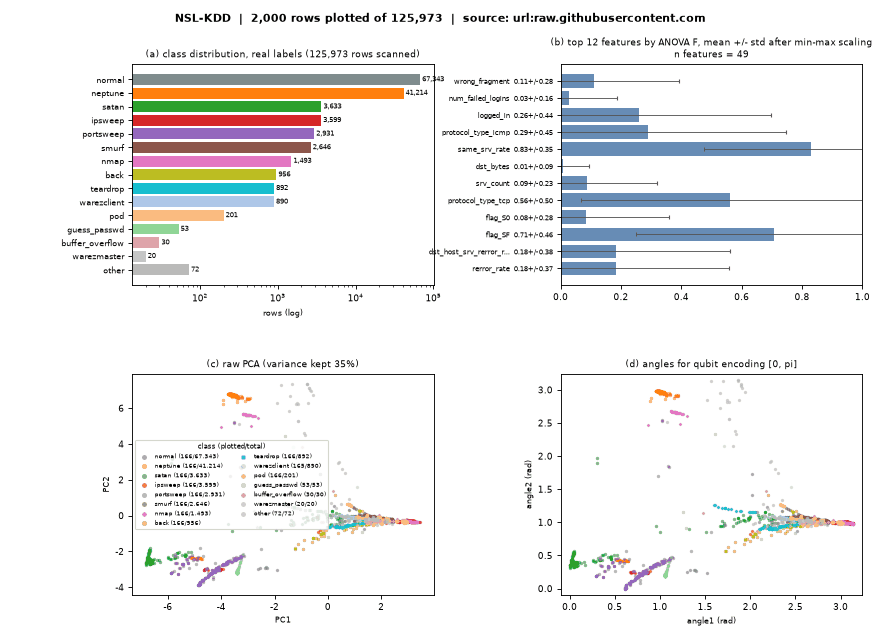

In [14]:
show_dataset("NSL-KDD")

#### KDD Cup 1999 (10%)

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, research use

**Task and use cases:** Historic 1999 DARPA-derived intrusion benchmark (23 attack types); used for anomaly detection and as a sanity benchmark.

**Reference:** Stolfo et al., KDD Cup 1999; UCI KDD Archive.

**Source:** Hugging Face mirror [akahana/kdd-cup-1999](https://huggingface.co/datasets/akahana/kdd-cup-1999). **Topic folders:** `01_Network_Intrusion_Detection`, `14_IoT_IIoT_Attack_Detection`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-003](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_AnomalyDetection_Hdaib2024.ipynb); [QC-016](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQNN_NetworkAttack_Gong2022.ipynb); [QC-105](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Bharathi2026.ipynb)

**Notes:** Parquet mirror (3 MB shard). The corpus notebooks also use scikit-learn fetch_kddcup99 and the figshare 10% gzip.

[LOADED] KDD Cup 1999 (10%)   source: hf:akahana/kdd-cup-1999
  rows scanned: 155,515 of 155,515 | rows kept in the pool: 25,491 | columns: 41 -> 49 features after cleaning | rows plotted: 2,000
  label column: 'result' | classes: 37
  feature names (49): ['duration', 'protocol_type_icmp', 'protocol_type_tcp', 'protocol_type_udp', 'flag_OTH', 'flag_REJ', 'flag_RSTO', 'flag_RSTR', 'flag_S0', 'flag_S1', 'flag_S2', 'flag_S3', 'flag_SF', 'flag_SH', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count'] ...
  removed columns (1): service [text with many distinct values]
  label value counts (real labels, before sampling): smurf.=72,535, normal.=39,5

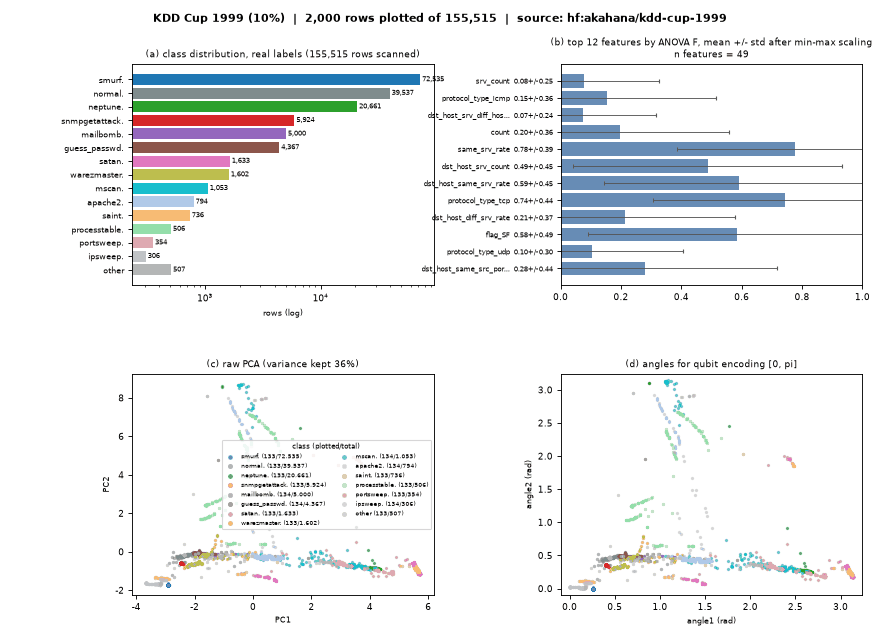

In [15]:
show_dataset("KDD Cup 1999 (10%)")

#### CIC-IDS2017

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Flow-level detection of DDoS, PortScan, brute force, web attacks and infiltration on 78 CICFlowMeter features.

**Reference:** Sharafaldin, Habibi Lashkari, Ghorbani, 'Toward generating a new intrusion detection dataset and intrusion traffic characterization', ICISSP 2018.

**Source:** Hugging Face mirror [c01dsnap/CIC-IDS2017](https://huggingface.co/datasets/c01dsnap/CIC-IDS2017). **Topic folders:** `01_Network_Intrusion_Detection`, `02_Zero_Day_Attack_Detection`, `03_DDoS_DoS_Detection`, `13_Encrypted_Malicious_Traffic_Detection`.

**Used by (9 reproduced notebooks), `QC-ID: notebook link`:** [QC-069](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQRL_IntrusionDetection_Kerkatou2026.ipynb); [QC-076](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionAudit_Gillani2026.ipynb); [QC-080](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QPCA_IntrusionDetection_Salem2026.ipynb); [QC-083](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Khan2026.ipynb); [QC-088](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/MQE_IntrusionDetection_Bhatnagar2026.ipynb); [QC-095](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/HybridQNN_AdversarialRobustIDS_Anaedevha2026.ipynb); [QC-108](https://github.com/owlmt/QML/blob/main/02_Zero_Day_Attack_Detection/QCBM_ZeroDay_AlMalwi2026.ipynb); [QC-171](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Hoang2025.ipynb); [QC-216](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_deAbreu2025.ipynb)

**Notes:** Friday DDoS day (77 MB) from the mirror used by the corpus; StarterArcher/CICIDS2017 on GitHub is the fallback.

[LOADED] CIC-IDS2017   source: hf:c01dsnap/CIC-IDS2017
  rows scanned: 225,745 of 225,745 | rows kept in the pool: 6,000 | columns: 78 -> 65 features after cleaning | rows plotted: 2,000
  label column: ' Label' | classes: 2
  feature names (65): [' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Pac

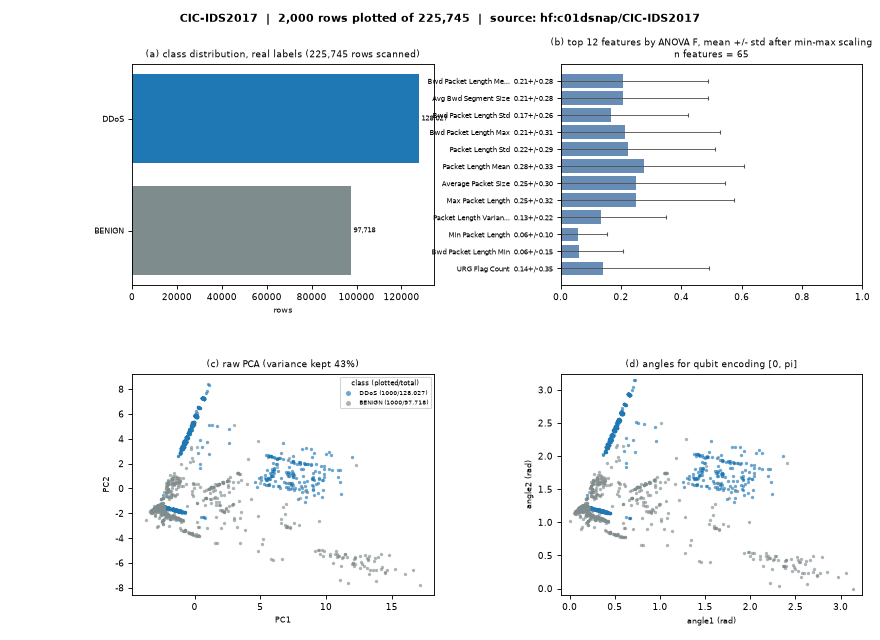

In [16]:
show_dataset("CIC-IDS2017")

#### CSE-CIC-IDS2018

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Large AWS-testbed successor of CIC-IDS2017: brute force, DoS, DDoS, botnet, infiltration, web attacks.

**Reference:** Sharafaldin et al. 2018 (CSE-CIC-IDS2018 on AWS).

**Source:** Hugging Face mirror [pcy12345BSU/CSE-CIC-IDS-2018](https://huggingface.co/datasets/pcy12345BSU/CSE-CIC-IDS-2018). **Topic folders:** `01_Network_Intrusion_Detection`, `12_Cryptojacking_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-004](https://github.com/owlmt/QML/blob/main/19_Cybersecurity_Anomaly_Detection/QRBM_AnomalyDetection_Moro2023.ipynb)

**Notes:** Thursday 01-03-2018 day (108 MB, infiltration).

[LOADED] CSE-CIC-IDS2018   source: hf:pcy12345BSU/CSE-CIC-IDS-2018
  rows scanned: 331,125 of 331,125 | rows kept in the pool: 6,025 | columns: 79 -> 69 features after cleaning | rows plotted: 2,000
  label column: 'Label' | classes: 3
  feature names (69): ['Protocol', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std'] ...
  removed columns (4): Dst Port [identifier / raw text], Timestamp [identifier

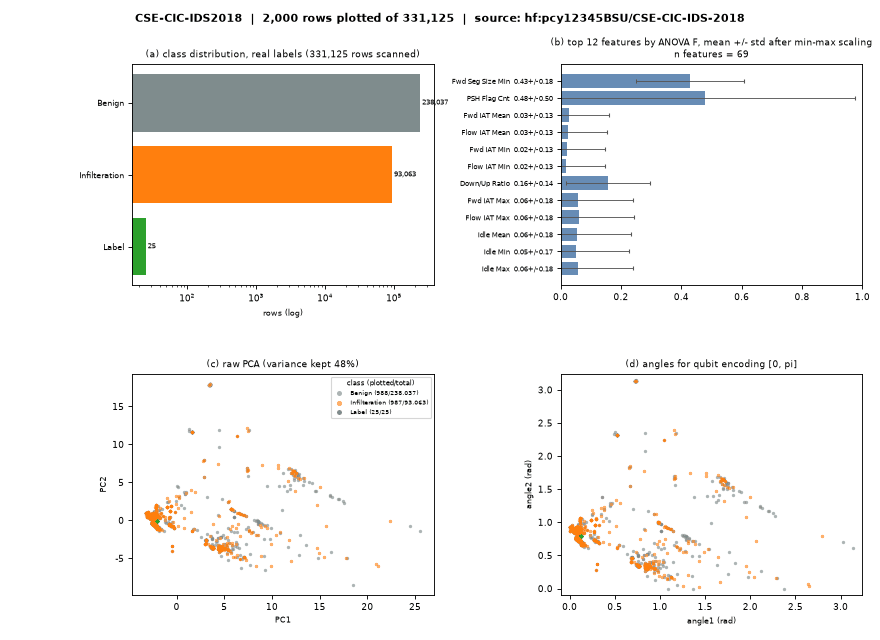

In [17]:
show_dataset("CSE-CIC-IDS2018")

#### UNSW-NB15

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNSW Canberra, research use

**Task and use cases:** Binary and 10-class attack-category detection on 49 flow features (Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms).

**Reference:** Moustafa, Slay, 'UNSW-NB15: a comprehensive data set for network intrusion detection systems', MilCIS 2015.

**Source:** Hugging Face mirror [Mireu-Lab/UNSW-NB15](https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15). **Topic folders:** `01_Network_Intrusion_Detection`, `21_QKD_Attack_Detection`.

**Used by (5 reproduced notebooks), `QC-ID: notebook link`:** [QC-018](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetectionUNSW_deAbreu2024.ipynb); [QC-039](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQSVMQNN_IoTAnomalyDetection_Deepa2026.ipynb); [QC-062](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/SQNN_AdversarialRobustIDS_Filardo2026.ipynb); [QC-065](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/DEHOAQNN_IoTIntrusion_Mohammad2026.ipynb); [QC-076](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionAudit_Gillani2026.ipynb)

**Notes:** Official training-set split (15 MB) from the mirror used by the corpus.

[LOADED] UNSW-NB15   source: hf:Mireu-Lab/UNSW-NB15
  rows scanned: 82,332 of 82,332 | rows kept in the pool: 19,682 | columns: 44 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'attack_cat' | classes: 10
  feature names (50): ['dur', 'service_-', 'service_dhcp', 'service_dns', 'service_ftp', 'service_ftp-data', 'service_http', 'service_pop3', 'service_smtp', 'service_snmp', 'state_CON', 'state_FIN', 'state_INT', 'state_REQ', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len'] ...
  removed columns (5): id [identifier / raw text], ct_src_dport_ltm [identifier / raw text], ct_dst_sport_ltm [identifier / raw text], label [alternative label column], proto [text with many distinct values]
  label value counts (real labels, before sampling): Normal=37,000, Generic=18,871, E

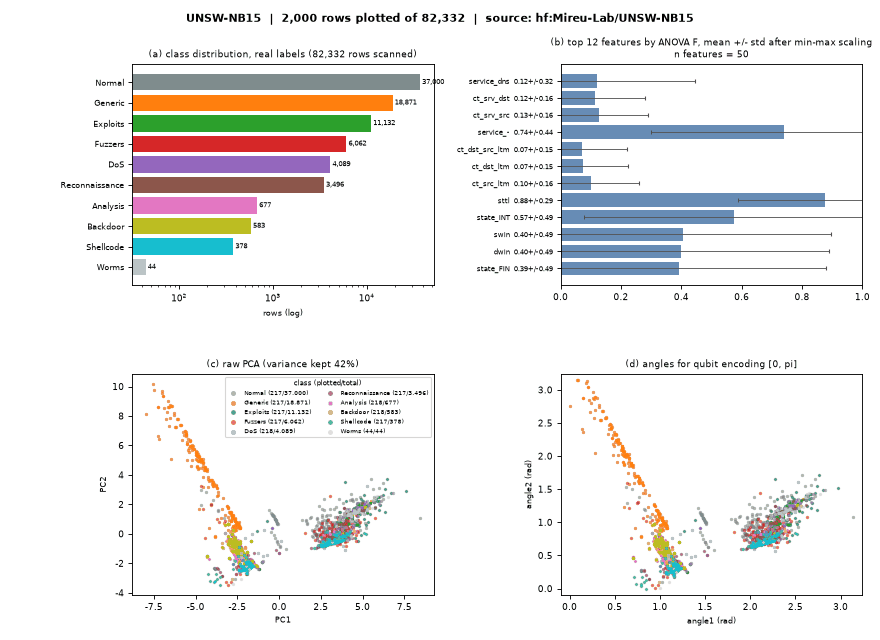

In [18]:
show_dataset("UNSW-NB15")

#### CIC-UNSW-NB15

**Domain:** Network intrusion / evasion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** UNSW-NB15 traffic re-extracted with CICFlowMeter (feature-set comparison, evasion studies).

**Reference:** UNB CIC, CIC-UNSW-NB15 (2024).

**Source:** Hugging Face mirror [bencorn/CIC-UNSW-NB15](https://huggingface.co/datasets/bencorn/CIC-UNSW-NB15). **Topic folders:** `01_Network_Intrusion_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Features (196 MB) and labels (0.9 MB) are separate files joined by row position.

[LOADED] CIC-UNSW-NB15   source: hf:bencorn/CIC-UNSW-NB15
  rows scanned: 447,915 of 447,915 | rows kept in the pool: 21,185 | columns: 76 -> 65 features after cleaning | rows plotted: 2,000
  label column: 'Label (separate file Lable.csv)' | classes: 10
  feature names (65): ['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet

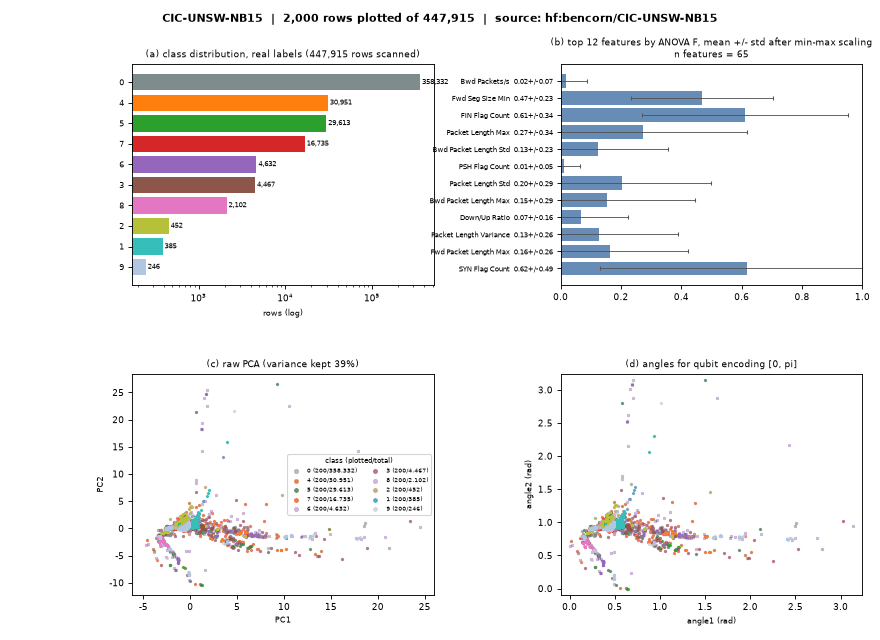

In [19]:
show_dataset("CIC-UNSW-NB15")

#### ISCX-IDS-2012

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `large` (public; FULL mode only) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Seven days of labelled flows (HTTP DoS, DDoS, brute force SSH, infiltration).

**Reference:** Shiravi, Shiravi, Tavallaee, Ghorbani, 'Toward developing a systematic approach to generate benchmark datasets for intrusion detection', Computers & Security 2012.

**Source:** Hugging Face mirror [bencorn/ISCX-IDS-2012](https://huggingface.co/datasets/bencorn/ISCX-IDS-2012). **Topic folders:** `01_Network_Intrusion_Detection`, `13_Encrypted_Malicious_Traffic_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-070](https://github.com/owlmt/QML/blob/main/13_Encrypted_Malicious_Traffic_Detection/HybridQML_EncryptedTraffic_Sodar2026.ipynb)

**Notes:** The only mirror is a 1 GB tarball; loaded in FULL mode only.

In [20]:
show_dataset("ISCX-IDS-2012")

[SKIPPED_LARGE_FAST] ISCX-IDS-2012
Source file is 1,061 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.


#### CIDDS-001

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** HS Coburg, research use

**Task and use cases:** NetFlow records from an emulated small business and an OpenStack cloud; attacker / victim / normal flows.

**Reference:** Ring, Wunderlich, Grudl, Landes, Hotho, 'Flow-based benchmark data sets for intrusion detection', ECCWS 2017.

**Source:** Hugging Face mirror [daveydhruti/cidds-aggregated](https://huggingface.co/datasets/daveydhruti/cidds-aggregated). **Topic folders:** `01_Network_Intrusion_Detection`, `18_Cloud_Virtual_Environment_Threats`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Aggregated internal-server CSV (8.7 MB). The official WISENT-CIDDS-001.zip at hs-coburg.de timed out from this machine; it is listed as the primary source for FULL mode.

[LOADED] CIDDS-001   source: hf:daveydhruti/cidds-aggregated
  rows scanned: 94,066 of 94,066 | rows kept in the pool: 6,715 | columns: 9 -> 3 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 8
  feature names (3): ['duration', 'protocol', 'number_packets']
  removed columns (6): src_ip [identifier / raw text], src_port [identifier / raw text], dst_ip [identifier / raw text], dst_port [identifier / raw text], start_frame [text with many distinct values], end_frame [text with many distinct values]
  label value counts (real labels, before sampling): normal_ 32=80,443, normal_  0=12,908, normal_192=337, victim_  0=286, attacker_  0=37, normal_ 16=33, victim_192=21, normal_ 12=1
  first 3 rows (identifier columns removed):
   duration  protocol  number_packets       label
0     7.374         1            131   normal_  0
1         0         1              5   normal_  0
2     3.038         2             95   normal_  0


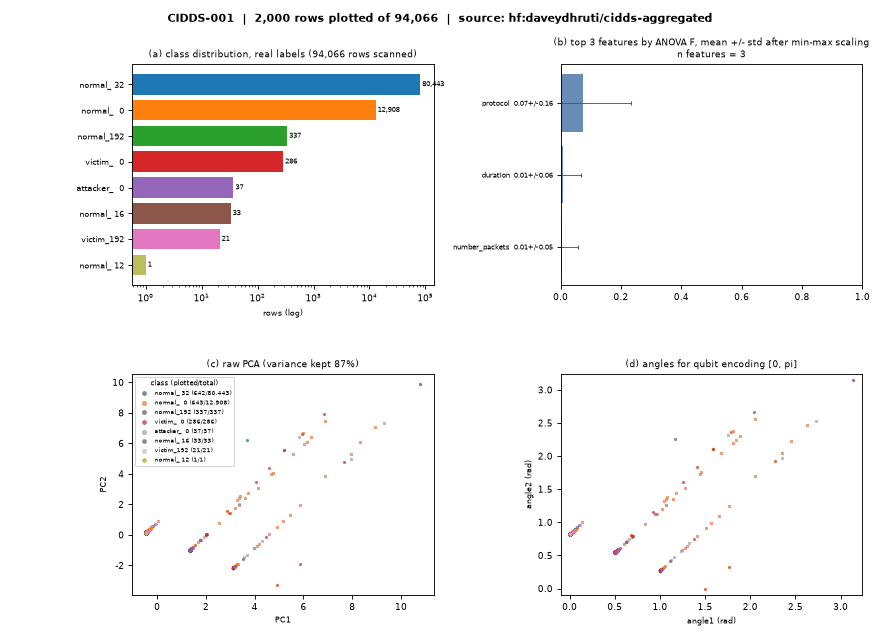

In [21]:
show_dataset("CIDDS-001")

#### Kyoto 2006+

**Domain:** Network intrusion &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** Kyoto University, research use

**Task and use cases:** Honeypot traffic (24 features) labelled normal / known attack / unknown attack.

**Reference:** Song, Takakura, Okabe, Eto, Inoue, Nakao, 'Statistical analysis of honeypot data and building of Kyoto 2006+ dataset', BADGERS 2011.

**Source:** [https://www.takakura.com/Kyoto_data/](https://www.takakura.com/Kyoto_data/). **Topic folders:** `01_Network_Intrusion_Detection`, `28_QML_Hardware_Side_Channel_Crosstalk_Attacks`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-018](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetectionUNSW_deAbreu2024.ipynb); [QC-121](https://github.com/owlmt/QML/blob/main/28_QML_Hardware_Side_Channel_Crosstalk_Attacks/QNN_CrosstalkAttacks_Franco2026.ipynb); [QC-216](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_deAbreu2025.ipynb)

**Notes:** Daily text files on takakura.com; the 2015 file probed from this machine returned 404. Three corpus notebooks load it with their own URL; the atlas needs a working file from the user.

In [22]:
show_dataset("Kyoto 2006+")

[NEEDS_USER_FILE] Kyoto 2006+
Not downloadable automatically (request form or no stable direct link). Official page: https://www.takakura.com/Kyoto_data/ . Provide the data file(s) in atlas_user_files\kyoto_2006/ (a .csv, .parquet, .zip or .xlsx with the label column [17]) and run this cell again.


#### O-RAN intrusion dataset (reduced)

**Domain:** Network intrusion / 5G &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** authors' repository (see its licence)

**Task and use cases:** Open-RAN telemetry flows for QKSVM intrusion detection (Abreu et al. 2026).

**Reference:** de Abreu et al., qml_ids_wqusec_extended GitHub repository.

**Source:** [https://raw.githubusercontent.com/DiegoAbreuSWB/qml_ids_wqusec_extended/main/oran_dataset_...](https://raw.githubusercontent.com/DiegoAbreuSWB/qml_ids_wqusec_extended/main/oran_dataset_reduced.csv). **Topic folders:** `01_Network_Intrusion_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 2.5 MB CSV published with the authors' code.

[LOADED] O-RAN intrusion dataset (reduced)   source: url:raw.githubusercontent.com
  rows scanned: 120,000 of 120,000 | rows kept in the pool: 18,000 | columns: 17 -> 13 features after cleaning | rows plotted: 2,000
  label column: 'attack_category' | classes: 6
  feature names (13): ['http_status_error', 'conn_state_enc', 'log_dst_bytes', 'duration', 'log_files_total_bytes', 'dst_bytes', 'bytes_per_pkt_dst', 'log_src_ip_bytes', 'src_ip_bytes', 'is_file_transfered', 'files_total_bytes', 'byte_ratio', 'log_dst_ip_bytes']
  removed columns (4): dst_port [identifier / raw text], src_port [identifier / raw text], label [alternative label column], label_bin [alternative label column]
  label value counts (real labels, before sampling): benign=20,000, bruteforce=20,000, ddos=20,000, dos=20,000, probe=20,000, web=20,000
  first 3 rows (identifier columns removed):
   http_status_error  conn_state_enc  log_dst_bytes  duration  ...  files_total_bytes  byte_ratio  log_dst_ip_bytes  label
0      

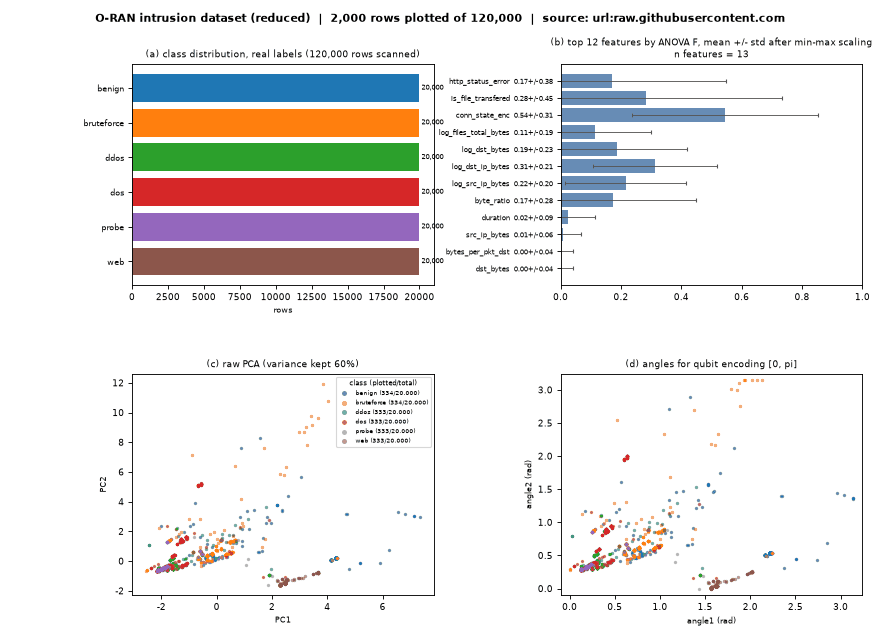

In [23]:
show_dataset("O-RAN intrusion dataset (reduced)")

### 2. DDoS

Reflection and exploitation distributed denial-of-service families.

#### CIC-DDoS2019

**Domain:** DDoS &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Reflection and exploitation DDoS families (DNS, LDAP, MSSQL, NetBIOS, NTP, SNMP, SSDP, UDP, SYN, TFTP, Portmap) on CICFlowMeter features.

**Reference:** Sharafaldin, Habibi Lashkari, Hakak, Ghorbani, 'Developing realistic distributed denial of service (DDoS) attack dataset and taxonomy', ICCST 2019.

**Source:** Hugging Face mirror [RonaldoMPF/CIC-DDoS2019-15C](https://huggingface.co/datasets/RonaldoMPF/CIC-DDoS2019-15C). **Topic folders:** `03_DDoS_DoS_Detection`.

**Used by (5 reproduced notebooks), `QC-ID: notebook link`:** [QC-020](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_EncodingComparison_Kadi2025.ipynb); [QC-033](https://github.com/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QSVM_DDoS_Said2023.ipynb); [QC-034](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNN_DDoS_Kucukkara2024.ipynb); [QC-068](https://github.com/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QNN_KnowledgeDistillationDDoS_Krishnamurthy2026.ipynb); [QC-090](https://github.com/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QSVM_VanishingSimilarityDDoS_RodriguezAlmazan2026.ipynb)

**Notes:** 15-class subset (9 MB). The full per-attack CSVs (baalajimaestro/CICDDoS2019, up to 9 GB each) are used by the corpus notebooks with chunked reads.

[LOADED] CIC-DDoS2019   source: hf:RonaldoMPF/CIC-DDoS2019-15C
  rows scanned: 120,000 of 120,000 | rows kept in the pool: 36,000 | columns: 14 -> 14 features after cleaning | rows plotted: 2,000
  label column: ' Label' | classes: 12
  feature names (14): [' Flow Duration', ' Fwd Packet Length Std', ' Flow Packets/s', ' Flow IAT Mean', ' Fwd Header Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' ACK Flag Count', 'Subflow Fwd Packets', ' Subflow Fwd Bytes', 'Init_Win_bytes_forward', ' act_data_pkt_fwd', ' min_seg_size_forward']
  label value counts (real labels, before sampling): DrDoS_DNS=10,100, Syn=10,070, DrDoS_SNMP=10,035, DrDoS_UDP=10,034, DrDoS_SSDP=10,006, DrDoS_NTP=9,988, TFTP=9,988, DrDoS_NetBIOS=9,988, UDP-lag=9,963, DrDoS_LDAP=9,958, BENIGN=9,952, DrDoS_MSSQL=9,918
  first 3 rows (identifier columns removed):
    Flow Duration   Fwd Packet Length Std   Flow Packets/s   Flow IAT Mean  ...  Init_Win_bytes_forward   act_data_pkt_fwd   min_seg

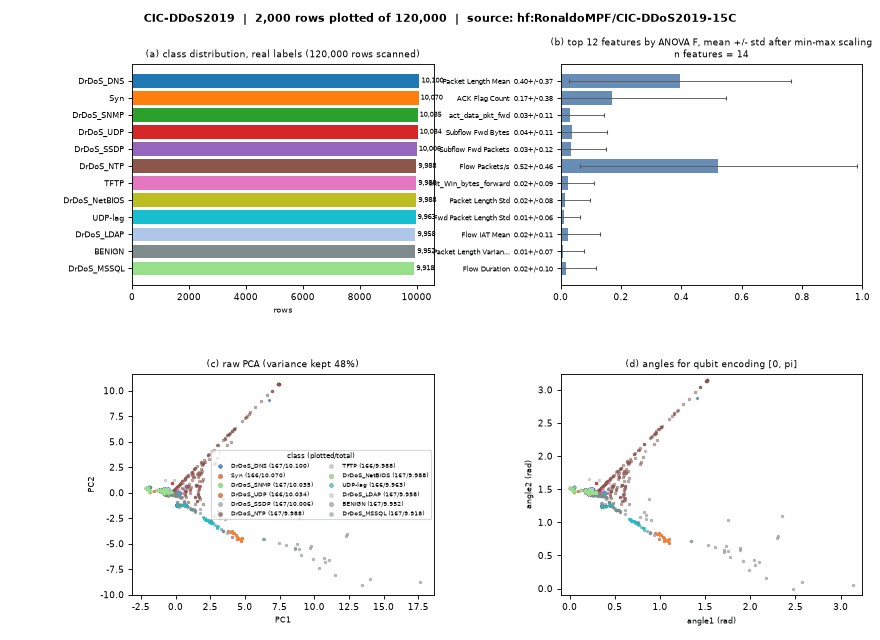

In [24]:
show_dataset("CIC-DDoS2019")

### 3. Botnet and DGA

Domain names generated by domain-generation algorithms, and labelled botnet flows.

#### Botnet DGA Dataset

**Domain:** Botnet / DGA &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** IEEE DataPort open access

**Task and use cases:** Domain names from 50+ DGA families vs legitimate domains; classification from string features.

**Reference:** Zago, Gil Perez, Martinez Perez, 'UMUDGA: a dataset for profiling DGA-based botnet', Computers & Security 2020 (IEEE DataPort 'Botnet DGA Dataset').

**Source:** [https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv](https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv). **Topic folders:** `04_Botnet_DGA_Detection`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-002](https://github.com/owlmt/QML/blob/main/04_Botnet_DGA_Detection/QHTC_BotnetDGA_Tehrani2024.ipynb); [QC-024](https://github.com/owlmt/QML/blob/main/04_Botnet_DGA_Detection/HybridQNN_BotnetDGA_Suryotrisongko2022.ipynb)

**Notes:** 5000-row feature CSV published by Sultanow et al. with the quantum-botnet-detection code (Azure blob), used by two corpus notebooks.

[LOADED] Botnet DGA Dataset   source: url:dgadata.blob.core.windows.net
  rows scanned: 5,001 of 5,001 | rows kept in the pool: 5,001 | columns: 7 -> 7 features after cleaning | rows plotted: 2,000
  label column: 'Result' | classes: 2
  feature names (7): ['Entropy', 'REAlexa', 'MinREBotnets', 'InformationRadius', 'CharLength', 'TreeNewFeature', 'nGramReputation_Alexa']
  label value counts (real labels, before sampling): 0=2,763, 1=2,238
  first 3 rows (identifier columns removed):
   Entropy  REAlexa  MinREBotnets  InformationRadius  CharLength  TreeNewFeature  nGramReputation_Alexa label
0    1.585    5.103         3.494         0.9609               6         0.1481           3.557             0
1    3.393   0.9854        0.9438         0.5611              17         0.1071           102.6             0
2    2.914   0.9923        0.8205         0.6444              15         0.1071           104.2             0


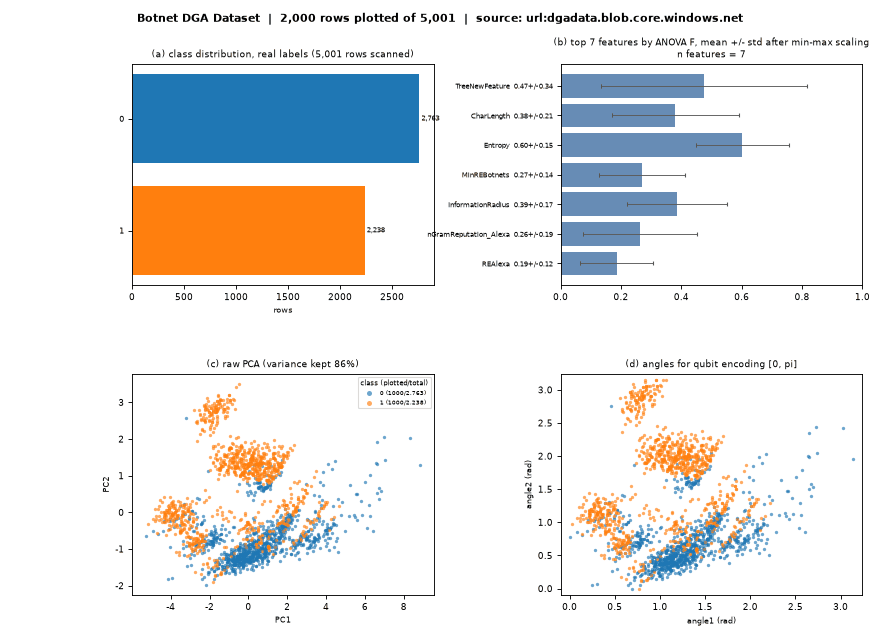

In [25]:
show_dataset("Botnet DGA Dataset")

#### DGA detection (argencon)

**Domain:** Botnet / DGA &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** Raw domain strings labelled DGA / normal (character-level models).

**Reference:** Catania, Garcia, Torres, 'Deep convolutional neural networks for DGA detection', Argencon 2018.

**Source:** Hugging Face mirror [harpomaxx/dga-detection](https://huggingface.co/datasets/harpomaxx/dga-detection). **Topic folders:** `04_Botnet_DGA_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 34 MB gzip CSV of domain strings; features are derived from the string in the atlas (length, entropy, digit ratio, n-gram counts).

[LOADED] DGA detection (argencon)   source: hf:harpomaxx/dga-detection
  rows scanned: 2,918,496 of 2,918,496 | rows kept in the pool: 103,429 | columns: 3 -> 37 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 53
  feature names (37): ['length', 'entropy', 'digit_ratio', 'vowel_ratio', 'hyphens', 'dots', 'unique_chars', 'bigram_co', 'bigram_.c', 'bigram_om', 'bigram_or', 'bigram_rg', 'bigram_.o', 'bigram_ne', 'bigram_et', 'bigram_in', 'bigram_ru', 'bigram_.n', 'bigram_bi', 'bigram_.r', 'bigram_iz', 'bigram_.b', 'bigram_fo', 'bigram_nf', 'bigram_er', 'bigram_e.', 'bigram_re', 'bigram_.i', 'bigram_es', 'bigram_an', 'bigram_o.', 'bigram_st', 'bigram_ea', 'bigram_at', 'bigram_ic', 'bigram_s.', 'bigram_ar']
  removed columns (1): domain [converted to string features]
  label value counts (real labels, before sampling): normal.alexa=999,993, dga.banjori=439,218, dga.post=220,000, dga.tinba=193,912, dga.cryptolocker=112,809, dga.ramdo=102,000, dga.conficker=10

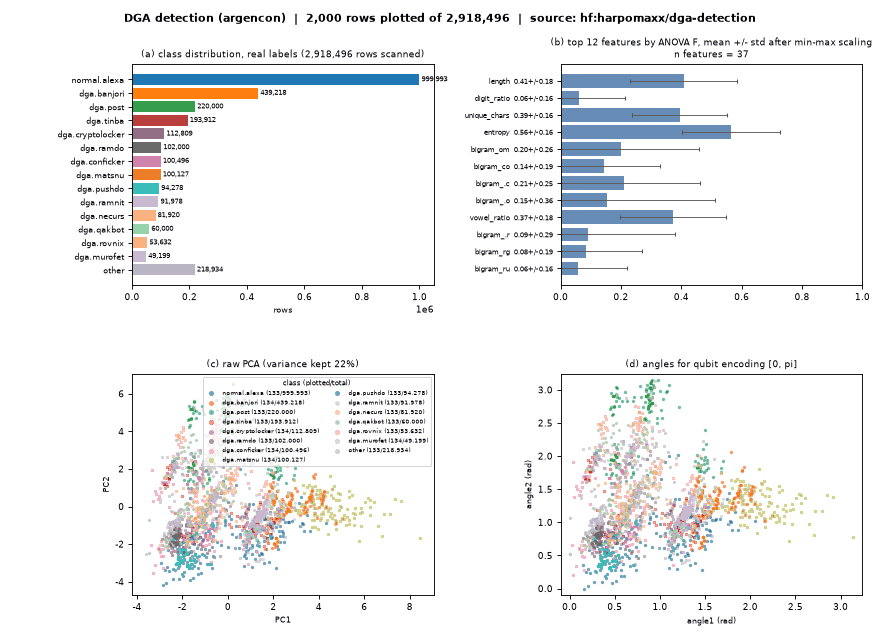

In [26]:
show_dataset("DGA detection (argencon)")

#### CTU-13 (scenario 42)

**Domain:** Botnet &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Stratosphere Lab, CC BY

**Task and use cases:** Bidirectional NetFlows of 13 botnet captures (Neris, Rbot, Virut, Menti, Sogou, Murlo, NSIS.ay) labelled background / normal / botnet.

**Reference:** Garcia, Grill, Stiborek, Zunino, 'An empirical comparison of botnet detection methods', Computers & Security 2014.

**Source:** [https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/detailed-bidirectio...](https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/detailed-bidirectional-flow-labels/capture20110810.binetflow). **Topic folders:** `04_Botnet_DGA_Detection`, `13_Encrypted_Malicious_Traffic_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-171](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Hoang2025.ipynb)

**Notes:** 386 MB flow file streamed: only the first 300k lines are read, then class-balanced. The full 2 GB tarball is FULL-mode only.

[LOADED] CTU-13 (scenario 42)   source: url:mcfp.felk.cvut.cz (streamed, not saved)
  rows scanned: 2,824,636 of 2,824,636 | rows kept in the pool: 9,000 | columns: 14 -> 13 features after cleaning | rows plotted: 2,000
  label column: 'Label' | classes: 3
  feature names (13): ['Dur', 'Proto_icmp', 'Proto_rtcp', 'Proto_tcp', 'Proto_udp', 'Dir_   ->', 'Dir_   ?>', 'Dir_  <->', 'Dir_  <?>', 'sTos', 'TotPkts', 'TotBytes', 'SrcBytes']
  removed columns (6): StartTime [identifier / raw text], SrcAddr [identifier / raw text], Sport [identifier / raw text], DstAddr [identifier / raw text], Dport [identifier / raw text], State [text with many distinct values]
  label value counts (real labels, before sampling): Background=2,753,288, Botnet=40,961, Normal=30,387
  first 3 rows (identifier columns removed):
       Dur  Proto_icmp  Proto_rtcp  Proto_tcp  ...  TotPkts  TotBytes  SrcBytes       label
0    16.03           0           0          1  ...       10      1562       442  Background
1 0.00

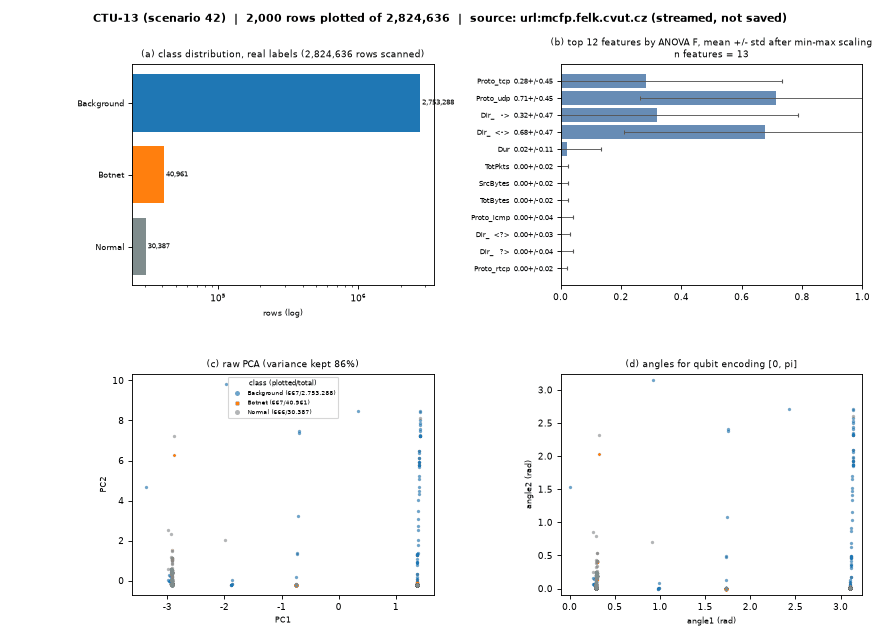

In [27]:
show_dataset("CTU-13 (scenario 42)")

### 4. IoT and IIoT

Traffic and telemetry of IoT, industrial IoT, medical IoT and electric-vehicle charging testbeds.

#### TON_IoT (network)

**Domain:** IoT / IIoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNSW Canberra, research use

**Task and use cases:** Network flows from an IoT/IIoT testbed labelled normal and 9 attack types (backdoor, DDoS, DoS, injection, MITM, password, ransomware, scanning, XSS).

**Reference:** Moustafa, 'A new distributed architecture for evaluating AI-based security systems at the edge: network TON_IoT datasets', Sustainable Cities and Society 2021.

**Source:** Hugging Face mirror [codymlewis/TON_IoT_network](https://huggingface.co/datasets/codymlewis/TON_IoT_network). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `01_Network_Intrusion_Detection`, `15_Smart_Grid_Power_System_Attacks`.

**Used by (5 reproduced notebooks), `QC-ID: notebook link`:** [QC-055](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QML_NoisyIDSBenchmark_Cirillo2026.ipynb); [QC-076](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionAudit_Gillani2026.ipynb); [QC-088](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/MQE_IntrusionDetection_Bhatnagar2026.ipynb); [QC-095](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/HybridQNN_AdversarialRobustIDS_Anaedevha2026.ipynb); [QC-171](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Hoang2025.ipynb)

**Notes:** Train_Test_Network split (30 MB) used by five corpus notebooks.

[LOADED] TON_IoT (network)   source: hf:codymlewis/TON_IoT_network
  rows scanned: 211,043 of 211,043 | rows kept in the pool: 28,043 | columns: 43 -> 57 features after cleaning | rows plotted: 2,000
  label column: 'type' | classes: 10
  feature names (57): ['proto_icmp', 'proto_tcp', 'proto_udp', 'service_-', 'service_dns', 'service_ftp', 'service_http', 'service_ssl', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA_-', 'dns_AA_F', 'dns_AA_T', 'dns_RD_-', 'dns_RD_F', 'dns_RD_T', 'dns_RA_-', 'dns_RA_F', 'dns_RA_T', 'dns_rejected_-', 'dns_rejected_F', 'dns_rejected_T', 'ssl_version_-', 'ssl_version_TLSv12', 'ssl_cipher_-', 'ssl_cipher_TLS_ECDHE_RSA_WITH_AES_128_GCM_SHA256', 'ssl_resumed_-', 'ssl_resumed_F', 'ssl_established_-', 'ssl_established_F', 'http_trans_depth_-'] ...
  removed columns (10): src_ip [identifier / raw text], src_port [identifier / raw text], dst_ip [identif

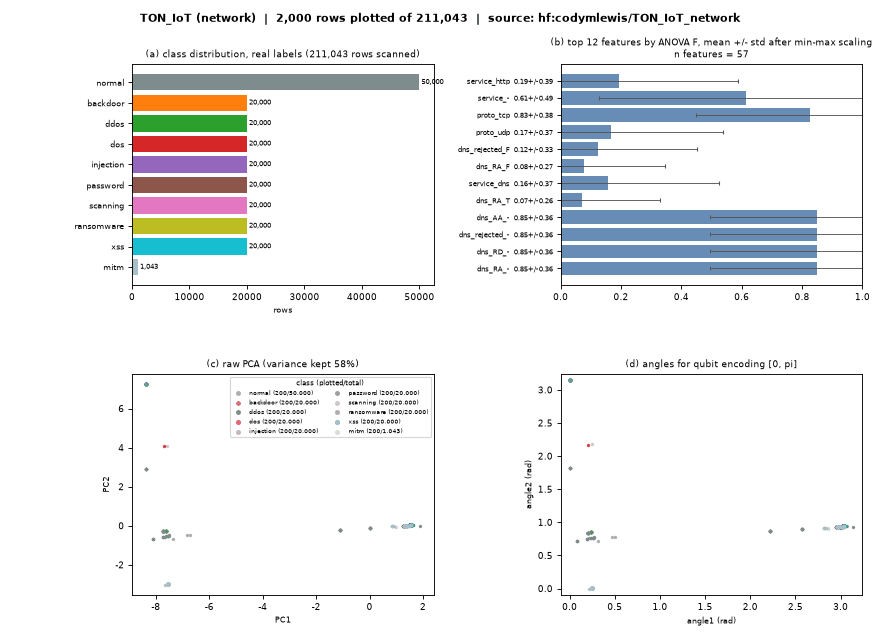

In [28]:
show_dataset("TON_IoT (network)")

#### TON_IoT (IoT telemetry)

**Domain:** IoT / IIoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNSW Canberra, research use

**Task and use cases:** Sensor telemetry (fridge, GPS, garage door, Modbus, motion/light, thermostat, weather) with per-reading attack labels.

**Reference:** Moustafa 2021 (TON_IoT telemetry subsets).

**Source:** Hugging Face mirror [SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets](https://huggingface.co/datasets/SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Modbus subset (1.7 MB), the closest to ICS use cases.

[LOADED] TON_IoT (IoT telemetry)   source: hf:SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets
  rows scanned: 31,106 of 31,106 | rows kept in the pool: 13,106 | columns: 7 -> 4 features after cleaning | rows plotted: 2,000
  label column: 'type' | classes: 6
  feature names (4): ['FC1_Read_Input_Register', 'FC2_Read_Discrete_Value', 'FC3_Read_Holding_Register', 'FC4_Read_Coil']
  removed columns (3): date [identifier / raw text], time [identifier / raw text], label [alternative label column]
  label value counts (real labels, before sampling): normal=15,000, backdoor=5,000, injection=5,000, password=5,000, xss=577, scanning=529
  first 3 rows (identifier columns removed):
   FC1_Read_Input_Register  FC2_Read_Discrete_Value  FC3_Read_Holding_Register  FC4_Read_Coil      label
0           4689                3.342e+04                 1.62e+04                  5.578e+04  injection
1      1.603e+04                3.594e+04                1.798e+04                  2.381e+04  injection
2

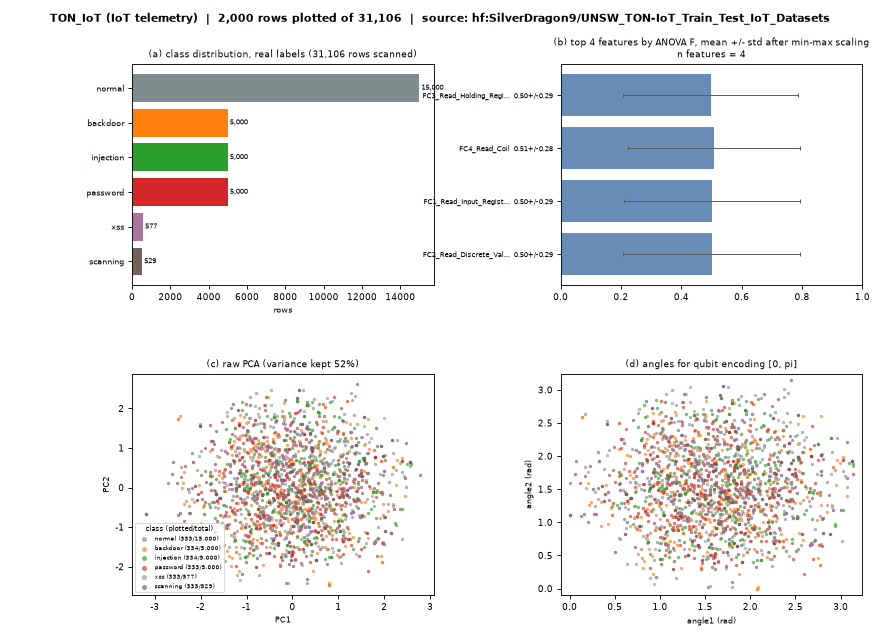

In [29]:
show_dataset("TON_IoT (IoT telemetry)")

#### NF-ToN-IoT-v2

**Domain:** IoT / IIoT &nbsp;|&nbsp; **Access:** `large` (public; FULL mode only) &nbsp;|&nbsp; **Licence:** UQ, research use

**Task and use cases:** NetFlow v2 (43 features) version of TON_IoT for cross-dataset generalisation studies.

**Reference:** Sarhan, Layeghy, Portmann, 'Towards a standard feature set for network intrusion detection system datasets', Mobile Networks and Applications 2022.

**Source:** Hugging Face mirror [Nora9029/NF-ToN-IoT-v2](https://huggingface.co/datasets/Nora9029/NF-ToN-IoT-v2). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `01_Network_Intrusion_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-076](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionAudit_Gillani2026.ipynb)

**Notes:** Test split is 532 MB: FULL mode only (streamed first rows in FAST mode if the loader supports range reads).

In [30]:
show_dataset("NF-ToN-IoT-v2")

[SKIPPED_LARGE_FAST] NF-ToN-IoT-v2
Source file is 532 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.


#### IoT-23

**Domain:** IoT botnet &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Stratosphere Lab, CC BY

**Task and use cases:** Zeek conn.log records of 20 malware captures (Mirai, Torii, Okiru, Hajime...) and 3 benign captures.

**Reference:** Garcia, Parmisano, Erquiaga, 'IoT-23: a labeled dataset with malicious and benign IoT network traffic', Stratosphere Lab 2020.

**Source:** Hugging Face mirror [Lystea/IOT23-PARQUET](https://huggingface.co/datasets/Lystea/IOT23-PARQUET). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `04_Botnet_DGA_Detection`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-003](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_AnomalyDetection_Hdaib2024.ipynb); [QC-030](https://github.com/owlmt/QML/blob/main/03_DDoS_DoS_Detection/HybridQNN_IoMTSecurity_Rajawat2023.ipynb)

**Notes:** Two small scenarios (0.7 MB and 34 MB). The original conn.log.labeled files on mcfp.felk.cvut.cz also download directly.

[LOADED] IoT-23   source: hf:Lystea/IOT23-PARQUET
  rows scanned: 1,031,893 of 1,031,893 | rows kept in the pool: 12,000 | columns: 53 -> 10 features after cleaning | rows plotted: 2,000
  label column: 'label_attack' | classes: 4
  feature names (10): ['l4_proto', 'duration', 'packets', 'packets_rev', 'bytes', 'bytes_rev', 'flow_end_reason', 'tcp_flags', 'tcp_flags_rev', 'dns_present']
  removed columns (12): flow_id [identifier / raw text], dataset [annotation, not a feature], src_ip [identifier / raw text], dst_ip [identifier / raw text], device_mac [identifier / raw text], ts_start [identifier / raw text], ts_end [identifier / raw text], label_binary [alternative label column], label_device [alternative label column], label_service [alternative label column] ...
  label value counts (real labels, before sampling): malicious=539,587, benign=471,198, DDoS=14,394, C&C=6,714
  first 3 rows (identifier columns removed):
   l4_proto  duration  packets  packets_rev  ...  tcp_flags  tcp_fl

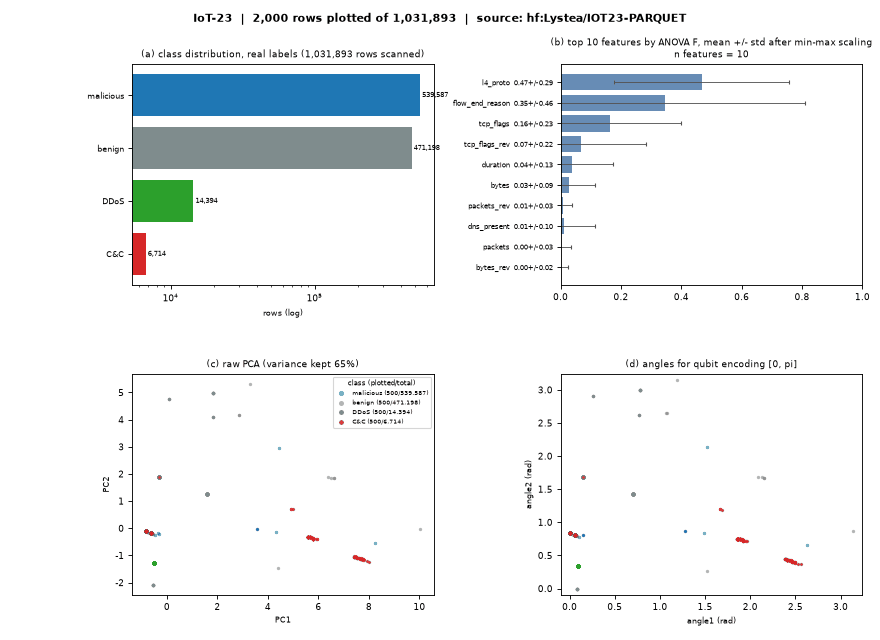

In [31]:
show_dataset("IoT-23")

#### BoT-IoT

**Domain:** IoT botnet &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNSW Canberra, research use

**Task and use cases:** Botnet traffic from a realistic IoT testbed: DDoS, DoS, reconnaissance, information theft.

**Reference:** Koroniotis, Moustafa, Sitnikova, Turnbull, 'Towards the development of realistic botnet dataset in the IoT for network forensic analytics: Bot-IoT dataset', FGCS 2019.

**Source:** Hugging Face mirror [masoltani/bot-iot](https://huggingface.co/datasets/masoltani/bot-iot). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `01_Network_Intrusion_Detection`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-017](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_QCNN_StreamIDS_Kalinin2023.ipynb); [QC-105](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Bharathi2026.ipynb)

**Notes:** 730 MB parquet: the atlas reads only the first row group through HfFileSystem (range request), so no full download is needed.

[LOADED] BoT-IoT   source: hf:masoltani/bot-iot (first row group of 7,509,984 rows)
  rows scanned: 1,048,576 of 7,509,984 | rows kept in the pool: 15,000 | columns: 39 -> 26 features after cleaning | rows plotted: 2,000
  label column: 'category' | classes: 5
  feature names (26): ['flgs_number', 'proto_number', 'pkts', 'bytes', 'state_number', 'seq', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP']
  removed columns (13): stime [identifier / raw text], sport [identifier / raw text], dport [identifier / raw text], ltime [identifier / raw text], TnP_Per_Dport [identifier / raw text], AR_P_Proto_P_SrcIP [identifier / raw text], AR_P_Proto_P_DstIP [identifier / raw text], N_IN_Conn_P_DstIP [identifier / raw text], N_IN_Conn_P_SrcIP [identifier / raw text], AR_P_Proto_P_Sport [identifier / 

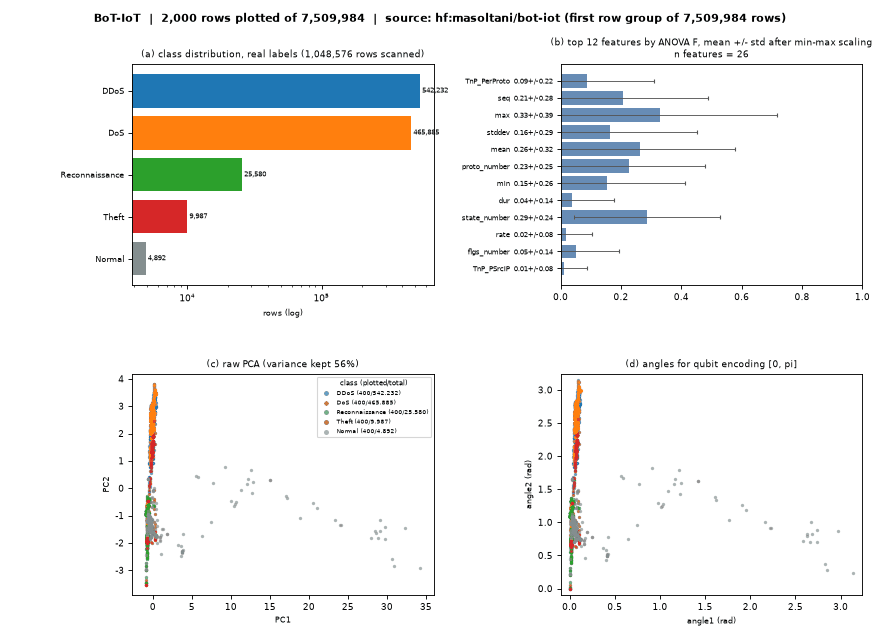

In [32]:
show_dataset("BoT-IoT")

#### CIC-IoT-2023

**Domain:** IoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** 33 attacks (DDoS, DoS, recon, web, brute force, spoofing, Mirai) against 105 IoT devices; 46 flow features.

**Reference:** Neto et al., 'CICIoT2023: a real-time dataset and benchmark for large-scale attacks in IoT environment', Sensors 2023.

**Source:** Hugging Face mirror [lacg030175/CIC-IoT-2023](https://huggingface.co/datasets/lacg030175/CIC-IoT-2023). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `01_Network_Intrusion_Detection`, `03_DDoS_DoS_Detection`.

**Used by (4 reproduced notebooks), `QC-ID: notebook link`:** [QC-003](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_AnomalyDetection_Hdaib2024.ipynb); [QC-020](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_EncodingComparison_Kadi2025.ipynb); [QC-031](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QBoost_SmartCitySIEM_CICIoT2023_Barletta2024.ipynb); [QC-083](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Khan2026.ipynb)

**Notes:** 13 MB random test split used by the corpus.

[LOADED] CIC-IoT-2023   source: hf:lacg030175/CIC-IoT-2023
  rows scanned: 268,463 of 268,463 | rows kept in the pool: 23,607 | columns: 41 -> 39 features after cleaning | rows plotted: 2,000
  label column: 'attack_class' | classes: 8
  feature names (39): ['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance']
  removed columns (2): Label [alternative label column], label [alternative label column]
  label value counts (real labels, before sampling): DDoS=90,353, Recon=40,380, DoS=40,067, Benign=39,998, Mirai=30,094, Spoofing=19,956, Web-based=5,008, BruteForce=2,607
  first 3 rows (identifier columns remove

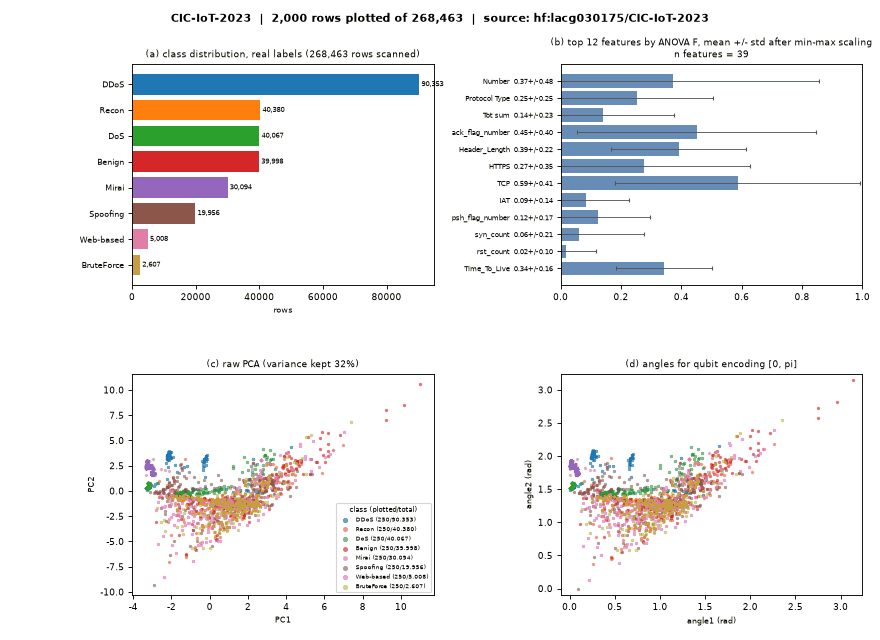

In [33]:
show_dataset("CIC-IoT-2023")

#### Edge-IIoTset

**Domain:** IIoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0 (Kaggle original)

**Task and use cases:** 14 attacks on an IoT/IIoT testbed (DDoS, injection, MITM, malware, scanning); ML-ready CSV with 61 features.

**Reference:** Ferrag, Friha, Hamouda, Maglaras, Janicke, 'Edge-IIoTset: a new comprehensive realistic cyber security dataset of IoT and IIoT applications', IEEE Access 2022.

**Source:** Hugging Face mirror [Sunayanajagadesh/ML_EdgeIIoT_dataset](https://huggingface.co/datasets/Sunayanajagadesh/ML_EdgeIIoT_dataset). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-020](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_EncodingComparison_Kadi2025.ipynb)

**Notes:** 82 MB Hugging Face mirror of the Kaggle ML-EdgeIIoT file; no Kaggle key needed.

[LOADED] Edge-IIoTset   source: hf:Sunayanajagadesh/ML_EdgeIIoT_dataset
  rows scanned: 157,800 of 157,800 | rows kept in the pool: 41,215 | columns: 62 -> 31 features after cleaning | rows plotted: 2,000
  label column: 'Attack_type' | classes: 15
  feature names (31): ['arp.opcode', 'arp.hw.size', 'icmp.checksum', 'icmp.seq_le', 'http.content_length', 'http.response', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.seq', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.topic_len', 'mqtt.ver']
  removed columns (9): frame.time [identifier / raw text], ip.src_host [identifier / raw text], ip.dst_host [identifier / raw text], icmp.transmit_times... [identifier / raw text], tcp.dstport [identifier / raw t

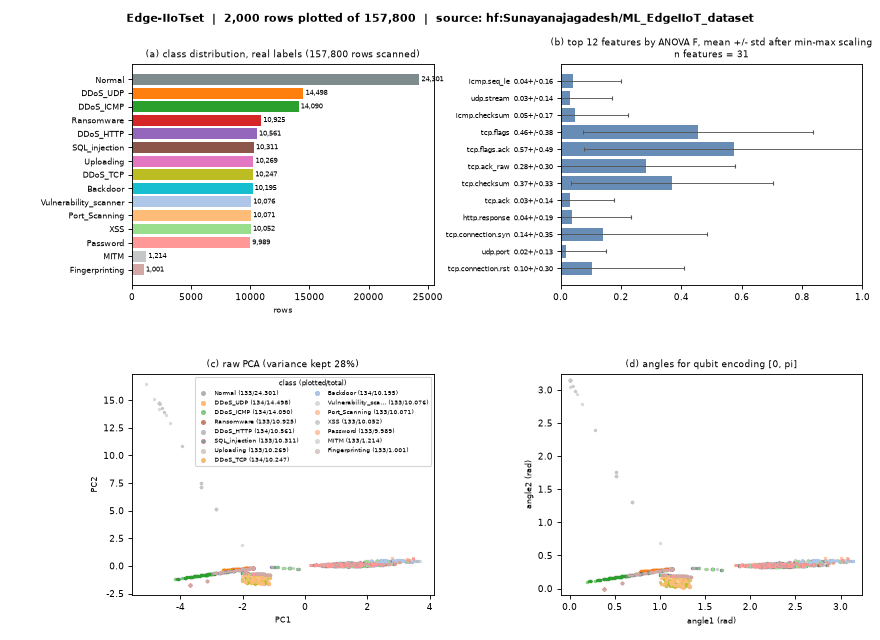

In [34]:
show_dataset("Edge-IIoTset")

#### N-BaIoT

**Domain:** IoT botnet &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 115 traffic statistics per packet from 9 commercial IoT devices infected with Mirai and BASHLITE (gafgyt).

**Reference:** Meidan et al., 'N-BaIoT: network-based detection of IoT botnet attacks using deep autoencoders', IEEE Pervasive Computing 2018.

**Source:** [https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip](https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `30_QML_Defences_Against_ML_Attacks`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-044](https://github.com/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/QRNN_AdversarialAttackFL_Venkat2026.ipynb); [QC-091](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QAE_FederatedAnomalyDetection_Chaudhary2026.ipynb)

**Notes:** UCI static zip (nested per-device archives); labels come from the member file name.

[LOADED] N-BaIoT   source: url:archive.ics.uci.edu (device: Danmini doorbell)
  rows scanned: 423,966 of 423,966 | rows kept in the pool: 12,000 | columns: 115 -> 115 features after cleaning | rows plotted: 2,000
  label column: '(file name)' | classes: 4
  feature names (115): ['MI_dir_L5_weight', 'MI_dir_L5_mean', 'MI_dir_L5_variance', 'MI_dir_L3_weight', 'MI_dir_L3_mean', 'MI_dir_L3_variance', 'MI_dir_L1_weight', 'MI_dir_L1_mean', 'MI_dir_L1_variance', 'MI_dir_L0.1_weight', 'MI_dir_L0.1_mean', 'MI_dir_L0.1_variance', 'MI_dir_L0.01_weight', 'MI_dir_L0.01_mean', 'MI_dir_L0.01_variance', 'H_L5_weight', 'H_L5_mean', 'H_L5_variance', 'H_L3_weight', 'H_L3_mean', 'H_L3_variance', 'H_L1_weight', 'H_L1_mean', 'H_L1_variance', 'H_L0.1_weight', 'H_L0.1_mean', 'H_L0.1_variance', 'H_L0.01_weight', 'H_L0.01_mean', 'H_L0.01_variance', 'HH_L5_weight', 'HH_L5_mean', 'HH_L5_std', 'HH_L5_magnitude', 'HH_L5_radius', 'HH_L5_covariance', 'HH_L5_pcc', 'HH_L3_weight', 'HH_L3_mean', 'HH_L3_std'] ...
  label

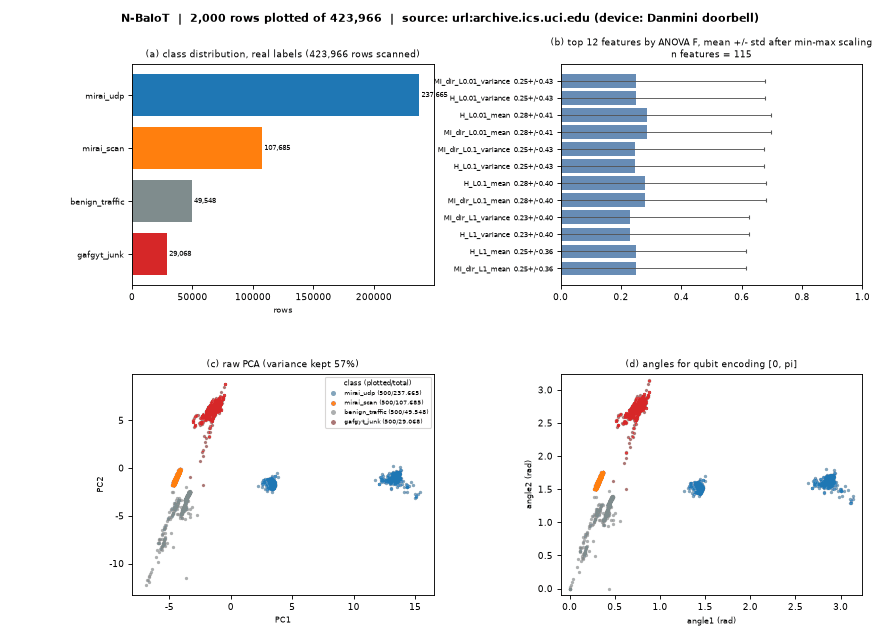

In [35]:
show_dataset("N-BaIoT")

#### IoTID20

**Domain:** IoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** research use

**Task and use cases:** Smart-home IoT flows (Mirai, DoS, MITM, scan) with binary, category and sub-category labels.

**Reference:** Ullah, Mahmoud, 'A scheme for generating a dataset for anomalous activity detection in IoT networks', Canadian AI 2020.

**Source:** Hugging Face mirror [KathiS/IoTID20_Preprocessed_File](https://huggingface.co/datasets/KathiS/IoTID20_Preprocessed_File). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 106 MB preprocessed single file.

[LOADED] IoTID20   source: hf:KathiS/IoTID20_Preprocessed_File
  rows scanned: 625,783 of 625,783 | rows kept in the pool: 27,000 | columns: 22 -> 21 features after cleaning | rows plotted: 2,000
  label column: 'Label' | classes: 9
  feature names (21): ['Flow_Duration', 'Init_Bwd_Win_Byts', 'Idle_Mean', 'Flow_IAT_Min', 'Flow_Pkts/s', 'Pkt_Len_Max', 'ACK_Flag_Cnt', 'Fwd_Pkt_Len_Max', 'Bwd_Header_Len', 'TotLen_Bwd_Pkts', 'Fwd_Pkts/s', 'Flow_Byts/s', 'Bwd_Pkt_Len_Max', 'Bwd_Pkts/s', 'TotLen_Fwd_Pkts', 'Flow_IAT_Max', 'Fwd_Pkt_Len_Min', 'Bwd_Pkt_Len_Mean', 'Pkt_Len_Std', 'SYN_Flag_Cnt', 'Pkt_Len_Mean']
  removed columns (1): Dst_Port [identifier / raw text]
  label value counts (real labels, before sampling): Mirai-UDP Flooding=183,554, Mirai-Hostbruteforceg=121,181, DoS-Synflooding=59,391, Mirai-HTTP Flooding=55,818, Mirai-Ackflooding=55,124, Scan Port OS=53,073, Normal=40,073, MITM ARP Spoofing=35,377, Scan Hostport=22,192
  first 3 rows (identifier columns removed):
   Flow_Duration  

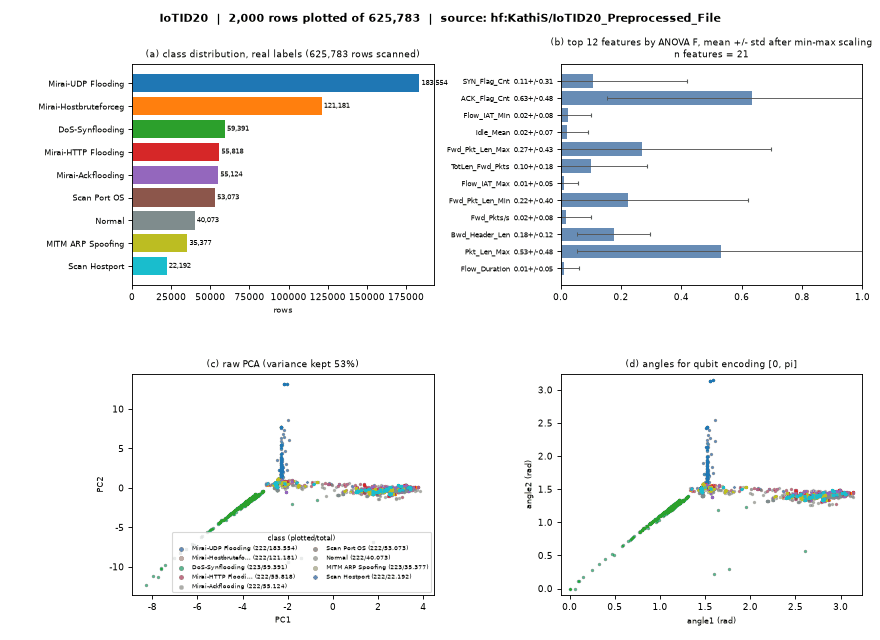

In [36]:
show_dataset("IoTID20")

#### MQTTset

**Domain:** IoT (MQTT) &nbsp;|&nbsp; **Access:** `large` (public; FULL mode only) &nbsp;|&nbsp; **Licence:** Kaggle (CC BY 4.0)

**Task and use cases:** MQTT broker traffic with flooding, malformed, slow DoS, brute force and legitimate classes.

**Reference:** Vaccari, Chiola, Aiello, Mongelli, Cambiaso, 'MQTTset, a new dataset for machine learning techniques on MQTT', Sensors 2020.

**Source:** [https://www.kaggle.com/api/v1/datasets/download/cnrieiit/mqttset](https://www.kaggle.com/api/v1/datasets/download/cnrieiit/mqttset). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-023](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QBoost_VQC_PegasosQSVC_SmartCityIDS_Caivano2023.ipynb)

**Notes:** 922 MB Kaggle archive (public, no key needed for this endpoint); FULL mode only.

In [37]:
show_dataset("MQTTset")

[SKIPPED_LARGE_FAST] MQTTset
Source file is large (size not announced by the server); FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.


#### Farm-Flow

**Domain:** Agricultural IoT &nbsp;|&nbsp; **Access:** `large` (public; FULL mode only) &nbsp;|&nbsp; **Licence:** Zenodo, CC BY 4.0

**Task and use cases:** Network flows from a smart-farming testbed with and without attacks.

**Reference:** Zenodo record 10964648 (Farm-Flow, 2024).

**Source:** [https://zenodo.org/api/records/10964648/files/farm-flow.zip/content](https://zenodo.org/api/records/10964648/files/farm-flow.zip/content). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-042](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_AgIoTIntrusion_Gul2026.ipynb)

**Notes:** 500 MB zip; FULL mode only.

In [38]:
show_dataset("Farm-Flow")

[SKIPPED_LARGE_FAST] Farm-Flow
Source file is 501 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.


#### WUSTL-EHMS-2020

**Domain:** Medical IoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** WUSTL, research use

**Task and use cases:** Enhanced healthcare monitoring system: network flow + patient biometrics, spoofing and data-injection attacks.

**Reference:** Hady, Ghubaish, Salman, Unal, Jain, 'Intrusion detection system for healthcare systems using medical and network data: a comparison study', IEEE Access 2020.

**Source:** [https://www.cse.wustl.edu/~jain/ehms/ftp/wustl-ehms-2020_with_attacks_categories.csv](https://www.cse.wustl.edu/~jain/ehms/ftp/wustl-ehms-2020_with_attacks_categories.csv). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 3.9 MB CSV; the WUSTL server's TLS chain fails verification from this machine, so the loader passes verify=False for this host only.

[LOADED] WUSTL-EHMS-2020   source: url:www.cse.wustl.edu
  rows scanned: 16,318 of 16,318 | rows kept in the pool: 5,046 | columns: 44 -> 27 features after cleaning | rows plotted: 2,000
  label column: 'Attack Category' | classes: 3
  feature names (27): ['Flgs_ M        ', 'Flgs_ e        ', 'Flgs_ eR       ', 'SrcBytes', 'DstBytes', 'SrcLoad', 'DstLoad', 'SIntPkt', 'DIntPkt', 'SrcJitter', 'DstJitter', 'sMaxPktSz', 'sMinPktSz', 'Dur', 'TotPkts', 'TotBytes', 'Load', 'Rate', 'Packet_num', 'Temp', 'SpO2', 'Pulse_Rate', 'SYS', 'DIA', 'Heart_rate', 'Resp_Rate', 'ST']
  removed columns (6): SrcAddr [identifier / raw text], DstAddr [identifier / raw text], Sport [identifier / raw text], SrcMac [identifier / raw text], DstMac [identifier / raw text], Label [alternative label column]
  label value counts (real labels, before sampling): normal=14,272, Spoofing=1,124, Data Alteration=922
  first 3 rows (identifier columns removed):
   Flgs_ M          Flgs_ e          Flgs_ eR         SrcBytes 

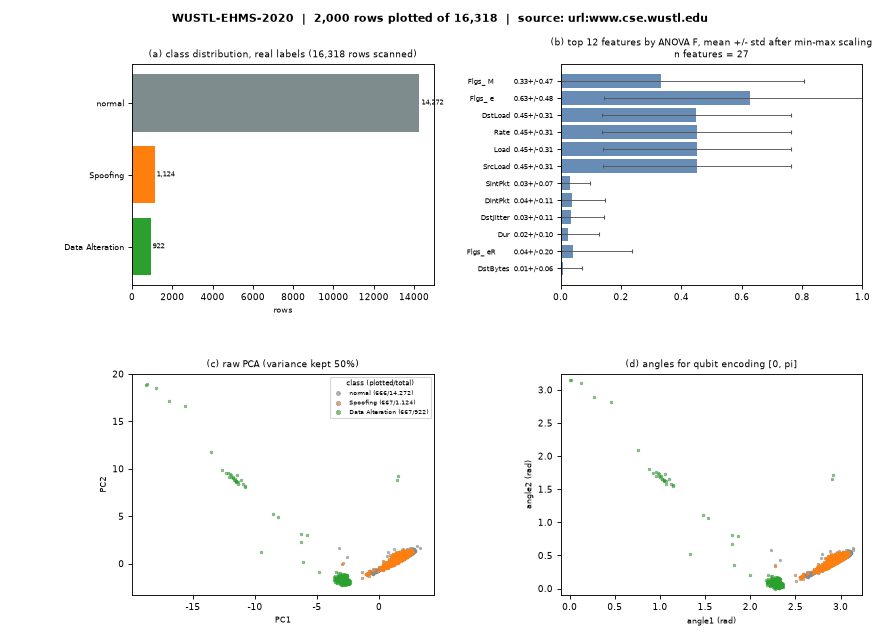

In [39]:
show_dataset("WUSTL-EHMS-2020")

#### CICIoMT2024

**Domain:** Medical IoT &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Attacks on 40 IoMT devices (DDoS, DoS, recon, MQTT, spoofing).

**Reference:** Dadkhah et al., 'CICIoMT2024: attack vectors in healthcare devices', UNB CIC 2024.

**Source:** Hugging Face mirror [somnath0100/CICIoMT2024Small](https://huggingface.co/datasets/somnath0100/CICIoMT2024Small). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Two small flow CSVs; label from the file name when the CSV carries none.

[LOADED] CICIoMT2024   source: hf:somnath0100/CICIoMT2024Small
  rows scanned: 37,197 of 37,197 | rows kept in the pool: 4,387 | columns: 83 -> 69 features after cleaning | rows plotted: 2,000
  label column: '(file name)' | classes: 2
  feature names (69): ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'P

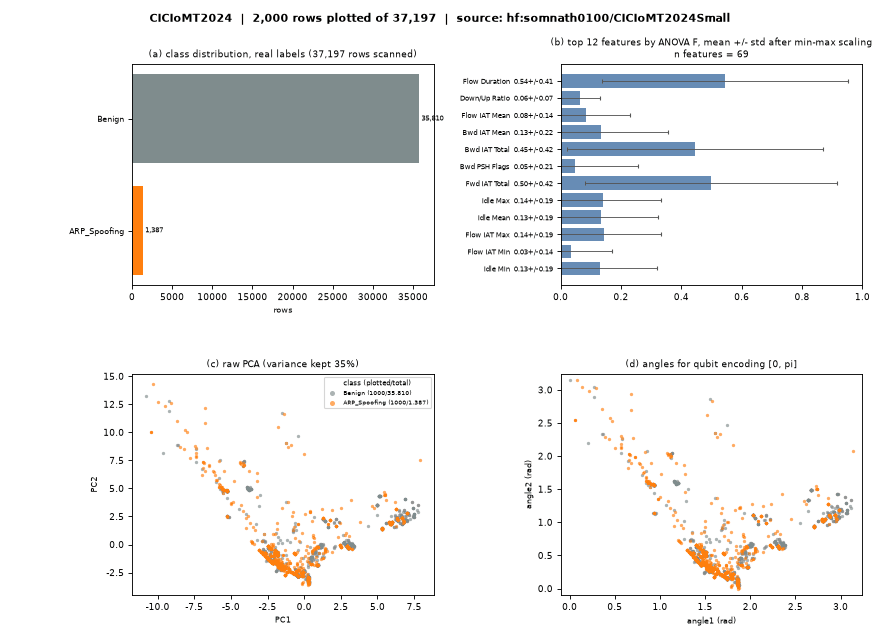

In [40]:
show_dataset("CICIoMT2024")

#### X-IIoTID

**Domain:** IIoT &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** IEEE DataPort (login)

**Task and use cases:** Connectivity- and device-agnostic IIoT intrusion dataset (multi-protocol, 18 attack types).

**Reference:** Al-Hawawreh, Sitnikova, Aboutorab, 'X-IIoTID: a connectivity-agnostic and device-agnostic intrusion data set for industrial Internet of Things', IEEE IoT Journal 2022.

**Source:** [https://ieee-dataport.org/documents/x-iiotid-connectivity-and-device-agnostic-intrusion-da...](https://ieee-dataport.org/documents/x-iiotid-connectivity-and-device-agnostic-intrusion-dataset-industrial-internet-things). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by:** not yet used by a reproduced paper.

**Notes:** IEEE DataPort login required; user must supply the CSV.

In [41]:
show_dataset("X-IIoTID")

[NEEDS_USER_FILE] X-IIoTID
Not downloadable automatically (registration / API key). Official page: https://ieee-dataport.org/documents/x-iiotid-connectivity-and-device-agnostic-intrusion-dataset-industrial-internet-things . Provide the data file(s) in atlas_user_files\x_iiotid/ (a .csv, .parquet, .zip or .xlsx with the label column ['class1', 'class2', 'class3']) and run this cell again.


#### WUSTL-IIoT-2021

**Domain:** IIoT &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** WUSTL, research use

**Task and use cases:** SCADA/IIoT testbed flows with reconnaissance, command injection, DoS and backdoor attacks.

**Reference:** Zolanvari, Teixeira, Gupta, Khan, Jain, 'Machine learning-based network vulnerability analysis of industrial Internet of Things', IEEE IoT Journal 2019.

**Source:** [https://www.cse.wustl.edu/~jain/iiot/index.html](https://www.cse.wustl.edu/~jain/iiot/index.html). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by:** not yet used by a reproduced paper.

**Notes:** The CSV links on the page returned 404 from this machine; user must supply the file.

In [42]:
show_dataset("WUSTL-IIoT-2021")

[NEEDS_USER_FILE] WUSTL-IIoT-2021
Not downloadable automatically (request form or no stable direct link). Official page: https://www.cse.wustl.edu/~jain/iiot/index.html . Provide the data file(s) in atlas_user_files\wustl_iiot_2021/ (a .csv, .parquet, .zip or .xlsx with the label column ['Target', 'Traffic']) and run this cell again.


#### CICAPT-IIoT

**Domain:** APT / IIoT &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Provenance-based APT detection in IIoT.

**Reference:** UNB CIC, CICAPT-IIoT 2024.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** UNB CIC download requires the request form; user must supply.

In [43]:
show_dataset("CICAPT-IIoT")

[NEEDS_USER_FILE] CICAPT-IIoT
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cicapt_iiot/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### DataSense IIoT

**Domain:** IIoT &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** IIoT sensor/network attack dataset.

**Reference:** UNB CIC, DataSense 2025.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** No mirror found (the Hugging Face 'datasense' repos are unrelated); user must supply.

In [44]:
show_dataset("DataSense IIoT")

[NEEDS_USER_FILE] DataSense IIoT
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\datasense_iiot/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC-BCCC-NRC Tabular IoT Attack

**Domain:** IoT &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Unified tabular IoT attack dataset merging several CIC/BCCC collections.

**Reference:** UNB CIC / BCCC, 2024.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [45]:
show_dataset("CIC-BCCC-NRC Tabular IoT Attack")

[NEEDS_USER_FILE] CIC-BCCC-NRC Tabular IoT Attack
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cic_bccc_nrc_tabular_iot_attack/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC IoT-DIAD 2024

**Domain:** IoT anomaly &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Device-identification and anomaly detection in IoT traffic.

**Reference:** UNB CIC, IoT-DIAD 2024.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `14_IoT_IIoT_Attack_Detection`, `19_Cybersecurity_Anomaly_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [46]:
show_dataset("CIC IoT-DIAD 2024")

[NEEDS_USER_FILE] CIC IoT-DIAD 2024
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cic_iot_diad_2024/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CICIoV2024

**Domain:** Vehicle / IoV &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** CAN-bus spoofing and DoS on a real 2019 vehicle (decimal / binary / hex encodings).

**Reference:** Neto et al., 'CICIoV2024: advancing realistic IDS approaches against DoS and spoofing attack in IoV CAN bus', Internet of Things 2024.

**Source:** [https://www.unb.ca/cic/datasets/iov-dataset-2024.html](https://www.unb.ca/cic/datasets/iov-dataset-2024.html). **Topic folders:** `17_Vehicle_CAN_Bus_Attacks`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [47]:
show_dataset("CICIoV2024")

[NEEDS_USER_FILE] CICIoV2024
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/iov-dataset-2024.html . Provide the data file(s) in atlas_user_files\ciciov2024/ (a .csv, .parquet, .zip or .xlsx with the label column ['label', 'category', 'specific_class']) and run this cell again.


#### CICEVSE2024

**Domain:** EV charging security &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Attacks on electric-vehicle supply equipment (network, host, power traces).

**Reference:** UNB CIC, CICEVSE 2024.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `16_ICS_SCADA_Cyber_Physical_Attacks`, `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [48]:
show_dataset("CICEVSE2024")

[NEEDS_USER_FILE] CICEVSE2024
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cicevse2024/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


### 5. Smart grid and ICS

Industrial control, water systems, power systems and energy data.

#### HAI (HIL-based Augmented ICS) 20.07

**Domain:** ICS &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY-SA 4.0

**Task and use cases:** Multivariate time series from a hardware-in-the-loop water/steam testbed with 38 injected attacks (anomaly detection).

**Reference:** Shin, Lee, Choi, Yoon, 'HAI 1.0: HIL-based augmented ICS security dataset', CSET 2020.

**Source:** [https://raw.githubusercontent.com/icsdataset/hai/master/hai-20.07/test1.csv.gz](https://raw.githubusercontent.com/icsdataset/hai/master/hai-20.07/test1.csv.gz). **Topic folders:** `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-202](https://github.com/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetectionICS_Cultice2025.ipynb); [QC-238](https://github.com/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetection_Cultice2024.ipynb)

**Notes:** test1 (with attack labels) streamed from the GitHub repository (raw.githubusercontent.com); train files are attack-free.

[LOADED] HAI (HIL-based Augmented ICS) 20.07   source: url:raw.githubusercontent.com
  rows scanned: 291,600 of 291,600 | rows kept in the pool: 6,000 | columns: 63 -> 51 features after cleaning | rows plotted: 2,000
  label column: 'attack' | classes: 2
  feature names (51): ['P1_B2004', 'P1_B2016', 'P1_B3004', 'P1_B3005', 'P1_B4002', 'P1_B4005', 'P1_B400B', 'P1_B4022', 'P1_FCV01D', 'P1_FCV01Z', 'P1_FCV02D', 'P1_FCV02Z', 'P1_FCV03D', 'P1_FCV03Z', 'P1_FT01', 'P1_FT01Z', 'P1_FT02', 'P1_FT02Z', 'P1_FT03', 'P1_FT03Z', 'P1_LCV01D', 'P1_LCV01Z', 'P1_LIT01', 'P1_PCV01D', 'P1_PCV01Z', 'P1_PCV02D', 'P1_PCV02Z', 'P1_PIT01', 'P1_PIT02', 'P1_TIT01', 'P1_TIT02', 'P2_24Vdc', 'P2_SIT01', 'P2_VT01e', 'P2_VXT02', 'P2_VXT03', 'P2_VYT02', 'P2_VYT03', 'P3_LCP01D', 'P3_LCV01D'] ...
  removed columns (4): time [identifier / raw text], attack_P1 [alternative label column], attack_P2 [alternative label column], attack_P3 [alternative label column]
  label value counts (real labels, before sampling): 0=280,06

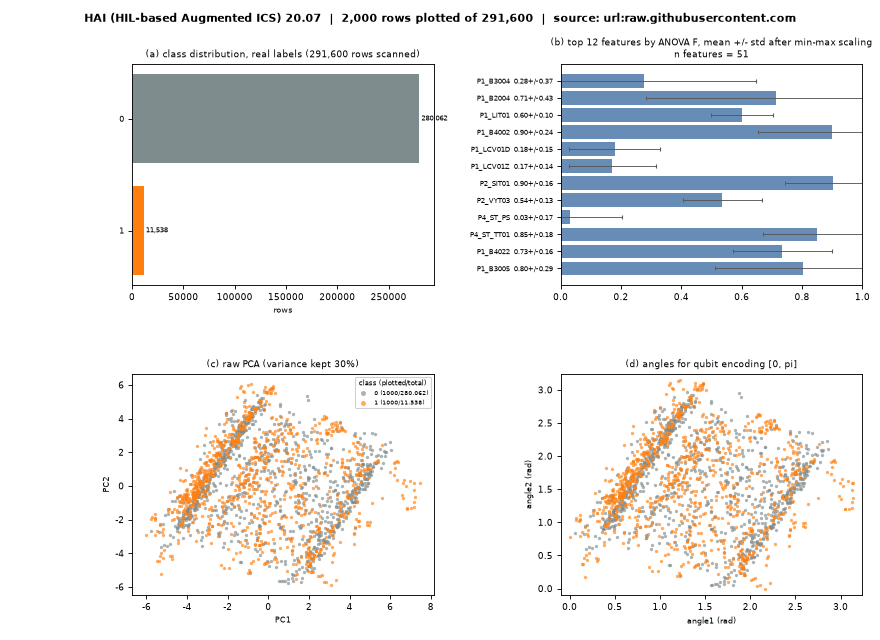

In [49]:
show_dataset("HAI (HIL-based Augmented ICS) 20.07")

#### SWaT

**Domain:** ICS &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** iTrust SUTD, registration

**Task and use cases:** Secure Water Treatment testbed: 51 sensors/actuators, 36 attacks (anomaly detection).

**Reference:** Goh, Adepu, Junejo, Mathur, 'A dataset to support research in the design of secure water treatment systems', CRITIS 2016.

**Source:** [https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-treatment-testbed/](https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-treatment-testbed/). **Topic folders:** `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-202](https://github.com/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetectionICS_Cultice2025.ipynb)

**Notes:** Registration form at iTrust; user must supply the SWaT_Dataset_Attack_v0 file.

In [50]:
show_dataset("SWaT")

[NEEDS_USER_FILE] SWaT
Not downloadable automatically (registration / API key). Official page: https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-treatment-testbed/ . Provide the data file(s) in atlas_user_files\swat/ (a .csv, .parquet, .zip or .xlsx with the label column ['Normal/Attack']) and run this cell again.


#### WADI

**Domain:** ICS &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** iTrust SUTD, registration

**Task and use cases:** Water Distribution testbed: 123 sensors, 15 attacks.

**Reference:** Ahmed, Palleti, Mathur, 'WADI: a water distribution testbed for research in the design of secure cyber physical systems', CySWATER 2017.

**Source:** [https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-distribution-testbed/](https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-distribution-testbed/). **Topic folders:** `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-202](https://github.com/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetectionICS_Cultice2025.ipynb)

**Notes:** Registration form at iTrust; user must supply.

In [51]:
show_dataset("WADI")

[NEEDS_USER_FILE] WADI
Not downloadable automatically (registration / API key). Official page: https://itrust.sutd.edu.sg/itrust-cfs/testbeds/water-distribution-testbed/ . Provide the data file(s) in atlas_user_files\wadi/ (a .csv, .parquet, .zip or .xlsx with the label column ['Attack LABLE (1:No Attack, -1:Attack)']) and run this cell again.


#### BATADAL

**Domain:** ICS / water &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** batadal.net, research use

**Task and use cases:** Battle of the Attack Detection Algorithms: C-Town SCADA readings with 14 cyber-physical attacks.

**Reference:** Taormina et al., 'Battle of the attack detection algorithms: disclosing cyber attacks on water distribution networks', J. Water Resources Planning and Management 2018.

**Source:** [https://www.batadal.net/data/BATADAL_dataset04.csv](https://www.batadal.net/data/BATADAL_dataset04.csv). **Topic folders:** `16_ICS_SCADA_Cyber_Physical_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-202](https://github.com/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetectionICS_Cultice2025.ipynb)

**Notes:** Training dataset 2 (partially labelled attacks, 0.3 MB).

[LOADED] BATADAL   source: url:www.batadal.net
  rows scanned: 4,177 of 4,177 | rows kept in the pool: 3,219 | columns: 44 -> 36 features after cleaning | rows plotted: 2,000
  label column: ' ATT_FLAG' | classes: 2
  feature names (36): [' L_T1', ' L_T2', ' L_T3', ' L_T4', ' L_T5', ' L_T6', ' L_T7', ' F_PU1', ' F_PU2', ' S_PU2', ' F_PU4', ' S_PU4', ' F_PU6', ' S_PU6', ' F_PU7', ' S_PU7', ' F_PU8', ' S_PU8', ' F_PU10', ' S_PU10', ' F_PU11', ' S_PU11', ' F_V2', ' S_V2', ' P_J280', ' P_J269', ' P_J300', ' P_J256', ' P_J289', ' P_J415', ' P_J302', ' P_J306', ' P_J307', ' P_J317', ' P_J14', ' P_J422']
  removed columns (1): DATETIME [identifier / raw text]
  label value counts (real labels, before sampling): -999=3,958, 1=219
  first 3 rows (identifier columns removed):
    L_T1   L_T2   L_T3   L_T4  ...   P_J317   P_J14   P_J422  label
0   4.32   4.78   4.68   4.23  ...    67.95   41.02    29.22   -999
1   3.95   0.71   4.66   3.24  ...    69.67   42.75    25.23   -999
2   0.87   3.82   5

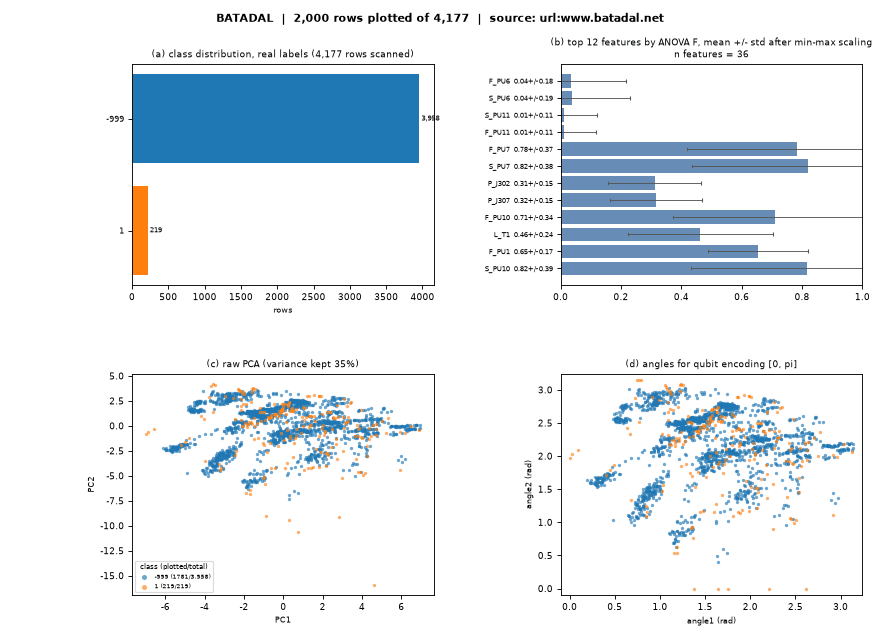

In [52]:
show_dataset("BATADAL")

#### Mississippi State / ORNL power system attacks

**Domain:** Smart grid &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** MSU/ORNL, research use

**Task and use cases:** PMU measurements (128 features) during natural faults, normal operation and 28 attack scenarios (binary / 3-class / 37-class).

**Reference:** Pan, Morris, Adhikari, 'Developing a hybrid intrusion detection system using data mining for power systems', IEEE Trans. Smart Grid 2015.

**Source:** [http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/b...](http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z). **Topic folders:** `15_Smart_Grid_Power_System_Attacks`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-054](https://github.com/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QSVM_PowerGridAttack_Islam2026.ipynb); [QC-119](https://github.com/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QUPID_SmartGridAnomaly_Ngo2026.ipynb)

**Notes:** The UAH host is offline; the Wayback Machine copy (19.7 MB 7z, py7zr) is used by the corpus notebooks.

[LOADED] Mississippi State / ORNL power system attacks   source: url:web.archive.org
  rows scanned: 78,377 of 78,377 | rows kept in the pool: 6,000 | columns: 128 -> 120 features after cleaning | rows plotted: 2,000
  label column: 'marker' | classes: 2
  feature names (120): ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I', 'R1-PA7:VH', 'R1-PM7:V', 'R1-PA8:VH', 'R1-PM8:V', 'R1-PA9:VH', 'R1-PM9:V', 'R1-PA10:IH', 'R1-PM10:I', 'R1-PA11:IH', 'R1-PM11:I', 'R1-PA12:IH', 'R1-PM12:I', 'R1:F', 'R1:DF', 'R1-PA:Z', 'R1-PA:ZH', 'R1:S', 'R2-PA1:VH', 'R2-PM1:V', 'R2-PA2:VH', 'R2-PM2:V', 'R2-PA3:VH', 'R2-PM3:V', 'R2-PA4:IH', 'R2-PM4:I', 'R2-PA5:IH', 'R2-PM5:I', 'R2-PA6:IH'] ...
  label value counts (real labels, before sampling): Attack=55,663, Natural=22,714
  first 3 rows (identifier columns removed):
   R1-PA1:VH  R1-PM1:V  R1-PA2:VH  R1-PM2:V  ...  relay2_log  relay3_log  relay4_log    label
0  

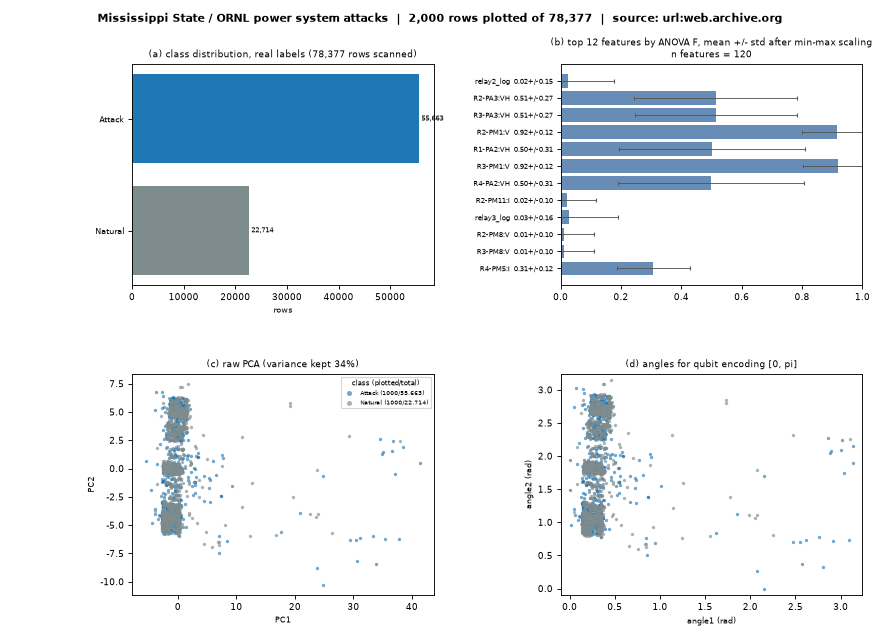

In [53]:
show_dataset("Mississippi State / ORNL power system attacks")

#### OEDI commercial load profiles (Zidi et al. 2022)

**Domain:** Smart grid / energy theft &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** Hourly electricity channels of 16 commercial building types with synthetic theft scenarios (honest vs theft).

**Reference:** Zidi et al., 'Theft detection dataset for benchmarking and machine learning', Mendeley Data c3c7329tjj, 2022.

**Source:** [https://data.mendeley.com/public-files/datasets/c3c7329tjj/files/9a709250-d1ce-4fae-9733-6...](https://data.mendeley.com/public-files/datasets/c3c7329tjj/files/9a709250-d1ce-4fae-9733-6596795bdb7e/file_downloaded). **Topic folders:** `15_Smart_Grid_Power_System_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-183](https://github.com/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/HybridQNN_PowerTheft_Blazakis2025.ipynb)

**Notes:** 64 MB CSV from Mendeley (direct link used by the QC-183 notebook).

[LOADED] OEDI commercial load profiles (Zidi et al. 2022)   source: url:data.mendeley.com
  rows scanned: 560,655 of 560,655 | rows kept in the pool: 21,000 | columns: 12 -> 11 features after cleaning | rows plotted: 2,000
  label column: 'theft' | classes: 7
  feature names (11): ['0', 'Electricity:Facility [kW](Hourly)', 'Fans:Electricity [kW](Hourly)', 'Cooling:Electricity [kW](Hourly)', 'Heating:Electricity [kW](Hourly)', 'InteriorLights:Electricity [kW](Hourly)', 'InteriorEquipment:Electricity [kW](Hourly)', 'Gas:Facility [kW](Hourly)', 'Heating:Gas [kW](Hourly)', 'InteriorEquipment:Gas [kW](Hourly)', 'Water Heater:WaterSystems:Gas [kW](Hourly)']
  removed columns (1): Class [alternative label column]
  label value counts (real labels, before sampling): Normal=331,824, Theft1=51,083, Theft3=44,349, Theft4=41,460, Theft6=35,413, Theft5=33,553, Theft2=22,973
  first 3 rows (identifier columns removed):
          0  Electricity:Facility [kW](Hourly)  Fans:Electricity [kW](Hourly)  Co

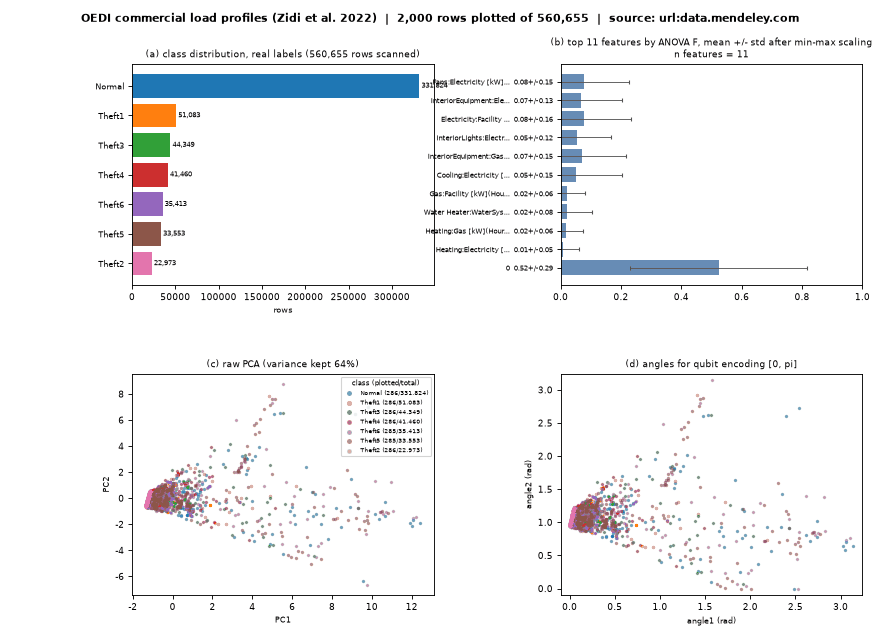

In [54]:
show_dataset("OEDI commercial load profiles (Zidi et al. 2022)")

#### Ausgrid solar home electricity

**Domain:** Smart grid / net metering &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Ausgrid open data

**Task and use cases:** 300 rooftop-solar homes, half-hourly generation and consumption 2010-2013; used with simulated false-reading attacks.

**Reference:** Ausgrid, 'Solar home electricity data' (2010-2013); Ratnam et al., 'Residential load and rooftop PV generation: an Australian distribution network dataset', IJSE 2017.

**Source:** [https://pierreh.eu/downloads/Ausgrid_solar_home_data.zip](https://pierreh.eu/downloads/Ausgrid_solar_home_data.zip). **Topic folders:** `15_Smart_Grid_Power_System_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-183](https://github.com/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/HybridQNN_PowerTheft_Blazakis2025.ipynb)

**Notes:** 57 MB zip; the atlas colours readings by consumption category (GC/GG/CL). Attack labels in the corpus notebook are simulated from the paper's recipe and are not shown here.

[LOADED] Ausgrid solar home electricity   source: url:pierreh.eu
  rows scanned: 268,557 of 268,557 | rows kept in the pool: 9,000 | columns: 53 -> 51 features after cleaning | rows plotted: 2,000
  label column: 'Consumption Category' | classes: 3
  feature names (51): ['Customer', 'Generator Capacity', 'Postcode', '0:30', '1:00', '1:30', '2:00', '2:30', '3:00', '3:30', '4:00', '4:30', '5:00', '5:30', '6:00', '6:30', '7:00', '7:30', '8:00', '8:30', '9:00', '9:30', '10:00', '10:30', '11:00', '11:30', '12:00', '12:30', '13:00', '13:30', '14:00', '14:30', '15:00', '15:30', '16:00', '16:30', '17:00', '17:30', '18:00', '18:30'] ...
  removed columns (1): date [identifier / raw text]
  label value counts (real labels, before sampling): GC=109,419, GG=109,419, CL=49,719
  first 3 rows (identifier columns removed):
   Customer  Generator Capacity  Postcode  0:30  ...  23:00  23:30  0:00  label
0       235              1           2077     0  ...      0      0     0     CL
1       261         

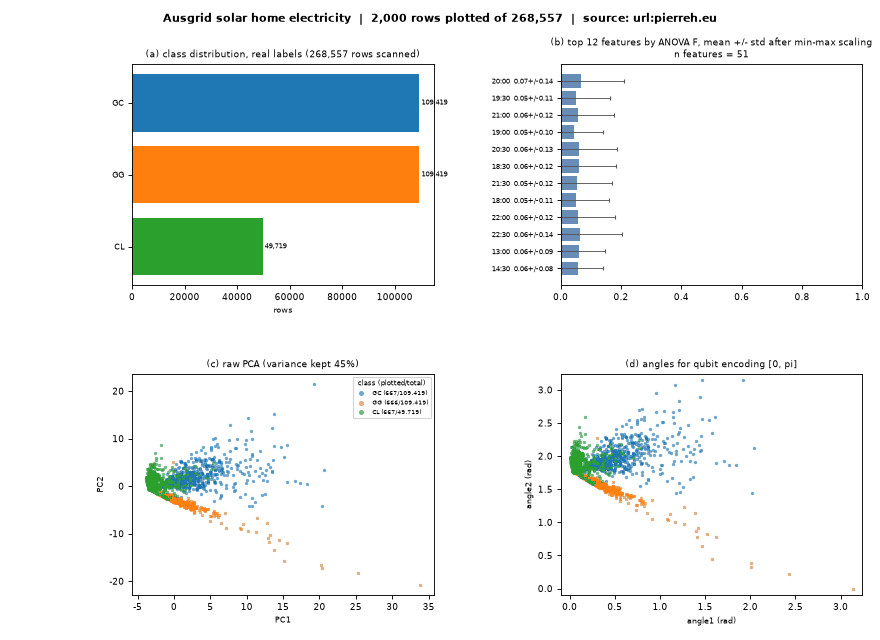

In [55]:
show_dataset("Ausgrid solar home electricity")

### 6. Malware, ransomware, cryptojacking and vulnerabilities

Static, behavioural and memory features of malware, plus exploited-vulnerability catalogues.

#### ClaMP (Integrated)

**Domain:** Malware (PE) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** GitHub (see repository)

**Task and use cases:** PE-header features of 5184 Windows binaries, malware vs benign.

**Reference:** Kumar, Kuppusamy, Aghila, 'A learning model to detect maliciousness of portable executable using integrated feature set', JKSU-CIS 2019 (ClaMP GitHub).

**Source:** [https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.c...](https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.csv). **Topic folders:** `05_Malware_Detection`, `11_Vulnerability_Software_Supply_Chain_Attacks`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-001](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/HybridQNN_QFGSM_Akter2024.ipynb); [QC-009](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/QNN_SupplyChainClaMP_Akter2022.ipynb); [QC-010](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/HybridQNN_AdversarialNoise_Akter2023.ipynb)

**Notes:** 0.3 MB CSV used by three corpus notebooks.

[LOADED] ClaMP (Integrated)   source: url:raw.githubusercontent.com
  rows scanned: 5,210 of 5,210 | rows kept in the pool: 5,210 | columns: 69 -> 59 features after cleaning | rows plotted: 2,000
  label column: 'class' | classes: 2
  feature names (59): ['e_cblp', 'e_cp', 'e_cparhdr', 'e_maxalloc', 'e_sp', 'e_lfanew', 'NumberOfSections', 'CreationYear', 'FH_char0', 'FH_char2', 'FH_char3', 'FH_char4', 'FH_char5', 'FH_char6', 'FH_char7', 'FH_char8', 'FH_char9', 'FH_char10', 'FH_char12', 'FH_char14', 'MajorLinkerVersion', 'MinorLinkerVersion', 'SizeOfCode', 'SizeOfInitializedData', 'SizeOfUninitializedData', 'AddressOfEntryPoint', 'BaseOfCode', 'BaseOfData', 'ImageBase', 'MajorOperatingSystemVersion', 'MinorOperatingSystemVersion', 'MajorImageVersion', 'MinorImageVersion', 'MajorSubsystemVersion', 'MinorSubsystemVersion', 'SizeOfImage', 'SizeOfHeaders', 'CheckSum', 'Subsystem', 'OH_DLLchar0'] ...
  removed columns (1): packer_type [text with many distinct values]
  label value counts (re

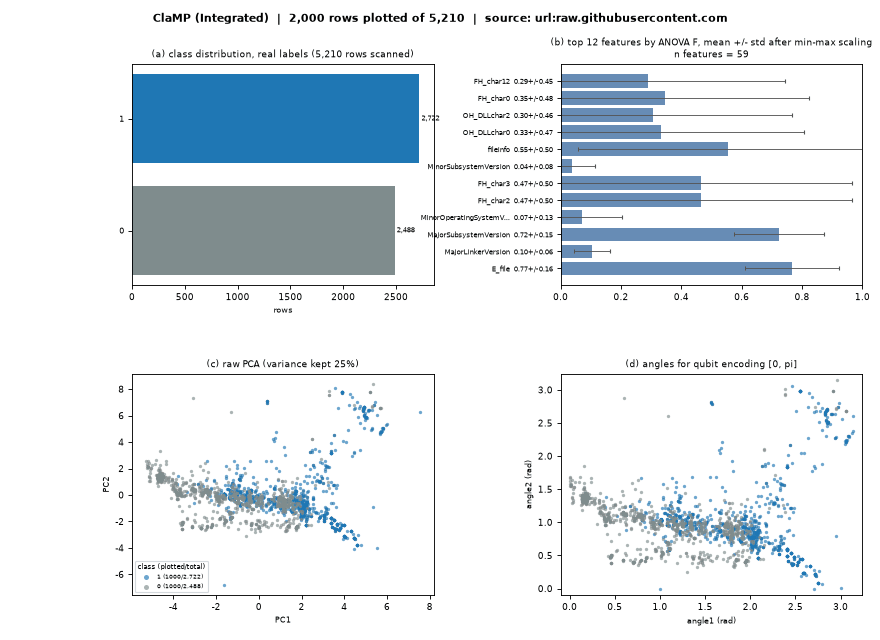

In [56]:
show_dataset("ClaMP (Integrated)")

#### EMBER 2018

**Domain:** Malware (PE) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Elastic, research use

**Task and use cases:** 2381 static features of 1M PE files (benign / malicious / unlabeled).

**Reference:** Anderson, Roth, 'EMBER: an open dataset for training static PE malware machine learning models', arXiv:1804.04637, 2018.

**Source:** Hugging Face mirror [cw1521/ember2018-malware](https://huggingface.co/datasets/cw1521/ember2018-malware). **Topic folders:** `05_Malware_Detection`, `14_IoT_IIoT_Attack_Detection`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-013](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/QCNN_MalwareMultiSection_Quertier2024.ipynb); [QC-023](https://github.com/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QBoost_VQC_PegasosQSVC_SmartCityIDS_Caivano2023.ipynb)

**Notes:** One test shard (72 MB JSONL, key x = feature list, y = label).

[LOADED] EMBER 2018   source: hf:cw1521/ember2018-malware
  rows scanned: 2,000 of 2,000 | rows kept in the pool: 2,000 | columns: 2387 -> 2294 features after cleaning | rows plotted: 2,000
  label column: 'y' | classes: 2
  feature names (2294): ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x27', 'x28', 'x29', 'x30', 'x31', 'x32', 'x33', 'x34', 'x35', 'x36', 'x37', 'x38', 'x39'] ...
  removed columns (4): sha256 [identifier / raw text], label [alternative label column], input [text with many distinct values], avclass [text with many distinct values]
  label value counts (real labels, before sampling): 0=1,002, 1=998
  first 3 rows (identifier columns removed):
       x0       x1       x2       x3  ...  x2378  x2379  x2380  label
0  0.2414 0.003262 0.005333 0.007377  ...      0      0      0      1
1 0.05683  0.00831 0.006175 0.005658  ...      0      0

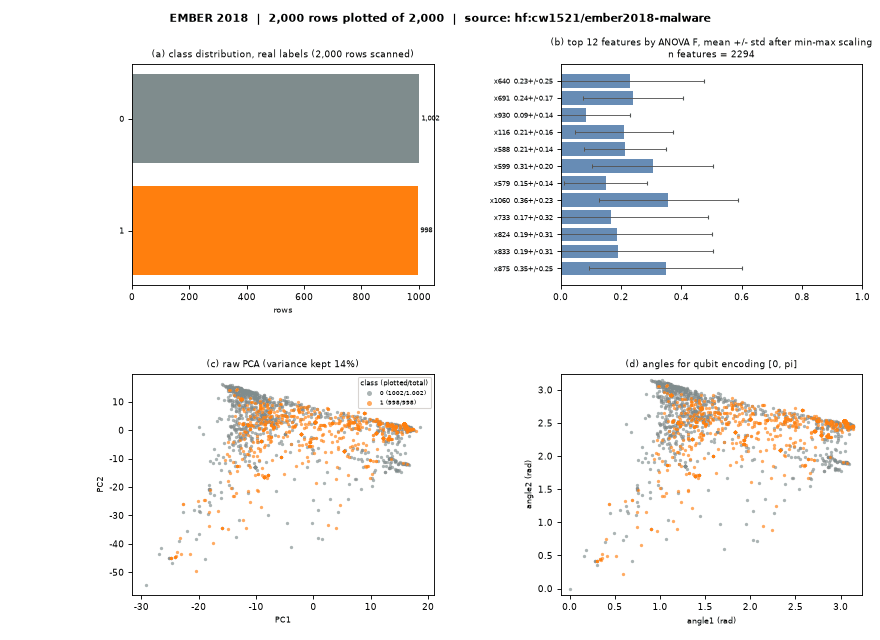

In [57]:
show_dataset("EMBER 2018")

#### BODMAS

**Domain:** Malware (PE) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Blue Hexagon, research use

**Task and use cases:** 134k PE samples with EMBER features, family labels and timestamps (concept-drift studies).

**Reference:** Yang, Ciptadi, Laziuk, Ahmadzadeh, Wang, 'BODMAS: an open dataset for learning based temporal analysis of PE malware', DLS 2021.

**Source:** Hugging Face mirror [it4lia/BODMAS_cleaned](https://huggingface.co/datasets/it4lia/BODMAS_cleaned). **Topic folders:** `05_Malware_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-013](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/QCNN_MalwareMultiSection_Quertier2024.ipynb)

**Notes:** Metadata parquet (16 MB; timestamp, hash, family). The 1.25 GB feature matrix (bodmas_clean_X.npy) is FULL-mode optional.

[LOADED] BODMAS   source: hf:it4lia/BODMAS_cleaned (range-read 48 blocks of 50 rows of 134,428)
  rows scanned: 2,400 of 134,428 | rows kept in the pool: 2,400 | columns: 2326 -> 2274 features after cleaning | rows plotted: 2,000
  label column: 'family (malware) / benign, from the metadata parquet' | classes: 582
  feature names (2274): ['pe_f0', 'pe_f1', 'pe_f2', 'pe_f3', 'pe_f4', 'pe_f5', 'pe_f6', 'pe_f7', 'pe_f8', 'pe_f9', 'pe_f10', 'pe_f11', 'pe_f12', 'pe_f13', 'pe_f14', 'pe_f15', 'pe_f16', 'pe_f17', 'pe_f18', 'pe_f19', 'pe_f20', 'pe_f21', 'pe_f22', 'pe_f23', 'pe_f24', 'pe_f25', 'pe_f26', 'pe_f27', 'pe_f28', 'pe_f29', 'pe_f30', 'pe_f31', 'pe_f32', 'pe_f33', 'pe_f34', 'pe_f35', 'pe_f36', 'pe_f37', 'pe_f38', 'pe_f39'] ...
  label value counts (real labels, before sampling): benign=77,138, sfone=4,729, wacatac=4,694, upatre=3,901, wabot=3,673, small=3,339, ganelp=2,232, dinwod=2,057, mira=1,960, berbew=1,749, sillyp2p=1,616, ceeinject=1,169, gepys=1,124, benjamin=1,071, musecador=1,0

  first 3 rows (identifier columns removed):
     pe_f0    pe_f1    pe_f2    pe_f3  ...  pe_f2323  pe_f2324  pe_f2325   label
0 0.004465 0.003943 0.003935 0.003911  ...         0         0         0  benign
1 0.006538 0.003967 0.003911 0.003926  ...         0         0         0  benign
2   0.1836 0.008196 0.004857 0.004829  ...  6.33e+05         0         0  benign


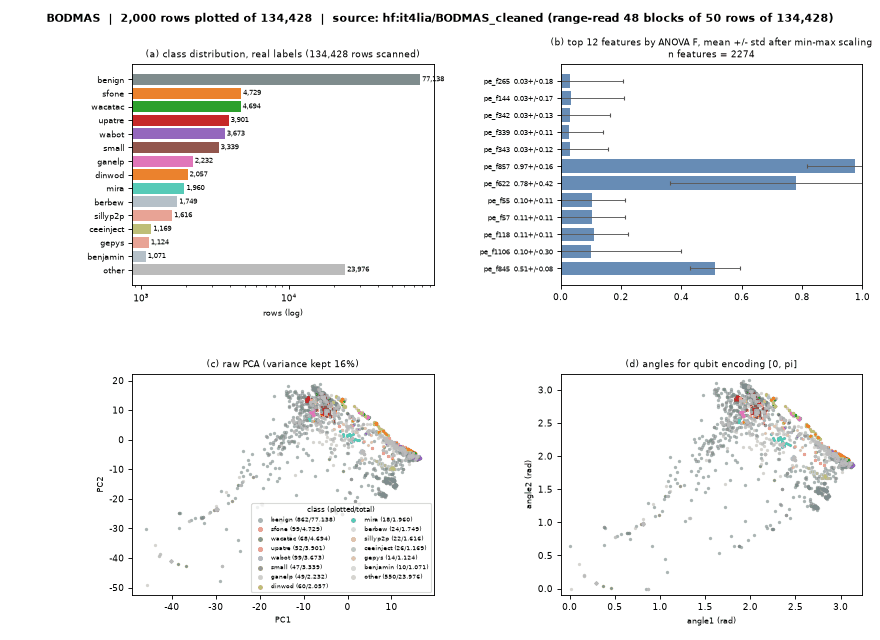

In [58]:
show_dataset("BODMAS")

#### Malimg

**Domain:** Malware (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** research use

**Task and use cases:** 9339 greyscale images of malware binaries in 25 families (no benign class).

**Reference:** Nataraj, Karthikeyan, Jacob, Manjunath, 'Malware images: visualization and automatic classification', VizSec 2011.

**Source:** Hugging Face mirror [Iss-btu-tubitak/BTU-TUBITAK-MALIMG](https://huggingface.co/datasets/Iss-btu-tubitak/BTU-TUBITAK-MALIMG). **Topic folders:** `05_Malware_Detection`, `23_Adversarial_Attacks_Against_QML`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-011](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/QCNN_MalwareImageDTL_Akash2023.ipynb); [QC-049](https://github.com/owlmt/QML/blob/main/05_Malware_Detection/HybridQNN_MalwareAdversarial_Vyas2026.ipynb); [QC-316](https://github.com/owlmt/QML/blob/main/06_Android_Malware_Detection/HybridQCNN_AndroidMalwareImages_Ciaramella2022.ipynb)

**Notes:** PNG files in one folder per family; the atlas lists the repo and downloads 40 images per family, resized to 32x32.

[LOADED] Malimg   source: hf:Iss-btu-tubitak/BTU-TUBITAK-MALIMG
  rows scanned: 1,000 of 9,347 | rows kept in the pool: 1,000 | columns: 1024 -> 1024 features after cleaning | rows plotted: 1,000
  label column: 'family folder' | classes: 25
  feature names (1024): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): Allaple.A=2,957, Allaple.L=1,591, Yuner.A=800, Instantaccess=431, VB.AT=408, Fakerean=381, Lolyda.AA1=213, C2LOP.gen!g=200, Alueron.gen!J=198, Lolyda.AA2=184, Dialplatform.B=177, Dontovo.A=162, Lolyda.AT=159, Rbot!gen=158, C2LOP.P=146 ...
  first 3 rows (identifier columns removed):
     px0    px1    px2    px3  ...  px1021  px1022  px1023  label
0    0.2 0.2039 

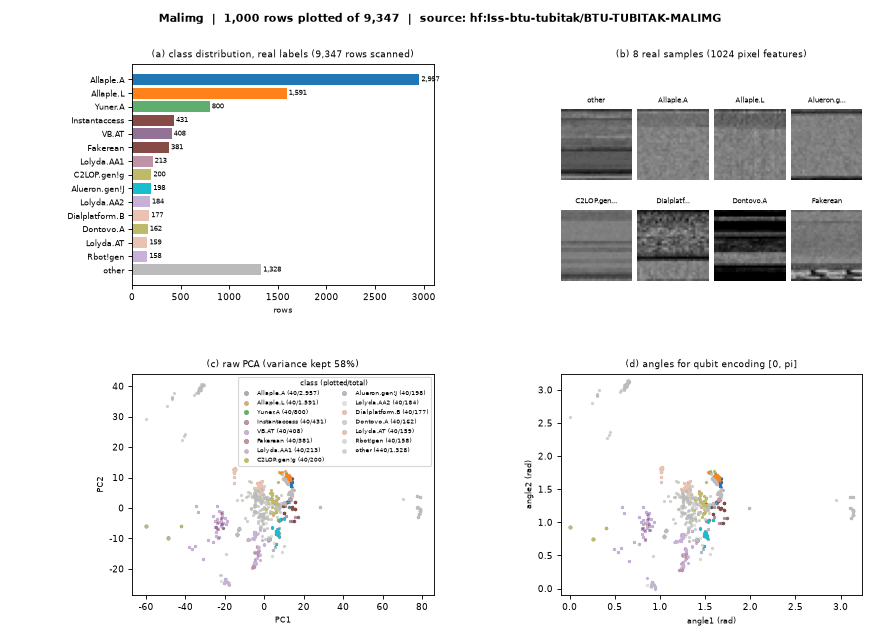

In [59]:
show_dataset("Malimg")

#### CIC-MalMem-2022

**Domain:** Malware (memory) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Memory-dump features (VolMemLyzer) for ransomware, spyware and trojan families vs benign.

**Reference:** Carrier, Victor, Tekeoglu, Habibi Lashkari, 'Detecting obfuscated malware using memory feature engineering', ICISSP 2022.

**Source:** Hugging Face mirror [bvk/CIC-MalMem-2022](https://huggingface.co/datasets/bvk/CIC-MalMem-2022). **Topic folders:** `05_Malware_Detection`, `07_Ransomware_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-036](https://github.com/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/HybridQNN_VMIThreatDetection_Tripathi2023.ipynb)

**Notes:** 20 MB CSV; the Category column carries the family (e.g. Ransomware-Conti).

[LOADED] CIC-MalMem-2022   source: hf:bvk/CIC-MalMem-2022
  rows scanned: 58,596 of 58,596 | rows kept in the pool: 32,298 | columns: 57 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'Category' | classes: 16
  feature names (50): ['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 

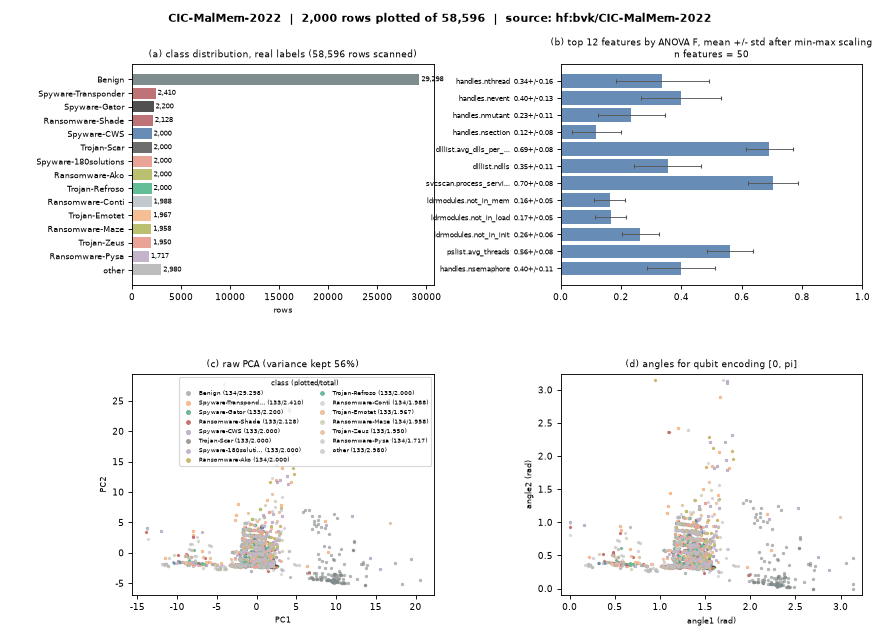

In [60]:
show_dataset("CIC-MalMem-2022")

#### MalwareData (PE features, ml-security-jp)

**Domain:** Malware / ransomware &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** 138k PE files with 54 header features, legitimate vs malware.

**Reference:** O'Reilly Japan 'ml-security-jp' companion data (Kaggle 'Malware Detection' PE header set).

**Source:** [https://raw.githubusercontent.com/oreilly-japan/ml-security-jp/master/ch03/MalwareData.csv...](https://raw.githubusercontent.com/oreilly-japan/ml-security-jp/master/ch03/MalwareData.csv.gz). **Topic folders:** `07_Ransomware_Detection`, `05_Malware_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-021](https://github.com/owlmt/QML/blob/main/07_Ransomware_Detection/QSVM_RansomwareDetection_Kaur2024.ipynb)

**Notes:** 11.8 MB gzip, pipe-separated.

[LOADED] MalwareData (PE features, ml-security-jp)   source: url:raw.githubusercontent.com
  rows scanned: 138,047 of 138,047 | rows kept in the pool: 6,000 | columns: 56 -> 53 features after cleaning | rows plotted: 2,000
  label column: 'legitimate' | classes: 2
  feature names (53): ['Machine', 'SizeOfOptionalHeader', 'Characteristics', 'MajorLinkerVersion', 'MinorLinkerVersion', 'SizeOfCode', 'SizeOfInitializedData', 'SizeOfUninitializedData', 'AddressOfEntryPoint', 'BaseOfCode', 'BaseOfData', 'ImageBase', 'SectionAlignment', 'FileAlignment', 'MajorOperatingSystemVersion', 'MinorOperatingSystemVersion', 'MajorImageVersion', 'MinorImageVersion', 'MajorSubsystemVersion', 'MinorSubsystemVersion', 'SizeOfImage', 'SizeOfHeaders', 'CheckSum', 'Subsystem', 'DllCharacteristics', 'SizeOfStackReserve', 'SizeOfStackCommit', 'SizeOfHeapReserve', 'SizeOfHeapCommit', 'NumberOfRvaAndSizes', 'SectionsNb', 'SectionsMeanEntropy', 'SectionsMinEntropy', 'SectionsMaxEntropy', 'SectionsMeanRawsize', 'Se

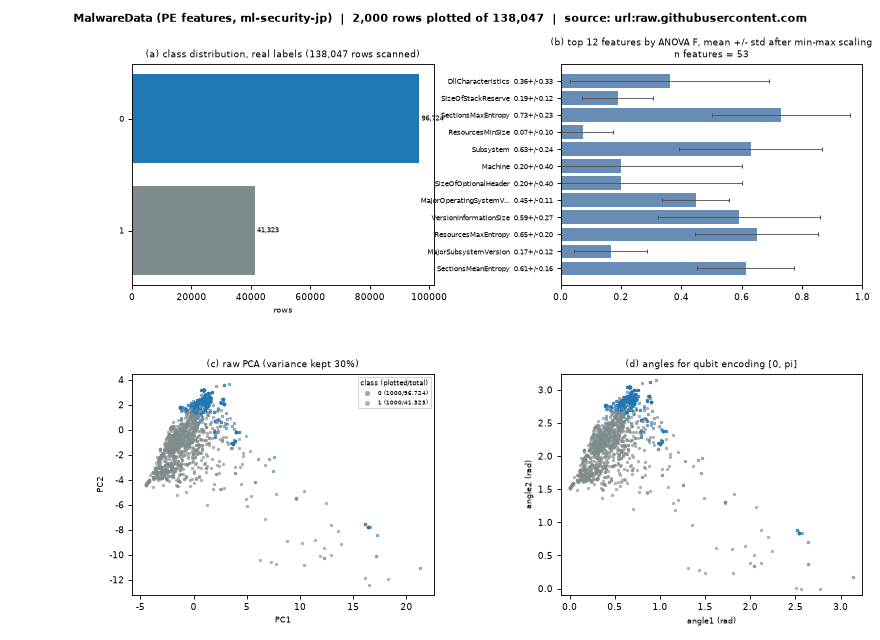

In [61]:
show_dataset("MalwareData (PE features, ml-security-jp)")

#### Ransomware features (ailabteam)

**Domain:** Ransomware &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** Static/behavioural features of ransomware vs goodware used by the qml-ransomware project.

**Reference:** ailabteam/qml-ransomware-project (GitHub).

**Source:** [https://raw.githubusercontent.com/ailabteam/qml-ransomware-project/HEAD/data/ransomware_fe...](https://raw.githubusercontent.com/ailabteam/qml-ransomware-project/HEAD/data/ransomware_features.csv). **Topic folders:** `07_Ransomware_Detection`, `02_Zero_Day_Attack_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-136](https://github.com/owlmt/QML/blob/main/02_Zero_Day_Attack_Detection/HybridVQC_UnseenRansomware_Le2025.ipynb)

**Notes:** 0.8 MB CSV.

[LOADED] Ransomware features (ailabteam)   source: url:raw.githubusercontent.com
  rows scanned: 2,675 of 2,675 | rows kept in the pool: 2,675 | columns: 1570 -> 1547 features after cleaning | rows plotted: 2,000
  label column: 'family' | classes: 41
  feature names (1547): ['e_cblp', 'e_cp', 'e_crlc', 'e_cparhdr', 'e_minalloc', 'e_maxalloc', 'e_ss', 'e_sp', 'e_csum', 'e_ip', 'e_cs', 'e_lfarlc', 'e_ovno', 'e_oemid', 'e_oeminfo', 'e_lfanew', 'Machine', 'NumberOfSections', 'PointerToSymbolTable', 'NumberOfSymbols', 'SizeOfOptionalHeader', 'Characteristics', 'Magic', 'MajorLinkerVersion', 'MinorLinkerVersion', 'SizeOfCode', 'SizeOfInitializedData', 'SizeOfUninitializedData', 'AddressOfEntryPoint', 'BaseOfCode', 'BaseOfData', 'ImageBase', 'SectionAlignment', 'FileAlignment', 'MajorOperatingSystemVersion', 'MinorOperatingSystemVersion', 'MajorImageVersion', 'MinorImageVersion', 'MajorSubsystemVersion', 'MinorSubsystemVersion'] ...
  removed columns (5): ID [identifier / raw text], filename

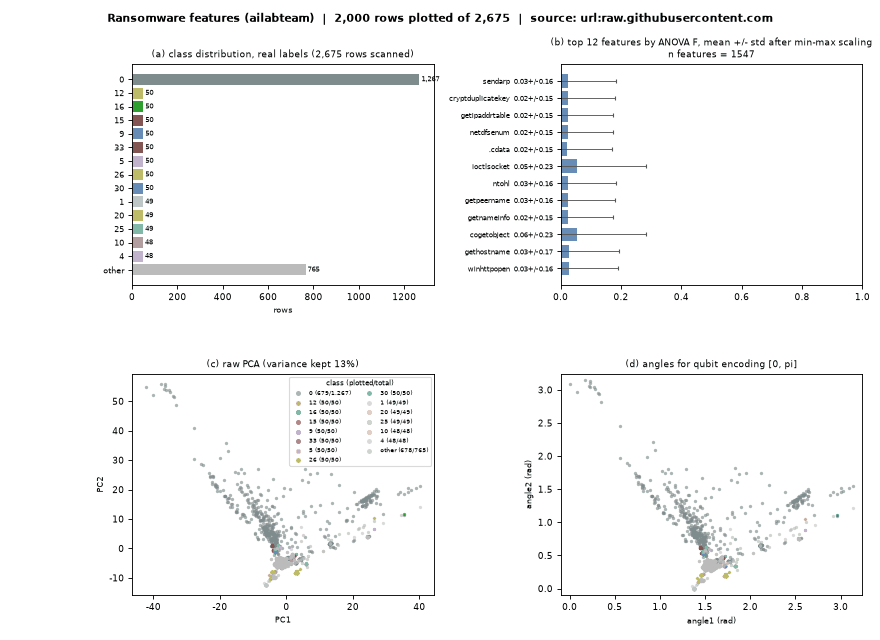

In [62]:
show_dataset("Ransomware features (ailabteam)")

#### Ransomware detection data set (Chandra)

**Domain:** Ransomware &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** File/registry/API behaviour features for ransomware detection.

**Reference:** 24vv1r1202-Chandra/ransomware-detection-data-set (GitHub).

**Source:** [https://raw.githubusercontent.com/24vv1r1202-Chandra/ransomware-detection-data-set/main/da...](https://raw.githubusercontent.com/24vv1r1202-Chandra/ransomware-detection-data-set/main/data_file.csv). **Topic folders:** `07_Ransomware_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-035](https://github.com/owlmt/QML/blob/main/07_Ransomware_Detection/QNN_Ransomware_Varalakshmi2024.ipynb)

**Notes:** 2.2 MB CSV.

[LOADED] Ransomware detection data set (Chandra)   source: url:raw.githubusercontent.com
  rows scanned: 62,485 of 62,485 | rows kept in the pool: 6,000 | columns: 17 -> 15 features after cleaning | rows plotted: 2,000
  label column: 'Benign' | classes: 2
  feature names (15): ['Machine', 'DebugSize', 'DebugRVA', 'MajorImageVersion', 'MajorOSVersion', 'ExportRVA', 'ExportSize', 'IatVRA', 'MajorLinkerVersion', 'MinorLinkerVersion', 'NumberOfSections', 'SizeOfStackReserve', 'DllCharacteristics', 'ResourceSize', 'BitcoinAddresses']
  removed columns (2): FileName [identifier / raw text], md5Hash [text with many distinct values]
  label value counts (real labels, before sampling): 0=35,367, 1=27,118
  first 3 rows (identifier columns removed):
   Machine  DebugSize  DebugRVA  MajorImageVersion  ...  DllCharacteristics  ResourceSize  BitcoinAddresses  label
0 3.44e+04         28      4752              6      ...             64                928              0         1
1      332         

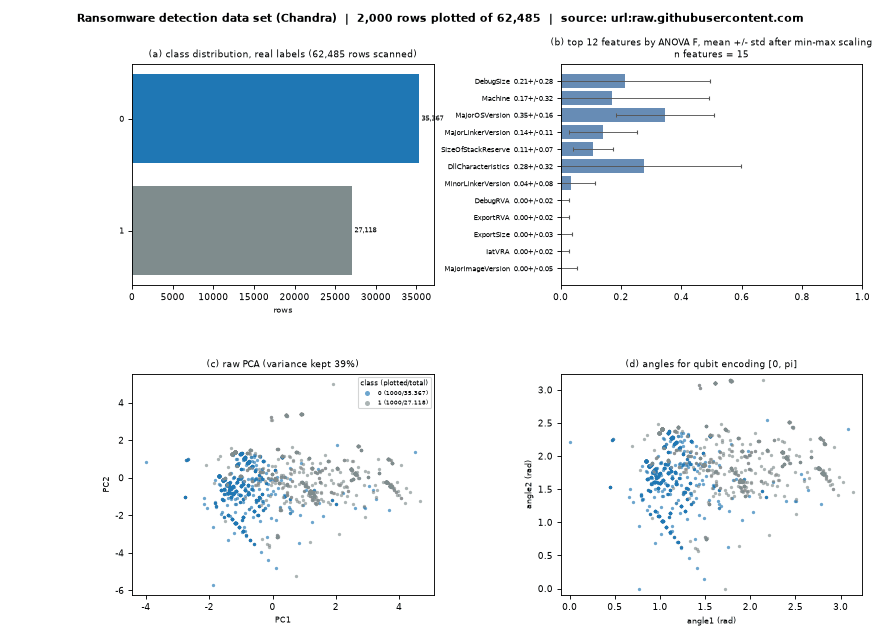

In [63]:
show_dataset("Ransomware detection data set (Chandra)")

#### DeCrypto (cryptojacking flows)

**Domain:** Cryptojacking &nbsp;|&nbsp; **Access:** `large` (public; FULL mode only) &nbsp;|&nbsp; **Licence:** Zenodo, CC BY 4.0

**Task and use cases:** ISP-level flow records of crypto-mining traffic vs normal traffic.

**Reference:** Zenodo record 7189293, DeCryptoDatasets (2022).

**Source:** [https://zenodo.org/api/records/7189293/files/DeCryptoDatasets.tar.gz/content](https://zenodo.org/api/records/7189293/files/DeCryptoDatasets.tar.gz/content). **Topic folders:** `12_Cryptojacking_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-032](https://github.com/owlmt/QML/blob/main/12_Cryptojacking_Detection/QNN_Cryptojacking_Bhattacharya2024.ipynb)

**Notes:** 350 MB tarball; FULL mode only.

In [64]:
show_dataset("DeCrypto (cryptojacking flows)")

[SKIPPED_LARGE_FAST] DeCrypto (cryptojacking flows)
Source file is 350 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.


#### CISA Known Exploited Vulnerabilities

**Domain:** Vulnerabilities &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** US Government public domain

**Task and use cases:** Catalogue of exploited CVEs (vendor, product, dates, ransomware use); used for exploit-prediction features.

**Reference:** CISA KEV catalogue, https://www.cisa.gov/known-exploited-vulnerabilities-catalog.

**Source:** [https://www.cisa.gov/sites/default/files/csv/known_exploited_vulnerabilities.csv](https://www.cisa.gov/sites/default/files/csv/known_exploited_vulnerabilities.csv). **Topic folders:** `11_Vulnerability_Software_Supply_Chain_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-008](https://github.com/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/QKMeans_CISAVulnerabilities_ElMaouaki2024.ipynb)

**Notes:** Live feed (changes daily); the atlas records the download date.

[LOADED] CISA Known Exploited Vulnerabilities   source: url:www.cisa.gov
  rows scanned: 1,754 of 1,754 | rows kept in the pool: 1,754 | columns: 11 -> 50 features after cleaning | rows plotted: 1,754
  label column: 'knownRansomwareCampaignUse' | classes: 2
  feature names (50): ['svd_0', 'svd_1', 'svd_2', 'svd_3', 'svd_4', 'svd_5', 'svd_6', 'svd_7', 'svd_8', 'svd_9', 'svd_10', 'svd_11', 'svd_12', 'svd_13', 'svd_14', 'svd_15', 'svd_16', 'svd_17', 'svd_18', 'svd_19', 'svd_20', 'svd_21', 'svd_22', 'svd_23', 'svd_24', 'svd_25', 'svd_26', 'svd_27', 'svd_28', 'svd_29', 'svd_30', 'svd_31', 'svd_32', 'svd_33', 'svd_34', 'svd_35', 'svd_36', 'svd_37', 'svd_38', 'svd_39'] ...
  removed columns (1): text [TF-IDF(1775 terms) -> SVD(50)]
  label value counts (real labels, before sampling): Unknown=1,393, Known=361
  first 3 rows (identifier columns removed):
   svd_0  svd_1    svd_2    svd_3  ...   svd_47  svd_48   svd_49    label
0 0.3464 0.2398  0.08157   0.1509  ...   0.1236 0.07445   0.0528  U

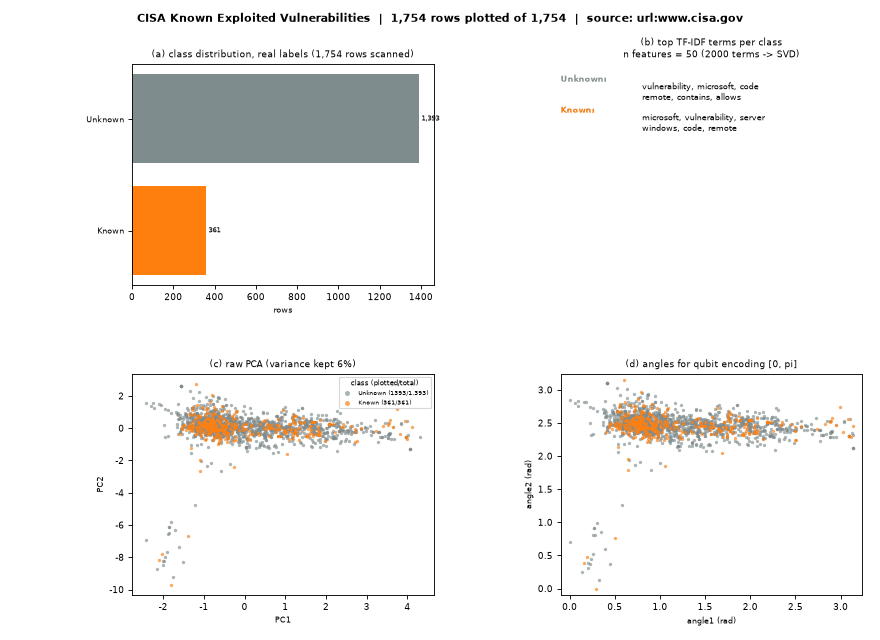

In [65]:
show_dataset("CISA Known Exploited Vulnerabilities")

#### Microsoft Malware Classification Challenge (BIG 2015)

**Domain:** Malware (families) &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** Kaggle competition rules

**Task and use cases:** Bytes and disassembly of 20k samples in 9 families.

**Reference:** Ronen et al., 'Microsoft malware classification challenge', arXiv:1802.10135, 2018.

**Source:** [https://www.kaggle.com/competitions/malware-classification](https://www.kaggle.com/competitions/malware-classification). **Topic folders:** `05_Malware_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Kaggle competition download (accept rules, API key); user must supply trainLabels.csv plus a sample of .bytes files.

In [66]:
show_dataset("Microsoft Malware Classification Challenge (BIG 2015)")

[NEEDS_USER_FILE] Microsoft Malware Classification Challenge (BIG 2015)
Not downloadable automatically (registration / API key). Official page: https://www.kaggle.com/competitions/malware-classification . Provide the data file(s) in atlas_user_files\microsoft_malware_classification_challenge/ (a .csv, .parquet, .zip or .xlsx with the label column ['Class']) and run this cell again.


#### VirusShare

**Domain:** Malware (samples) &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** VirusShare, account

**Task and use cases:** Live malware sample repository (hashes, binaries).

**Reference:** https://virusshare.com/.

**Source:** [https://virusshare.com/](https://virusshare.com/). **Topic folders:** `05_Malware_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Account by invitation; no feature CSV exists. Only a feature file supplied by the user can be shown.

In [67]:
show_dataset("VirusShare")

[NEEDS_USER_FILE] VirusShare
Not downloadable automatically (registration / API key). Official page: https://virusshare.com/ . Provide the data file(s) in atlas_user_files\virusshare/ (a .csv, .parquet, .zip or .xlsx with the label column []) and run this cell again.


### 7. Android malware

Permission, API-call and intent features of Android apps.

#### Drebin

**Domain:** Android malware &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** TU Braunschweig, registration

**Task and use cases:** Static features (permissions, API calls, intents) of 5560 malware and 123k benign apps.

**Reference:** Arp, Spreitzenbarth, Hubner, Gascon, Rieck, 'DREBIN: effective and explainable detection of Android malware in your pocket', NDSS 2014.

**Source:** [https://www.sec.cs.tu-bs.de/~danarp/drebin/](https://www.sec.cs.tu-bs.de/~danarp/drebin/). **Topic folders:** `06_Android_Malware_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Registration at TU Braunschweig; the GitHub CSV mirrors probed were gone. User must supply drebin-215 feature CSV.

In [68]:
show_dataset("Drebin")

[NEEDS_USER_FILE] Drebin
Not downloadable automatically (registration / API key). Official page: https://www.sec.cs.tu-bs.de/~danarp/drebin/ . Provide the data file(s) in atlas_user_files\drebin/ (a .csv, .parquet, .zip or .xlsx with the label column ['class']) and run this cell again.


#### Android Malware Dataset (permissions)

**Domain:** Android malware &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** 86 binary permission features per app, malware vs benign.

**Reference:** srimeenakshiks/Android-Malware-Dataset (Hugging Face mirror of a Kaggle permissions set).

**Source:** Hugging Face mirror [srimeenakshiks/Android-Malware-Dataset](https://huggingface.co/datasets/srimeenakshiks/Android-Malware-Dataset). **Topic folders:** `06_Android_Malware_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 5 MB CSV.

[LOADED] Android Malware Dataset (permissions)   source: hf:srimeenakshiks/Android-Malware-Dataset
  rows scanned: 29,332 of 29,332 | rows kept in the pool: 6,000 | columns: 86 -> 86 features after cleaning | rows plotted: 2,000
  label column: 'Result' | classes: 2
  feature names (86): ['android.permission.GET_ACCOUNTS', 'com.sonyericsson.home.permission.BROADCAST_BADGE', 'android.permission.READ_PROFILE', 'android.permission.MANAGE_ACCOUNTS', 'android.permission.WRITE_SYNC_SETTINGS', 'android.permission.READ_EXTERNAL_STORAGE', 'android.permission.RECEIVE_SMS', 'com.android.launcher.permission.READ_SETTINGS', 'android.permission.WRITE_SETTINGS', 'com.google.android.providers.gsf.permission.READ_GSERVICES', 'android.permission.DOWNLOAD_WITHOUT_NOTIFICATION', 'android.permission.GET_TASKS', 'android.permission.WRITE_EXTERNAL_STORAGE', 'android.permission.RECORD_AUDIO', 'com.huawei.android.launcher.permission.CHANGE_BADGE', 'com.oppo.launcher.permission.READ_SETTINGS', 'android.permissi

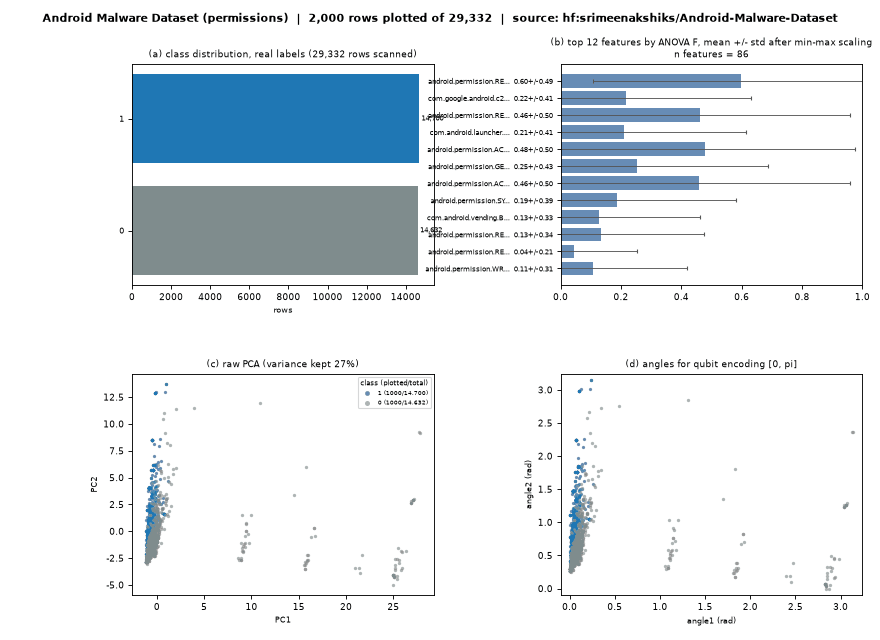

In [69]:
show_dataset("Android Malware Dataset (permissions)")

#### NATICUSdroid

**Domain:** Android malware &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 86 native and custom permissions of 29k apps (2010-2019), malware vs benign.

**Reference:** Mathur, Podila, Kulkarni, Niyaz, Sastry, 'NATICUSdroid: a malware detection framework for Android using native and custom permissions', JISA 2021.

**Source:** [https://archive.ics.uci.edu/static/public/722/naticusdroid+android+permissions+dataset.zip](https://archive.ics.uci.edu/static/public/722/naticusdroid+android+permissions+dataset.zip). **Topic folders:** `06_Android_Malware_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-025](https://github.com/owlmt/QML/blob/main/06_Android_Malware_Detection/VQC_PhishingMalwareSpam_RosaRemedios2024.ipynb)

**Notes:** UCI static zip.

[LOADED] NATICUSdroid   source: url:archive.ics.uci.edu
  rows scanned: 29,332 of 29,332 | rows kept in the pool: 6,000 | columns: 86 -> 86 features after cleaning | rows plotted: 2,000
  label column: 'Result' | classes: 2
  feature names (86): ['android.permission.GET_ACCOUNTS', 'com.sonyericsson.home.permission.BROADCAST_BADGE', 'android.permission.READ_PROFILE', 'android.permission.MANAGE_ACCOUNTS', 'android.permission.WRITE_SYNC_SETTINGS', 'android.permission.READ_EXTERNAL_STORAGE', 'android.permission.RECEIVE_SMS', 'com.android.launcher.permission.READ_SETTINGS', 'android.permission.WRITE_SETTINGS', 'com.google.android.providers.gsf.permission.READ_GSERVICES', 'android.permission.DOWNLOAD_WITHOUT_NOTIFICATION', 'android.permission.GET_TASKS', 'android.permission.WRITE_EXTERNAL_STORAGE', 'android.permission.RECORD_AUDIO', 'com.huawei.android.launcher.permission.CHANGE_BADGE', 'com.oppo.launcher.permission.READ_SETTINGS', 'android.permission.CHANGE_NETWORK_STATE', 'com.android.laun

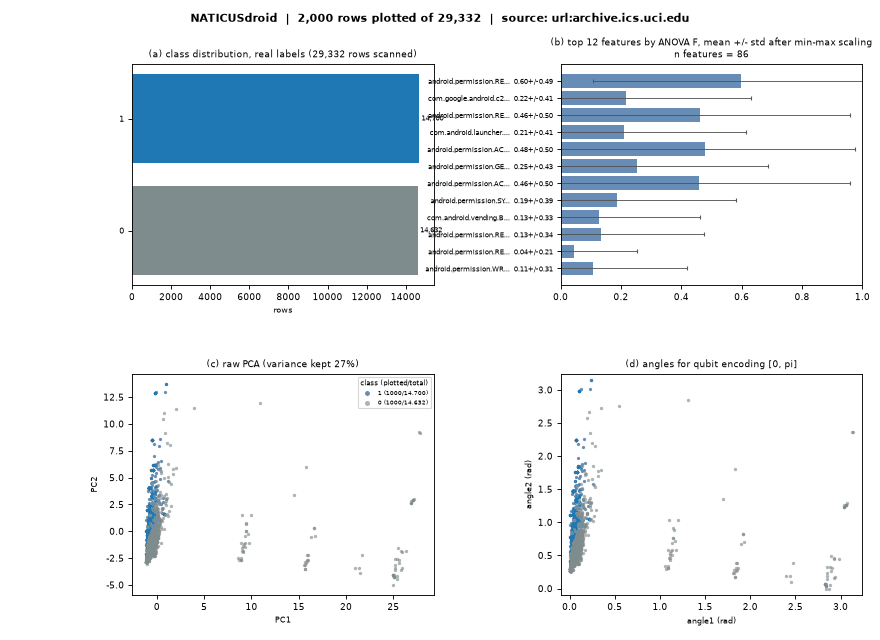

In [70]:
show_dataset("NATICUSdroid")

#### TUANDROMD

**Domain:** Android malware &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 241 permission/API features of 4465 apps (malware vs goodware).

**Reference:** Borah, Bhattacharyya, Kalita, 'Malware dataset generation and evaluation', CICT 2020.

**Source:** [https://archive.ics.uci.edu/static/public/855/tuandromd+(tezpur+university+android+malware...](https://archive.ics.uci.edu/static/public/855/tuandromd+(tezpur+university+android+malware+dataset).zip). **Topic folders:** `06_Android_Malware_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-092](https://github.com/owlmt/QML/blob/main/06_Android_Malware_Detection/QSVM_AndroidMalware_Mohandass2026.ipynb)

**Notes:** UCI static zip.

[LOADED] TUANDROMD   source: url:archive.ics.uci.edu
  rows scanned: 4,464 of 4,464 | rows kept in the pool: 3,899 | columns: 241 -> 198 features after cleaning | rows plotted: 2,000
  label column: 'Label' | classes: 2
  feature names (198): ['ACCESS_ALL_DOWNLOADS', 'ACCESS_CACHE_FILESYSTEM', 'ACCESS_CHECKIN_PROPERTIES', 'ACCESS_COARSE_LOCATION', 'ACCESS_COARSE_UPDATES', 'ACCESS_FINE_LOCATION', 'ACCESS_LOCATION_EXTRA_COMMANDS', 'ACCESS_MOCK_LOCATION', 'ACCESS_MTK_MMHW', 'ACCESS_NETWORK_STATE', 'ACCESS_SUPERUSER', 'ACCESS_SURFACE_FLINGER', 'ACCESS_WIFI_STATE', 'ACCOUNT_MANAGER', 'ADD_VOICEMAIL', 'AUTHENTICATE_ACCOUNTS', 'BATTERY_STATS', 'BIND_ACCESSIBILITY_SERVICE', 'BIND_APPWIDGET', 'BIND_CARRIER_MESSAGING_SERVICE', 'BIND_DEVICE_ADMIN', 'BIND_DREAM_SERVICE', 'BIND_INPUT_METHOD', 'BIND_NFC_SERVICE', 'BIND_goodwareTIFICATION_LISTENER_SERVICE', 'BIND_PRINT_SERVICE', 'BIND_REMOTEVIEWS', 'BIND_TEXT_SERVICE', 'BIND_TV_INPUT', 'BIND_VOICE_INTERACTION', 'BIND_VPN_SERVICE', 'BIND_WALLPAPER', '

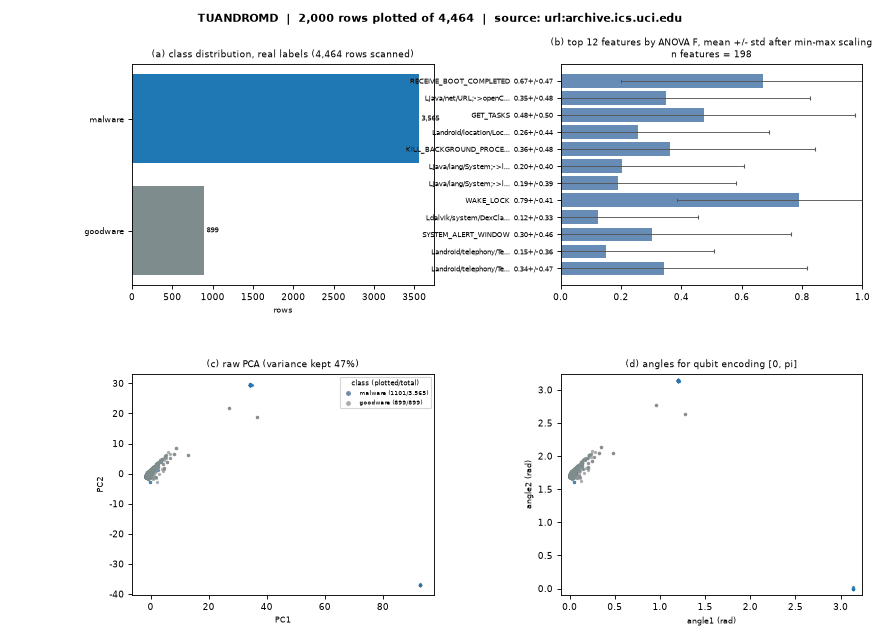

In [71]:
show_dataset("TUANDROMD")

### 8. Phishing, URLs and spam

Web pages, URLs, e-mails and messages labelled phishing, malicious or spam.

#### UCI Phishing Websites

**Domain:** Phishing &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 30 URL/HTML/domain features of 11k websites, phishing vs legitimate.

**Reference:** Mohammad, Thabtah, McCluskey, 'Phishing websites features', UCI 2015.

**Source:** [https://archive.ics.uci.edu/static/public/327/phishing+websites.zip](https://archive.ics.uci.edu/static/public/327/phishing+websites.zip). **Topic folders:** `08_Phishing_Detection`, `06_Android_Malware_Detection`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-025](https://github.com/owlmt/QML/blob/main/06_Android_Malware_Detection/VQC_PhishingMalwareSpam_RosaRemedios2024.ipynb); [QC-079](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/HybridQNN_PhishingURL_Gaurav2026.ipynb)

**Notes:** ARFF inside the zip (scipy.io.arff).

[LOADED] UCI Phishing Websites   source: url:archive.ics.uci.edu
  rows scanned: 11,055 of 11,055 | rows kept in the pool: 6,000 | columns: 30 -> 30 features after cleaning | rows plotted: 2,000
  label column: 'Result' | classes: 2
  feature names (30): ['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report']
  label value counts (real labels, before sampling): 1=6,157, -1=4,898
  first 3 rows (identifier columns removed):
   having_IP_Address  URL_Length  Shortining_Service  having_At_Symbol  ...  Google_Index  Links_pointing_to_page  Sta

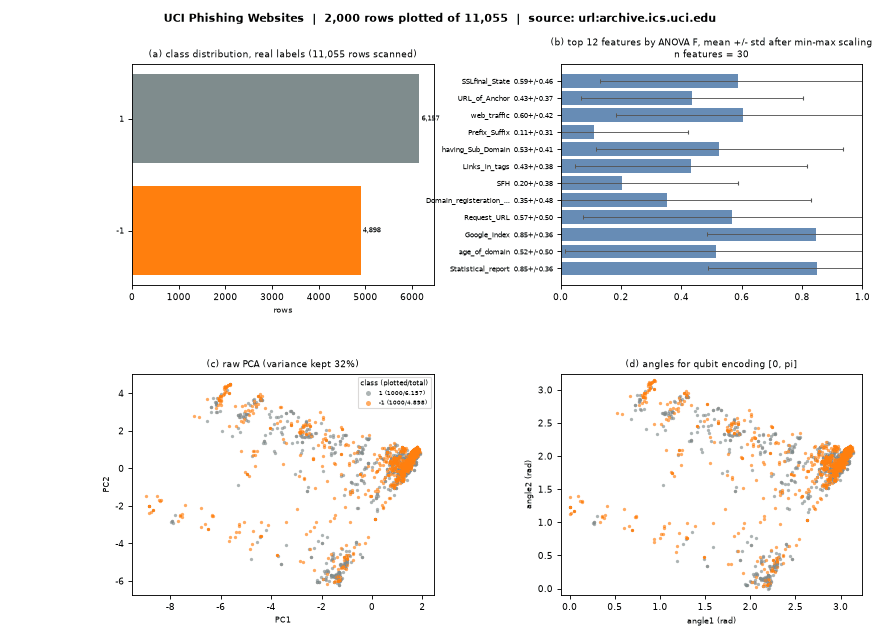

In [72]:
show_dataset("UCI Phishing Websites")

#### UCI Website Phishing

**Domain:** Phishing &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 9 features, 1353 sites, 3 classes (legitimate / suspicious / phishing).

**Reference:** Abdelhamid, Ayesh, Thabtah, 'Phishing detection based associative classification data mining', ESWA 2014.

**Source:** [https://archive.ics.uci.edu/static/public/379/website+phishing.zip](https://archive.ics.uci.edu/static/public/379/website+phishing.zip). **Topic folders:** `08_Phishing_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-025](https://github.com/owlmt/QML/blob/main/06_Android_Malware_Detection/VQC_PhishingMalwareSpam_RosaRemedios2024.ipynb)

**Notes:** ARFF inside the zip.

[LOADED] UCI Website Phishing   source: url:archive.ics.uci.edu
  rows scanned: 1,353 of 1,353 | rows kept in the pool: 1,353 | columns: 9 -> 9 features after cleaning | rows plotted: 1,353
  label column: 'Result' | classes: 3
  feature names (9): ['SFH', 'popUpWidnow', 'SSLfinal_State', 'Request_URL', 'URL_of_Anchor', 'web_traffic', 'URL_Length', 'age_of_domain', 'having_IP_Address']
  label value counts (real labels, before sampling): -1=702, 1=548, 0=103
  first 3 rows (identifier columns removed):
   SFH  popUpWidnow  SSLfinal_State  Request_URL  ...  URL_Length  age_of_domain  having_IP_Address  label
0   -1           -1              1            -1  ...          -1              1              0          0
1    1            0              1            -1  ...           1              1              0          0
2    1            1              1            -1  ...           1              1              0          0


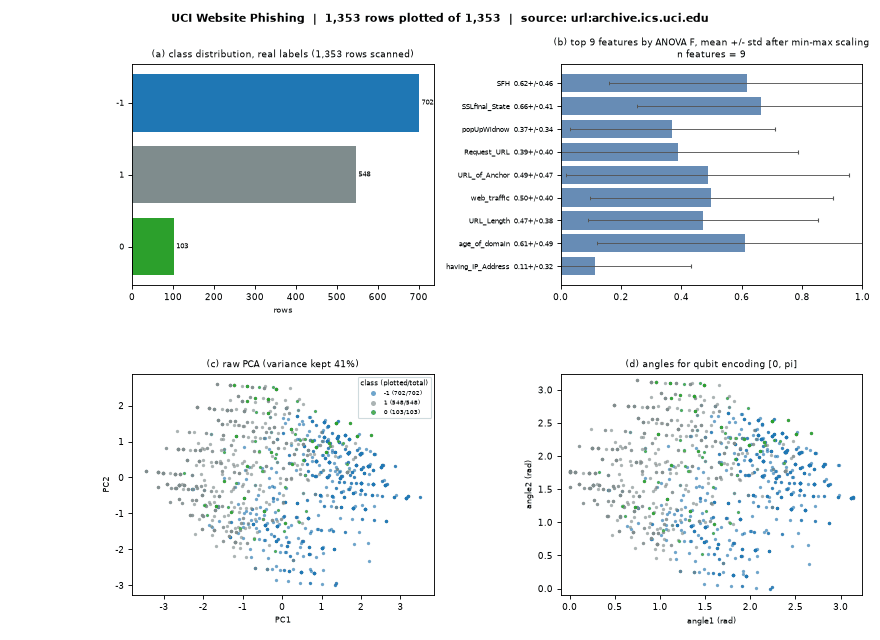

In [73]:
show_dataset("UCI Website Phishing")

#### PhiUSIIL Phishing URL

**Domain:** Phishing &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 54 URL and page features of 235k URLs (134k legitimate, 100k phishing).

**Reference:** Prasad, Chandra, 'PhiUSIIL: a diverse security profile empowered phishing URL detection framework based on similarity index and incremental learning', Computers & Security 2024.

**Source:** [https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip](https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip). **Topic folders:** `08_Phishing_Detection`, `09_Malicious_URL_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-182](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/VQC_PhishingURL_Shahriyar2025.ipynb)

**Notes:** UCI static zip (label 1 = legitimate, 0 = phishing).

[LOADED] PhiUSIIL Phishing URL   source: url:archive.ics.uci.edu
  rows scanned: 235,795 of 235,795 | rows kept in the pool: 6,000 | columns: 55 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 2
  feature names (50): ['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField'] ...
  re

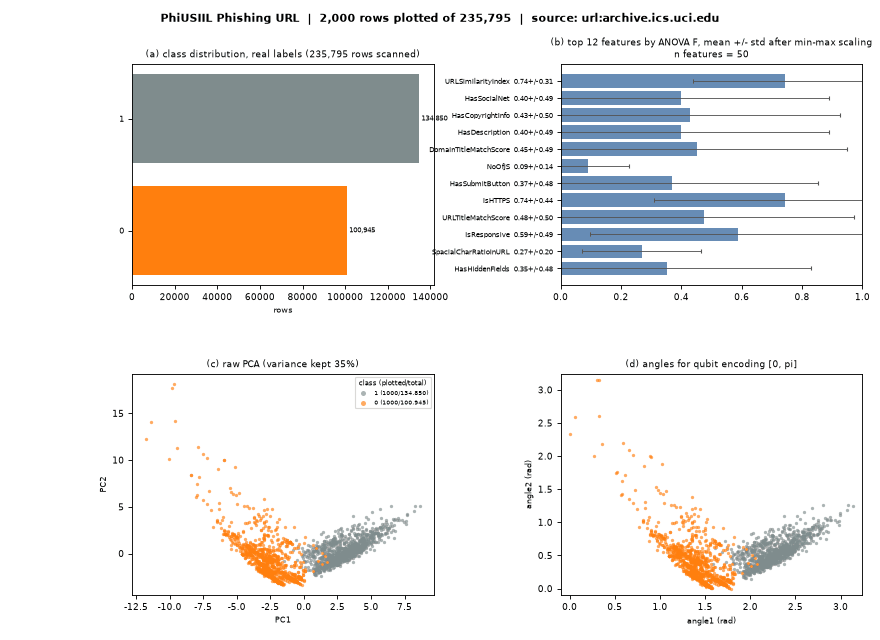

In [74]:
show_dataset("PhiUSIIL Phishing URL")

#### Web page phishing (Hannousse & Yahiouche)

**Domain:** Phishing &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0 (Mendeley original)

**Task and use cases:** 87 URL, content and external features of 11.4k web pages.

**Reference:** Hannousse, Yahiouche, 'Towards benchmark datasets for machine learning based website phishing detection', Eng. Appl. AI 2021.

**Source:** [https://huggingface.co/datasets/yonatane22-bh/Web_page_Phishing/resolve/main/dataset_phish...](https://huggingface.co/datasets/yonatane22-bh/Web_page_Phishing/resolve/main/dataset_phishing.csv). **Topic folders:** `08_Phishing_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-053](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/QSVM_EmailPhishing_Hridi2026.ipynb)

**Notes:** Hugging Face mirror used by QC-053.

[LOADED] Web page phishing (Hannousse & Yahiouche)   source: url:huggingface.co
  rows scanned: 11,430 of 11,430 | rows kept in the pool: 6,000 | columns: 88 -> 79 features after cleaning | rows plotted: 2,000
  label column: 'status' | classes: 2
  feature names (79): ['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host'] ...
  removed columns (1): url [identifier / raw text]
  label value counts (real labels, before sampling): legitimate=5,715, phi

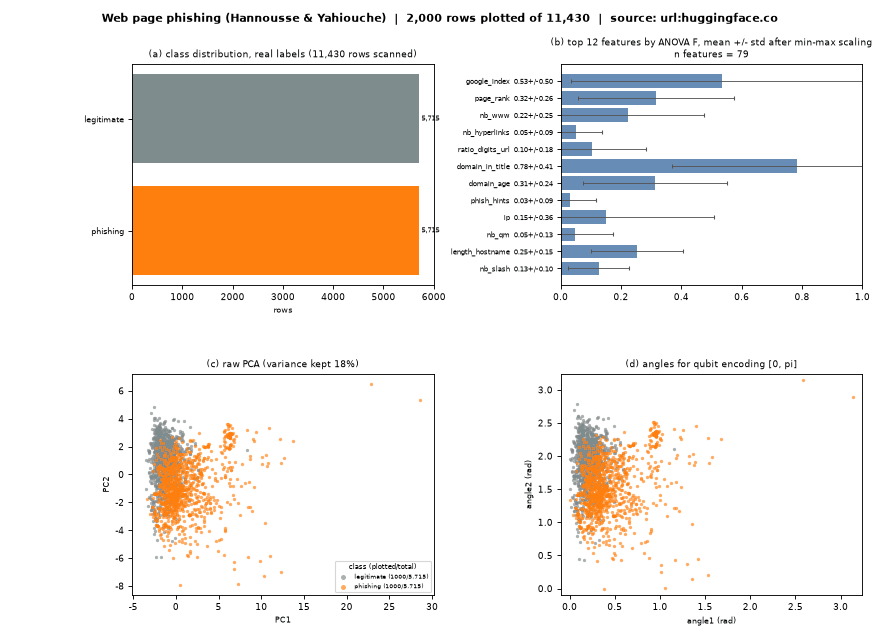

In [75]:
show_dataset("Web page phishing (Hannousse & Yahiouche)")

#### PhishDataset (ESDAUNG, balanced 20k)

**Domain:** Phishing / URLs &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** Lexical URL features, phishing vs legitimate (balanced 20k).

**Reference:** ESDAUNG/PhishDataset (GitHub), used by Reyes-Dorta et al. 2024.

**Source:** [https://raw.githubusercontent.com/ESDAUNG/PhishDataset/main/data_bal%20-%2020000.xlsx](https://raw.githubusercontent.com/ESDAUNG/PhishDataset/main/data_bal%20-%2020000.xlsx). **Topic folders:** `09_Malicious_URL_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-026](https://github.com/owlmt/QML/blob/main/09_Malicious_URL_Detection/VQC_MaliciousURL_ReyesDorta2024.ipynb)

**Notes:** 0.9 MB xlsx (openpyxl).

[LOADED] PhishDataset (ESDAUNG, balanced 20k)   source: url:raw.githubusercontent.com
  rows scanned: 20,000 of 20,000 | rows kept in the pool: 6,000 | columns: 1 -> 41 features after cleaning | rows plotted: 2,000
  label column: 'Labels' | classes: 2
  feature names (41): ['length', 'entropy', 'digit_ratio', 'vowel_ratio', 'hyphens', 'dots', 'unique_chars', 'slashes', 'special_chars', 'is_https', 'has_ip', 'bigram_ht', 'bigram_ww', 'bigram_tt', 'bigram_tp', 'bigram_:/', 'bigram_//', 'bigram_co', 'bigram_ps', 'bigram_.c', 'bigram_s:', 'bigram_om', 'bigram_/w', 'bigram_in', 'bigram_w.', 'bigram_m/', 'bigram_on', 'bigram_er', 'bigram_en', 'bigram_es', 'bigram_re', 'bigram_nt', 'bigram_or', 'bigram_te', 'bigram_ne', 'bigram_de', 'bigram_se', 'bigram_s/', 'bigram_an', 'bigram_st'] ...
  removed columns (1): URLs [converted to string features]
  label value counts (real labels, before sampling): 1=10,000, 0=10,000
  first 3 rows (identifier columns removed):
   length  entropy  digit_ratio

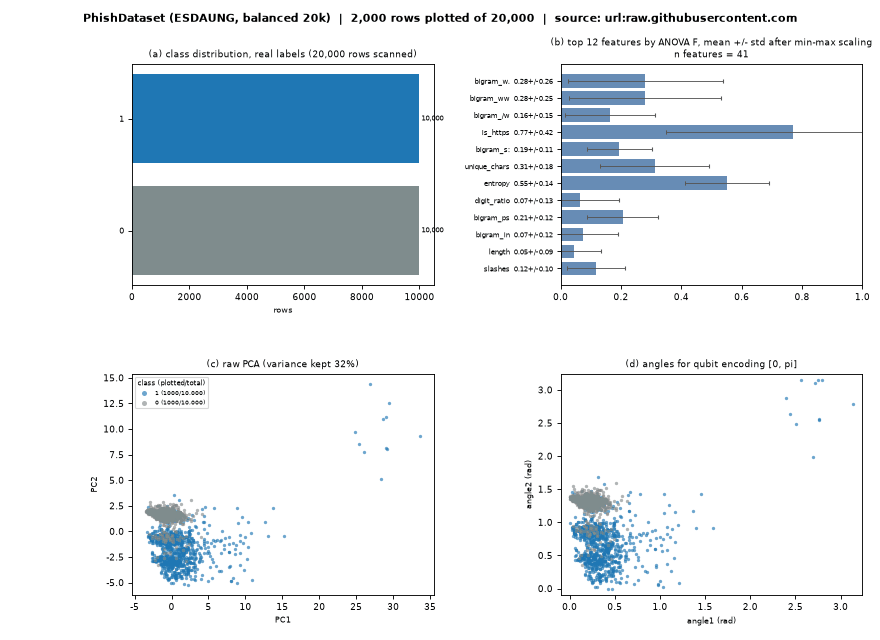

In [76]:
show_dataset("PhishDataset (ESDAUNG, balanced 20k)")

#### PhishStorm URL set (Aalto)

**Domain:** Phishing / URLs &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Aalto, research use

**Task and use cases:** 96k URLs with 12 PhishStorm features, phishing vs legitimate.

**Reference:** Marchal, Francois, State, Engel, 'PhishStorm: detecting phishing with streaming analytics', IEEE TNSM 2014.

**Source:** [https://raw.githubusercontent.com/Vishalya-s/Phishing-Website-Detector/main/ml/urlset.csv](https://raw.githubusercontent.com/Vishalya-s/Phishing-Website-Detector/main/ml/urlset.csv). **Topic folders:** `08_Phishing_Detection`, `09_Malicious_URL_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-007](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/QNN_PhishingURL_Bangroo2023.ipynb)

**Notes:** The research.aalto.fi zip returns 403 from this machine; the GitHub copy used by QC-007 is loaded.

[LOADED] PhishStorm URL set (Aalto)   source: url:raw.githubusercontent.com
  rows scanned: 95,913 of 95,913 | rows kept in the pool: 6,000 | columns: 13 -> 12 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 2
  feature names (12): ['ranking', 'mld_res', 'mld.ps_res', 'card_rem', 'ratio_Rrem', 'ratio_Arem', 'jaccard_RR', 'jaccard_RA', 'jaccard_AR', 'jaccard_AA', 'jaccard_ARrd', 'jaccard_ARrem']
  removed columns (1): domain [identifier / raw text]
  label value counts (real labels, before sampling): 0=48,009, 1=47,904
  first 3 rows (identifier columns removed):
   ranking  mld_res  mld.ps_res  card_rem  ...  jaccard_AA  jaccard_ARrd  jaccard_ARrem  label
0    1e+07        0           0         3  ...           0             0         0.6855      1
1    1e+07        1           0         9  ...    0.000776        0.7692         0.8183      1
2    1e+07        0           0         2  ...           0             0              0      1


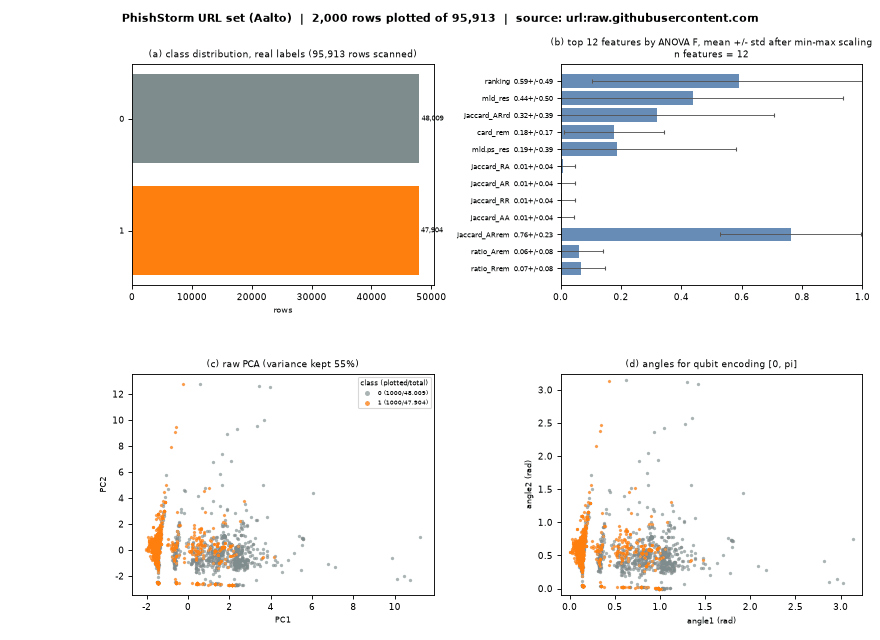

In [77]:
show_dataset("PhishStorm URL set (Aalto)")

#### CEAS_08 phishing e-mails

**Domain:** Phishing (e-mail) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Zenodo, CC BY 4.0

**Task and use cases:** 39k e-mails (sender, subject, body, URLs flag) labelled phishing / safe.

**Reference:** Champa, Rabbi, Zibran, 'Curated datasets and feature analysis for phishing email detection with machine learning', ICMI 2024 (Zenodo 8339691).

**Source:** [https://zenodo.org/api/records/8339691/files/CEAS_08.csv/content](https://zenodo.org/api/records/8339691/files/CEAS_08.csv/content). **Topic folders:** `08_Phishing_Detection`, `10_Spam_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-053](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/QSVM_EmailPhishing_Hridi2026.ipynb)

**Notes:** Text dataset: the atlas builds TF-IDF features (2000 terms) and projects them with truncated SVD before PCA.

[LOADED] CEAS_08 phishing e-mails   source: url:zenodo.org
  rows scanned: 39,154 of 39,154 | rows kept in the pool: 6,000 | columns: 6 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 2
  feature names (50): ['svd_0', 'svd_1', 'svd_2', 'svd_3', 'svd_4', 'svd_5', 'svd_6', 'svd_7', 'svd_8', 'svd_9', 'svd_10', 'svd_11', 'svd_12', 'svd_13', 'svd_14', 'svd_15', 'svd_16', 'svd_17', 'svd_18', 'svd_19', 'svd_20', 'svd_21', 'svd_22', 'svd_23', 'svd_24', 'svd_25', 'svd_26', 'svd_27', 'svd_28', 'svd_29', 'svd_30', 'svd_31', 'svd_32', 'svd_33', 'svd_34', 'svd_35', 'svd_36', 'svd_37', 'svd_38', 'svd_39'] ...
  removed columns (1): text [TF-IDF(2000 terms) -> SVD(50)]
  label value counts (real labels, before sampling): 1=21,842, 0=17,312
  first 3 rows (identifier columns removed):
    svd_0   svd_1     svd_2    svd_3  ...    svd_47   svd_48    svd_49  label
0 0.09497 0.07543 -0.002177 -0.03324  ...   0.03729 -0.04151  -0.03878      1
1 0.09974   0.438    0.62

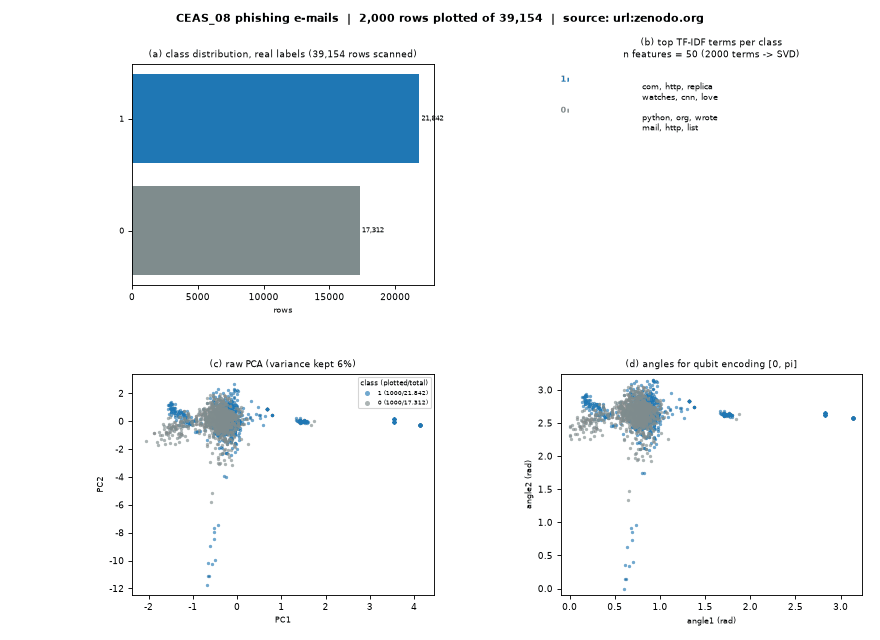

In [78]:
show_dataset("CEAS_08 phishing e-mails")

#### Ethereum phishing transaction network

**Domain:** Phishing (blockchain) &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** XBlock, research use

**Task and use cases:** Transaction-graph node features of phishing vs normal Ethereum accounts.

**Reference:** Chen et al., 'Phishing scams detection in Ethereum transaction network', ACM TOIT 2021 (XBlock); data as packaged in the QC-066 authors' repository.

**Source:** [https://xblock.pro/#/dataset/6](https://xblock.pro/#/dataset/6). **Topic folders:** `08_Phishing_Detection`, `20_Blockchain_Attack_Detection`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-066](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/QRAC_EthereumPhishing_Guddanti2026.ipynb); [QC-182](https://github.com/owlmt/QML/blob/main/08_Phishing_Detection/VQC_PhishingURL_Shahriyar2025.ipynb); [QC-259](https://github.com/owlmt/QML/blob/main/20_Blockchain_Attack_Detection/QRBM_EthereumAttack_Rajawat2024.ipynb)

**Notes:** The corpus notebook pulls the authors' code and data files at a pinned commit; no stand-alone feature CSV with a stable URL was found. User can supply the node-feature CSV.

In [79]:
show_dataset("Ethereum phishing transaction network")

[NEEDS_USER_FILE] Ethereum phishing transaction network
Not downloadable automatically (request form or no stable direct link). Official page: https://xblock.pro/#/dataset/6 . Provide the data file(s) in atlas_user_files\ethereum_phishing_transaction_network/ (a .csv, .parquet, .zip or .xlsx with the label column ['label', 'flag']) and run this cell again.


#### ISCX-URL2016

**Domain:** Malicious URLs &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** 79 lexical features of URLs in 5 classes (benign, spam, phishing, malware, defacement).

**Reference:** Mamun, Rathore, Habibi Lashkari, Stakhanova, Ghorbani, 'Detecting malicious URLs using lexical analysis', NSS 2016.

**Source:** Hugging Face mirror [bencorn/ISCX-URL-2016](https://huggingface.co/datasets/bencorn/ISCX-URL-2016). **Topic folders:** `09_Malicious_URL_Detection`, `13_Encrypted_Malicious_Traffic_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-070](https://github.com/owlmt/QML/blob/main/13_Encrypted_Malicious_Traffic_Detection/HybridQML_EncryptedTraffic_Sodar2026.ipynb)

**Notes:** 11.7 MB consolidated CSV.

[LOADED] ISCX-URL2016   source: hf:bencorn/ISCX-URL-2016
  rows scanned: 36,707 of 36,707 | rows kept in the pool: 15,000 | columns: 79 -> 77 features after cleaning | rows plotted: 2,000
  label column: 'URL_Type_obf_Type' | classes: 5
  feature names (77): ['Querylength', 'domain_token_count', 'path_token_count', 'avgdomaintokenlen', 'longdomaintokenlen', 'avgpathtokenlen', 'tld', 'charcompvowels', 'charcompace', 'ldl_url', 'ldl_domain', 'ldl_path', 'ldl_filename', 'ldl_getArg', 'dld_url', 'dld_domain', 'dld_path', 'dld_filename', 'dld_getArg', 'urlLen', 'domainlength', 'pathLength', 'subDirLen', 'fileNameLen', 'this.fileExtLen', 'ArgLen', 'pathurlRatio', 'ArgUrlRatio', 'argDomanRatio', 'domainUrlRatio', 'pathDomainRatio', 'argPathRatio', 'executable', 'NumberofDotsinURL', 'CharacterContinuityRate', 'LongestVariableValue', 'URL_DigitCount', 'host_DigitCount', 'Directory_DigitCount', 'File_name_DigitCount'] ...
  label value counts (real labels, before sampling): Defacement=7,930, ben

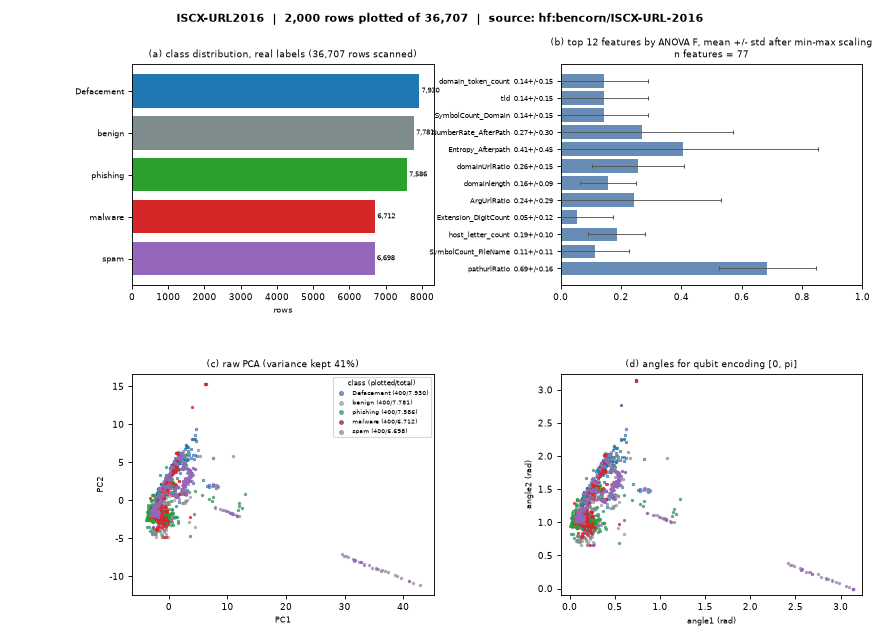

In [80]:
show_dataset("ISCX-URL2016")

#### Malicious and Benign Webpages (Singh 2020)

**Domain:** Malicious URLs &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** 1.2M web pages with URL, geo, JS and content features, good vs bad.

**Reference:** A. K. Singh, 'Malicious and benign webpages dataset', Data in Brief 32, 2020 (Mendeley gdx3pkwp47).

**Source:** [https://data.mendeley.com/public-files/datasets/gdx3pkwp47/files/](https://data.mendeley.com/public-files/datasets/gdx3pkwp47/files/). **Topic folders:** `09_Malicious_URL_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-199](https://github.com/owlmt/QML/blob/main/09_Malicious_URL_Detection/QSVM_MaliciousURL_Eze2025.ipynb)

**Notes:** Mendeley direct file link; the file id is resolved from the public API at run time as in the QC-199 notebook (first 100k rows streamed).

[LOADED] Malicious and Benign Webpages (Singh 2020)   source: url:prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (first 100000 rows)
  rows scanned: 100,000 | rows kept in the pool: 5,251 | columns: 7 -> 7 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 2
  feature names (7): ['url_len', 'who_is_complete', 'who_is_incomplete', 'https_no', 'https_yes', 'js_len', 'js_obf_len']
  removed columns (2): geo_loc [text with many distinct values], tld [text with many distinct values]
  label value counts (real labels, before sampling): good=97,749, bad=2,251
  first 3 rows (identifier columns removed):
   url_len  who_is_complete  who_is_incomplete  https_no  https_yes  js_len  js_obf_len label
0       26              1                0             0          1    45.5           0  good
1       42              1                0             0          1      63           0  good
2       20              0                1             1       

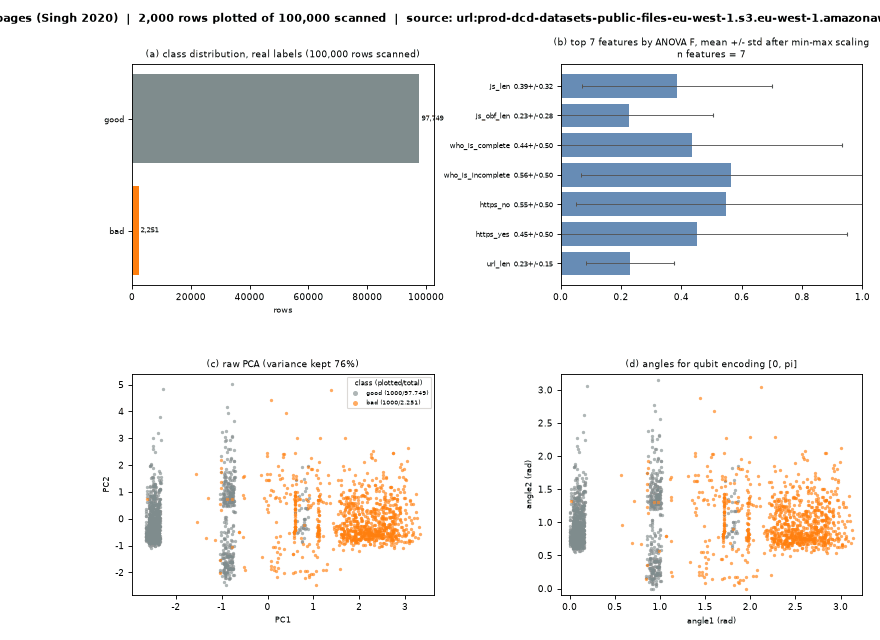

In [81]:
show_dataset("Malicious and Benign Webpages (Singh 2020)")

#### PhishTank

**Domain:** Phishing (live feed) &nbsp;|&nbsp; **Access:** `gated` (registration needed) &nbsp;|&nbsp; **Licence:** PhishTank API key

**Task and use cases:** Community-verified phishing URL feed.

**Reference:** https://www.phishtank.com/.

**Source:** [https://www.phishtank.com/developer_info.php](https://www.phishtank.com/developer_info.php). **Topic folders:** `08_Phishing_Detection`, `09_Malicious_URL_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Developer API key required; user must supply a verified_online.csv dump.

In [82]:
show_dataset("PhishTank")

[NEEDS_USER_FILE] PhishTank
Not downloadable automatically (registration / API key). Official page: https://www.phishtank.com/developer_info.php . Provide the data file(s) in atlas_user_files\phishtank/ (a .csv, .parquet, .zip or .xlsx with the label column ['verified']) and run this cell again.


#### UCI Spambase

**Domain:** Spam &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 57 word/character-frequency features of 4601 e-mails, spam vs ham.

**Reference:** Hopkins, Reeber, Forman, Suermondt, 'Spambase', UCI 1999.

**Source:** [https://archive.ics.uci.edu/static/public/94/spambase.zip](https://archive.ics.uci.edu/static/public/94/spambase.zip). **Topic folders:** `10_Spam_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-025](https://github.com/owlmt/QML/blob/main/06_Android_Malware_Detection/VQC_PhishingMalwareSpam_RosaRemedios2024.ipynb)

**Notes:** No header; column 57 is the label.

[LOADED] UCI Spambase   source: url:archive.ics.uci.edu
  rows scanned: 4,601 of 4,601 | rows kept in the pool: 4,601 | columns: 57 -> 57 features after cleaning | rows plotted: 2,000
  label column: 'f57' | classes: 2
  feature names (57): ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21', 'f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31', 'f32', 'f33', 'f34', 'f35', 'f36', 'f37', 'f38', 'f39'] ...
  label value counts (real labels, before sampling): 0=2,788, 1=1,813
  first 3 rows (identifier columns removed):
    f0  f1   f2  f3  ...   f54  f55  f56  label
0    0   0 0.55   0  ... 1.392    4   78      1
1 0.64   0 0.64   0  ... 2.333   22  119      1
2    0   0    0   0  ... 1.428    4   10      1


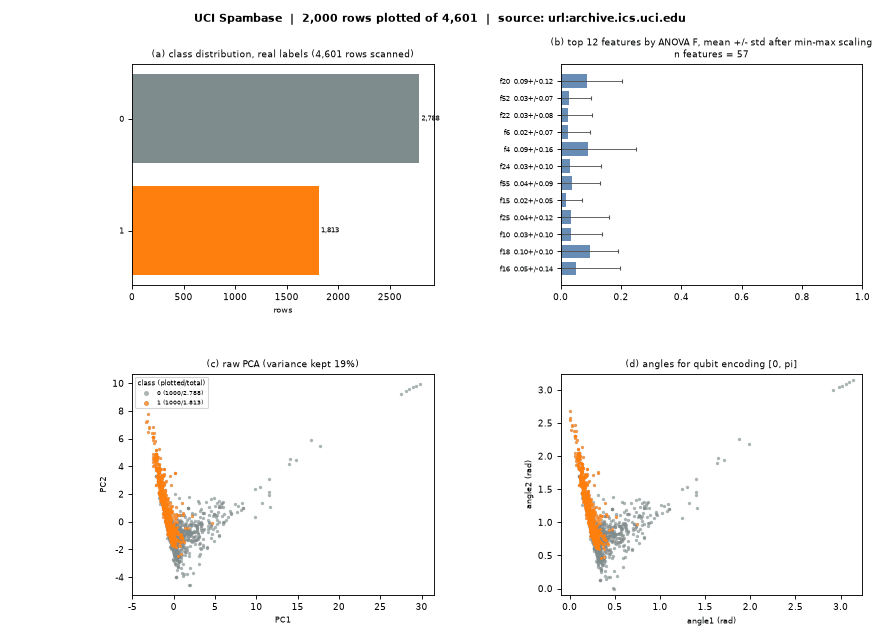

In [83]:
show_dataset("UCI Spambase")

#### Ling-Spam

**Domain:** Spam &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** AUEB, research use

**Task and use cases:** 2893 messages from the Linguist list, spam vs legitimate (text).

**Reference:** Androutsopoulos et al., 'An evaluation of naive Bayesian anti-spam filtering', 2000.

**Source:** [https://www2.aueb.gr/users/ion/data/lingspam_public.tar.gz](https://www2.aueb.gr/users/ion/data/lingspam_public.tar.gz). **Topic folders:** `10_Spam_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-151](https://github.com/owlmt/QML/blob/main/10_Spam_Detection/HybridQSVM_SpamIDS_Chen2025.ipynb)

**Notes:** 11.5 MB tarball (TLS verification fails for www2.aueb.gr from this machine; verify=False for this host only). Files named spmsg* are spam.

[LOADED] Ling-Spam   source: url:www2.aueb.gr
  rows scanned: 289 of 289 | rows kept in the pool: 289 | columns: 1 -> 50 features after cleaning | rows plotted: 289
  label column: 'file name' | classes: 2
  feature names (50): ['svd_0', 'svd_1', 'svd_2', 'svd_3', 'svd_4', 'svd_5', 'svd_6', 'svd_7', 'svd_8', 'svd_9', 'svd_10', 'svd_11', 'svd_12', 'svd_13', 'svd_14', 'svd_15', 'svd_16', 'svd_17', 'svd_18', 'svd_19', 'svd_20', 'svd_21', 'svd_22', 'svd_23', 'svd_24', 'svd_25', 'svd_26', 'svd_27', 'svd_28', 'svd_29', 'svd_30', 'svd_31', 'svd_32', 'svd_33', 'svd_34', 'svd_35', 'svd_36', 'svd_37', 'svd_38', 'svd_39'] ...
  removed columns (1): text [TF-IDF(2000 terms) -> SVD(50)]
  label value counts (real labels, before sampling): ham=241, spam=48
  first 3 rows (identifier columns removed):
   svd_0    svd_1    svd_2    svd_3  ...    svd_47   svd_48   svd_49  label
0 0.1633 -0.05028  0.03108   0.1593  ... -0.002521 -0.06435  -0.0151    ham
1 0.1283 -0.04229 -0.04896   0.1066  ...   0.01907

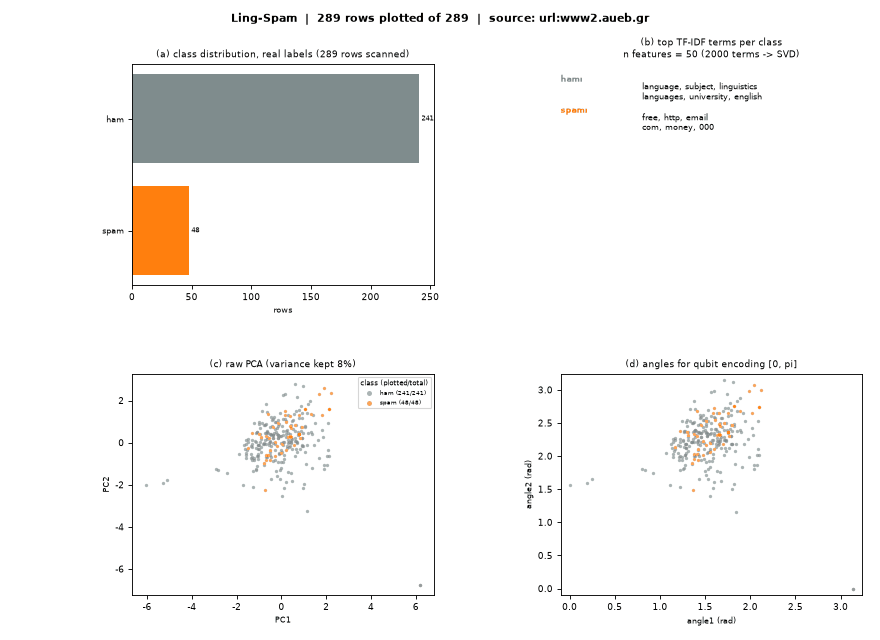

In [84]:
show_dataset("Ling-Spam")

#### SpamFilter corpus (llhyatt98)

**Domain:** Spam &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** E-mail text corpus packaged with a spam-filter project.

**Reference:** llhyatt98/SpamFilter (GitHub).

**Source:** [https://codeload.github.com/llhyatt98/SpamFilter/zip/HEAD](https://codeload.github.com/llhyatt98/SpamFilter/zip/HEAD). **Topic folders:** `10_Spam_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-151](https://github.com/owlmt/QML/blob/main/10_Spam_Detection/HybridQSVM_SpamIDS_Chen2025.ipynb)

**Notes:** Used by QC-151 together with Ling-Spam.

[LOADED] SpamFilter corpus (llhyatt98)   source: url:codeload.github.com
  rows scanned: 2,893 of 2,893 | rows kept in the pool: 2,893 | columns: 1 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'file name' | classes: 2
  feature names (50): ['svd_0', 'svd_1', 'svd_2', 'svd_3', 'svd_4', 'svd_5', 'svd_6', 'svd_7', 'svd_8', 'svd_9', 'svd_10', 'svd_11', 'svd_12', 'svd_13', 'svd_14', 'svd_15', 'svd_16', 'svd_17', 'svd_18', 'svd_19', 'svd_20', 'svd_21', 'svd_22', 'svd_23', 'svd_24', 'svd_25', 'svd_26', 'svd_27', 'svd_28', 'svd_29', 'svd_30', 'svd_31', 'svd_32', 'svd_33', 'svd_34', 'svd_35', 'svd_36', 'svd_37', 'svd_38', 'svd_39'] ...
  removed columns (1): text [TF-IDF(2000 terms) -> SVD(50)]
  label value counts (real labels, before sampling): ham=2,412, spam=481
  first 3 rows (identifier columns removed):
   svd_0    svd_1   svd_2    svd_3  ...  svd_47   svd_48    svd_49  label
0  0.318 -0.08174  0.1215 -0.03531  ...  0.0376  0.01249 -0.009645    ham
1 0.1688  0.0111

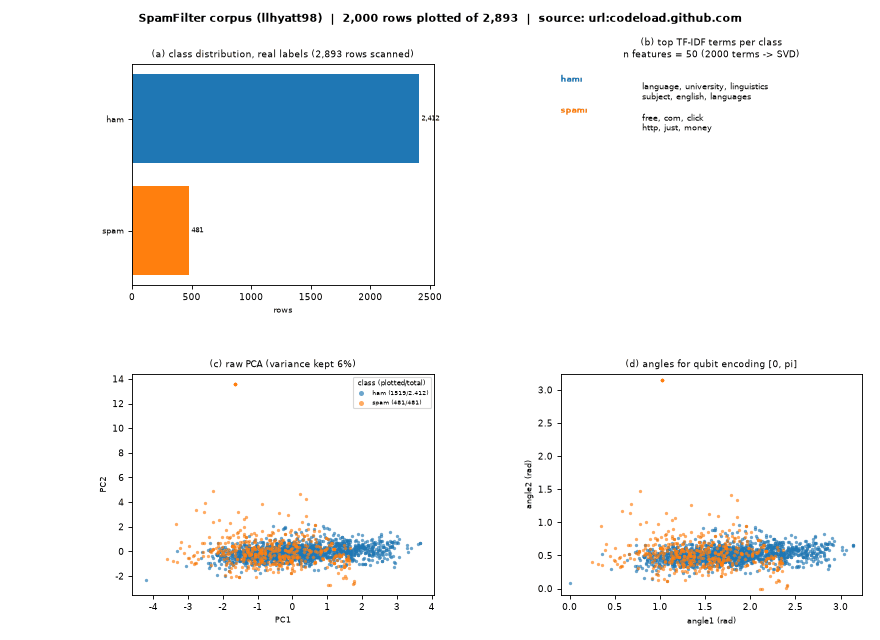

In [85]:
show_dataset("SpamFilter corpus (llhyatt98)")

#### SMS Spam Collection

**Domain:** Spam &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UCI, CC BY 4.0

**Task and use cases:** 5574 SMS messages, spam vs ham (text).

**Reference:** Almeida, Gomez Hidalgo, Yamakami, 'Contributions to the study of SMS spam filtering', DocEng 2011.

**Source:** Hugging Face mirror [ucirvine/sms_spam](https://huggingface.co/datasets/ucirvine/sms_spam). **Topic folders:** `10_Spam_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 0.4 MB.

[LOADED] SMS Spam Collection   source: hf:ucirvine/sms_spam
  rows scanned: 5,574 of 5,574 | rows kept in the pool: 3,747 | columns: 1 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 2
  feature names (50): ['svd_0', 'svd_1', 'svd_2', 'svd_3', 'svd_4', 'svd_5', 'svd_6', 'svd_7', 'svd_8', 'svd_9', 'svd_10', 'svd_11', 'svd_12', 'svd_13', 'svd_14', 'svd_15', 'svd_16', 'svd_17', 'svd_18', 'svd_19', 'svd_20', 'svd_21', 'svd_22', 'svd_23', 'svd_24', 'svd_25', 'svd_26', 'svd_27', 'svd_28', 'svd_29', 'svd_30', 'svd_31', 'svd_32', 'svd_33', 'svd_34', 'svd_35', 'svd_36', 'svd_37', 'svd_38', 'svd_39'] ...
  removed columns (1): text [TF-IDF(2000 terms) -> SVD(50)]
  label value counts (real labels, before sampling): ham=4,827, spam=747
  first 3 rows (identifier columns removed):
    svd_0    svd_1    svd_2   svd_3  ...    svd_47   svd_48   svd_49  label
0  0.1219  0.02468 -0.09789  0.1201  ...   0.02604 -0.01306    0.044    ham
1 0.04454  0.03754 -0.06196  

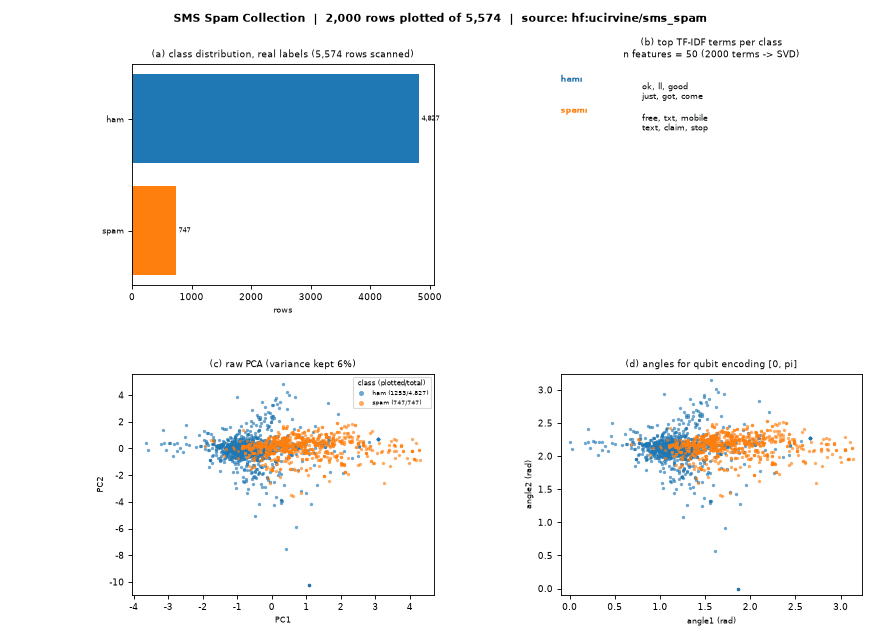

In [86]:
show_dataset("SMS Spam Collection")

#### Enron-Spam

**Domain:** Spam &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** public domain (Enron corpus)

**Task and use cases:** 33k Enron e-mails, spam vs ham (text).

**Reference:** Metsis, Androutsopoulos, Paliouras, 'Spam filtering with naive Bayes: which naive Bayes?', CEAS 2006.

**Source:** Hugging Face mirror [SetFit/enron_spam](https://huggingface.co/datasets/SetFit/enron_spam). **Topic folders:** `10_Spam_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 6 MB test split.

[LOADED] Enron-Spam   source: hf:SetFit/enron_spam
  rows scanned: 2,000 of 2,000 | rows kept in the pool: 2,000 | columns: 6 -> 50 features after cleaning | rows plotted: 2,000
  label column: 'label_text' | classes: 2
  feature names (50): ['svd_0', 'svd_1', 'svd_2', 'svd_3', 'svd_4', 'svd_5', 'svd_6', 'svd_7', 'svd_8', 'svd_9', 'svd_10', 'svd_11', 'svd_12', 'svd_13', 'svd_14', 'svd_15', 'svd_16', 'svd_17', 'svd_18', 'svd_19', 'svd_20', 'svd_21', 'svd_22', 'svd_23', 'svd_24', 'svd_25', 'svd_26', 'svd_27', 'svd_28', 'svd_29', 'svd_30', 'svd_31', 'svd_32', 'svd_33', 'svd_34', 'svd_35', 'svd_36', 'svd_37', 'svd_38', 'svd_39'] ...
  removed columns (1): text [TF-IDF(2000 terms) -> SVD(50)]
  label value counts (real labels, before sampling): spam=1,008, ham=992
  first 3 rows (identifier columns removed):
    svd_0    svd_1    svd_2    svd_3  ...    svd_47   svd_48   svd_49  label
0  0.1579 -0.08114  -0.1084 0.007882  ...  -0.09072 0.008315  -0.1031   spam
1  0.1617 -0.04729 -0.07213  0.

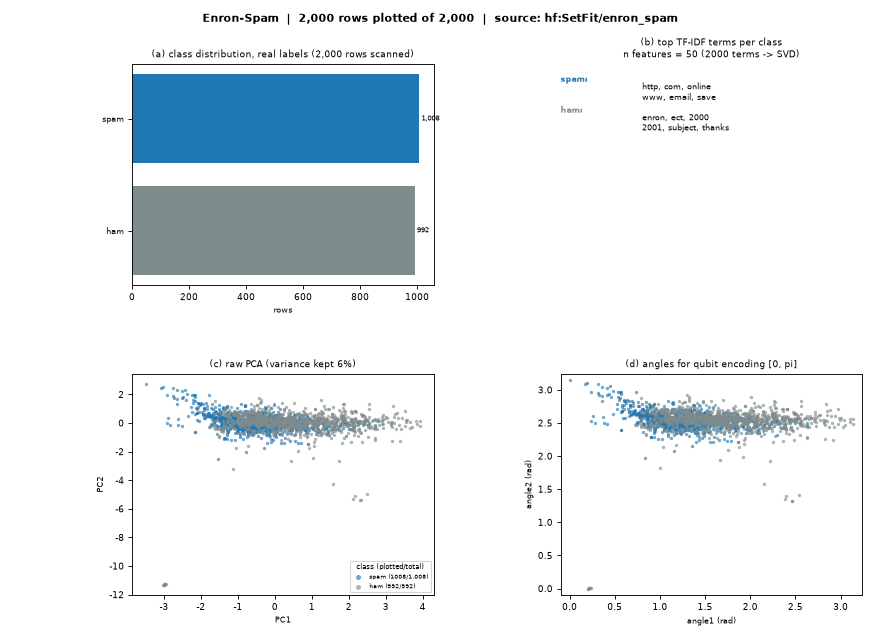

In [87]:
show_dataset("Enron-Spam")

### 9. CIC page-only collections

Canadian Institute for Cybersecurity releases that sit behind a request form.

#### CIC-Darknet2020

**Domain:** Darknet traffic &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Tor / VPN / non-Tor / non-VPN traffic with application labels.

**Reference:** Habibi Lashkari, Kaur, Rahali, 'DIDarknet: a contemporary approach to detect and characterize the darknet traffic using deep image learning', ICCNS 2020.

**Source:** [https://www.unb.ca/cic/datasets/darknet2020.html](https://www.unb.ca/cic/datasets/darknet2020.html). **Topic folders:** `13_Encrypted_Malicious_Traffic_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-198](https://github.com/owlmt/QML/blob/main/13_Encrypted_Malicious_Traffic_Detection/HybridQNN_EncryptedTraffic_Hariharan2025.ipynb)

**Notes:** Darknet.CSV behind the CIC request form (cicresearch.ca returns the form page); QC-198 loads it from its own copy. User must supply.

In [88]:
show_dataset("CIC-Darknet2020")

[NEEDS_USER_FILE] CIC-Darknet2020
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/darknet2020.html . Provide the data file(s) in atlas_user_files\cic_darknet2020/ (a .csv, .parquet, .zip or .xlsx with the label column ['Label', 'Label.1']) and run this cell again.


#### CIC-Bell-DNS 2021

**Domain:** Malicious domains &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC / Bell, research use

**Task and use cases:** DNS features of benign, malware, phishing and spam domains.

**Reference:** Mahdavifar et al., 'Classifying malicious domains using DNS traffic analysis', DASC 2021.

**Source:** [https://www.unb.ca/cic/datasets/dns-2021.html](https://www.unb.ca/cic/datasets/dns-2021.html). **Topic folders:** `09_Malicious_URL_Detection`, `04_Botnet_DGA_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [89]:
show_dataset("CIC-Bell-DNS 2021")

[NEEDS_USER_FILE] CIC-Bell-DNS 2021
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/dns-2021.html . Provide the data file(s) in atlas_user_files\cic_bell_dns_2021/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC-Bell-DNS-EXF 2021

**Domain:** DNS exfiltration &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC / Bell, research use

**Task and use cases:** Stateless/stateful DNS features for exfiltration detection.

**Reference:** Mahdavifar et al., 'Lightweight hybrid detection of data exfiltration using DNS based on machine learning', ICCNS 2021.

**Source:** [https://www.unb.ca/cic/datasets/dns-exf-2021.html](https://www.unb.ca/cic/datasets/dns-exf-2021.html). **Topic folders:** `13_Encrypted_Malicious_Traffic_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [90]:
show_dataset("CIC-Bell-DNS-EXF 2021")

[NEEDS_USER_FILE] CIC-Bell-DNS-EXF 2021
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/dns-exf-2021.html . Provide the data file(s) in atlas_user_files\cic_bell_dns_exf_2021/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC-PQC_OAV v1

**Domain:** Post-quantum TLS anomaly &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** TLS handshakes with post-quantum algorithms, normal vs anomalous.

**Reference:** UNB CIC, CIC-PQC_OAV 2025.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `21_QKD_Attack_Detection`, `13_Encrypted_Malicious_Traffic_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [91]:
show_dataset("CIC-PQC_OAV v1")

[NEEDS_USER_FILE] CIC-PQC_OAV v1
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cic_pqc_oav_v1/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC-Trap4Phish

**Domain:** Phishing &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Trap-based phishing page collection.

**Reference:** UNB CIC, 2024.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `08_Phishing_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [92]:
show_dataset("CIC-Trap4Phish")

[NEEDS_USER_FILE] CIC-Trap4Phish
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cic_trap4phish/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC-DGG / CIC-SGG malware graphs

**Domain:** Malware (graphs) &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** Dynamic / static call-graph generation for malware classification.

**Reference:** UNB CIC, 2024.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `05_Malware_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Two related CIC releases; request form; user must supply.

In [93]:
show_dataset("CIC-DGG / CIC-SGG malware graphs")

[NEEDS_USER_FILE] CIC-DGG / CIC-SGG malware graphs
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cic_dgg_cic_sgg_malware_graphs/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


#### CIC-YNU-IoTMal

**Domain:** IoT malware &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** UNB CIC, research use

**Task and use cases:** IoT malware binaries/features (Yunnan University / CIC).

**Reference:** UNB CIC, 2025.

**Source:** [https://www.unb.ca/cic/datasets/](https://www.unb.ca/cic/datasets/). **Topic folders:** `05_Malware_Detection`, `14_IoT_IIoT_Attack_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** Request form; user must supply.

In [94]:
show_dataset("CIC-YNU-IoTMal")

[NEEDS_USER_FILE] CIC-YNU-IoTMal
Not downloadable automatically (request form or no stable direct link). Official page: https://www.unb.ca/cic/datasets/ . Provide the data file(s) in atlas_user_files\cic_ynu_iotmal/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


### 10. Vehicle CAN bus

In-vehicle network frames with injected attacks.

#### Car-Hacking Dataset (HCRL)

**Domain:** Vehicle CAN bus &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** HCRL Korea University, research use

**Task and use cases:** CAN frames (ID, DLC, 8 data bytes) during DoS, fuzzy, gear and RPM spoofing attacks.

**Reference:** Seo, Song, Kim, 'GIDS: GAN based intrusion detection system for in-vehicle network', PST 2018.

**Source:** [https://raw.githubusercontent.com/JehadAlyateem/Car-Hacking-Dataset/main/Car-Hacking-Datas...](https://raw.githubusercontent.com/JehadAlyateem/Car-Hacking-Dataset/main/Car-Hacking-Dataset-1.zip). **Topic folders:** `17_Vehicle_CAN_Bus_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-320](https://github.com/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/QBoost_CANBusIntrusion_Caivano2022.ipynb)

**Notes:** 66 MB zip (GitHub copy used by two corpus notebooks). Flag R = normal, T = injected; the attack family comes from the file name.

[LOADED] Car-Hacking Dataset (HCRL)   source: url:raw.githubusercontent.com
  rows scanned: 400,000 | rows kept in the pool: 9,000 | columns: 10 -> 10 features after cleaning | rows plotted: 2,000
  label column: 'Flag' | classes: 3
  feature names (10): ['ID', 'DLC', 'D0', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7']
  label value counts (real labels, before sampling): Normal=321,985, DoS=48,687, Fuzzy=29,328
  first 3 rows (identifier columns removed):
    ID  DLC  D0  D1  ...  D5  D6  D7   label
0 1680    8   0   0  ...   2   0   0  Normal
1  880    8   0  32  ...   0   0   0  Normal
2  497    8   8   0  ...   0   0   0  Normal


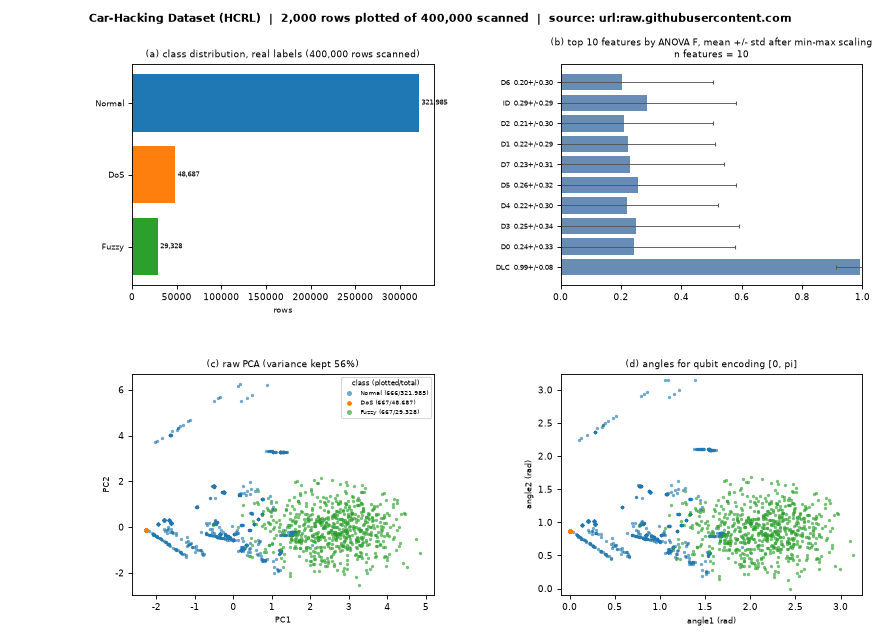

In [95]:
show_dataset("Car-Hacking Dataset (HCRL)")

#### CAN intrusion dataset (OTIDS)

**Domain:** Vehicle CAN bus &nbsp;|&nbsp; **Access:** `page_only` (no direct link) &nbsp;|&nbsp; **Licence:** HCRL, research use

**Task and use cases:** CAN traffic with DoS, fuzzy and impersonation attacks.

**Reference:** Lee, Jeong, Kim, 'OTIDS: a novel intrusion detection system for in-vehicle network by using remote frame', PST 2017.

**Source:** [https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset](https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset). **Topic folders:** `17_Vehicle_CAN_Bus_Attacks`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-328](https://github.com/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/HybridQNN_CANAttack_Islam2021.ipynb)

**Notes:** Files are linked from the HCRL page via Dropbox folders (used by QC-328 with the folder link); no stable direct file URL. User can supply the txt files.

In [96]:
show_dataset("CAN intrusion dataset (OTIDS)")

[NEEDS_USER_FILE] CAN intrusion dataset (OTIDS)
Not downloadable automatically (request form or no stable direct link). Official page: https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset . Provide the data file(s) in atlas_user_files\can_intrusion_dataset/ (a .csv, .parquet, .zip or .xlsx with the label column ['label']) and run this cell again.


### 11. Host and cloud logs

Kernel-level process logs and system-call traces.

#### BETH

**Domain:** Host / cloud anomaly &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** Kernel-level process and network logs from cloud honeypots, with suspicious and evil labels.

**Reference:** Highnam, Arulkumaran, Hanif, Jennings, 'BETH dataset: real cybersecurity data for unsupervised anomaly detection research', ICML UDL 2021.

**Source:** [https://github.com/pinknwhite-franko/beth-dataset-anamoly-detection/raw/main/beth-dataset....](https://github.com/pinknwhite-franko/beth-dataset-anamoly-detection/raw/main/beth-dataset.zip). **Topic folders:** `18_Cloud_Virtual_Environment_Threats`, `19_Cybersecurity_Anomaly_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-194](https://github.com/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/QAE_AnomalyDetection_Senthil2025.ipynb)

**Notes:** 42 MB zip (GitHub copy used by QC-194).

[LOADED] BETH   source: url:github.com
  rows scanned: 188,967 of 188,967 | rows kept in the pool: 6,000 | columns: 15 -> 8 features after cleaning | rows plotted: 2,000
  label column: 'evil' | classes: 2
  feature names (8): ['processId', 'threadId', 'parentProcessId', 'userId', 'mountNamespace', 'eventId', 'argsNum', 'returnValue']
  removed columns (7): timestamp [identifier / raw text], hostName [identifier / raw text], sus [alternative label column], processName [text with many distinct values], eventName [text with many distinct values], stackAddresses [text with many distinct values], args [text with many distinct values]
  label value counts (real labels, before sampling): 1=158,432, 0=30,535
  first 3 rows (identifier columns removed):
   processId  threadId  parentProcessId  userId  mountNamespace  eventId  argsNum  returnValue label
0       7286      7286           1201         0      4.027e+09         3        1            0     0
1       7520      7520           7102     

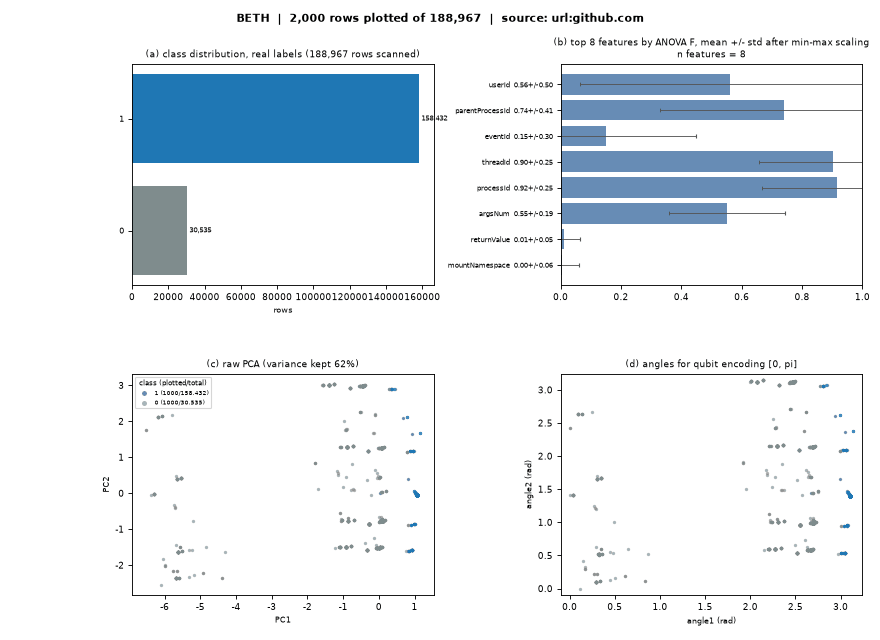

In [97]:
show_dataset("BETH")

#### ADFA-LD

**Domain:** Host intrusion (syscalls) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** UNSW Canberra, research use

**Task and use cases:** Linux system-call traces, normal vs 6 attack types.

**Reference:** Creech, Hu, 'Generation of a new IDS test dataset: time to retire the KDD collection', WCNC 2013.

**Source:** [https://raw.githubusercontent.com/verazuo/a-labelled-version-of-the-ADFA-LD-dataset/HEAD/A...](https://raw.githubusercontent.com/verazuo/a-labelled-version-of-the-ADFA-LD-dataset/HEAD/ADFA-LD.zip). **Topic folders:** `18_Cloud_Virtual_Environment_Threats`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-012](https://github.com/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/QLSTM_SyscallThreat_Tripathi2025.ipynb)

**Notes:** 2.4 MB zip of syscall-id text files; the atlas builds syscall-frequency features (bag of 340 syscalls) per trace.

[LOADED] ADFA-LD   source: url:raw.githubusercontent.com
  rows scanned: 1,579 of 1,579 | rows kept in the pool: 1,579 | columns: 342 -> 154 features after cleaning | rows plotted: 1,579
  label column: 'folder name' | classes: 7
  feature names (154): ['syscall_1', 'syscall_3', 'syscall_4', 'syscall_5', 'syscall_6', 'syscall_7', 'syscall_8', 'syscall_9', 'syscall_10', 'syscall_11', 'syscall_12', 'syscall_13', 'syscall_15', 'syscall_19', 'syscall_20', 'syscall_21', 'syscall_26', 'syscall_27', 'syscall_30', 'syscall_33', 'syscall_37', 'syscall_38', 'syscall_39', 'syscall_40', 'syscall_41', 'syscall_42', 'syscall_43', 'syscall_45', 'syscall_54', 'syscall_57', 'syscall_60', 'syscall_63', 'syscall_64', 'syscall_65', 'syscall_66', 'syscall_75', 'syscall_77', 'syscall_78', 'syscall_83', 'syscall_85'] ...
  label value counts (real labels, before sampling): normal=833, Hydra_SSH=176, Hydra_FTP=162, Java_Meterpreter=124, Web_Shell=118, Adduser=91, Meterpreter=75
  first 3 rows (identifier colu

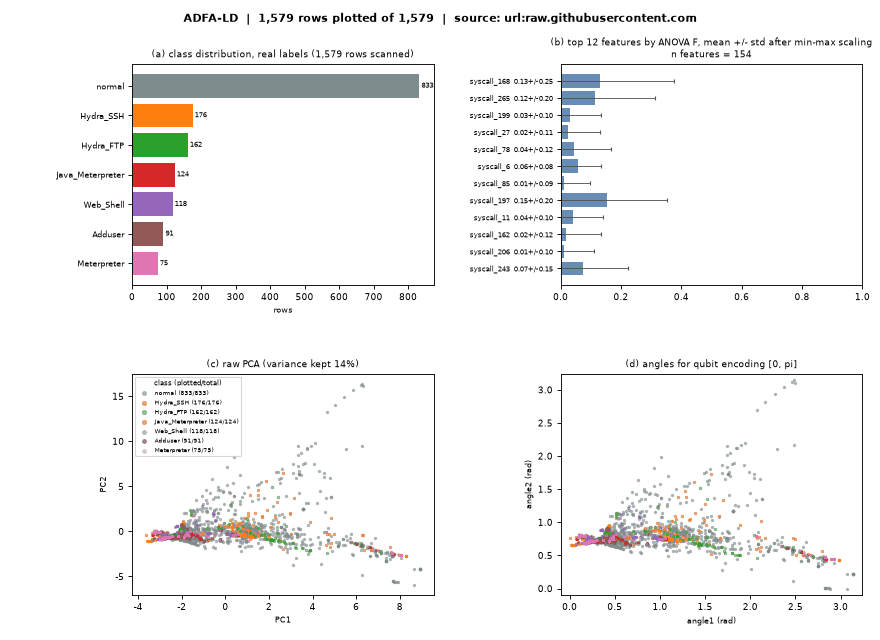

In [98]:
show_dataset("ADFA-LD")

### 12. Audio deepfake

Bona fide versus spoofed or synthetic speech.

#### ASVspoof 5

**Domain:** Audio deepfake &nbsp;|&nbsp; **Access:** `large` (public; FULL mode only) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** Speech deepfake and spoofing detection (bona fide vs spoof, 32 attack algorithms).

**Reference:** Wang et al., 'ASVspoof 5: crowdsourced speech data, deepfakes, and adversarial attacks at scale', ASVspoof Workshop 2024 (Zenodo 12151404).

**Source:** [https://zenodo.org/api/records/12151404/files/track1_2-dev.tar.gz/content](https://zenodo.org/api/records/12151404/files/track1_2-dev.tar.gz/content). **Topic folders:** `22_Deepfake_Spoofing_Detection`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-219](https://github.com/owlmt/QML/blob/main/22_Deepfake_Spoofing_Detection/QSVM_AudioDeepfake_Amin2025.ipynb)

**Notes:** 2.1 GB tarball; FULL mode only (spectrogram-feature PCA of a few hundred clips).

In [99]:
show_dataset("ASVspoof 5")

[SKIPPED_LARGE_FAST] ASVspoof 5
Source file is 2,159 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.


#### ASVspoof 2019 LA

**Domain:** Audio deepfake &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** ODC-By

**Task and use cases:** Logical-access spoofing (TTS/VC) vs bona fide speech.

**Reference:** Todisco et al., 'ASVspoof 2019: future horizons in spoofed and fake audio detection', Interspeech 2019.

**Source:** Hugging Face mirror [Bisher/ASVspoof_2019_LA](https://huggingface.co/datasets/Bisher/ASVspoof_2019_LA). **Topic folders:** `22_Deepfake_Spoofing_Detection`.

**Used by:** not yet used by a reproduced paper.

**Notes:** 1.5 GB parquet; the atlas reads only the first row group via HfFileSystem (a few hundred clips) and plots log-mel-spectrogram feature PCA.

[LOADED] ASVspoof 2019 LA   source: hf:Bisher/ASVspoof_2019_LA (12 evenly spaced row groups of 24,844 rows)
  rows scanned: 600 of 24,844 | rows kept in the pool: 600 | columns: 130 -> 130 features after cleaning | rows plotted: 600
  label column: 'key' | classes: 2
  feature names (130): ['logmel_mean_0', 'logmel_mean_1', 'logmel_mean_2', 'logmel_mean_3', 'logmel_mean_4', 'logmel_mean_5', 'logmel_mean_6', 'logmel_mean_7', 'logmel_mean_8', 'logmel_mean_9', 'logmel_mean_10', 'logmel_mean_11', 'logmel_mean_12', 'logmel_mean_13', 'logmel_mean_14', 'logmel_mean_15', 'logmel_mean_16', 'logmel_mean_17', 'logmel_mean_18', 'logmel_mean_19', 'logmel_mean_20', 'logmel_mean_21', 'logmel_mean_22', 'logmel_mean_23', 'logmel_mean_24', 'logmel_mean_25', 'logmel_mean_26', 'logmel_mean_27', 'logmel_mean_28', 'logmel_mean_29', 'logmel_mean_30', 'logmel_mean_31', 'logmel_mean_32', 'logmel_mean_33', 'logmel_mean_34', 'logmel_mean_35', 'logmel_mean_36', 'logmel_mean_37', 'logmel_mean_38', 'logmel_mean_39'

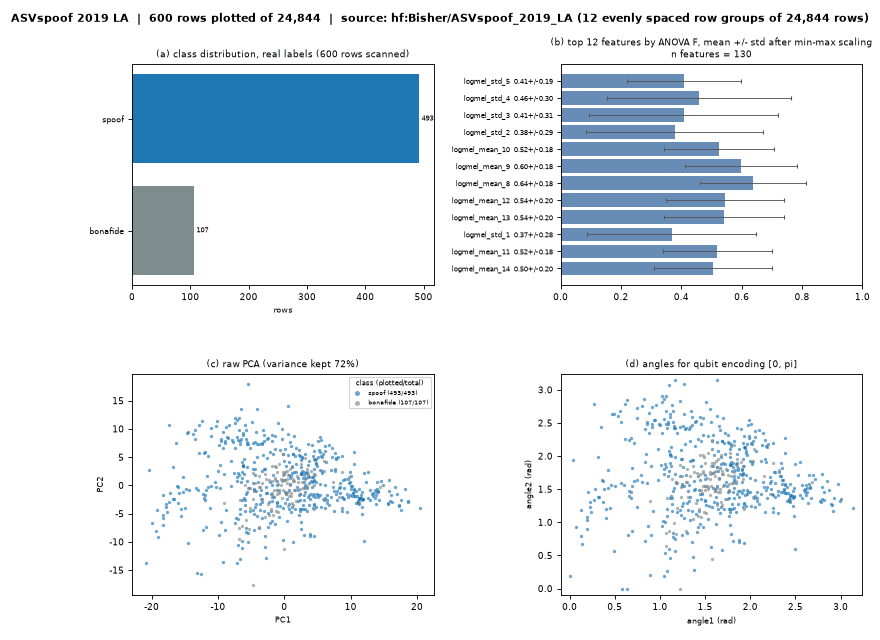

In [100]:
show_dataset("ASVspoof 2019 LA")

### 13. Benchmark sets used by the QML-attack papers

Image and tabular benchmarks on which the QML attack and defence papers are evaluated.

#### MNIST

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY-SA 3.0

**Task and use cases:** Handwritten digits; the standard test bed for adversarial, poisoning, backdoor, extraction and privacy attacks on QML (24 corpus notebooks).

**Reference:** LeCun, Cortes, Burges, 'The MNIST database of handwritten digits', 1998.

**Source:** Hugging Face mirror [ylecun/mnist](https://huggingface.co/datasets/ylecun/mnist). **Topic folders:** `23_Adversarial_Attacks_Against_QML`, `24_Poisoning_Attacks_Against_QML`, `25_Backdoor_Trojan_Attacks_Against_QML`, `26_QML_Model_Extraction_Theft`, `27_QML_Privacy_Data_Leakage`, `28_QML_Hardware_Side_Channel_Crosstalk_Attacks`, `29_Adversarial_Robustness_Defences_for_QML`, `30_QML_Defences_Against_ML_Attacks`.

**Used by (25 reproduced notebooks), `QC-ID: notebook link`:** [QC-014](https://github.com/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/HybridQNN_LabelPoisoning_Kundu2024.ipynb); [QC-037](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_AccuracyRobustness_Tran2026.ipynb); [QC-043](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_QuantumStateBackdoor_Zhao2026.ipynb); [QC-051](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2026.ipynb); [QC-056](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_BackdoorDetection_Zhang2026.ipynb); [QC-057](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QFL_CircuitBackdoor_Mathur2026.ipynb); [QC-058](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_CertifiedRobustness_Guan2026.ipynb); [QC-059](https://github.com/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_MembershipInference_Tang2026.ipynb); [QC-061](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_SteeringDefence_Sanjaya2026.ipynb); [QC-063](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_NoiseAdversarial_Wang2026.ipynb); [QC-064](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QAE_AdversarialDefence_Andrews2026.ipynb); [QC-067](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/NQEDR_AdversarialRobustness_Li2026.ipynb); [QC-072](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_EquivariantAdversarialTransfer_Krumtunger2026.ipynb); [QC-075](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_HarmonicBackdoor_Zhang2026.ipynb); [QC-077](https://github.com/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/QGAN_AdversarialPurification_Stanly2026.ipynb); [QC-078](https://github.com/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/HybridQNN_BackdoorUnlearning_Don2026.ipynb); [QC-085](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_InputAwareBackdoor_Zhang2026.ipynb); [QC-117](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_AdversarialRobustness_Tran2026.ipynb); [QC-121](https://github.com/owlmt/QML/blob/main/28_QML_Hardware_Side_Channel_Crosstalk_Attacks/QNN_CrosstalkAttacks_Franco2026.ipynb); [QC-150](https://github.com/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_ModelExtraction_Fu2025.ipynb); [QC-197](https://github.com/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_DataBreach_Upadhyay2025.ipynb); [QC-213](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/HybridQNN_QuPTTrojan_Bhowmik2025.ipynb); [QC-300](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_Backdoor_QDoor_Chu2023.ipynb); [QC-305](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_DepolarizationNoiseRobustness_Winderl2023.ipynb); [QC-328](https://github.com/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/HybridQNN_CANAttack_Islam2021.ipynb)

**Notes:** Test split parquet (2.6 MB, PNG bytes decoded to 28x28).

[LOADED] MNIST   source: hf:ylecun/mnist
  rows scanned: 10,000 of 10,000 | rows kept in the pool: 10,000 | columns: 784 -> 784 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 10
  feature names (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): 1=1,135, 2=1,032, 7=1,028, 3=1,010, 9=1,009, 4=982, 0=980, 8=974, 6=958, 5=892
  first 3 rows (identifier columns removed):
   px0  px1  px2  px3  ...  px781  px782  px783  label
0    0    0    0    0  ...      0      0      0      7
1    0    0    0    0  ...      0      0      0      7
2    0    0    0    0  ...      0      0      0      7


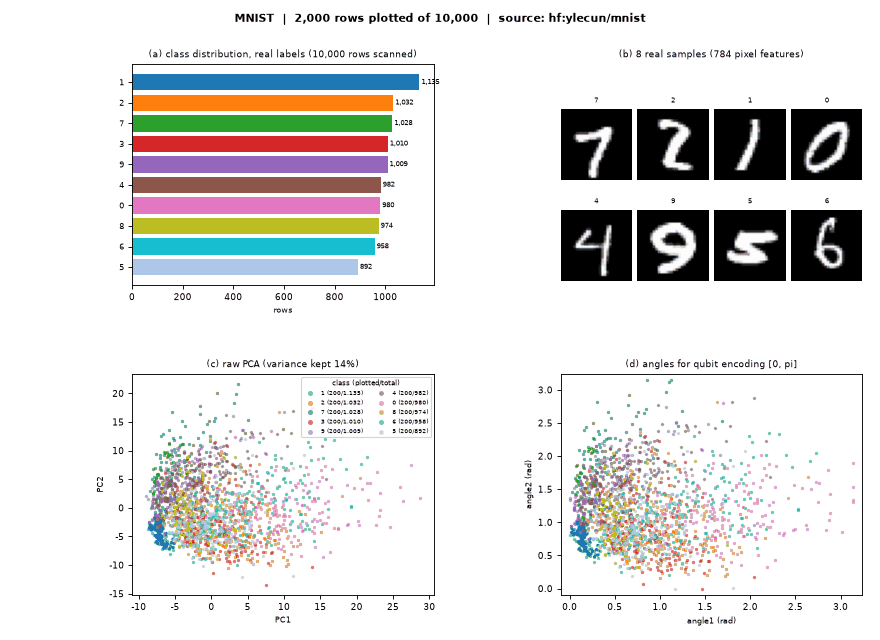

In [101]:
show_dataset("MNIST")

#### Fashion-MNIST

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** MIT

**Task and use cases:** Clothing images (10 classes); second-most used QML-attack test bed (11 notebooks).

**Reference:** Xiao, Rasul, Vollgraf, 'Fashion-MNIST', arXiv:1708.07747, 2017.

**Source:** [https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/t10k-images-idx3-...](https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/t10k-images-idx3-ubyte.gz). **Topic folders:** `24_Poisoning_Attacks_Against_QML`, `25_Backdoor_Trojan_Attacks_Against_QML`, `29_Adversarial_Robustness_Defences_for_QML`.

**Used by (12 reproduced notebooks), `QC-ID: notebook link`:** [QC-014](https://github.com/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/HybridQNN_LabelPoisoning_Kundu2024.ipynb); [QC-051](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2026.ipynb); [QC-058](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_CertifiedRobustness_Guan2026.ipynb); [QC-061](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_SteeringDefence_Sanjaya2026.ipynb); [QC-064](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QAE_AdversarialDefence_Andrews2026.ipynb); [QC-072](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_EquivariantAdversarialTransfer_Krumtunger2026.ipynb); [QC-075](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_HarmonicBackdoor_Zhang2026.ipynb); [QC-077](https://github.com/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/QGAN_AdversarialPurification_Stanly2026.ipynb); [QC-085](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_InputAwareBackdoor_Zhang2026.ipynb); [QC-150](https://github.com/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_ModelExtraction_Fu2025.ipynb); [QC-197](https://github.com/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_DataBreach_Upadhyay2025.ipynb); [QC-300](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_Backdoor_QDoor_Chu2023.ipynb)

**Notes:** IDX files from the Zalando repository.

[LOADED] Fashion-MNIST   source: url:github.com
  rows scanned: 10,000 of 10,000 | rows kept in the pool: 10,000 | columns: 784 -> 784 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 10
  feature names (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): 9=1,000, 2=1,000, 1=1,000, 6=1,000, 4=1,000, 5=1,000, 7=1,000, 3=1,000, 8=1,000, 0=1,000
  first 3 rows (identifier columns removed):
   px0  px1  px2  px3  ...  px781  px782  px783  label
0    0    0    0    0  ...      0      0      0      9
1    0    0    0    0  ...      0      0      0      9
2    0    0    0    0  ...      0      0      0      9


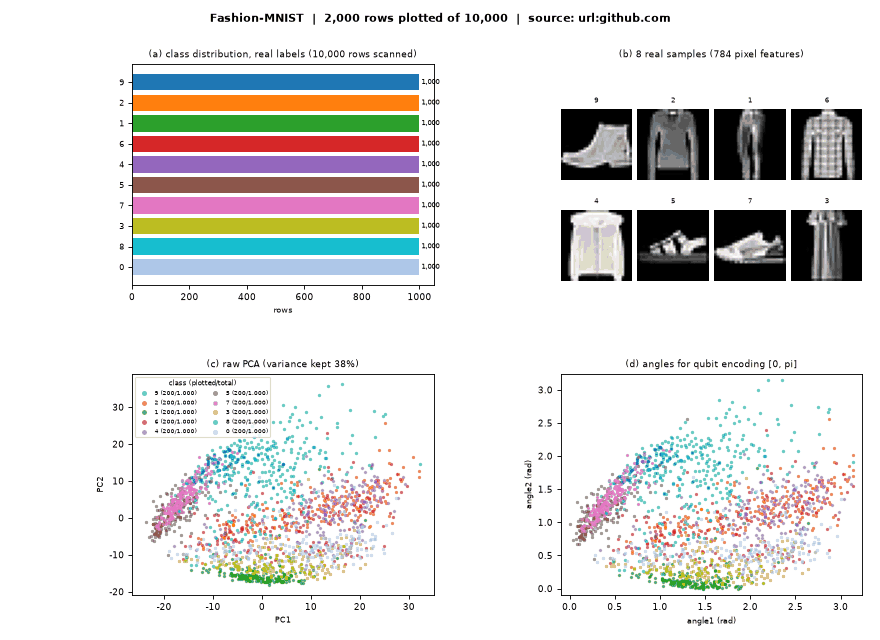

In [102]:
show_dataset("Fashion-MNIST")

#### KMNIST

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY-SA 4.0

**Task and use cases:** Kuzushiji characters (10 classes).

**Reference:** Clanuwat et al., 'Deep learning for classical Japanese literature', arXiv:1812.01718, 2018.

**Source:** Hugging Face mirror [tanganke/kmnist](https://huggingface.co/datasets/tanganke/kmnist). **Topic folders:** `24_Poisoning_Attacks_Against_QML`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-014](https://github.com/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/HybridQNN_LabelPoisoning_Kundu2024.ipynb)

**Notes:** 4.4 MB.

[LOADED] KMNIST   source: hf:tanganke/kmnist
  rows scanned: 10,000 of 10,000 | rows kept in the pool: 10,000 | columns: 784 -> 784 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 10
  feature names (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): す=1,000, を=1,000, つ=1,000, れ=1,000, は=1,000, ま=1,000, き=1,000, な=1,000, や=1,000, お=1,000
  first 3 rows (identifier columns removed):
   px0  px1  px2  px3  ...  px781  px782  px783  label
0    0    0    0    0  ...      0      0      0      す
1    0    0    0    0  ...      0      0      0      す
2    0    0    0    0  ...      0      0      0      す


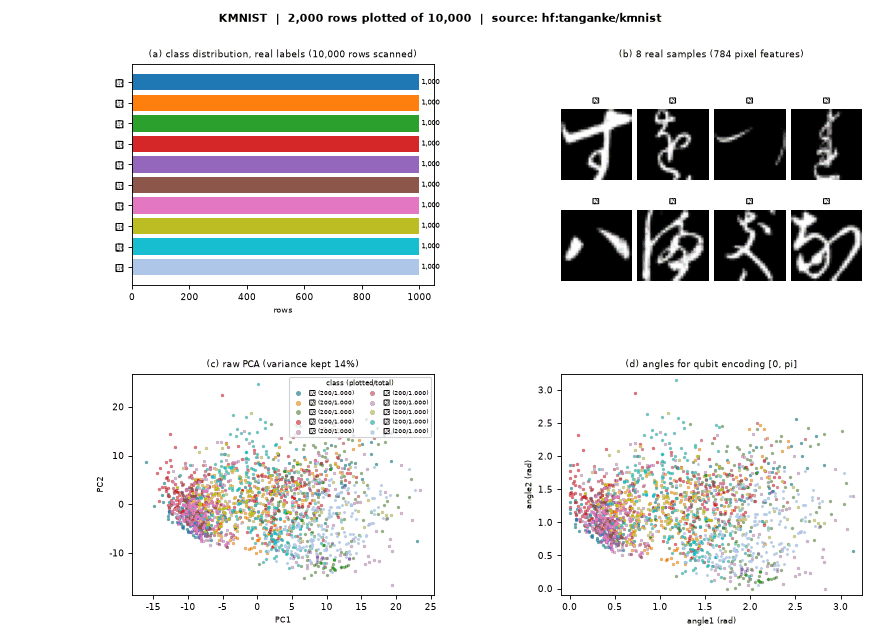

In [103]:
show_dataset("KMNIST")

#### EMNIST Letters

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC0

**Task and use cases:** Handwritten letters (26 classes).

**Reference:** Cohen, Afshar, Tapson, van Schaik, 'EMNIST: extending MNIST to handwritten letters', IJCNN 2017.

**Source:** Hugging Face mirror [tanganke/emnist_letters](https://huggingface.co/datasets/tanganke/emnist_letters). **Topic folders:** `24_Poisoning_Attacks_Against_QML`, `29_Adversarial_Robustness_Defences_for_QML`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-014](https://github.com/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/HybridQNN_LabelPoisoning_Kundu2024.ipynb); [QC-051](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2026.ipynb)

**Notes:** 8.4 MB.

[LOADED] EMNIST Letters   source: hf:tanganke/emnist_letters
  rows scanned: 10,000 of 20,800 | rows kept in the pool: 10,000 | columns: 784 -> 784 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 26
  feature names (784): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): S=413, J=413, K=402, H=402, M=393, W=393, Z=391, L=388, Q=388, E=388, C=386, I=385, P=383, U=383, V=382 ...
  first 3 rows (identifier columns removed):
   px0  px1  px2  px3  ...  px781  px782  px783  label
0    0    0    0    0  ...      0      0      0      S
1    0    0    0    0  ...      0      0      0      S
2    0    0    0    0  ...      0      0      0      S


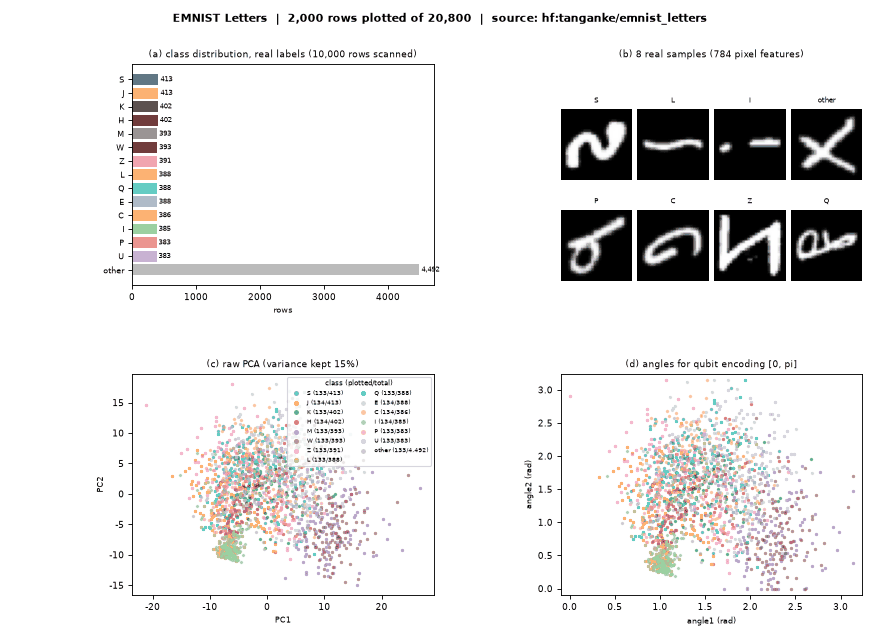

In [104]:
show_dataset("EMNIST Letters")

#### GTSRB

**Domain:** Benchmark (traffic signs) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC0

**Task and use cases:** German traffic signs (43 classes); backdoor-attack test bed.

**Reference:** Stallkamp, Schlipsing, Salmen, Igel, 'Man vs. computer: benchmarking machine learning algorithms for traffic sign recognition', Neural Networks 2012.

**Source:** Hugging Face mirror [tanganke/gtsrb](https://huggingface.co/datasets/tanganke/gtsrb). **Topic folders:** `25_Backdoor_Trojan_Attacks_Against_QML`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-235](https://github.com/owlmt/QML/blob/main/22_Deepfake_Spoofing_Detection/HybridQNN_DeepfakeTrafficSign_Salek2024.ipynb)

**Notes:** 109 MB test parquet; first row group only.

[LOADED] GTSRB   source: hf:tanganke/gtsrb (12 evenly spaced row groups of 12,630 rows)
  rows scanned: 1,130 of 12,630 | rows kept in the pool: 1,130 | columns: 3072 -> 3072 features after cleaning | rows plotted: 1,130
  label column: 'label' | classes: 17
  feature names (3072): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): red and white circle re...=100, white and yellow diamon...=100, stop=100, red and white triangle ...=100, blue circle with white ...=100, blue circle with white ...=100, red and white circle 10...=100, red and white triangle ...=70, red and white circle 20...=60, red and white triangle ...=60, white circle with gray ...=60, red and white circle 30

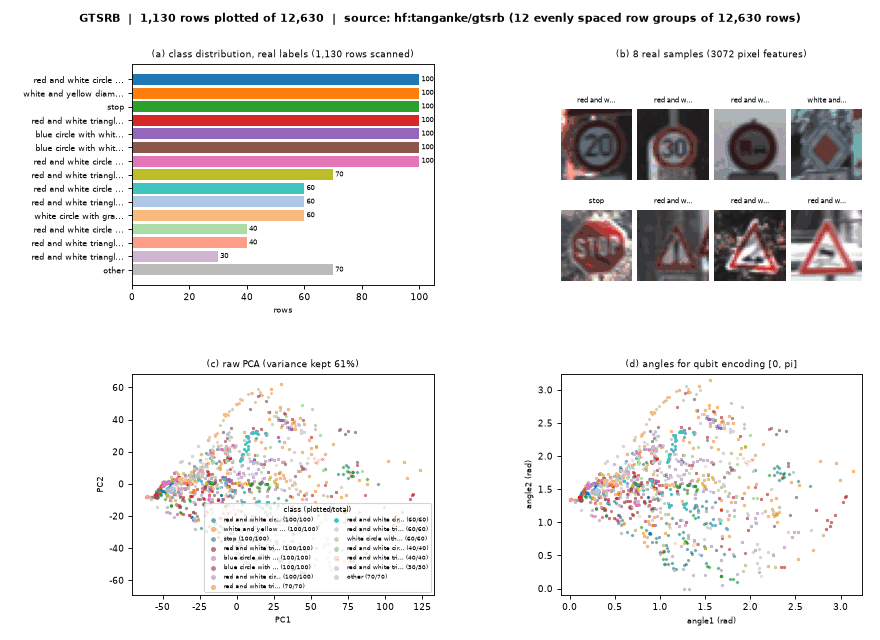

In [105]:
show_dataset("GTSRB")

#### CIFAR-10

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** see repository

**Task and use cases:** Natural images (10 classes).

**Reference:** Krizhevsky, 'Learning multiple layers of features from tiny images', 2009.

**Source:** Hugging Face mirror [uoft-cs/cifar10](https://huggingface.co/datasets/uoft-cs/cifar10). **Topic folders:** `23_Adversarial_Attacks_Against_QML`, `26_QML_Model_Extraction_Theft`, `29_Adversarial_Robustness_Defences_for_QML`.

**Used by (5 reproduced notebooks), `QC-ID: notebook link`:** [QC-037](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_AccuracyRobustness_Tran2026.ipynb); [QC-057](https://github.com/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QFL_CircuitBackdoor_Mathur2026.ipynb); [QC-072](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_EquivariantAdversarialTransfer_Krumtunger2026.ipynb); [QC-117](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_AdversarialRobustness_Tran2026.ipynb); [QC-305](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_DepolarizationNoiseRobustness_Winderl2023.ipynb)

**Notes:** 24 MB test parquet.

[LOADED] CIFAR-10   source: hf:uoft-cs/cifar10
  rows scanned: 10,000 of 10,000 | rows kept in the pool: 10,000 | columns: 3072 -> 3072 features after cleaning | rows plotted: 2,000
  label column: 'label' | classes: 10
  feature names (3072): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): cat=1,000, ship=1,000, airplane=1,000, frog=1,000, automobile=1,000, truck=1,000, dog=1,000, horse=1,000, deer=1,000, bird=1,000
  first 3 rows (identifier columns removed):
     px0    px1    px2    px3  ...  px3069  px3070  px3071  label
0 0.3843 0.2863 0.1412 0.4078  ...  0.1059 0.09804 0.07451    cat
1 0.3412  0.502 0.2667  0.298  ...  0.8314  0.7647  0.7765    cat
2 0.6471 0.6471 

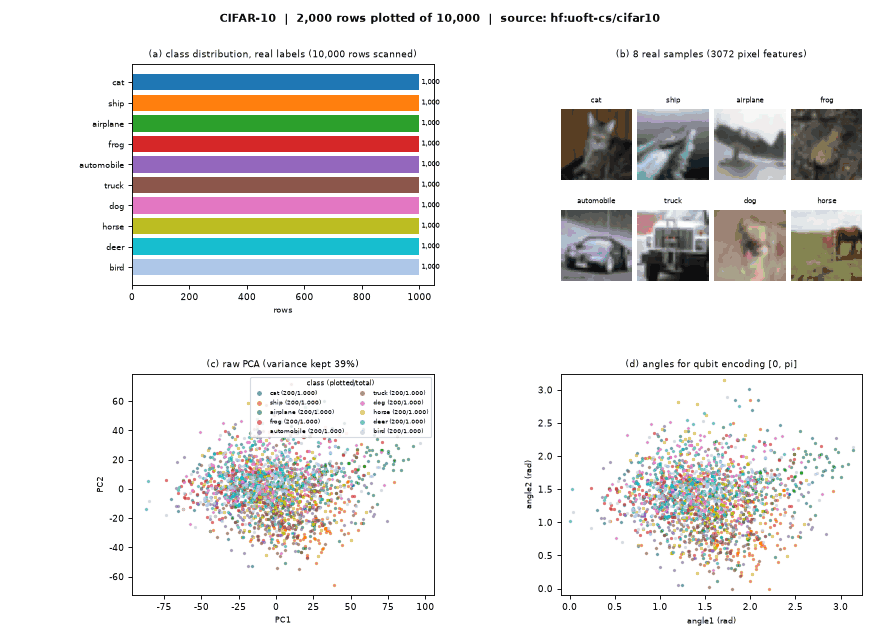

In [106]:
show_dataset("CIFAR-10")

#### Iris

**Domain:** Benchmark (tabular) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** public domain

**Task and use cases:** 4-feature, 3-class toy set used for small-qubit demonstrations.

**Reference:** Fisher 1936; scikit-learn load_iris.

**Source:** scikit-learn (`sklearn.datasets.load_iris`). **Topic folders:** `23_Adversarial_Attacks_Against_QML`, `28_QML_Hardware_Side_Channel_Crosstalk_Attacks`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-121](https://github.com/owlmt/QML/blob/main/28_QML_Hardware_Side_Channel_Crosstalk_Attacks/QNN_CrosstalkAttacks_Franco2026.ipynb); [QC-197](https://github.com/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_DataBreach_Upadhyay2025.ipynb); [QC-305](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_DepolarizationNoiseRobustness_Winderl2023.ipynb)

**Notes:** none

[LOADED] Iris   source: scikit-learn
  rows scanned: 150 of 150 | rows kept in the pool: 150 | columns: 4 -> 4 features after cleaning | rows plotted: 150
  label column: 'target' | classes: 3
  feature names (4): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
  label value counts (real labels, before sampling): setosa=50, versicolor=50, virginica=50
  first 3 rows (identifier columns removed):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)   label
0            4.3                  3               1.1                0.1     setosa
1            5.1                3.4               1.5                0.2     setosa
2            4.8                3.1               1.6                0.2     setosa


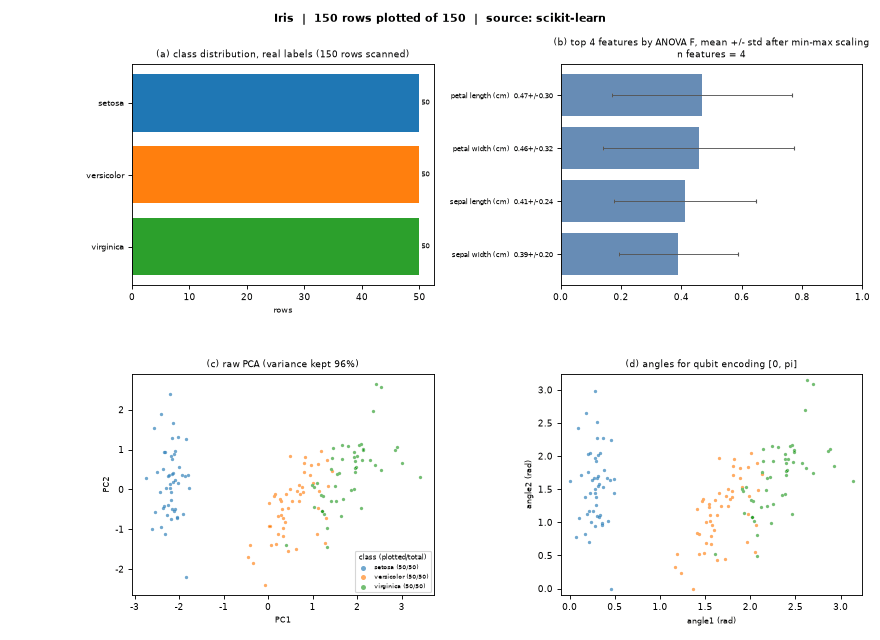

In [107]:
show_dataset("Iris")

#### Breast Cancer Wisconsin (Diagnostic)

**Domain:** Benchmark (tabular) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** 30-feature binary set used for VQC and adversarial demonstrations.

**Reference:** Wolberg, Street, Mangasarian, UCI 1995; scikit-learn load_breast_cancer.

**Source:** scikit-learn (`sklearn.datasets.load_breast_cancer`). **Topic folders:** `23_Adversarial_Attacks_Against_QML`, `29_Adversarial_Robustness_Defences_for_QML`.

**Used by (3 reproduced notebooks), `QC-ID: notebook link`:** [QC-063](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_NoiseAdversarial_Wang2026.ipynb); [QC-067](https://github.com/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/NQEDR_AdversarialRobustness_Li2026.ipynb); [QC-305](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_DepolarizationNoiseRobustness_Winderl2023.ipynb)

**Notes:** none

[LOADED] Breast Cancer Wisconsin (Diagnostic)   source: scikit-learn
  rows scanned: 569 of 569 | rows kept in the pool: 569 | columns: 30 -> 30 features after cleaning | rows plotted: 569
  label column: 'target' | classes: 2
  feature names (30): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
  label value counts (real labels, before sampling): benign=357, malignant=212
  first 3 rows (identifier columns removed):
   mean radius  mean texture  mean perimeter  mean 

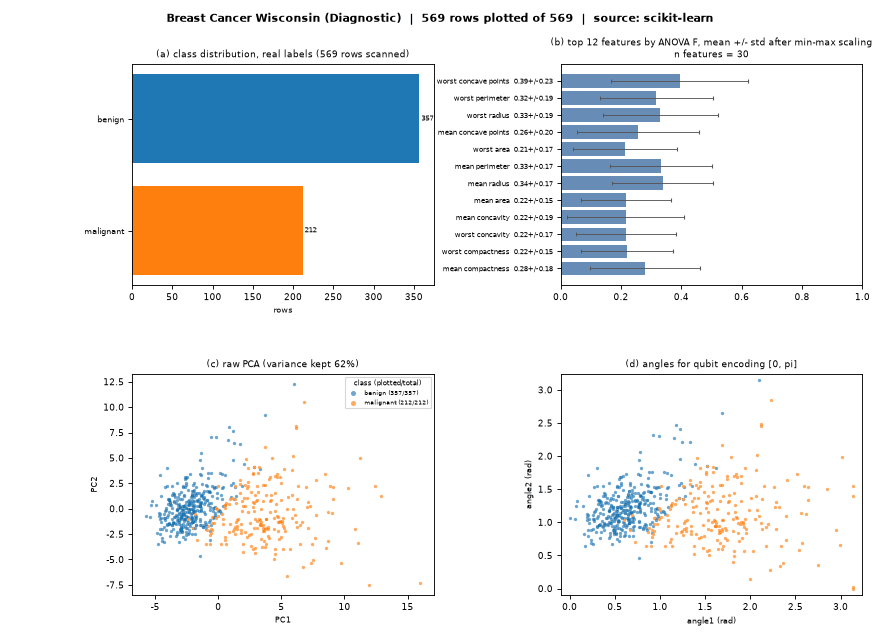

In [108]:
show_dataset("Breast Cancer Wisconsin (Diagnostic)")

#### Digits (8x8)

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** 1797 8x8 digit images (10 classes).

**Reference:** Alpaydin, Kaynak, UCI 1998; scikit-learn load_digits.

**Source:** scikit-learn (`sklearn.datasets.load_digits`). **Topic folders:** `23_Adversarial_Attacks_Against_QML`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-164](https://github.com/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QGAN_HardwareWatermark_Ghosh2025.ipynb)

**Notes:** none

[LOADED] Digits (8x8)   source: scikit-learn
  rows scanned: 1,797 of 1,797 | rows kept in the pool: 1,797 | columns: 64 -> 61 features after cleaning | rows plotted: 1,797
  label column: 'target' | classes: 10
  feature names (61): ['pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2'] ...
  label value counts (real labels, before sampling): 3=183, 1=182, 5=182, 4=181, 6=181, 9=180, 7=179, 0=178, 2=177, 8=174
  first 3 rows (identifier columns removed):
   pixel_0_1  pixel_0_2  pixel_0_3  pixel_0_4  ...  pixel_7_5  pixel_7_6  

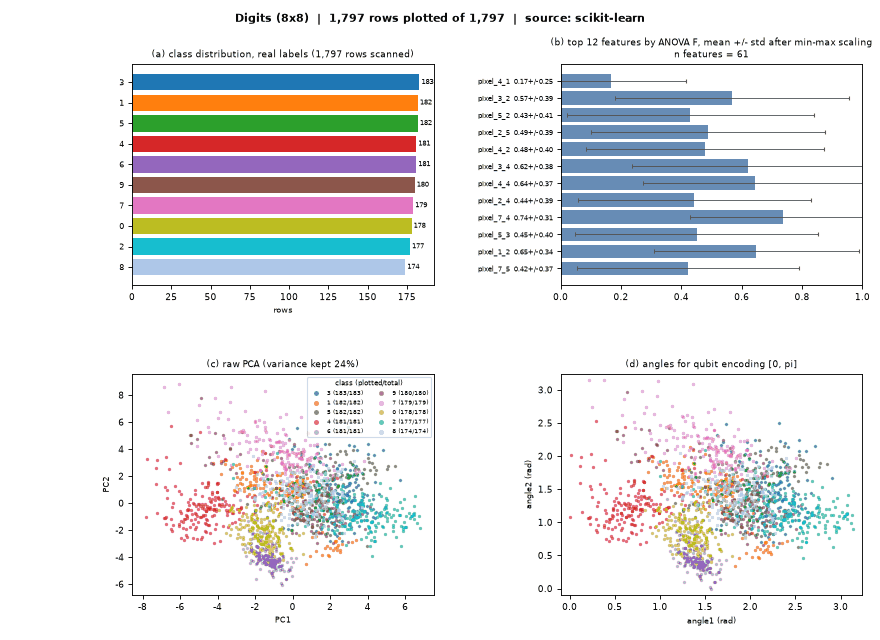

In [109]:
show_dataset("Digits (8x8)")

#### Covertype

**Domain:** Benchmark (tabular) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** CC BY 4.0

**Task and use cases:** 54-feature forest cover type (7 classes), large tabular benchmark.

**Reference:** Blackard, Dean, 1998; scikit-learn fetch_covtype.

**Source:** scikit-learn (`sklearn.datasets.fetch_covtype`). **Topic folders:** `23_Adversarial_Attacks_Against_QML`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-051](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2026.ipynb)

**Notes:** 11 MB download via scikit-learn.

[LOADED] Covertype   source: scikit-learn
  rows scanned: 581,012 of 581,012 | rows kept in the pool: 20,747 | columns: 54 -> 49 features after cleaning | rows plotted: 2,000
  label column: 'target' | classes: 7
  feature names (49): ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_0', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Soil_Type_0', 'Soil_Type_1', 'Soil_Type_2', 'Soil_Type_3', 'Soil_Type_4', 'Soil_Type_5', 'Soil_Type_9', 'Soil_Type_10', 'Soil_Type_11', 'Soil_Type_12', 'Soil_Type_13', 'Soil_Type_15', 'Soil_Type_16', 'Soil_Type_17', 'Soil_Type_18', 'Soil_Type_19', 'Soil_Type_20', 'Soil_Type_21', 'Soil_Type_22', 'Soil_Type_23', 'Soil_Type_24', 'Soil_Type_25', 'Soil_Type_27', 'Soil_Type_28', 'Soil_Type_29', 'Soil_Type_30'] ...
  label value counts (real labels, befor

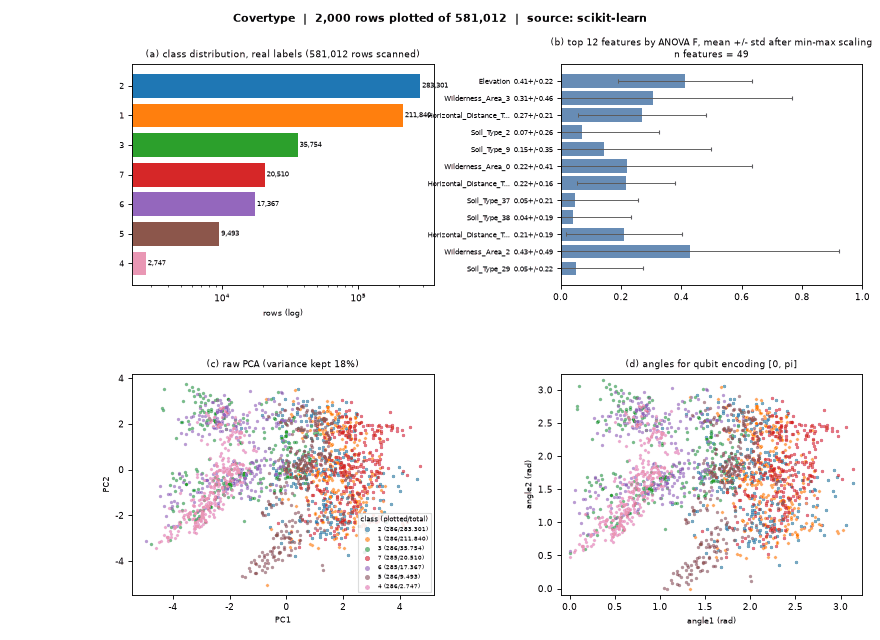

In [110]:
show_dataset("Covertype")

#### Pima Indians Diabetes

**Domain:** Benchmark (tabular) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** public domain

**Task and use cases:** 8-feature binary medical set used in adversarial QML demonstrations.

**Reference:** Smith et al. 1988; jbrownlee/Datasets mirror.

**Source:** [https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv). **Topic folders:** `23_Adversarial_Attacks_Against_QML`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-063](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_NoiseAdversarial_Wang2026.ipynb); [QC-305](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_DepolarizationNoiseRobustness_Winderl2023.ipynb)

**Notes:** none

[LOADED] Pima Indians Diabetes   source: url:raw.githubusercontent.com
  rows scanned: 768 of 768 | rows kept in the pool: 768 | columns: 8 -> 8 features after cleaning | rows plotted: 768
  label column: 'outcome' | classes: 2
  feature names (8): ['pregnancies', 'glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi', 'diabetes_pedigree', 'age']
  label value counts (real labels, before sampling): 0=500, 1=268
  first 3 rows (identifier columns removed):
   pregnancies  glucose  blood_pressure  skin_thickness  insulin  bmi  diabetes_pedigree  age label
0           17      163             72              41       114 40.9          0.817       47     1
1            6      102             82               0         0 30.8           0.18       36     1
2            3      139             54               0         0 25.6          0.402       22     1


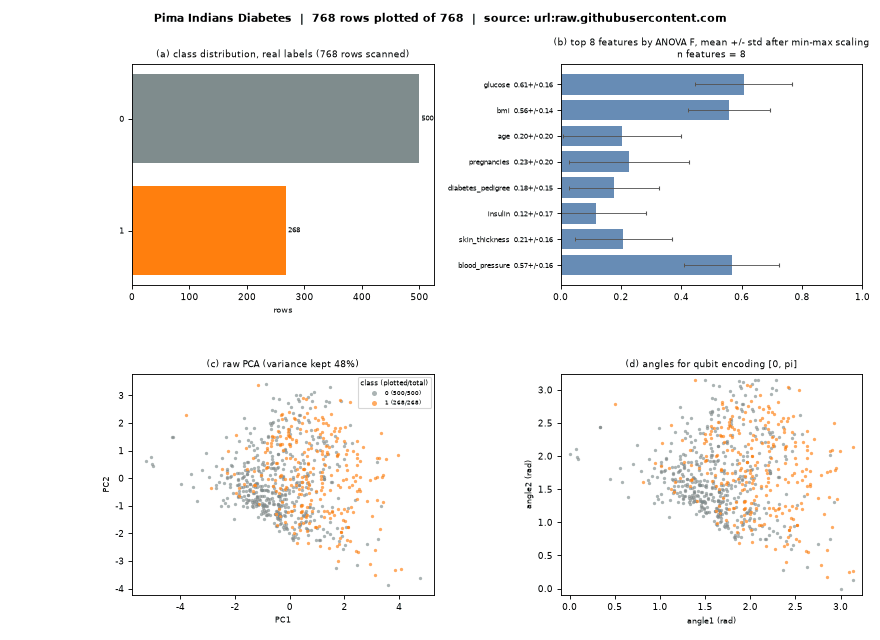

In [111]:
show_dataset("Pima Indians Diabetes")

#### PennyLane PlusMinus

**Domain:** Benchmark (images) &nbsp;|&nbsp; **Access:** `public` (automatic download) &nbsp;|&nbsp; **Licence:** Apache 2.0

**Task and use cases:** 16x16 images of + and - signs (4 classes incl. rotations) shipped with PennyLane datasets.

**Reference:** PennyLane datasets, 'plus-minus'.

**Source:** PennyLane datasets (`qml.data.load`). **Topic folders:** `24_Poisoning_Attacks_Against_QML`, `26_QML_Model_Extraction_Theft`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-045](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustness_Maussner2026.ipynb); [QC-050](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_KillChainAttack_Brugmann2026.ipynb)

**Notes:** Loaded with pennylane.data.load('other', name='plus-minus').

[LOADED] PennyLane PlusMinus   source: PennyLane datasets
  rows scanned: 1,200 of 1,200 | rows kept in the pool: 1,200 | columns: 256 -> 256 features after cleaning | rows plotted: 1,200
  label column: 'label' | classes: 4
  feature names (256): ['px0', 'px1', 'px2', 'px3', 'px4', 'px5', 'px6', 'px7', 'px8', 'px9', 'px10', 'px11', 'px12', 'px13', 'px14', 'px15', 'px16', 'px17', 'px18', 'px19', 'px20', 'px21', 'px22', 'px23', 'px24', 'px25', 'px26', 'px27', 'px28', 'px29', 'px30', 'px31', 'px32', 'px33', 'px34', 'px35', 'px36', 'px37', 'px38', 'px39'] ...
  label value counts (real labels, before sampling): 0=300, 3=300, 2=300, 1=300
  first 3 rows (identifier columns removed):
   px0  px1  px2  px3  ...  px253  px254  px255  label
0    0    0    0    0  ...      0      0      0      0
1    0    0    0    0  ...      0      0      0      0
2    0    0    0    0  ...      0      0      0      0


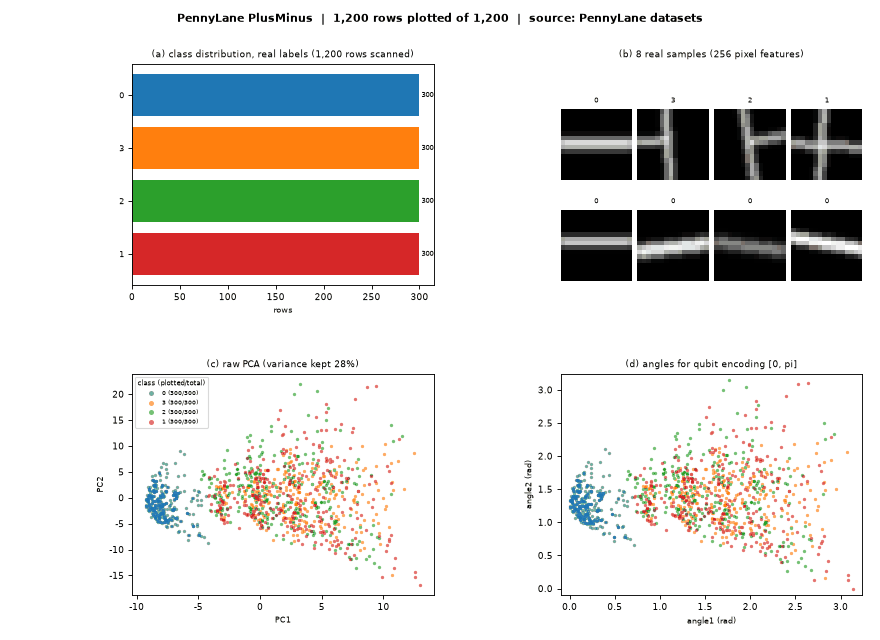

In [112]:
show_dataset("PennyLane PlusMinus")

### 14. Simulated inputs

Data that the papers generate themselves; there is no file to download.

#### QKD channel simulations

**Domain:** QKD attack detection &nbsp;|&nbsp; **Access:** `simulated` (no data file) &nbsp;|&nbsp; **Licence:** n/a

**Task and use cases:** Intercept-resend, photon-number-splitting and CV-QKD excess-noise signatures generated from the papers' channel equations (QC-039, QC-040, QC-068, QC-093, QC-220).

**Reference:** see each notebook's 'Paper in one page' section.

**Source:** generated at run time by the papers. **Topic folders:** `21_QKD_Attack_Detection`.

**Used by (5 reproduced notebooks), `QC-ID: notebook link`:** [QC-039](https://github.com/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQSVMQNN_IoTAnomalyDetection_Deepa2026.ipynb); [QC-040](https://github.com/owlmt/QML/blob/main/21_QKD_Attack_Detection/HybridQNN_CVQKDAttackDetection_He2026.ipynb); [QC-068](https://github.com/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QNN_KnowledgeDistillationDDoS_Krishnamurthy2026.ipynb); [QC-093](https://github.com/owlmt/QML/blob/main/21_QKD_Attack_Detection/QSVM_CVQKDAttackDetection_Ding2026.ipynb); [QC-220](https://github.com/owlmt/QML/blob/main/21_QKD_Attack_Detection/QLSTM_QKDAttack_AlKuwari2025.ipynb)

**Notes:** Not applicable: no public dataset exists; the notebooks simulate the physics from the papers' equations and say so.

In [113]:
show_dataset("QKD channel simulations")

[NOT_APPLICABLE] QKD channel simulations
NOT_APPLICABLE: no public dataset exists; the notebooks simulate the physics from the papers' equations and say so.


#### Synthetic toy sets (make_moons / make_blobs / make_classification)

**Domain:** Benchmark (synthetic) &nbsp;|&nbsp; **Access:** `simulated` (no data file) &nbsp;|&nbsp; **Licence:** n/a

**Task and use cases:** scikit-learn generators used for didactic adversarial-robustness demonstrations (QC-063, QC-099).

**Reference:** scikit-learn.

**Source:** generated at run time by the papers. **Topic folders:** `23_Adversarial_Attacks_Against_QML`.

**Used by (2 reproduced notebooks), `QC-ID: notebook link`:** [QC-063](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_NoiseAdversarial_Wang2026.ipynb); [QC-099](https://github.com/owlmt/QML/blob/main/28_QML_Hardware_Side_Channel_Crosstalk_Attacks/QSVM_PipelineIntegrity_Yeniaras2026.ipynb)

**Notes:** Not applicable: generated at run time by the notebooks that use them.

In [114]:
show_dataset("Synthetic toy sets (make_moons / make_blobs / make_classification)")

[NOT_APPLICABLE] Synthetic toy sets (make_moons / make_blobs / make_classification)
NOT_APPLICABLE: generated at run time by the notebooks that use them.


#### Gymnasium control states (CartPole, LunarLander)

**Domain:** Reinforcement learning &nbsp;|&nbsp; **Access:** `simulated` (no data file) &nbsp;|&nbsp; **Licence:** MIT

**Task and use cases:** Environment observations collected at run time for quantum policy-gradient attacks (QC-089).

**Reference:** Gymnasium (Farama Foundation).

**Source:** generated at run time by the papers. **Topic folders:** `23_Adversarial_Attacks_Against_QML`.

**Used by (1 reproduced notebooks), `QC-ID: notebook link`:** [QC-089](https://github.com/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSignFlip_GradientHandoffAttack_Ronggon2026.ipynb)

**Notes:** Not applicable: states are generated by the simulator; the QC-089 notebook visualises them itself.

In [115]:
show_dataset("Gymnasium control states (CartPole, LunarLander)")

[NOT_APPLICABLE] Gymnasium control states (CartPole, LunarLander)
NOT_APPLICABLE: states are generated by the simulator; the QC-089 notebook visualises them itself.


## Quantum Circuit Architecture

NOT_APPLICABLE: the atlas visualises datasets only; every gate-based circuit is drawn in the paper's own notebook.

In [116]:
print("NOT_APPLICABLE: the atlas visualises datasets only; every gate-based circuit is drawn in the paper's own notebook.")

NOT_APPLICABLE: the atlas visualises datasets only; every gate-based circuit is drawn in the paper's own notebook.


## Atlas summary

The table lists every dataset with its access status and the outcome of this run (rows read from the source, rows of the whole file when known,
number of features after cleaning, number of classes, number of corpus notebooks that use it). The charts show datasets per status and per topic folder,
and the matrix shows which topic folders use which dataset (colour = status). The last part prints, for every dataset that was not loaded,
what you have to provide, and writes `atlas_inventory.csv`.

102 datasets in the inventory


                                            name     access              status  rows_loaded  rows_total  n_features  n_classes  n_corpus_notebooks
0                                        NSL-KDD     public              LOADED     125973.0    125973.0        49.0       23.0                  15
1                             KDD Cup 1999 (10%)     public              LOADED     155515.0    155515.0        49.0       37.0                   3
2                                    CIC-IDS2017     public              LOADED     225745.0    225745.0        65.0        2.0                   9
3                                CSE-CIC-IDS2018     public              LOADED     331125.0    331125.0        69.0        3.0                   1
4                                      UNSW-NB15     public              LOADED      82332.0     82332.0        50.0       10.0                   5
5                                  CIC-UNSW-NB15     public              LOADED     447915.0    447915.0        

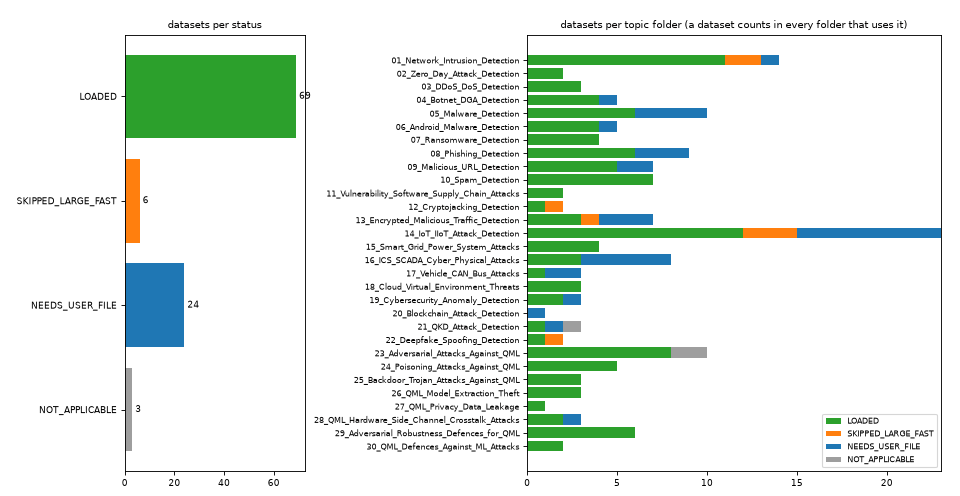

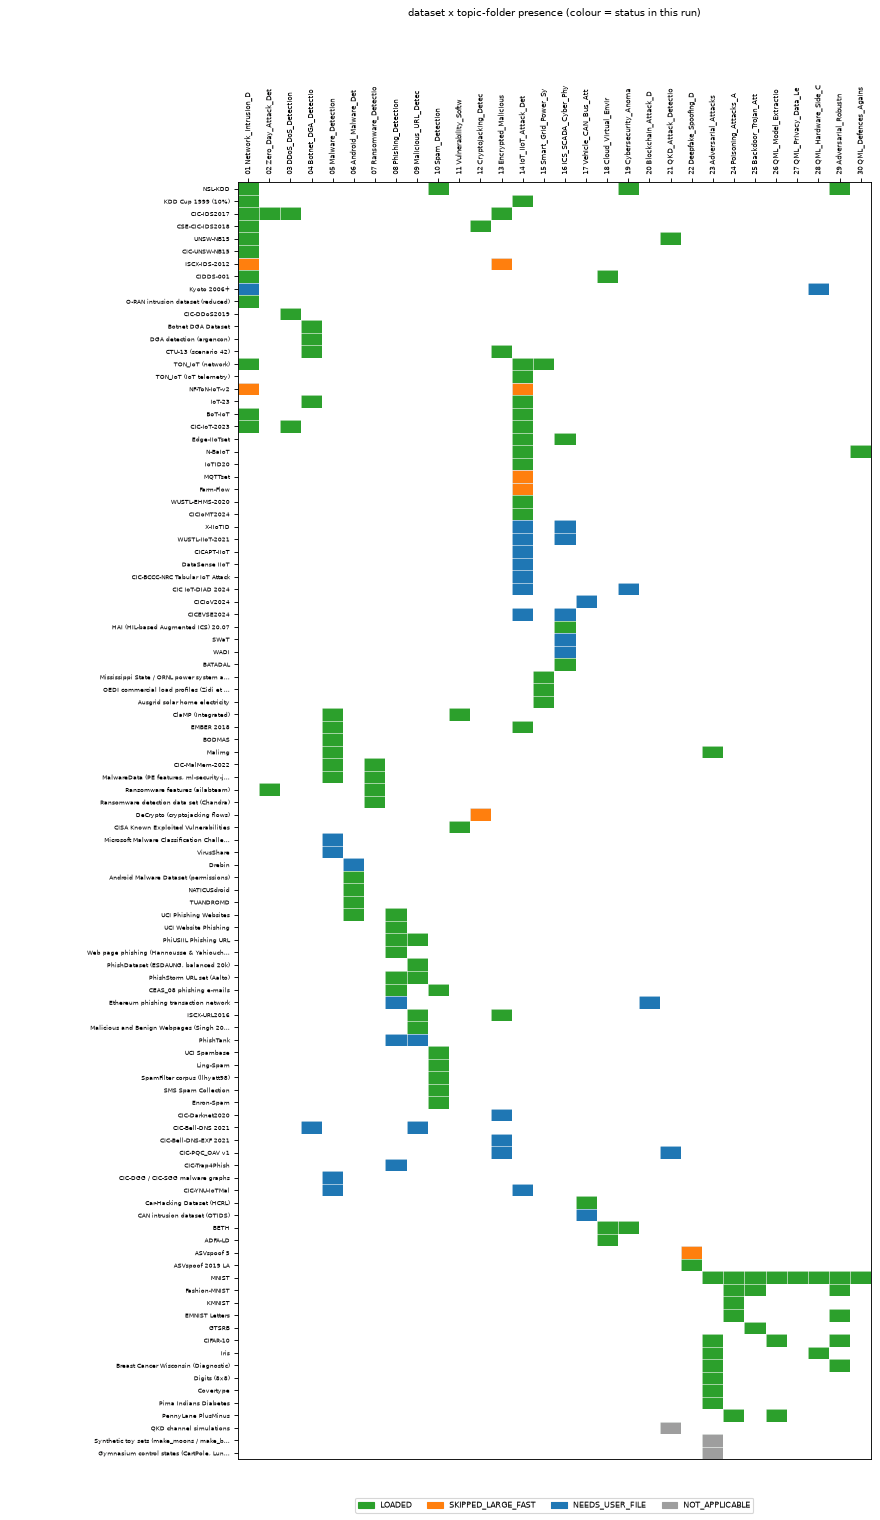


WHAT TO PROVIDE (30 datasets are not loaded in this run)
[SKIPPED_LARGE_FAST] ISCX-IDS-2012
    official: https://huggingface.co/datasets/bencorn/ISCX-IDS-2012
    Source file is 1,061 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.

[NEEDS_USER_FILE] Kyoto 2006+
    official: https://www.takakura.com/Kyoto_data/
    Not downloadable automatically (request form or no stable direct link). Official page: https://www.takakura.com/Kyoto_data/ . Provide the data file(s) in atlas_user_files\kyoto_2006/ (a .csv, .parquet, .zip or .xlsx with the label column [17]) and run this cell again.

[SKIPPED_LARGE_FAST] NF-ToN-IoT-v2
    official: https://huggingface.co/datasets/Nora9029/NF-ToN-IoT-v2
    Source file is 532 MB; FAST_MODE accepts at most 250 MB. Set FAST_MODE = False (limit 3000 MB) to load it.

[SKIPPED_LARGE_FAST] MQTTset
    official: https://www.kaggle.com/api/v1/datasets/download/cnrieiit/mqttset
    Source file is large (size not announced b

In [117]:
# ---- Atlas summary: inventory table, status and topic charts, dataset x topic matrix, what to provide, CSV ----
TOPIC_FOLDERS = ["01_Network_Intrusion_Detection", "02_Zero_Day_Attack_Detection", "03_DDoS_DoS_Detection", "04_Botnet_DGA_Detection",
                 "05_Malware_Detection", "06_Android_Malware_Detection", "07_Ransomware_Detection", "08_Phishing_Detection",
                 "09_Malicious_URL_Detection", "10_Spam_Detection", "11_Vulnerability_Software_Supply_Chain_Attacks", "12_Cryptojacking_Detection",
                 "13_Encrypted_Malicious_Traffic_Detection", "14_IoT_IIoT_Attack_Detection", "15_Smart_Grid_Power_System_Attacks",
                 "16_ICS_SCADA_Cyber_Physical_Attacks", "17_Vehicle_CAN_Bus_Attacks", "18_Cloud_Virtual_Environment_Threats",
                 "19_Cybersecurity_Anomaly_Detection", "20_Blockchain_Attack_Detection", "21_QKD_Attack_Detection", "22_Deepfake_Spoofing_Detection",
                 "23_Adversarial_Attacks_Against_QML", "24_Poisoning_Attacks_Against_QML", "25_Backdoor_Trojan_Attacks_Against_QML",
                 "26_QML_Model_Extraction_Theft", "27_QML_Privacy_Data_Leakage", "28_QML_Hardware_Side_Channel_Crosstalk_Attacks",
                 "29_Adversarial_Robustness_Defences_for_QML", "30_QML_Defences_Against_ML_Attacks"]
STATUS_ORDER = ["LOADED", "SKIPPED_LARGE_FAST", "NEEDS_USER_FILE", "NOT_APPLICABLE", "LOAD_FAILED", "NO_LABEL", "NOT_RUN"]
STATUS_COLOUR = {"LOADED": "#2ca02c", "SKIPPED_LARGE_FAST": "#ff7f0e", "NEEDS_USER_FILE": "#1f77b4", "NOT_APPLICABLE": "#9e9e9e",
                 "LOAD_FAILED": "#d62728", "NO_LABEL": "#9467bd", "NOT_RUN": "#cccccc"}


def official_url(e):
    if e["source"] == "hf":
        return f"https://huggingface.co/datasets/{e['repo_id']}"
    if e["source"] in ("sklearn", "pennylane", "simulated"):
        return ""
    return (e.get("files") or [""])[0]


by_name = {r.name: r for r in RESULTS}
rows = []
for e in REGISTRY:
    r = by_name.get(e["name"]) or DatasetResult(name=e["name"], domain=e["domain"], access=e["access"], status="NOT_RUN", message="cell not executed")
    rows.append(dict(name=e["name"], domain=e["domain"], access=e["access"], status=r.status, rows_loaded=r.rows_loaded or None,
                     rows_total=r.rows_total, rows_plotted=r.rows_plotted or None, n_features=r.n_features or None, n_classes=r.n_classes or None,
                     label_column=r.label_column, n_corpus_notebooks=len(e.get("used_by", [])), topic_folders=";".join(e["topics"]),
                     corpus_qc_ids=";".join(u["qc_id"] for u in e.get("used_by", [])), source_used=r.source_used, license=e["license"],
                     official_url=official_url(e), message=r.message))
inv = pd.DataFrame(rows)
print(f"{len(inv)} datasets in the inventory\n")
print(inv[["name", "access", "status", "rows_loaded", "rows_total", "n_features", "n_classes", "n_corpus_notebooks"]].to_string(max_colwidth=44))

# charts: datasets per status, datasets per topic folder (stacked by status)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), gridspec_kw=dict(width_ratios=[1, 2.3], wspace=0.75))
st = inv["status"].value_counts().reindex(STATUS_ORDER).dropna()
axes[0].barh(st.index, st.values, color=[STATUS_COLOUR[s] for s in st.index])
axes[0].invert_yaxis()
for i, v in enumerate(st.values):
    axes[0].text(v, i, f" {int(v)}", va="center", fontsize=8)
axes[0].set_title("datasets per status", fontsize=9)
per_topic = {t: {s: 0 for s in STATUS_ORDER} for t in TOPIC_FOLDERS}
for _, r in inv.iterrows():
    for t in r["topic_folders"].split(";"):
        if t in per_topic:
            per_topic[t][r["status"]] += 1
left = np.zeros(len(TOPIC_FOLDERS))
for s in STATUS_ORDER:
    vals = np.array([per_topic[t][s] for t in TOPIC_FOLDERS], dtype=float)
    if vals.sum():
        axes[1].barh(range(len(TOPIC_FOLDERS)), vals, left=left, color=STATUS_COLOUR[s], label=s)
        left += vals
axes[1].set_yticks(range(len(TOPIC_FOLDERS)))
axes[1].set_yticklabels(TOPIC_FOLDERS, fontsize=7)
axes[1].invert_yaxis()
axes[1].set_title("datasets per topic folder (a dataset counts in every folder that uses it)", fontsize=9)
axes[1].legend(fontsize=7, loc="lower right")
fig.subplots_adjust(left=0.13, right=0.98, top=0.93, bottom=0.05)
save_png(fig, OUTPUT_DIR / "atlas_status_and_topics.png")
display(IPImage(filename=str(OUTPUT_DIR / "atlas_status_and_topics.png")))
plt.close(fig)

# presence matrix: dataset x topic folder (colour = status of the dataset in this run)
M = np.full((len(inv), len(TOPIC_FOLDERS)), np.nan)
codes = {s: i for i, s in enumerate(STATUS_ORDER)}
for i, r in inv.iterrows():
    for t in r["topic_folders"].split(";"):
        if t in TOPIC_FOLDERS:
            M[i, TOPIC_FOLDERS.index(t)] = codes[r["status"]]
from matplotlib.colors import ListedColormap
cm = ListedColormap([STATUS_COLOUR[s] for s in STATUS_ORDER])
fig, ax = plt.subplots(figsize=(11, 19))
ax.imshow(np.ma.masked_invalid(M), cmap=cm, vmin=-0.5, vmax=len(STATUS_ORDER) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(TOPIC_FOLDERS)))
ax.set_xticklabels([t[:2] + " " + t[3:22] for t in TOPIC_FOLDERS], rotation=90, fontsize=6)
ax.set_yticks(range(len(inv)))
ax.set_yticklabels([short(n, 40) for n in inv["name"]], fontsize=5.5)
ax.set_xticks(np.arange(-0.5, len(TOPIC_FOLDERS), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(inv), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)
ax.tick_params(which="minor", length=0)
ax.xaxis.tick_top()
handles = [plt.Rectangle((0, 0), 1, 1, color=STATUS_COLOUR[s]) for s in STATUS_ORDER if s in set(inv["status"])]
ax.legend(handles, [s for s in STATUS_ORDER if s in set(inv["status"])], fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.045), ncol=4)
ax.set_title("dataset x topic-folder presence (colour = status in this run)", fontsize=9, pad=62)
fig.subplots_adjust(left=0.27, right=0.99, top=0.88, bottom=0.04)
save_png(fig, OUTPUT_DIR / "atlas_dataset_topic_matrix.png")
display(IPImage(filename=str(OUTPUT_DIR / "atlas_dataset_topic_matrix.png")))
plt.close(fig)

# what to provide
todo = inv[inv["status"].isin(["NEEDS_USER_FILE", "SKIPPED_LARGE_FAST", "LOAD_FAILED", "NO_LABEL"])]
print(f"\nWHAT TO PROVIDE ({len(todo)} datasets are not loaded in this run)\n" + "=" * 70)
for _, r in todo.iterrows():
    print(f"[{r['status']}] {r['name']}\n    official: {r['official_url']}\n    {r['message']}\n")

# inventory CSV: always into OUTPUT_DIR, and into the repository folder when the notebook runs from a clone
inv.to_csv(OUTPUT_DIR / "atlas_inventory.csv", index=False)
print("written:", (OUTPUT_DIR / "atlas_inventory.csv").resolve())
if REPO_FOLDER.is_dir():
    inv.to_csv(REPO_FOLDER / "atlas_inventory.csv", index=False)
    print("written:", (REPO_FOLDER / "atlas_inventory.csv").resolve())
else:
    print("(not inside a clone of the repository: download atlas_inventory.csv from the Files pane)")

## Reading the atlas critically

* **Sampling.** Every figure shows at most `SAMPLE_ROWS` rows, drawn class-balanced. A balanced sample hides the real class imbalance, which is why panel (a) shows the counts of the whole source before sampling and the legend gives `plotted/total` per class.
  Several large files were only scanned in part (first `STREAM_ROWS` rows of a stream, first row group of a big parquet file, or one file of a many-file collection); the figure title and the printed `rows scanned` line say which. A file ordered by time or by class can therefore be unrepresentative.
* **Class imbalance.** Real intrusion data are dominated by benign or by one attack family. Accuracy on such data is misleading; per-class recall and F1 are what the reproduced papers should be judged on.
* **PCA on a stratified half.** Scaling and PCA are fitted on a stratified half of the sample and applied to all points, which mirrors the training-only fitting rule of the reproduced notebooks. Two principal components usually keep only 20 to 40 percent of the variance, so overlapping classes in the figure do not prove that the classes are inseparable, and well-separated classes do not prove that a model will generalise.
* **Angles are not a quantum result.** Panel (d) only rescales the PCA coordinates to [0, pi], the range a rotation-gate feature map would use. It says nothing about quantum advantage.
* **Mirrors versus originals.** Several datasets are loaded from mirrors (Hugging Face, GitHub, UCI static files) that may be preprocessed: columns dropped or renamed, duplicates removed, labels merged, or only one day or one split kept. The card says which mirror is used; conclusions about the original collection should be checked against the original release.
* **Label and feature quality.** Known issues exist in the originals (for example label noise and duplicate flows in CIC-IDS-2017, redundant records in KDD-99, concept drift in Android and PE malware collections). The atlas removes identifier columns and columns that encode the label, but it does not repair labels.
* **Licences.** Most collections are released for research use only; some require registration or an agreement. The notebook downloads data to temporary storage, deletes large files, and stores no dataset in the repository. Follow each dataset's own terms and cite its reference.
* **Gated and page-only data.** For those datasets this notebook shows no data at all. Supply the file yourself (see "what to provide") and the same cell will load and plot it.

### Exercises

1. **Imbalance versus separability.** Pick three datasets from different groups. For each, compare panel (a) with panel (c): which classes overlap in the 2-D projection, and which classes are so rare that they are almost invisible? Rerun the dataset with `SAMPLE_ROWS = 500` and with `SAMPLE_ROWS = 5000` and describe what changes.
2. **Mirror check.** Choose a dataset whose card names a mirror (for example CIC-IDS-2017 or CIC-DDoS2019). Download the original from the official page, load it with `USER_FILES_DIR`, and compare the class counts, feature names and PCA picture with the mirror. What was lost or changed?
3. **Extend the atlas.** Add a new entry to the registry for a dataset that is not yet listed (give its source, format, label hints, licence and access status), run `show_dataset` on it, and decide what to write in its `notes`. Which topic folders of the repository would use it, and which paper in `manifest.csv` could be reproduced with it?

## How to cite and licence note

**How to cite.** Plain text: Madjid G. Tehrani (2026). *QML x Cybersecurity: reproducible notebooks of quantum machine learning papers and a cybersecurity dataset atlas.* Edinburgh Napier University. https://github.com/owlmt/QML

```bibtex
@misc{tehrani2026qmlcyber,
  author       = {Tehrani, Madjid G.},
  title        = {QML x Cybersecurity: reproducible notebooks of quantum machine learning papers and a cybersecurity dataset atlas},
  year         = {2026},
  publisher    = {GitHub},
  howpublished = {\url{https://github.com/owlmt/QML}},
  note         = {Edinburgh Napier University. Cite the dataset atlas as folder 00\_Cybersecurity\_Dataset\_Atlas and an implemented paper as its notebook path.}
}
```

When you use a dataset shown here, cite the dataset's own reference as well (given on its card).

**Licence note.** The notebook code and text are part of the repository [owlmt/QML](https://github.com/owlmt/QML); see the repository for its licence.
The datasets are not part of this repository and keep their own licences (listed on every card); the atlas only reads them, draws small samples and
records inventory metadata.